# Preparation of the accelerometry dataset from the collected data.

### **Code for correcting the date and time of the original data - adding milliseconds.**

In [ ]:
import pandas as pd
from datetime import datetime
import os

# 1. Caminho do seu arquivo (usando 'r' antes para o Windows aceitar o caminho)
caminho_arquivo = r'C:\Users\franc\OneDrive\Desktop\preto270126.xlsx'
nome_saida = r'C:\Users\franc\OneDrive\Desktop\preto270126_CORRIGIDO.csv'

# 2. Carregar o arquivo
# Ajustei o separador para vírgula (,) que é o padrão do seu CSV de acelerômetro
df = pd.read_csv(caminho_arquivo, sep=',')

horarios_corrigidos = []
unix_ms = []

ultimo_segundo = -1
ms_atual = 0

# 3. Processamento linha por linha
for index, row in df.iterrows():
    # Pega o valor da primeira coluna (Data e Hora)
    data_texto = str(row.iloc[0]).strip()
    
    try:
        # Tenta converter o texto para objeto de tempo
        dt_objeto = datetime.strptime(data_texto, '%d/%m/%Y %H:%M:%S')
        segundo_atual = dt_objeto.second
        
        # LÓGICA DE RESET: Se o segundo mudou, volta para 0ms
        if segundo_atual != ultimo_segundo:
            ms_atual = 0
            ultimo_segundo = segundo_atual
        else:
            # Se continua no mesmo segundo, soma 50ms
            ms_atual += 50
            
        # Garante que o ms_atual não passe de 999 (caso haja erro de log)
        ms_final = min(ms_atual, 950)
            
        # Criar o novo timestamp com os milissegundos calculados
        dt_com_ms = dt_objeto.replace(microsecond=ms_final * 1000)
        
        # Coluna H: Formato legível (ex: 07:23:36,050)
        horarios_corrigidos.append(dt_com_ms.strftime('%d/%m/%Y %H:%M:%S,%f')[:-3])
        
        # Coluna I: Unix Epoch (13 dígitos)
        # Usamos 1970 como referência UTC
        timestamp_unix = int(dt_com_ms.timestamp() * 1000)
        unix_ms.append(timestamp_unix)
        
    except Exception as e:
        horarios_corrigidos.append("Erro Formato")
        unix_ms.append(0)

# 4. Adicionar as novas colunas
df['Horario_Corrigido_H'] = horarios_corrigidos
df['Unix_MS_I'] = unix_ms

# 5. Salvar o novo arquivo no Desktop
df.to_csv(nome_saida, index=False, sep=';')

print(f"Sucesso! Arquivo salvo em: {nome_saida}")
# Mostra as primeiras 15 linhas para conferência
print(df[['Horario_Corrigido_H', 'Unix_MS_I']].head(15))

In [4]:
!pip install openpyxl

Defaulting to user installation because normal site-packages is not writeable


# Converts the accelerometer's native format to m/s² and reorders the columns.

In [13]:
import pandas as pd
from datetime import datetime

# 1. Configurações de Caminho
caminho_input = r'C:\Users\franc\OneDrive\Desktop\preto270126.xlsx'
caminho_csv = r'C:\Users\franc\OneDrive\Desktop\preto270126_FINAL.csv'
caminho_xlsx = r'C:\Users\franc\OneDrive\Desktop\preto270126_FINAL.xlsx'

# 2. Carregar dados
df_raw = pd.read_excel(caminho_input)

# Listas para as novas colunas
data_hora_ms = []
unix_ms_lista = []
ax_ms2 = []
ay_ms2 = []
az_ms2 = []

# Variáveis de controle de tempo
ultimo_segundo = -1
ms_atual = 0
epoch_ref = datetime(1970, 1, 1)

# Constante de conversão (MPU6050 escala +/- 2g)
FATOR_CONVERSAO = 9.80665 / 16384.0

# 3. Processamento
for index, row in df_raw.iterrows():
    # --- PROCESSAMENTO DE TEMPO ---
    dt_valor = row.iloc[0]
    try:
        if isinstance(dt_valor, datetime):
            dt_objeto = dt_valor
        else:
            dt_objeto = datetime.strptime(str(dt_valor)[:19], '%d/%m/%Y %H:%M:%S')
        
        segundo_atual = dt_objeto.second
        
        if segundo_atual != ultimo_segundo:
            ms_atual = 0
            ultimo_segundo = segundo_atual
        else:
            ms_atual += 50
            
        ms_final = min(ms_atual, 950)
        
        # Coluna 1: Formato Legível com ms
        dt_com_ms = dt_objeto.replace(microsecond=ms_final * 1000)
        data_hora_ms.append(dt_com_ms.strftime('%d/%m/%Y %H:%M:%S,%f')[:-3])
        
        # Coluna 2: Unix MS
        segundos_unix = int((dt_objeto - epoch_ref).total_seconds())
        unix_final = (segundos_unix * 1000) + ms_final
        unix_ms_lista.append(unix_final)
    except:
        data_hora_ms.append("Erro")
        unix_ms_lista.append(0)

    # --- CONVERSÃO DE ACELERAÇÃO (m/s²) ---
    ax_ms2.append(row.iloc[3] * FATOR_CONVERSAO)
    ay_ms2.append(row.iloc[4] * FATOR_CONVERSAO)
    az_ms2.append(row.iloc[5] * FATOR_CONVERSAO)

# 4. Criar o novo DataFrame na ordem solicitada
df_final = pd.DataFrame({
    'DataHora_ms': data_hora_ms,
    'instante_tempo': unix_ms_lista,
    'AX': ax_ms2,
    'AY': ay_ms2,
    'AZ': az_ms2,
    'ID': 1
})

# 5. Salvar em ambos os formatos
df_final.to_csv(caminho_csv, index=False, sep=';', encoding='utf-8-sig')
df_final.to_excel(caminho_xlsx, index=False)

print("### **Sucesso!**")
print(f"1. CSV gerado: {caminho_csv}")
print(f"2. XLSX gerado: {caminho_xlsx}")
print("\nPrévia dos dados:")
print(df_final.head())

### **Sucesso!**
1. CSV gerado: C:\Users\franc\OneDrive\Desktop\preto270126_FINAL.csv
2. XLSX gerado: C:\Users\franc\OneDrive\Desktop\preto270126_FINAL.xlsx

Prévia dos dados:
               DataHora_ms  instante_tempo        AX        AY        AZ  ID
0  26/01/2026 07:23:36,000   1769412216000 -5.798756 -6.528988  7.908048   1
1  26/01/2026 07:23:36,050   1769412216050 -5.894524 -7.259219  7.879318   1
2  26/01/2026 07:23:36,100   1769412216100 -5.377377 -7.898471  7.508216   1
3  26/01/2026 07:23:36,150   1769412216150 -4.048595 -7.807492  7.137115   1
4  26/01/2026 07:23:36,200   1769412216200 -3.632004  -7.33344   6.59842   1


# Generates the data set from the notes spreadsheet (v1)

In [29]:
import pandas as pd

# 1. Caminhos dos arquivos
caminho_dados = r'C:\Users\franc\OneDrive\Desktop\preto270126_FINAL.xlsx'
caminho_gabarito = r'C:\Users\franc\OneDrive\Desktop\anotpreto2701.xlsx'
caminho_saida = r'C:\Users\franc\OneDrive\Desktop\dataset_treinamento_suinos.xlsx'

# 2. Carregar as planilhas (Feche-as no Excel antes)
df_dados = pd.read_excel(caminho_dados)
df_gabarito = pd.read_excel(caminho_gabarito)

# 3. Filtragem de Intervalo Inclusivo
lista_trechos = []

# Limpa linhas sem os valores Unix calculados
df_gabarito_limpo = df_gabarito.dropna(subset=['unicio unix', 'fim unix'])

for _, row in df_gabarito_limpo.iterrows():
    u_ini = row['unicio unix']
    u_fim = row['fim unix']
    rotulo = row['atividade']
    
    # O uso de >= e <= garante a inclusão dos elementos iniciais e finais
    mask = (df_dados['instante_tempo'] >= u_ini) & (df_dados['instante_tempo'] <= u_fim)
    trecho = df_dados.loc[mask].copy()
    
    if not trecho.empty:
        trecho['atividade'] = rotulo
        lista_trechos.append(trecho)

# 4. Consolidação e Organização
if lista_trechos:
    df_final = pd.concat(lista_trechos, ignore_index=True)
    
    # Ordem das colunas conforme sua necessidade
    colunas = ['DataHora_ms', 'instante_tempo', 'AX', 'AY', 'AZ', 'ID', 'atividade']
    df_final = df_final[colunas]
    
    df_final.to_excel(caminho_saida, index=False)
    print(f"### Sucesso! Dataset gerado com {len(df_final)} linhas.")
    print(f"Os limites {u_ini} e {u_fim} foram considerados na busca.")
else:
    print("### Erro: Nenhum dado encontrado no intervalo inclusivo.")

### Sucesso! Dataset gerado com 93724 linhas.
Os limites 1769519430000.0 e 1769519455950.0002 foram considerados na busca.


# Code to correct the date and time of the original data - adding months and adding missing periods.

In [8]:
import pandas as pd
from datetime import datetime
import numpy as np # Importante para checar valores vazios

# 1. Configurações de Caminho
caminho_input = r'C:\Users\franc\OneDrive\Desktop\preto270126.xlsx'
caminho_xlsx = r'C:\Users\franc\OneDrive\Desktop\preto270126_FINAL.xlsx'

# 2. Carregar dados
df_raw = pd.read_excel(caminho_input)

# Listas para as colunas
data_hora_ms = []
unix_ms_lista = []
ax_ms2 = []
ay_ms2 = []
az_ms2 = []

# Variáveis de controle
ultimo_segundo = -1
ms_atual = 0
epoch_ref = datetime(1970, 1, 1)
dt_objeto_anterior = None 

FATOR_CONVERSAO = 9.80665 / 16384.0

# 3. Processamento
for index, row in df_raw.iterrows():
    dt_valor = row.iloc[0]
    
    # --- PROTEÇÃO CONTRA LINHAS VAZIAS ---
    # Verifica se o valor é nulo, NaN ou NaT
    if pd.isna(dt_valor):
        continue 
        
    dt_objeto = dt_valor if isinstance(dt_valor, datetime) else datetime.strptime(str(dt_valor)[:19], '%d/%m/%Y %H:%M:%S')
    segundo_atual = dt_objeto.second

    # Lógica de Preenchimento (Gap Filling)
    if ultimo_segundo != -1 and segundo_atual != ultimo_segundo and dt_objeto_anterior is not None:
        while ms_atual < 950:
            ms_atual += 50
            dt_com_ms = dt_objeto_anterior.replace(microsecond=ms_atual * 1000)
            
            data_hora_ms.append(dt_com_ms.strftime('%d/%m/%Y %H:%M:%S,%f')[:-3])
            segundos_unix = int((dt_objeto_anterior - epoch_ref).total_seconds())
            unix_ms_lista.append((segundos_unix * 1000) + ms_atual)
            
            ax_ms2.append(ax_ms2[-1])
            ay_ms2.append(ay_ms2[-1])
            az_ms2.append(az_ms2[-1])

    # Reset do ms no início de cada segundo
    if segundo_atual != ultimo_segundo:
        ms_atual = 0
        ultimo_segundo = segundo_atual
    else:
        ms_atual += 50
        
    ms_final = min(ms_atual, 950)
    dt_com_ms = dt_objeto.replace(microsecond=ms_final * 1000)
    dt_objeto_anterior = dt_objeto
    
    data_hora_ms.append(dt_com_ms.strftime('%d/%m/%Y %H:%M:%S,%f')[:-3])
    segundos_unix = int((dt_objeto - epoch_ref).total_seconds())
    unix_ms_lista.append((segundos_unix * 1000) + ms_final)
    
    ax_ms2.append(row.iloc[3] * FATOR_CONVERSAO)
    ay_ms2.append(row.iloc[4] * FATOR_CONVERSAO)
    az_ms2.append(row.iloc[5] * FATOR_CONVERSAO)

# 4. Criar o DataFrame e Salvar
df_final = pd.DataFrame({
    'DataHora_ms': data_hora_ms,
    'instante_tempo': unix_ms_lista,
    'AX': ax_ms2,
    'AY': ay_ms2,
    'AZ': az_ms2,
    'ID': 1
})

df_final.to_excel(caminho_xlsx, index=False)
print(f"Sucesso! Arquivo salvo em: {caminho_xlsx}")

Sucesso! Arquivo salvo em: C:\Users\franc\OneDrive\Desktop\preto270126_FINAL.xlsx


# Duplicate correction (v3)

In [34]:
import pandas as pd
from datetime import datetime
import numpy as np # Importante para checar valores vazios

# 1. Configurações de Caminho
caminho_input = r'C:\Users\franc\OneDrive\Desktop\preto270126.xlsx'
caminho_xlsx = r'C:\Users\franc\OneDrive\Desktop\preto270126_FINAL.xlsx'

# 2. Carregar dados
df_raw = pd.read_excel(caminho_input)

# Listas para as colunas
data_hora_ms = []
unix_ms_lista = []
ax_ms2 = []
ay_ms2 = []
az_ms2 = []

# Variáveis de controle
ultimo_segundo = -1
ms_atual = 0
epoch_ref = datetime(1970, 1, 1)
dt_objeto_anterior = None 

FATOR_CONVERSAO = 9.80665 / 16384.0

# Variáveis de controle adicionais
amostras_no_segundo = 0
ultimo_segundo_processado = -1

for index, row in df_raw.iterrows():
    dt_valor = row.iloc[0]
    if pd.isna(dt_valor): continue
        
    dt_objeto = dt_valor if isinstance(dt_valor, datetime) else datetime.strptime(str(dt_valor)[:19], '%d/%m/%Y %H:%M:%S')
    segundo_atual = dt_objeto.second
    
    # --- NOVO BLOQUEIO DE AMOSTRAS ---
    if segundo_atual == ultimo_segundo_processado:
        amostras_no_segundo += 1
        if amostras_no_segundo > 20:
            continue # Descartar 21ª, 22ª, etc.
    else:
        # Reset ao mudar de segundo
        amostras_no_segundo = 1
        ultimo_segundo_processado = segundo_atual

    # Lógica de Preenchimento (Gap Filling)
    if ultimo_segundo != -1 and segundo_atual != ultimo_segundo and dt_objeto_anterior is not None:
        while ms_atual < 950:
            ms_atual += 50
            dt_com_ms = dt_objeto_anterior.replace(microsecond=ms_atual * 1000)
            
            data_hora_ms.append(dt_com_ms.strftime('%d/%m/%Y %H:%M:%S,%f')[:-3])
            segundos_unix = int((dt_objeto_anterior - epoch_ref).total_seconds())
            unix_ms_lista.append((segundos_unix * 1000) + ms_atual)
            
            ax_ms2.append(ax_ms2[-1])
            ay_ms2.append(ay_ms2[-1])
            az_ms2.append(az_ms2[-1])

    # Reset do ms no início de cada segundo
    if segundo_atual != ultimo_segundo:
        ms_atual = 0
        ultimo_segundo = segundo_atual
    else:
        ms_atual += 50
        
    ms_final = min(ms_atual, 950)
    dt_com_ms = dt_objeto.replace(microsecond=ms_final * 1000)
    dt_objeto_anterior = dt_objeto
    
    data_hora_ms.append(dt_com_ms.strftime('%d/%m/%Y %H:%M:%S,%f')[:-3])
    segundos_unix = int((dt_objeto - epoch_ref).total_seconds())
    unix_ms_lista.append((segundos_unix * 1000) + ms_final)
    
    ax_ms2.append(row.iloc[3] * FATOR_CONVERSAO)
    ay_ms2.append(row.iloc[4] * FATOR_CONVERSAO)
    az_ms2.append(row.iloc[5] * FATOR_CONVERSAO)

# 4. Criar o DataFrame e Salvar
df_final = pd.DataFrame({
    'DataHora_ms': data_hora_ms,
    'instante_tempo': unix_ms_lista,
    'AX': ax_ms2,
    'AY': ay_ms2,
    'AZ': az_ms2,
    'ID': 1
})

df_final.to_excel(caminho_xlsx, index=False)
print(f"Sucesso! Arquivo salvo em: {caminho_xlsx}")

Sucesso! Arquivo salvo em: C:\Users\franc\OneDrive\Desktop\preto270126_FINAL.xlsx


# Generates the dataset from the notes spreadsheet.

In [31]:
import pandas as pd

# 1. Caminhos dos arquivos
caminho_dados = r'C:\Users\franc\OneDrive\Desktop\preto270126_FINAL.xlsx'
caminho_gabarito = r'C:\Users\franc\OneDrive\Desktop\anotpreto2701.xlsx'
caminho_saida = r'C:\Users\franc\OneDrive\Desktop\dataset_treinamento_suinos.xlsx'

# 2. Carregar as planilhas (Feche-as no Excel antes)
df_dados = pd.read_excel(caminho_dados)
df_gabarito = pd.read_excel(caminho_gabarito)

# Adicione estas linhas logo após carregar os arquivos (passo 2)
df_dados['instante_tempo'] = pd.to_numeric(df_dados['instante_tempo']).astype('int64')
df_gabarito['unicio unix'] = pd.to_numeric(df_gabarito['unicio unix']).astype('int64')
df_gabarito['fim unix'] = pd.to_numeric(df_gabarito['fim unix']).astype('int64')
# 3. Filtragem de Intervalo Inclusivo

lista_trechos = []

# Limpa linhas sem os valores Unix calculados
df_gabarito_limpo = df_gabarito.dropna(subset=['unicio unix', 'fim unix'])

for _, row in df_gabarito_limpo.iterrows():
    u_ini = row['unicio unix']
    u_fim = row['fim unix']
    rotulo = row['atividade']
    
    # O uso de >= e <= garante a inclusão dos elementos iniciais e finais
    mask = (df_dados['instante_tempo'] >= u_ini) & (df_dados['instante_tempo'] <= u_fim)
    trecho = df_dados.loc[mask].copy()
    
    if not trecho.empty:
        trecho['atividade'] = rotulo
        lista_trechos.append(trecho)

# 4. Consolidação e Organização
if lista_trechos:
    df_final = pd.concat(lista_trechos, ignore_index=True)
    
    # Ordem das colunas conforme sua necessidade
    colunas = ['DataHora_ms', 'instante_tempo', 'AX', 'AY', 'AZ', 'ID', 'atividade']
    df_final = df_final[colunas]
    
    df_final.to_excel(caminho_saida, index=False)
    print(f"### Sucesso! Dataset gerado com {len(df_final)} linhas.")
    print(f"Os limites {u_ini} e {u_fim} foram considerados na busca.")
else:
    print("### Erro: Nenhum dado encontrado no intervalo inclusivo.")

### Sucesso! Dataset gerado com 93769 linhas.
Os limites 1769519430000 e 1769519455950 foram considerados na busca.


# Create the window column (v3)

In [1]:
import pandas as pd
import numpy as np

# 1. Caminhos (mantidos)
caminho_dados = r'C:\Users\franc\OneDrive\Desktop\vermelho270126_FINAL.xlsx'
caminho_gabarito = r'C:\Users\franc\OneDrive\Desktop\anotpreto2701.xlsx'
caminho_saida = r'C:\Users\franc\OneDrive\Desktop\dataset_treinamento_suinos.xlsx'

# 2. Carregar e converter
df_dados = pd.read_excel(caminho_dados)
df_gabarito = pd.read_excel(caminho_gabarito)

df_dados['instante_tempo'] = pd.to_numeric(df_dados['instante_tempo']).astype('int64')
df_gabarito['unicio unix'] = pd.to_numeric(df_gabarito['unicio unix']).astype('int64')
df_gabarito['fim unix'] = pd.to_numeric(df_gabarito['fim unix']).astype('int64')

# Ordenação necessária para o searchsorted
df_dados = df_dados.sort_values('instante_tempo')

lista_trechos = []
contador_janela = 1  # Inicia o contador de janelas

# 3. Filtragem com fatiamento de 100 em 100 linhas
for _, row in df_gabarito.dropna(subset=['unicio unix', 'fim unix']).iterrows():
    u_ini = int(row['unicio unix'])
    u_fim = int(row['fim unix'])
    rotulo = row['atividade']
    
    idx_ini = df_dados['instante_tempo'].searchsorted(u_ini)
    idx_fim = df_dados['instante_tempo'].searchsorted(u_fim)
    
    # Loop de fatiamento: corta em janelas de 100 (5 segundos)
    for i in range(idx_ini, idx_fim, 100):
        bloco = df_dados.iloc[i : i + 100].copy()
        
        # Só adiciona se o bloco estiver completo (100 amostras)
        if len(bloco) == 100:
            bloco['atividade'] = rotulo
            bloco['janela'] = contador_janela  # Adiciona a nova coluna
            lista_trechos.append(bloco)
            contador_janela += 1  # Incrementa o número da janela para a próxima

# 4. Consolidação
if lista_trechos:
    df_final = pd.concat(lista_trechos, ignore_index=True)
    
    # Nova ordem das colunas com a coluna 'janela' incluída
    colunas = ['DataHora_ms', 'instante_tempo', 'AX', 'AY', 'AZ', 'ID', 'atividade', 'janela']
    df_final = df_final[colunas]
    
    df_final.to_excel(caminho_saida, index=False)
    print(f"### Sucesso! Dataset gerado com {len(df_final)} linhas.")
    print(f"Total de janelas de 5s criadas: {contador_janela - 1}")
else:
    print("### Erro: Nenhum dado encontrado.")

### Sucesso! Dataset gerado com 55000 linhas.
Total de janelas de 5s criadas: 550


Arquivo carregado com sucesso! Total de linhas: 252000


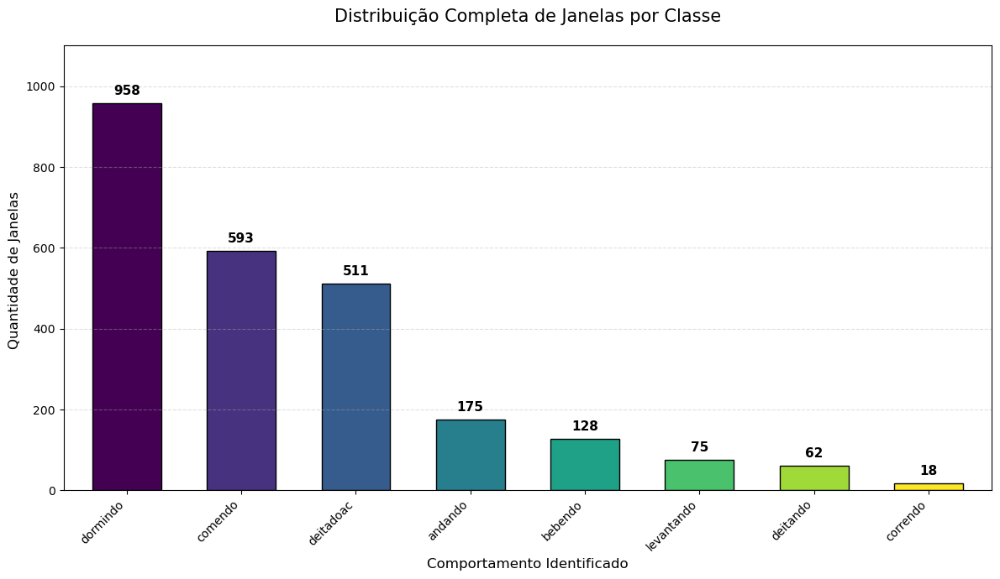


Resumo Geral do Dataset:
atividade
dormindo      958
comendo       593
deitadoac     511
andando       175
bebendo       128
levantando     75
deitando       62
correndo       18
Name: janela, dtype: int64


In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1. Caminho do arquivo
caminho_saida = r'C:\Users\franc\OneDrive\Desktop\dataset_treinamento_suinos.xlsx'

try:
    df_lido = pd.read_excel(caminho_saida)
    print(f"Arquivo carregado com sucesso! Total de linhas: {len(df_lido)}")
    
    # 2. Calcular o número de janelas por classe
    # Se a coluna 'janela' existir, contamos IDs únicos. Caso contrário, dividimos linhas por 100.
    if 'janela' in df_lido.columns:
        contagem_janelas = df_lido.groupby('atividade')['janela'].nunique()
    else:
        contagem_janelas = df_lido.groupby('atividade').size() / 100

    # 3. Mostrar TODAS as classes (Removido o filtro de 'atividades_ativas')
    contagem_total = contagem_janelas.sort_values(ascending=False)

    # 4. Gerar o Gráfico
    plt.figure(figsize=(12, 7))
    
    # Gerar cores automáticas para qualquer quantidade de barras
    cores = plt.cm.viridis(np.linspace(0, 1, len(contagem_total)))
    
    ax = contagem_total.plot(kind='bar', color=cores, edgecolor='black', width=0.6)

    # Adicionar os totais em cima das barras
    for p in ax.patches:
        valor = int(p.get_height())
        ax.annotate(f'{valor}', 
                    (p.get_x() + p.get_width() / 2., p.get_height()), 
                    ha='center', va='bottom', 
                    xytext=(0, 5), 
                    textcoords='offset points',
                    fontsize=11,
                    fontweight='bold')

    plt.title('Distribuição Completa de Janelas por Classe', fontsize=15, pad=20)
    plt.ylabel('Quantidade de Janelas ', fontsize=12)
    plt.xlabel('Comportamento Identificado', fontsize=12)
    
    # Rotação ajustada para 45 graus caso os nomes sejam longos
    plt.xticks(rotation=45, ha='right')
    plt.grid(axis='y', linestyle='--', alpha=0.4)
    
    # Margem superior para o número não cortar
    plt.ylim(0, contagem_total.max() * 1.15)

    plt.tight_layout()
    plt.show()

    print("\nResumo Geral do Dataset:")
    print(contagem_total)

except FileNotFoundError:
    print(f"Erro: O arquivo não foi encontrado em {caminho_saida}.")
except Exception as e:
    print(f"Ocorreu um erro inesperado: {e}")

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1. Caminho do arquivo
caminho_saida = r'C:\Users\franc\OneDrive\Desktop\dataset_treinamento_suinos.xlsx'

try:
    df_lido = pd.read_excel(caminho_saida)
    print(f"Arquivo carregado com sucesso! Total de linhas: {len(df_lido)}")
    # 1. Remover espaços em branco no início ou fim do texto
    df_lido['atividade'] = df_lido['atividade'].str.strip()
    df_lido['atividade'] = df_lido['atividade'].str.lower()



    # 2. Calcular o número de janelas por classe
    # Se a coluna 'janela' existir, contamos IDs únicos. Caso contrário, dividimos linhas por 100.
    if 'janela' in df_lido.columns:
        contagem_janelas = df_lido.groupby('atividade')['janela'].nunique()
    else:
        contagem_janelas = df_lido.groupby('atividade').size() / 100

    # 3. Mostrar TODAS as classes (Removido o filtro de 'atividades_ativas')
    contagem_total = contagem_janelas.sort_values(ascending=False)

    # 4. Gerar o Gráfico
    plt.figure(figsize=(12, 7))
    
    # Gerar cores automáticas para qualquer quantidade de barras
    cores = plt.cm.viridis(np.linspace(0, 1, len(contagem_total)))
    
    ax = contagem_total.plot(kind='bar', color=cores, edgecolor='black', width=0.6)

    # Adicionar os totais em cima das barras
    for p in ax.patches:
        valor = int(p.get_height())
        ax.annotate(f'{valor}', 
                    (p.get_x() + p.get_width() / 2., p.get_height()), 
                    ha='center', va='bottom', 
                    xytext=(0, 5), 
                    textcoords='offset points',
                    fontsize=11,
                    fontweight='bold')

    plt.title('Distribuição Completa de Janelas por Classe', fontsize=15, pad=20)
    plt.ylabel('Quantidade de Janelas ', fontsize=12)
    plt.xlabel('Comportamento Identificado', fontsize=12)
    
    # Rotação ajustada para 45 graus caso os nomes sejam longos
    plt.xticks(rotation=45, ha='right')
    plt.grid(axis='y', linestyle='--', alpha=0.4)
    
    # Margem superior para o número não cortar
    plt.ylim(0, contagem_total.max() * 1.15)

    plt.tight_layout()
    plt.show()

    print("\nResumo Geral do Dataset:")
    print(contagem_total)

except FileNotFoundError:
    print(f"Erro: O arquivo não foi encontrado em {caminho_saida}.")
except Exception as e:
    print(f"Ocorreu um erro inesperado: {e}")

Ocorreu um erro inesperado: [Errno 13] Permission denied: 'C:\\Users\\franc\\OneDrive\\Desktop\\dataset_treinamento_suinos.xlsx'


Arquivo carregado com sucesso! Total de linhas: 834100


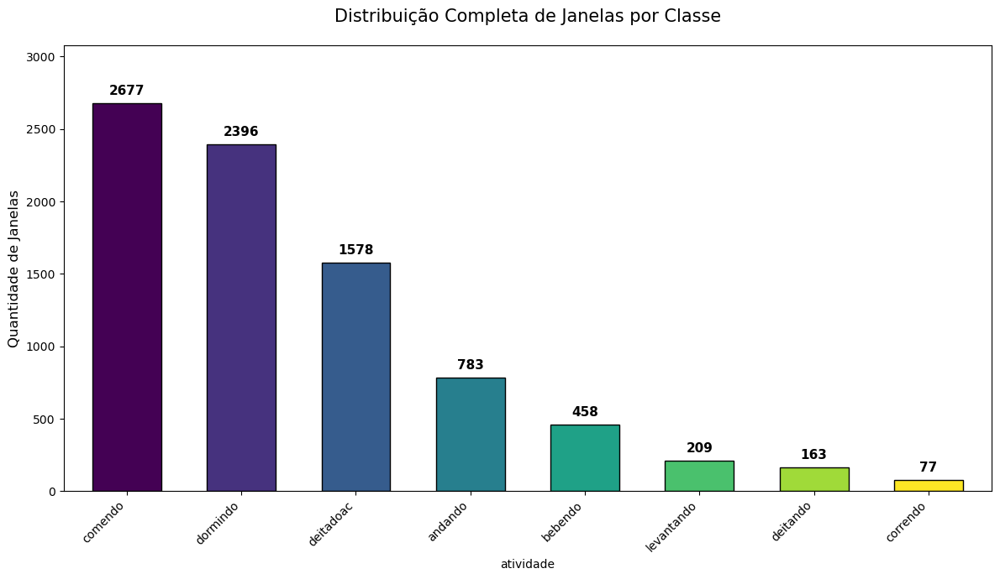


Resumo Geral do Dataset:
atividade
comendo       2677
dormindo      2396
deitadoac     1578
andando        783
bebendo        458
levantando     209
deitando       163
correndo        77
Name: janela, dtype: int64


In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

# 1. Caminho do arquivo
caminho_saida = r'C:\Users\franc\OneDrive\Desktop\dataset_treinamento_suinos.xlsx'

# --- VERIFICAÇÃO DE SEGURANÇA ---
if not os.path.exists(caminho_saida):
    print(f"ERRO: O arquivo não existe em: {caminho_saida}")
else:
    try:
        # Tenta ler o arquivo. Se der erro de 'zip file', ele avisará.
        df_lido = pd.read_excel(caminho_saida, engine='openpyxl')
        
        print(f"Arquivo carregado com sucesso! Total de linhas: {len(df_lido)}")

        # 1. Limpeza de texto
        df_lido['atividade'] = df_lido['atividade'].astype(str).str.strip().str.lower()

        # 2. Contagem de janelas
        if 'janela' in df_lido.columns:
            contagem_janelas = df_lido.groupby('atividade')['janela'].nunique()
        else:
            contagem_janelas = df_lido.groupby('atividade').size() / 100

        contagem_total = contagem_janelas.sort_values(ascending=False)

        # 3. Gerar o Gráfico
        plt.figure(figsize=(12, 7))
        cores = plt.cm.viridis(np.linspace(0, 1, len(contagem_total)))
        ax = contagem_total.plot(kind='bar', color=cores, edgecolor='black', width=0.6)

        # Totais em cima das barras
        for p in ax.patches:
            valor = int(p.get_height())
            ax.annotate(f'{valor}', 
                        (p.get_x() + p.get_width() / 2., p.get_height()), 
                        ha='center', va='bottom', 
                        xytext=(0, 5), 
                        textcoords='offset points',
                        fontsize=11, fontweight='bold')

        plt.title('Distribuição Completa de Janelas por Classe', fontsize=15, pad=20)
        plt.ylabel('Quantidade de Janelas', fontsize=12)
        plt.xticks(rotation=45, ha='right')
        plt.ylim(0, contagem_total.max() * 1.15)
        plt.tight_layout()
        plt.show()

        print("\nResumo Geral do Dataset:")
        print(contagem_total)

    except Exception as e:
        print(f"\n--- ERRO AO LER O EXCEL ---")
        print(f"Detalhe do erro: {e}")
        print("\nSUGESTÃO: O arquivo pode estar corrompido ou aberto no Excel.")
        print("Tente fechar o Excel ou rodar o código que gera as janelas novamente.")

File loaded successfully! Total rows: 834100


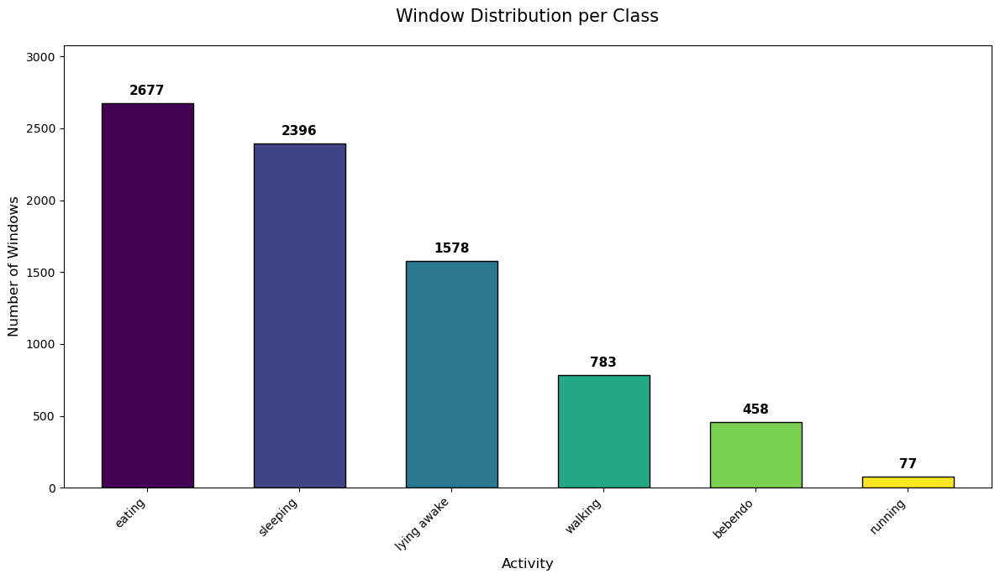


Dataset General Summary (in English):
atividade
eating         2677
sleeping       2396
lying awake    1578
walking         783
bebendo         458
running          77
Name: janela, dtype: int64


In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

# 1. File path
file_path = r'C:\Users\franc\OneDrive\Desktop\dataset_treinamento_suinos.xlsx'

# Dictionary for translation - Adjusting 'deitadoac' to 'lying awake'
class_translation = {
    'parado': 'standing',
    'andando': 'walking',
    'correndo': 'running',
    'comendo': 'eating',
    'fucando': 'rooting',     # Ajustado para caso o Excel esteja sem cedilha
    'fuçando': 'rooting',
    'dormindo': 'sleeping',
    'deitadoac': 'lying awake'
}

# --- SECURITY CHECK ---
if not os.path.exists(file_path):
    print(f"ERROR: File does not exist at: {file_path}")
else:
    try:
        # Load the file
        df_loaded = pd.read_excel(file_path, engine='openpyxl')
        
        print(f"File loaded successfully! Total rows: {len(df_loaded)}")

        # 1. Text cleaning
        df_loaded['atividade'] = df_loaded['atividade'].astype(str).str.strip().str.lower()

        # --- FILTER: Remove 'levantando' and 'deitando' ---
        excluded_classes = ['levantando', 'deitando']
        df_filtered = df_loaded[~df_loaded['atividade'].isin(excluded_classes)].copy()

        # --- TRANSLATION: Map classes to English ---
        df_filtered['atividade'] = df_filtered['atividade'].map(class_translation).fillna(df_filtered['atividade'])

        # 2. Window counting
        if 'janela' in df_filtered.columns:
            window_count = df_filtered.groupby('atividade')['janela'].nunique()
        else:
            window_count = df_filtered.groupby('atividade').size() / 100

        total_count = window_count.sort_values(ascending=False)

        # 3. Generate Chart
        plt.figure(figsize=(12, 7))
        colors = plt.cm.viridis(np.linspace(0, 1, len(total_count)))
        ax = total_count.plot(kind='bar', color=colors, edgecolor='black', width=0.6)

        # Add totals above bars
        for p in ax.patches:
            value = int(p.get_height())
            ax.annotate(f'{value}', 
                        (p.get_x() + p.get_width() / 2., p.get_height()), 
                        ha='center', va='bottom', 
                        xytext=(0, 5), 
                        textcoords='offset points',
                        fontsize=11, fontweight='bold')

        plt.title('Window Distribution per Class', fontsize=15, pad=20)
        plt.ylabel('Number of Windows', fontsize=12)
        plt.xlabel('Activity', fontsize=12)
        plt.xticks(rotation=45, ha='right')
        plt.ylim(0, total_count.max() * 1.15)
        plt.tight_layout()
        plt.show()

        print("\nDataset General Summary (in English):")
        print(total_count)

    except Exception as e:
        print(f"\n--- ERROR READING EXCEL FILE ---")
        print(f"Error details: {e}")

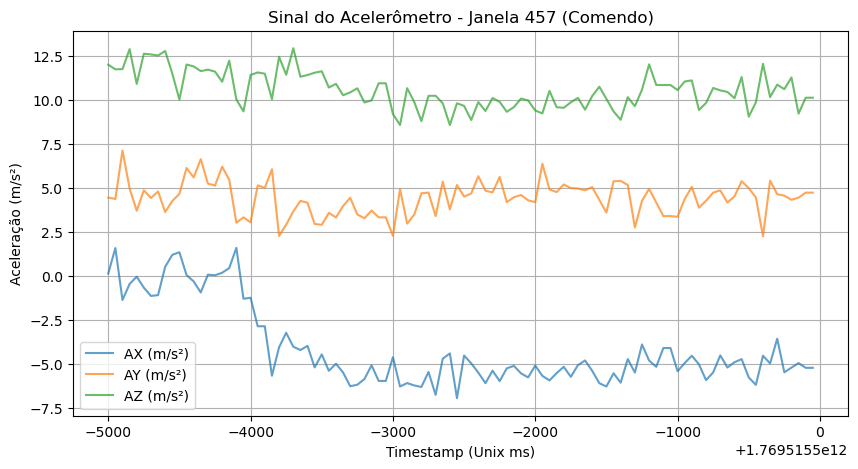

In [48]:
import matplotlib.pyplot as plt

# 1. Filtra especificamente a janela 456 e a atividade "comendo"
janela_id = 457
df_janela = df_final[(df_final['atividade'] == 'comendo') & (df_final['janela'] == janela_id)]

# 2. Gera o gráfico
if not df_janela.empty:
    plt.figure(figsize=(10, 5))
    
    # Plotando os três eixos
    plt.plot(df_janela['instante_tempo'], df_janela['AX'], label='AX (m/s²)', alpha=0.7)
    plt.plot(df_janela['instante_tempo'], df_janela['AY'], label='AY (m/s²)', alpha=0.7)
    plt.plot(df_janela['instante_tempo'], df_janela['AZ'], label='AZ (m/s²)', alpha=0.7)
    
    plt.title(f'Sinal do Acelerômetro - Janela {janela_id} (Comendo)')
    plt.xlabel('Timestamp (Unix ms)')
    plt.ylabel('Aceleração (m/s²)')
    plt.legend()
    plt.grid(True)
    plt.show()
else:
    print(f"Janela {janela_id} não encontrada ou não é 'comendo'.")

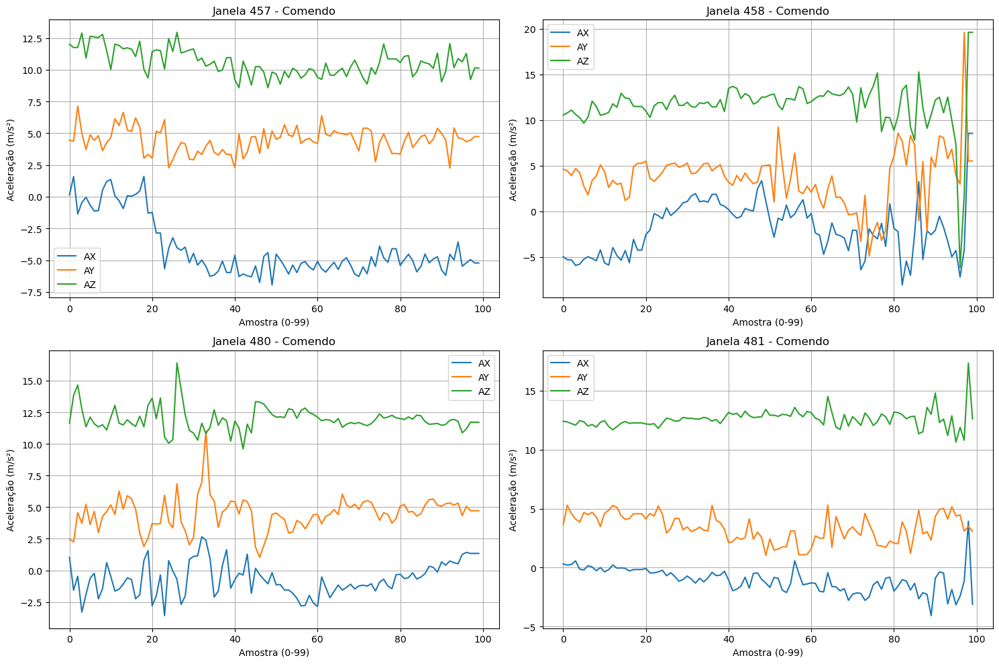

In [50]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()

for i, num_janela in enumerate(janelas_para_plotar):
    df_janela = df_comendo[df_comendo['janela'] == num_janela]
    
    # Plotar contra o índice (0 a 99) em vez de instante_tempo
    axes[i].plot(range(100), df_janela['AX'].values, label='AX')
    axes[i].plot(range(100), df_janela['AY'].values, label='AY')
    axes[i].plot(range(100), df_janela['AZ'].values, label='AZ')
    
    axes[i].set_title(f'Janela {num_janela} - Comendo')
    axes[i].set_xlabel('Amostra (0-99)')
    axes[i].set_ylabel('Aceleração (m/s²)')
    axes[i].grid(True)
    axes[i].legend()

plt.tight_layout()
plt.show()

# Drinking Analysis


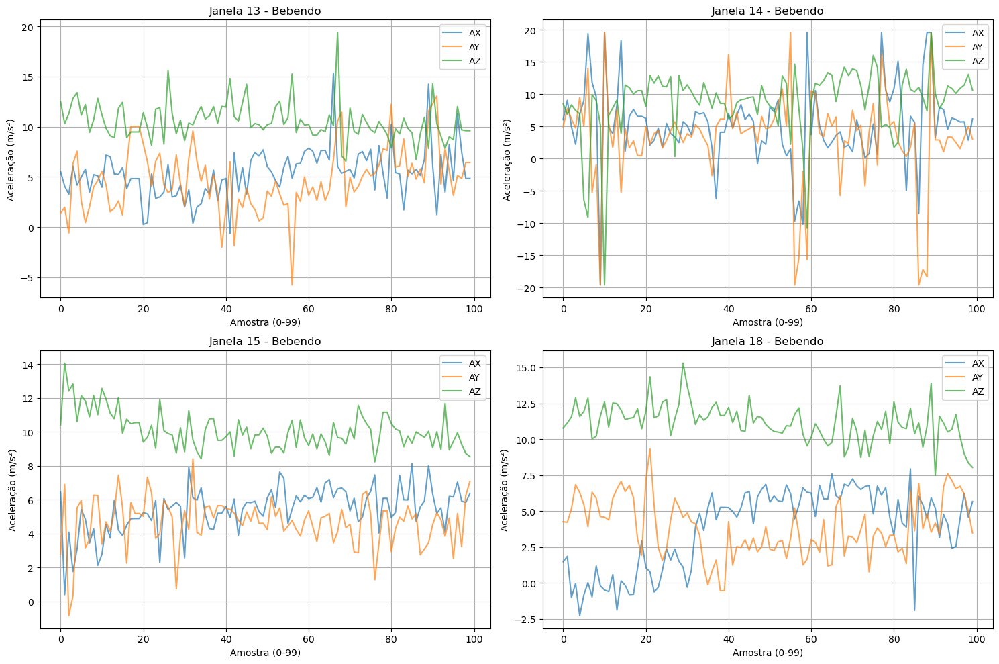

In [51]:
import matplotlib.pyplot as plt

# 1. Filtra o dataset para apenas as janelas de "bebendo"
df_bebendo = df_final[df_final['atividade'] == 'bebendo']
janelas_unicas_bebendo = sorted(df_bebendo['janela'].unique())

# 2. Pega as 4 primeiras janelas de "bebendo"
janelas_para_plotar = janelas_unicas_bebendo[:4]

# 3. Cria o layout de 2x2
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()

for i, num_janela in enumerate(janelas_para_plotar):
    df_janela = df_bebendo[df_bebendo['janela'] == num_janela]
    
    # Plotar contra o índice (0 a 99) para normalizar a visualização
    axes[i].plot(range(100), df_janela['AX'].values, label='AX', alpha=0.7)
    axes[i].plot(range(100), df_janela['AY'].values, label='AY', alpha=0.7)
    axes[i].plot(range(100), df_janela['AZ'].values, label='AZ', alpha=0.7)
    
    axes[i].set_title(f'Janela {num_janela} - Bebendo')
    axes[i].set_xlabel('Amostra (0-99)')
    axes[i].set_ylabel('Aceleração (m/s²)')
    axes[i].grid(True)
    axes[i].legend()

plt.tight_layout()
plt.show()

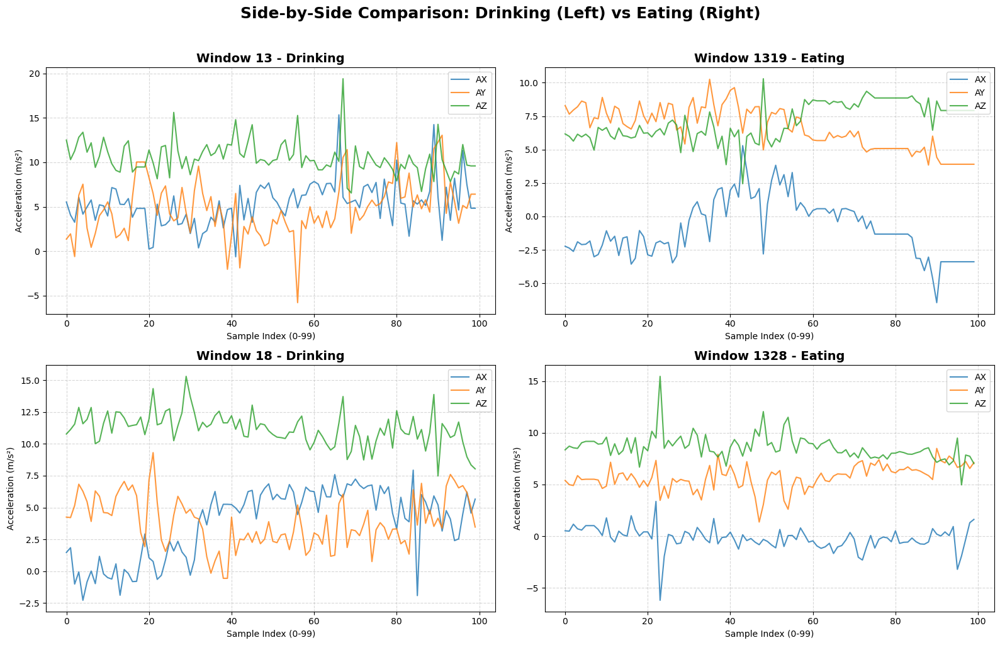

In [24]:
import matplotlib.pyplot as plt

# 1. Normalização rigorosa para evitar erros de busca
df_final['atividade'] = df_final['atividade'].astype(str).str.strip().str.lower()

# 2. Definição das janelas específicas encontradas
# Esquerda (Drinking)
j_d1, j_d2 = 13, 18
# Direita (Eating)
j_e1, j_e2 = 1319, 1328

# 3. Mapeamento para o layout 2x2: [Esq, Dir, Esq, Dir]
# Isso garante que a primeira linha tenha um de cada e a segunda também.
plot_list = [
    (df_final[(df_final['atividade'] == 'bebendo') & (df_final['janela'] == j_d1)], j_d1, 'Drinking'),
    (df_final[(df_final['atividade'] == 'comendo') & (df_final['janela'] == j_e1)], j_e1, 'Eating'),
    (df_final[(df_final['atividade'] == 'bebendo') & (df_final['janela'] == j_d2)], j_d2, 'Drinking'),
    (df_final[(df_final['atividade'] == 'comendo') & (df_final['janela'] == j_e2)], j_e2, 'Eating')
]

# 4. Criação do Gráfico
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for i, (df_plot, window_num, label) in enumerate(plot_list):
    if not df_plot.empty:
        # Plot dos eixos AX, AY e AZ
        axes[i].plot(range(len(df_plot)), df_plot['AX'].values, label='AX', alpha=0.8, color='#1f77b4')
        axes[i].plot(range(len(df_plot)), df_plot['AY'].values, label='AY', alpha=0.8, color='#ff7f0e')
        axes[i].plot(range(len(df_plot)), df_plot['AZ'].values, label='AZ', alpha=0.8, color='#2ca02c')
        
        # Estilização em Inglês
        axes[i].set_title(f'Window {window_num} - {label}', fontsize=14, fontweight='bold')
        axes[i].set_xlabel('Sample Index (0-99)')
        axes[i].set_ylabel('Acceleration (m/s²)')
        axes[i].grid(True, linestyle='--', alpha=0.5)
        axes[i].legend(loc='upper right')
    else:
        # Caso algum número ainda falhe, exibe aviso visual
        axes[i].text(0.5, 0.5, f'Window {window_num}\nNot found for {label}', 
                     ha='center', va='center', color='red', fontweight='bold')
        axes[i].set_title(f'Data Missing: {label}')

# Título superior organizando as colunas
plt.suptitle('Side-by-Side Comparison: Drinking (Left) vs Eating (Right)', fontsize=18, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

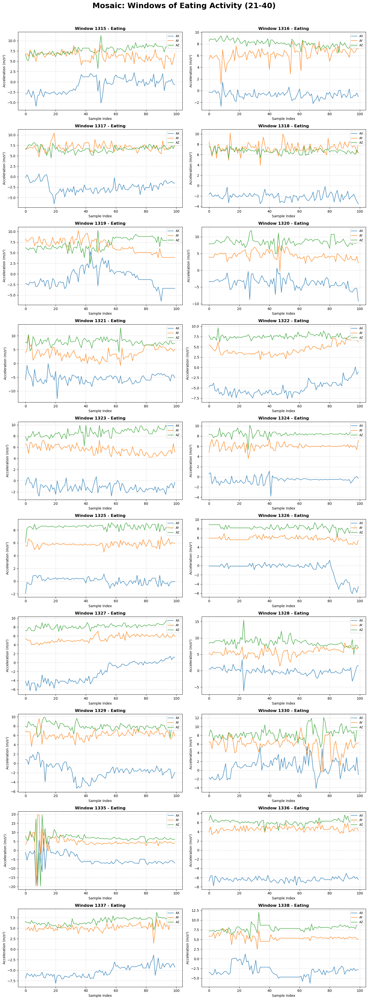

Windows 21 to 40 found for Eating: [np.int64(1315), np.int64(1316), np.int64(1317), np.int64(1318), np.int64(1319), np.int64(1320), np.int64(1321), np.int64(1322), np.int64(1323), np.int64(1324), np.int64(1325), np.int64(1326), np.int64(1327), np.int64(1328), np.int64(1329), np.int64(1330), np.int64(1335), np.int64(1336), np.int64(1337), np.int64(1338)]


In [23]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Normalização e Filtro
df_final['atividade'] = df_final['atividade'].astype(str).str.strip().str.lower()
df_eating = df_final[df_final['atividade'].isin(['comendo', 'eating'])]

# 2. Seleciona o intervalo das janelas 21 a 40 (índice 20 ao 40)
all_eating_windows = sorted(df_eating['janela'].unique())
next_20_windows = all_eating_windows[20:40]

# 3. Configuração do Mosaico (10 linhas x 2 colunas)
# Aumentamos a altura (figsize) para 40 para manter a clareza
rows = 10
cols = 2
fig, axes = plt.subplots(rows, cols, figsize=(15, 40))
axes = axes.flatten()

# 4. Loop de plotagem
for i, win_num in enumerate(next_20_windows):
    df_plot = df_eating[df_eating['janela'] == win_num]
    
    # Plot AX, AY, AZ
    axes[i].plot(range(len(df_plot)), df_plot['AX'].values, label='AX', alpha=0.8, color='#1f77b4')
    axes[i].plot(range(len(df_plot)), df_plot['AY'].values, label='AY', alpha=0.8, color='#ff7f0e')
    axes[i].plot(range(len(df_plot)), df_plot['AZ'].values, label='AZ', alpha=0.8, color='#2ca02c')
    
    # Textos em Inglês
    axes[i].set_title(f'Window {win_num} - Eating', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Sample Index')
    axes[i].set_ylabel('Acceleration (m/s²)')
    axes[i].grid(True, linestyle='--', alpha=0.5)
    axes[i].legend(loc='upper right', fontsize='small')

# Remove eixos vazios caso existam menos de 20 janelas neste intervalo
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Mosaic: Windows of Eating Activity (21-40)', fontsize=22, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

# Verificação das janelas plotadas no console
print(f"Windows 21 to 40 found for Eating: {next_20_windows}")

# Running Examples

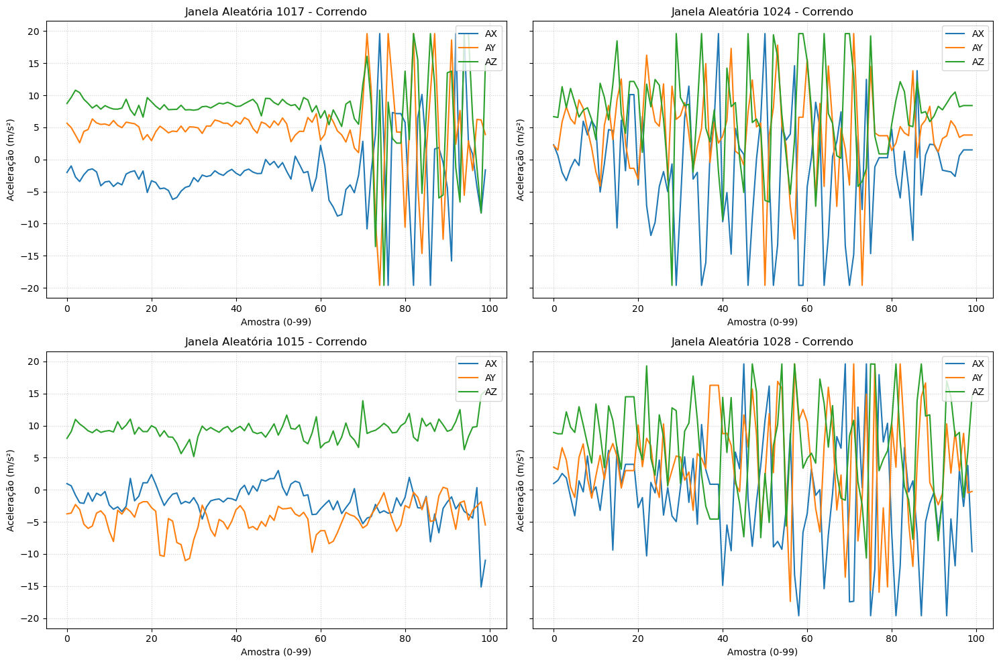

In [35]:
import matplotlib.pyplot as plt
import random

# 1. Filtra o dataset para apenas as janelas de "correndo"
df_correndo = df_final[df_final['atividade'] == 'correndo']
janelas_unicas_correndo = list(df_correndo['janela'].unique())

# 2. Seleciona 4 janelas ALEATÓRIAS (Corrigido para olhar apenas correndo)
if len(janelas_unicas_correndo) >= 4:
    janelas_para_plotar = random.sample(janelas_unicas_correndo, 4)
elif len(janelas_unicas_correndo) > 0:
    janelas_para_plotar = janelas_unicas_correndo
    print(f"Aviso: Foram encontradas apenas {len(janelas_unicas_correndo)} janelas de 'correndo'.")
else:
    janelas_para_plotar = []
    print("Erro: Nenhuma janela de 'correndo' encontrada no dataset.")

if janelas_para_plotar:
    # 3. Cria o layout de 2x2
    fig, axes = plt.subplots(2, 2, figsize=(15, 10), sharey=True)
    axes = axes.flatten()

    for i, num_janela in enumerate(janelas_para_plotar):
        df_janela = df_correndo[df_correndo['janela'] == num_janela]
        
        # Só tenta plotar se a janela tiver exatamente 100 amostras
        # Isso evita o erro de dimensões diferentes (x=100, y=0)
        if len(df_janela) == 100:
            axes[i].plot(range(100), df_janela['AX'].values, label='AX', color='#1f77b4')
            axes[i].plot(range(100), df_janela['AY'].values, label='AY', color='#ff7f0e')
            axes[i].plot(range(100), df_janela['AZ'].values, label='AZ', color='#2ca02c')
            
            axes[i].set_title(f'Janela Aleatória {num_janela} - Correndo')
            axes[i].set_xlabel('Amostra (0-99)')
            axes[i].set_ylabel('Aceleração (m/s²)')
            axes[i].grid(True, linestyle=':', alpha=0.6)
            axes[i].legend(loc='upper right')
        else:
            axes[i].set_title(f'Janela {num_janela} - Incompleta ({len(df_janela)} amostras)')

    plt.tight_layout()
    plt.show()

# Walking examples

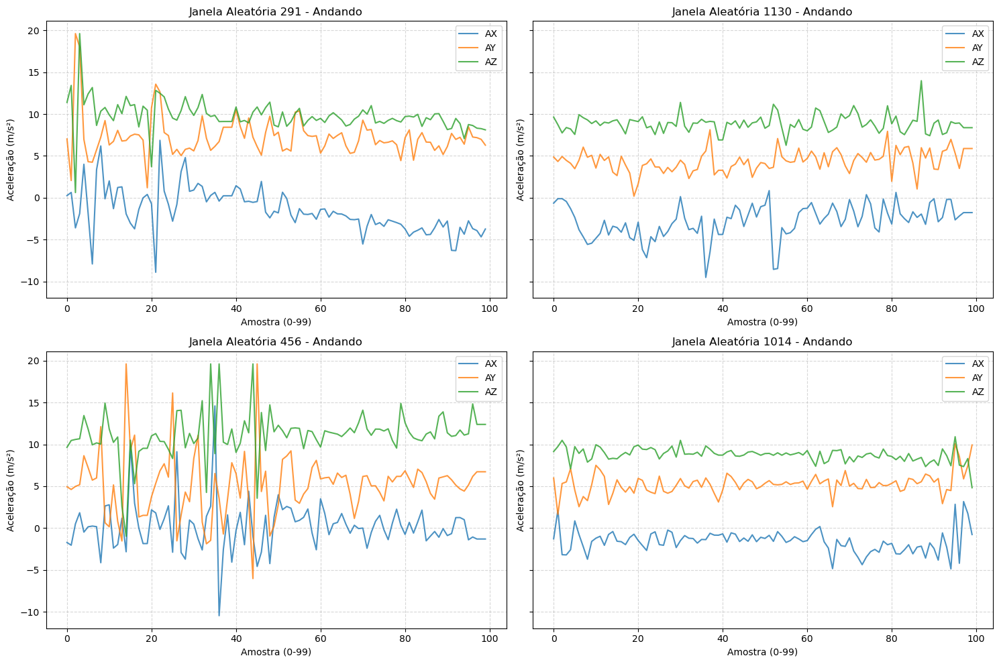

In [14]:
import matplotlib.pyplot as plt
import random

# 1. Filtra o dataset para apenas as janelas de "andando"
df_andando = df_final[df_final['atividade'] == 'andando']
janelas_unicas_andando = list(df_andando['janela'].unique())

# 2. Seleciona 4 janelas ALEATÓRIAS
# O random.sample garante que as janelas sejam diferentes entre si
if len(janelas_unicas_andando) >= 4:
    janelas_para_plotar = random.sample(janelas_unicas_andando, 4)
else:
    janelas_para_plotar = janelas_unicas_andando
    print(f"Aviso: Foram encontradas apenas {len(janelas_unicas_andando)} janelas.")

# 3. Cria o layout de 2x2
fig, axes = plt.subplots(2, 2, figsize=(15, 10), sharey=True)
axes = axes.flatten()

for i, num_janela in enumerate(janelas_para_plotar):
    df_janela = df_andando[df_andando['janela'] == num_janela]
    
    # Plotar contra o índice (0 a 99)
    axes[i].plot(range(100), df_janela['AX'].values, label='AX', color='#1f77b4', alpha=0.8)
    axes[i].plot(range(100), df_janela['AY'].values, label='AY', color='#ff7f0e', alpha=0.8)
    axes[i].plot(range(100), df_janela['AZ'].values, label='AZ', color='#2ca02c', alpha=0.8)
    
    axes[i].set_title(f'Janela Aleatória {num_janela} - Andando')
    axes[i].set_xlabel('Amostra (0-99)')
    axes[i].set_ylabel('Aceleração (m/s²)')
    axes[i].grid(True, linestyle='--', alpha=0.5)
    axes[i].legend(loc='upper right')

plt.tight_layout()
plt.show()

# Lying examples

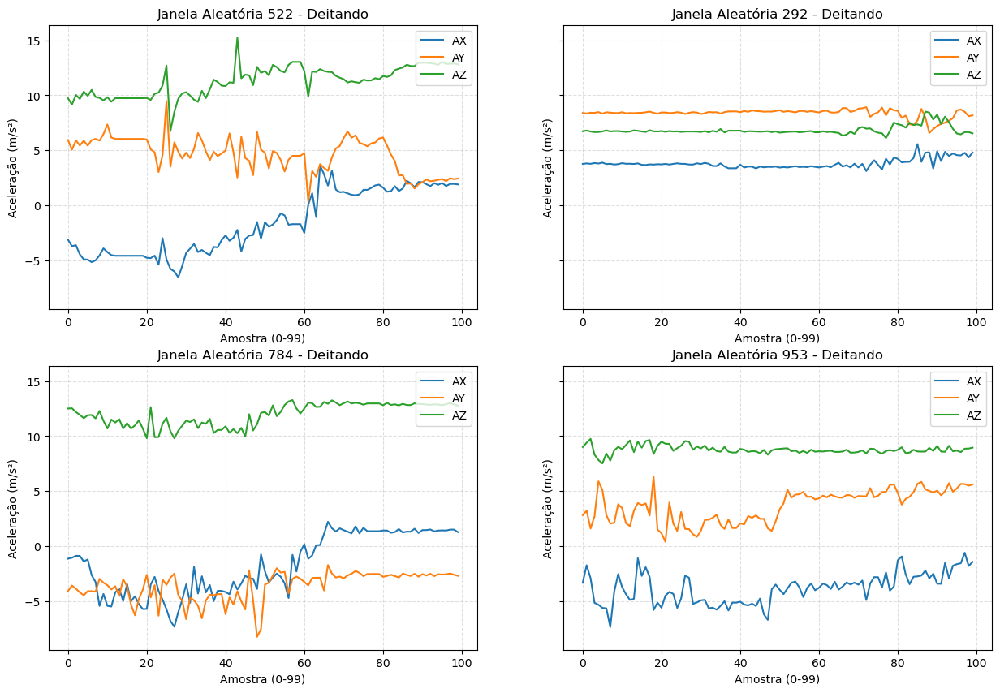

In [18]:
import matplotlib.pyplot as plt
import random

# 1. Filtra o dataset para a atividade "deitando"
# Nota: Verifique se o nome exato é 'deitando' ou 'deitado' no seu dataset
df_deitando = df_final[df_final['atividade'] == 'deitando']
janelas_unicas_deitando = list(df_deitando['janela'].unique())

# 2. Seleciona 4 janelas ALEATÓRIAS
if len(janelas_unicas_deitando) >= 4:
    janelas_para_plotar = random.sample(janelas_unicas_deitando, 4)
elif len(janelas_unicas_deitando) > 0:
    janelas_para_plotar = janelas_unicas_deitando
    print(f"Aviso: Foram encontradas apenas {len(janelas_unicas_deitando)} janelas de 'deitando'.")
else:
    janelas_para_plotar = []
    print("Erro: Nenhuma janela de 'deitando' encontrada. Verifique se o nome da classe está correto.")

if janelas_para_plotar:
    # 3. Cria o layout de 2x2
    fig, axes = plt.subplots(2, 2, figsize=(15, 10), sharey=True)
    axes = axes.flatten()

    for i, num_janela in enumerate(janelas_para_plotar):
        df_janela = df_deitando[df_deitando['janela'] == num_janela]
        
        if len(df_janela) == 100:
            # Plotar os eixos AX, AY e AZ
            axes[i].plot(range(100), df_janela['AX'].values, label='AX', color='#1f77b4')
            axes[i].plot(range(100), df_janela['AY'].values, label='AY', color='#ff7f0e')
            axes[i].plot(range(100), df_janela['AZ'].values, label='AZ', color='#2ca02c')
            
            axes[i].set_title(f'Janela Aleatória {num_janela} - Deitando')
            axes[i].set_xlabel('Amostra (0-99)')
            axes[i].set_ylabel('Aceleração (m/s²)')
            axes[i].grid(True, linestyle='--', alpha=0.4)
            axes[i].legend(loc='upper right')
        else:
            axes[i].set_title(f'Janela {num_janela} - Dados insuficientes')

# getting up

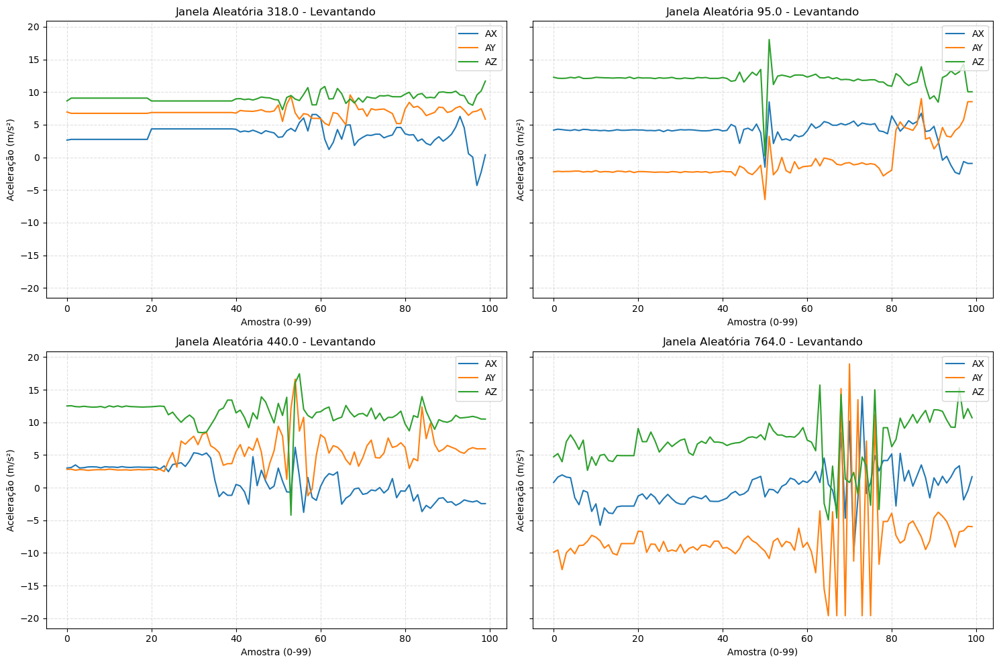

In [9]:
import matplotlib.pyplot as plt
import random

# 1. Filtra o dataset para a atividade "levantando"
df_levantando = df_final[df_final['atividade'] == 'levantando']
janelas_unicas_levantando = list(df_levantando['janela'].unique())

# 2. Seleciona 4 janelas ALEATÓRIAS
if len(janelas_unicas_levantando) >= 4:
    janelas_para_plotar = random.sample(janelas_unicas_levantando, 4)
elif len(janelas_unicas_levantando) > 0:
    janelas_para_plotar = janelas_unicas_levantando
    print(f"Aviso: Foram encontradas apenas {len(janelas_unicas_levantando)} janelas de 'levantando'.")
else:
    janelas_para_plotar = []
    print("Erro: Nenhuma janela de 'levantando' encontrada. Verifique a grafia no seu gabarito.")

if janelas_para_plotar:
    # 3. Cria o layout de 2x2
    fig, axes = plt.subplots(2, 2, figsize=(15, 10), sharey=True)
    axes = axes.flatten()

    for i, num_janela in enumerate(janelas_para_plotar):
        df_janela = df_levantando[df_levantando['janela'] == num_janela]
        
        if len(df_janela) == 100:
            # Plotar os eixos AX, AY e AZ
            axes[i].plot(range(100), df_janela['AX'].values, label='AX', color='#1f77b4')
            axes[i].plot(range(100), df_janela['AY'].values, label='AY', color='#ff7f0e')
            axes[i].plot(range(100), df_janela['AZ'].values, label='AZ', color='#2ca02c')
            
            axes[i].set_title(f'Janela Aleatória {num_janela} - Levantando')
            axes[i].set_xlabel('Amostra (0-99)')
            axes[i].set_ylabel('Aceleração (m/s²)')
            axes[i].grid(True, linestyle='--', alpha=0.4)
            axes[i].legend(loc='upper right')
        else:
            axes[i].set_title(f'Janela {num_janela} - Dados incompletos')

    plt.tight_layout()
    plt.show()

# 29/01/26 data preparing

In [24]:
import pandas as pd
from datetime import datetime
import numpy as np # Importante para checar valores vazios

# 1. Configurações de Caminho
caminho_input = r'C:\Users\franc\OneDrive\Desktop\verde280126.xlsx'
caminho_xlsx = r'C:\Users\franc\OneDrive\Desktop\verde280126_FINAL.xlsx'

# 2. Carregar dados
df_raw = pd.read_excel(caminho_input)

# Listas para as colunas
data_hora_ms = []
unix_ms_lista = []
ax_ms2 = []
ay_ms2 = []
az_ms2 = []

# Variáveis de controle
ultimo_segundo = -1
ms_atual = 0
epoch_ref = datetime(1970, 1, 1)
dt_objeto_anterior = None 

FATOR_CONVERSAO = 9.80665 / 16384.0

# 3. Processamento
for index, row in df_raw.iterrows():
    dt_valor = row.iloc[0]
    
    # --- PROTEÇÃO CONTRA LINHAS VAZIAS ---
    # Verifica se o valor é nulo, NaN ou NaT
    if pd.isna(dt_valor):
        continue 
        
    dt_objeto = dt_valor if isinstance(dt_valor, datetime) else datetime.strptime(str(dt_valor)[:19], '%d/%m/%Y %H:%M:%S')
    segundo_atual = dt_objeto.second

    # Lógica de Preenchimento (Gap Filling)
    if ultimo_segundo != -1 and segundo_atual != ultimo_segundo and dt_objeto_anterior is not None:
        while ms_atual < 950:
            ms_atual += 50
            dt_com_ms = dt_objeto_anterior.replace(microsecond=ms_atual * 1000)
            
            data_hora_ms.append(dt_com_ms.strftime('%d/%m/%Y %H:%M:%S,%f')[:-3])
            segundos_unix = int((dt_objeto_anterior - epoch_ref).total_seconds())
            unix_ms_lista.append((segundos_unix * 1000) + ms_atual)
            
            ax_ms2.append(ax_ms2[-1])
            ay_ms2.append(ay_ms2[-1])
            az_ms2.append(az_ms2[-1])

    # Reset do ms no início de cada segundo
    if segundo_atual != ultimo_segundo:
        ms_atual = 0
        ultimo_segundo = segundo_atual
    else:
        ms_atual += 50
        
    ms_final = min(ms_atual, 950)
    dt_com_ms = dt_objeto.replace(microsecond=ms_final * 1000)
    dt_objeto_anterior = dt_objeto
    
    data_hora_ms.append(dt_com_ms.strftime('%d/%m/%Y %H:%M:%S,%f')[:-3])
    segundos_unix = int((dt_objeto - epoch_ref).total_seconds())
    unix_ms_lista.append((segundos_unix * 1000) + ms_final)
    
    ax_ms2.append(row.iloc[3] * FATOR_CONVERSAO)
    ay_ms2.append(row.iloc[4] * FATOR_CONVERSAO)
    az_ms2.append(row.iloc[5] * FATOR_CONVERSAO)

# 4. Criar o DataFrame e Salvar
df_final = pd.DataFrame({
    'DataHora_ms': data_hora_ms,
    'instante_tempo': unix_ms_lista,
    'AX': ax_ms2,
    'AY': ay_ms2,
    'AZ': az_ms2,
    'ID': 1
})

df_final.to_excel(caminho_xlsx, index=False)
print(f"Sucesso! Arquivo salvo em: {caminho_xlsx}")

Sucesso! Arquivo salvo em: C:\Users\franc\OneDrive\Desktop\verde280126_FINAL.xlsx


# 30/01/26 data preparing

In [20]:
import pandas as pd
from datetime import datetime
import numpy as np # Importante para checar valores vazios

# 1. Configurações de Caminho
caminho_input = r'C:\Users\franc\OneDrive\Desktop\preto300126.xlsx'
caminho_xlsx = r'C:\Users\franc\OneDrive\Desktop\preto300126_FINAL.xlsx'

# 2. Carregar dados
df_raw = pd.read_excel(caminho_input)

# Listas para as colunas
data_hora_ms = []
unix_ms_lista = []
ax_ms2 = []
ay_ms2 = []
az_ms2 = []

# Variáveis de controle
ultimo_segundo = -1
ms_atual = 0
epoch_ref = datetime(1970, 1, 1)
dt_objeto_anterior = None 

FATOR_CONVERSAO = 9.80665 / 16384.0

# 3. Processamento
for index, row in df_raw.iterrows():
    dt_valor = row.iloc[0]
    
    # --- PROTEÇÃO CONTRA LINHAS VAZIAS ---
    # Verifica se o valor é nulo, NaN ou NaT
    if pd.isna(dt_valor):
        continue 
        
    dt_objeto = dt_valor if isinstance(dt_valor, datetime) else datetime.strptime(str(dt_valor)[:19], '%d/%m/%Y %H:%M:%S')
    segundo_atual = dt_objeto.second

    # Lógica de Preenchimento (Gap Filling)
    if ultimo_segundo != -1 and segundo_atual != ultimo_segundo and dt_objeto_anterior is not None:
        while ms_atual < 950:
            ms_atual += 50
            dt_com_ms = dt_objeto_anterior.replace(microsecond=ms_atual * 1000)
            
            data_hora_ms.append(dt_com_ms.strftime('%d/%m/%Y %H:%M:%S,%f')[:-3])
            segundos_unix = int((dt_objeto_anterior - epoch_ref).total_seconds())
            unix_ms_lista.append((segundos_unix * 1000) + ms_atual)
            
            ax_ms2.append(ax_ms2[-1])
            ay_ms2.append(ay_ms2[-1])
            az_ms2.append(az_ms2[-1])

    # Reset do ms no início de cada segundo
    if segundo_atual != ultimo_segundo:
        ms_atual = 0
        ultimo_segundo = segundo_atual
    else:
        ms_atual += 50
        
    ms_final = min(ms_atual, 950)
    dt_com_ms = dt_objeto.replace(microsecond=ms_final * 1000)
    dt_objeto_anterior = dt_objeto
    
    data_hora_ms.append(dt_com_ms.strftime('%d/%m/%Y %H:%M:%S,%f')[:-3])
    segundos_unix = int((dt_objeto - epoch_ref).total_seconds())
    unix_ms_lista.append((segundos_unix * 1000) + ms_final)
    
    ax_ms2.append(row.iloc[3] * FATOR_CONVERSAO)
    ay_ms2.append(row.iloc[4] * FATOR_CONVERSAO)
    az_ms2.append(row.iloc[5] * FATOR_CONVERSAO)

# 4. Criar o DataFrame e Salvar
df_final = pd.DataFrame({
    'DataHora_ms': data_hora_ms,
    'instante_tempo': unix_ms_lista,
    'AX': ax_ms2,
    'AY': ay_ms2,
    'AZ': az_ms2,
    'ID': 1
})

df_final.to_excel(caminho_xlsx, index=False)
print(f"Sucesso! Arquivo salvo em: {caminho_xlsx}")

Sucesso! Arquivo salvo em: C:\Users\franc\OneDrive\Desktop\preto300126_FINAL.xlsx


# 31/01/26 data preparing

In [6]:
import pandas as pd
from datetime import datetime
import numpy as np

# 1. Configurações de Caminho
caminho_input = r'C:\Users\franc\OneDrive\Desktop\verde270126.xlsx'
caminho_xlsx = r'C:\Users\franc\OneDrive\Desktop\verde270126_FINAL.xlsx'

# 2. Carregar dados
df_raw = pd.read_excel(caminho_input)

# Listas para as colunas
data_hora_ms = []
unix_ms_lista = []
ax_ms2 = []
ay_ms2 = []
az_ms2 = []

# Variáveis de controle
ultimo_segundo = -1
ms_atual = 0
epoch_ref = datetime(1970, 1, 1)
dt_objeto_anterior = None 

FATOR_CONVERSAO = 9.80665 / 16384.0

print("Lendo arquivo e iniciando processamento...")

# 3. Processamento
for index, row in df_raw.iterrows():
    dt_valor = row.iloc[0]
    
    # --- PROTEÇÃO TOTAL CONTRA DATAS INVÁLIDAS ---
    if pd.isna(dt_valor):
        continue 
    
    try:
        # Se já for um objeto datetime, apenas usa. 
        # Se for string (como o erro '2003-05-40'), o pd.to_datetime com errors='coerce' 
        # transforma o erro em NaT (Not a Time) em vez de quebrar o código.
        dt_objeto = pd.to_datetime(dt_valor, dayfirst=True, errors='coerce')
        
        # Se for uma data impossível (como dia 40), o resultado será NaT. Pulamos essa linha.
        if pd.isna(dt_objeto):
            # print(f"Linha {index+2} ignorada (Data Corrompida): {dt_valor}")
            continue
            
        # Garante que dt_objeto seja um datetime puro do Python para os cálculos abaixo
        if isinstance(dt_objeto, pd.Timestamp):
            dt_objeto = dt_objeto.to_pydatetime()

    except Exception:
        continue

    segundo_atual = dt_objeto.second

    # Lógica de Preenchimento (Gap Filling)
    if ultimo_segundo != -1 and segundo_atual != ultimo_segundo and dt_objeto_anterior is not None:
        while ms_atual < 950:
            ms_atual += 50
            dt_com_ms = dt_objeto_anterior.replace(microsecond=ms_atual * 1000)
            
            data_hora_ms.append(dt_com_ms.strftime('%d/%m/%Y %H:%M:%S,%f')[:-3])
            segundos_unix = int((dt_objeto_anterior - epoch_ref).total_seconds())
            unix_ms_lista.append((segundos_unix * 1000) + ms_atual)
            
            # Repete o último valor para manter a continuidade no gap
            ax_ms2.append(ax_ms2[-1] if ax_ms2 else 0)
            ay_ms2.append(ay_ms2[-1] if ay_ms2 else 0)
            az_ms2.append(az_ms2[-1] if az_ms2 else 0)

    # Reset do ms no início de cada segundo
    if segundo_atual != ultimo_segundo:
        ms_atual = 0
        ultimo_segundo = segundo_atual
    else:
        ms_atual += 50
        
    ms_final = min(ms_atual, 950)
    dt_com_ms = dt_objeto.replace(microsecond=ms_final * 1000)
    dt_objeto_anterior = dt_objeto
    
    data_hora_ms.append(dt_com_ms.strftime('%d/%m/%Y %H:%M:%S,%f')[:-3])
    segundos_unix = int((dt_objeto - epoch_ref).total_seconds())
    unix_ms_lista.append((segundos_unix * 1000) + ms_final)
    
    ax_ms2.append(row.iloc[3] * FATOR_CONVERSAO)
    ay_ms2.append(row.iloc[4] * FATOR_CONVERSAO)
    az_ms2.append(row.iloc[5] * FATOR_CONVERSAO)

# 4. Criar o DataFrame e Salvar
df_final = pd.DataFrame({
    'DataHora_ms': data_hora_ms,
    'instante_tempo': unix_ms_lista,
    'AX': ax_ms2,
    'AY': ay_ms2,
    'AZ': az_ms2,
    'ID': 1
})

df_final.to_excel(caminho_xlsx, index=False)
print(f"Sucesso! Arquivo processado ignorando erros de data.")
print(f"Salvo em: {caminho_xlsx}")

Lendo arquivo e iniciando processamento...
Sucesso! Arquivo processado ignorando erros de data.
Salvo em: C:\Users\franc\OneDrive\Desktop\verde270126_FINAL.xlsx


# Code to continue annotating the dataset from the previous point

In [2]:
import pandas as pd
import numpy as np
import os

# 1. Caminhos
caminho_dados = r'C:\Users\franc\OneDrive\Desktop\ver270126_FINAL.xlsx'
caminho_gabarito = r'C:\Users\franc\OneDrive\Desktop\anotverde2701.xlsx'
caminho_saida = r'C:\Users\franc\OneDrive\Desktop\dataset_treinamento_suinos.xlsx'

# 2. Carregar dados do Dia 29
df_dados = pd.read_excel(caminho_dados)
df_gabarito = pd.read_excel(caminho_gabarito).dropna(subset=['unicio unix', 'fim unix'])

# Garantir tipos numéricos para comparação
df_dados['instante_tempo'] = pd.to_numeric(df_dados['instante_tempo']).astype('int64')
df_gabarito['unicio unix'] = pd.to_numeric(df_gabarito['unicio unix']).astype('int64')
df_gabarito['fim unix'] = pd.to_numeric(df_gabarito['fim unix']).astype('int64')

# --- LÓGICA DE CONTINUIDADE (VERIFICAR ÚLTIMA LINHA) ---
proxima_janela_id = 1
df_existente = pd.DataFrame()

if os.path.exists(caminho_saida):
    df_existente = pd.read_excel(caminho_saida)
    if not df_existente.empty:
        # Pega o ID da última janela registrada na última linha
        ultimo_id = df_existente['janela'].iloc[-1] 
        proxima_janela_id = int(ultimo_id) + 1
        print(f"Arquivo existente encontrado. Continuando a partir da janela: {proxima_janela_id}")
else:
    print("Arquivo de saída não encontrado. Iniciando novo dataset.")

lista_trechos = []

# 3. Processamento
# Ordenamos o gabarito pelo tempo para garantir a sequência
df_gabarito = df_gabarito.sort_values('unicio unix')

for _, row in df_gabarito.iterrows():
    u_ini = int(row['unicio unix'])
    u_fim = int(row['fim unix'])
    rotulo = row['atividade']
    
    # Encontra os índices no df_dados
    idx_ini = df_dados['instante_tempo'].searchsorted(u_ini)
    idx_fim = df_dados['instante_tempo'].searchsorted(u_fim)
    
    # Gera janelas de 100 linhas (Ex: 10Hz = 10 segundos por janela)
    for i in range(idx_ini, idx_fim, 100):
        bloco = df_dados.iloc[i : i + 100].copy()
        
        if len(bloco) == 100:
            bloco['atividade'] = rotulo
            bloco['janela'] = proxima_janela_id
            lista_trechos.append(bloco)
            proxima_janela_id += 1

# 4. Salvar mantendo o histórico
if lista_trechos:
    df_novos = pd.concat(lista_trechos, ignore_index=True)
    
    # Une o que já existia (Dia 27, etc) com o novo (Dia 29)
    df_final = pd.concat([df_existente, df_novos], ignore_index=True)
    
    # Organiza as colunas conforme seu padrão
    colunas = ['DataHora_ms', 'instante_tempo', 'AX', 'AY', 'AZ', 'ID', 'atividade', 'janela']
    
    # Filtra apenas as colunas que existem para evitar erro de KeyError
    colunas_presentes = [c for c in colunas if c in df_final.columns]
    
    df_final[colunas_presentes].to_excel(caminho_saida, index=False)
    
    print(f"### Sucesso!")
    print(f"Janelas adicionadas hoje: {len(lista_trechos)}")
    print(f"Último ID de janela no arquivo: {df_final['janela'].iloc[-1]}")
else:
    print("### Nenhuma janela nova gerada. Verifique os timestamps do gabarito.")

Arquivo existente encontrado. Continuando a partir da janela: 7091
### Sucesso!
Janelas adicionadas hoje: 141
Último ID de janela no arquivo: 7231


In [11]:
import pandas as pd
import numpy as np
import os

# 1. Caminhos
caminho_dados = r'C:\Users\franc\OneDrive\Desktop\verde270126_FINAL.xlsx'
caminho_gabarito = r'C:\Users\franc\OneDrive\Desktop\anotverde2701.xlsx'
caminho_saida = r'C:\Users\franc\OneDrive\Desktop\dataset_treinamento_suinos.xlsx'

# --- DEFINA O ID DO ANIMAL AQUI ---
ID_PARA_ESTE_PROCESSAMENTO = 5  # Altere para 1, 2, 3 ou o que precisar
# ----------------------------------

# 2. Carregar dados
print("Carregando arquivos...")
df_dados = pd.read_excel(caminho_dados)
df_gabarito = pd.read_excel(caminho_gabarito).dropna(subset=['unicio unix', 'fim unix'])

# Garantir tipos numéricos para comparação
df_dados['instante_tempo'] = pd.to_numeric(df_dados['instante_tempo']).astype('int64')
df_gabarito['unicio unix'] = pd.to_numeric(df_gabarito['unicio unix']).astype('int64')
df_gabarito['fim unix'] = pd.to_numeric(df_gabarito['fim unix']).astype('int64')

# --- LÓGICA DE CONTINUIDADE ---
proxima_janela_id = 1
df_existente = pd.DataFrame()

if os.path.exists(caminho_saida):
    df_existente = pd.read_excel(caminho_saida)
    if not df_existente.empty:
        ultimo_id = df_existente['janela'].iloc[-1] 
        proxima_janela_id = int(ultimo_id) + 1
        print(f"Arquivo existente encontrado. Continuando da janela: {proxima_janela_id}")
else:
    print("Arquivo de saída não encontrado. Iniciando novo dataset.")

lista_trechos = []

# 3. Processamento
df_gabarito = df_gabarito.sort_values('unicio unix')

print(f"Processando com ID: {ID_PARA_ESTE_PROCESSAMENTO}...")

for _, row in df_gabarito.iterrows():
    u_ini = int(row['unicio unix'])
    u_fim = int(row['fim unix'])
    rotulo = row['atividade']
    
    idx_ini = df_dados['instante_tempo'].searchsorted(u_ini)
    idx_fim = df_dados['instante_tempo'].searchsorted(u_fim)
    
    for i in range(idx_ini, idx_fim, 100):
        bloco = df_dados.iloc[i : i + 100].copy()
        
        if len(bloco) == 100:
            # --- AQUI É ONDE O ID É DEFINIDO ---
            bloco['ID'] = ID_PARA_ESTE_PROCESSAMENTO
            bloco['atividade'] = rotulo
            bloco['janela'] = proxima_janela_id
            
            lista_trechos.append(bloco)
            proxima_janela_id += 1

# 4. Salvar mantendo o histórico
if lista_trechos:
    df_novos = pd.concat(lista_trechos, ignore_index=True)
    df_final = pd.concat([df_existente, df_novos], ignore_index=True)
    
    # Organiza as colunas conforme seu padrão
    colunas = ['DataHora_ms', 'instante_tempo', 'AX', 'AY', 'AZ', 'ID', 'atividade', 'janela']
    colunas_presentes = [c for c in colunas if c in df_final.columns]
    
    df_final[colunas_presentes].to_excel(caminho_saida, index=False)
    
    print(f"### Sucesso!")
    print(f"Janelas adicionadas hoje: {len(lista_trechos)}")
    print(f"Último ID de janela no arquivo: {df_final['janela'].iloc[-1]}")
else:
    print("### Nenhuma janela nova gerada. Verifique os timestamps.")

Carregando arquivos...
Arquivo existente encontrado. Continuando da janela: 7129
Processando com ID: 5...
### Sucesso!
Janelas adicionadas hoje: 1213
Último ID de janela no arquivo: 8341


In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import skew, kurtosis
from scipy.signal import find_peaks
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# --- 1. CONFIGURAÇÕES DE CAMINHOS ---
caminho_dados = r'C:\Users\franc\OneDrive\Desktop\amarelo300126_FINAL.xlsx'
caminho_gabarito = r'C:\Users\franc\OneDrive\Desktop\anotamarelo3001.xlsx'

# --- 2. CARREGAMENTO E LIMPEZA DE CABEÇALHOS ---
print("Carregando arquivos...")
df_dados = pd.read_excel(caminho_dados)
df_gabarito = pd.read_excel(caminho_gabarito).dropna(subset=['unicio unix', 'fim unix'])

# Limpeza de espaços invisíveis nos nomes das colunas (Resolve o KeyError)
df_dados.columns = df_dados.columns.str.strip()
df_gabarito.columns = df_gabarito.columns.str.strip()

# Conversão de vírgula para ponto nas colunas de aceleração (caso necessário)
for col in ['AX', 'AY', 'AZ']:
    if df_dados[col].dtype == 'object':
        df_dados[col] = df_dados[col].astype(str).str.replace(',', '.').astype(float)

# Garantir que o tempo seja numérico
df_dados['instante_tempo'] = pd.to_numeric(df_dados['instante_tempo'])

# --- 3. FUNÇÃO DE EXTRAÇÃO DE FEATURES ---
def extrair_features(grupo):
    # Magnitude do Vetor
    vm = np.sqrt(grupo['AX']**2 + grupo['AY']**2 + grupo['AZ']**2)
    
    # Picos
    peaks, _ = find_peaks(vm, height=np.mean(vm))
    
    # Correlação Cruzada entre X e Z (Destaque do LASSO)
    corr_xz = np.corrcoef(grupo['AX'], grupo['AZ'])[0, 1] if len(grupo) > 1 else 0
    
    return pd.Series({
        'mean': vm.mean(),
        'std': vm.std(),
        'min': vm.min(),
        'max': vm.max(),
        'max_min_diff': vm.max() - vm.min(),
        'median': np.median(vm),
        'peak_count': len(peaks),
        'skewness': skew(vm),
        'kurtosis': kurtosis(vm),
        'sma': np.sum(np.abs(vm)) / len(vm),
        'max_corr_xz': corr_xz
    })

# --- 4. ROTULAGEM E JANELAMENTO ---
print("Iniciando processamento das janelas...")
lista_janelas = []
janela_id_global = 1

df_gabarito = df_gabarito.sort_values('unicio unix')

for _, row in df_gabarito.iterrows():
    u_ini = int(row['unicio unix'])
    u_fim = int(row['fim unix'])
    rotulo = str(row['atividade']).strip().lower() # Limpa o nome da atividade
    
    # Filtra o trecho correspondente no sensor
    trecho = df_dados[(df_dados['instante_tempo'] >= u_ini) & (df_dados['instante_tempo'] <= u_fim)]
    
    # Divide em janelas de 100 linhas
    for i in range(0, len(trecho), 100):
        if i + 100 <= len(trecho):
            bloco = trecho.iloc[i : i + 100].copy()
            features = extrair_features(bloco)
            features['atividade'] = rotulo
            features['ID'] = bloco['ID'].iloc[0]
            features['janela_n'] = janela_id_global
            lista_janelas.append(features)
            janela_id_global += 1

df_ml = pd.DataFrame(lista_janelas).dropna()

# --- 5. PREPARAÇÃO DO MODELO (TREINO 1,3 vs TESTE 2) ---
le = LabelEncoder()
df_ml['atividade_code'] = le.fit_transform(df_ml['atividade'])

# Separação por Animal
df_treino = df_ml[df_ml['ID'].isin([1, 3])]
df_teste = df_ml[df_ml['ID'] == 2]

X_train = df_treino.drop(['atividade', 'atividade_code', 'ID', 'janela_n'], axis=1)
y_train = df_treino['atividade_code']

X_test = df_teste.drop(['atividade', 'atividade_code', 'ID', 'janela_n'], axis=1)
y_test = df_teste['atividade_code']

# --- 6. TREINAMENTO E RESULTADOS ---
print(f"Treinando com {len(df_treino)} janelas e testando com {len(df_teste)}...")
modelo_rf = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)
modelo_rf.fit(X_train, y_train)

y_pred = modelo_rf.predict(X_test)

print("\n" + "="*40)
print("RELATÓRIO FINAL: GENERALIZAÇÃO INTER-SUÍNO")
print("="*40)
print(classification_report(y_test, y_pred, target_names=le.classes_))

# --- 7. MATRIZ DE CONFUSÃO ---
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=le.classes_, 
                                        xticks_rotation=45, cmap='Blues', ax=ax)
plt.title('Matriz de Confusão: Validação no ID 2')
plt.show()

# --- 8. RANKING DE IMPORTÂNCIA ---
importancias = pd.Series(modelo_rf.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print("\nRanking de Importância das Features:")
print(importancias)

Total de janelas encontradas: 32. Gerando 2 blocos...


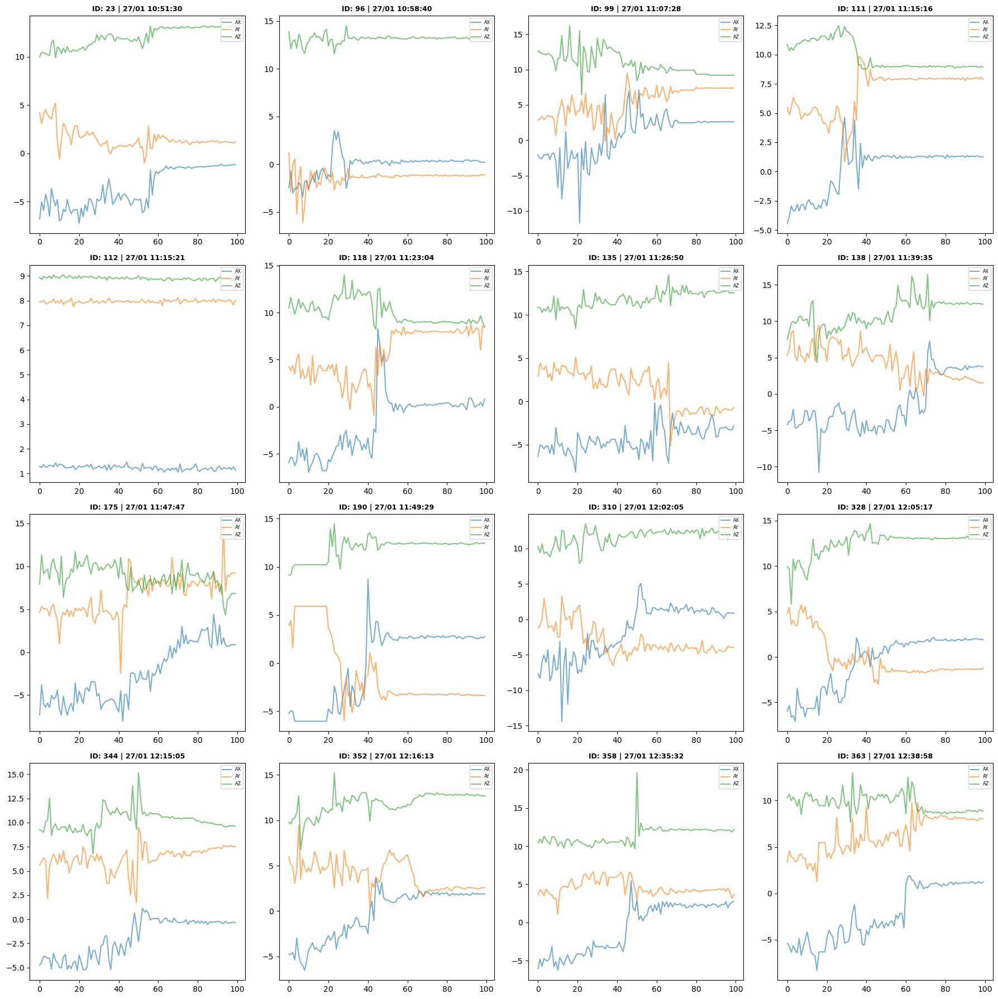

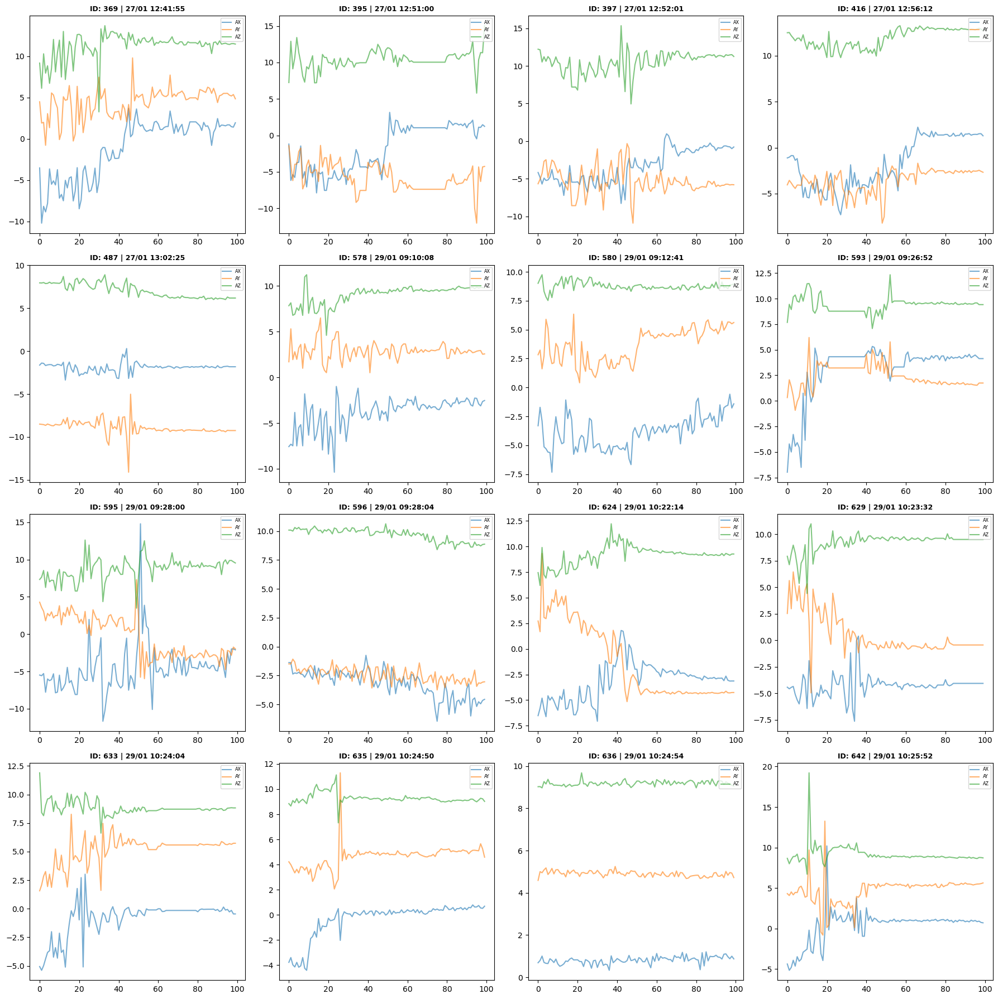

In [52]:
import matplotlib.pyplot as plt
from datetime import datetime
import math

def exibir_na_tela_todos(df_final, itens_por_pagina=16):
    # Filtra as 37 janelas
    df_deitando = df_final[df_final['atividade'] == 'deitando']
    ids_unicos = df_deitando['janela'].unique()
    
    total_paginas = math.ceil(len(ids_unicos) / itens_por_pagina)
    print(f"Total de janelas encontradas: {len(ids_unicos)}. Gerando {total_paginas} blocos...")

    for n in range(1, total_paginas + 1):
        start_idx = (n - 1) * itens_por_pagina
        subset_ids = ids_unicos[start_idx : start_idx + itens_por_pagina]
        
        # Cria a figura para o bloco atual
        fig, axes = plt.subplots(4, 4, figsize=(18, 18))
        axes = axes.flatten()
        
        for i, id_janela in enumerate(subset_ids):
            bloco = df_deitando[df_deitando['janela'] == id_janela]
            
            ts_segundos = (bloco['instante_tempo'].iloc[0] / 1000) + 10800
            data_hora = datetime.fromtimestamp(ts_segundos).strftime('%d/%m %H:%M:%S')
            
            axes[i].plot(bloco['AX'].values, label='AX', alpha=0.6)
            axes[i].plot(bloco['AY'].values, label='AY', alpha=0.6)
            axes[i].plot(bloco['AZ'].values, label='AZ', alpha=0.6)
            
            axes[i].set_title(f"ID: {id_janela} | {data_hora}", fontsize=9, fontweight='bold')
            axes[i].legend(fontsize='xx-small', loc='upper right')
        
        # Esconde os eixos que sobrarem (caso o último bloco tenha menos de 16)
        for i in range(len(subset_ids), 16):
            axes[i].axis('off')
            
        plt.tight_layout()
        plt.show() # Exibe o bloco na tela

# Chamada para rodar
exibir_na_tela_todos(df_final)

Total de janelas encontradas: 34. Gerando 3 blocos...


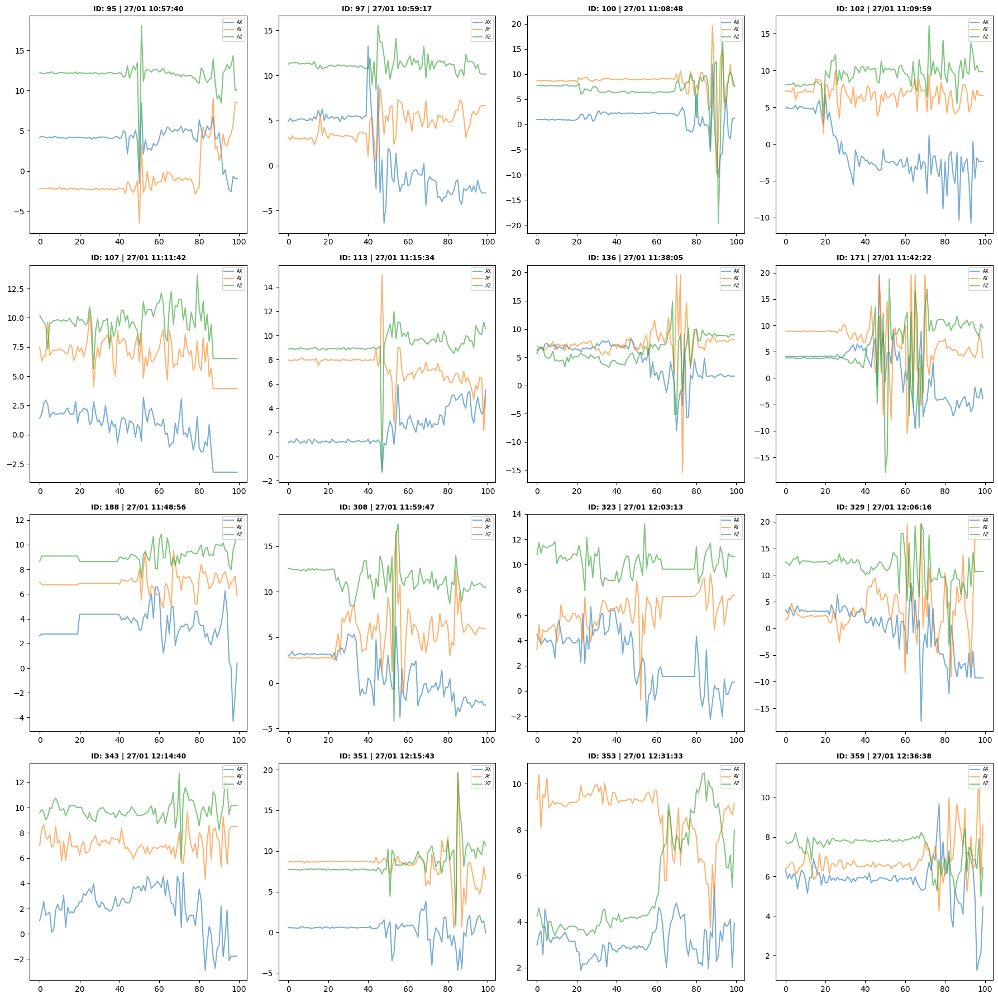

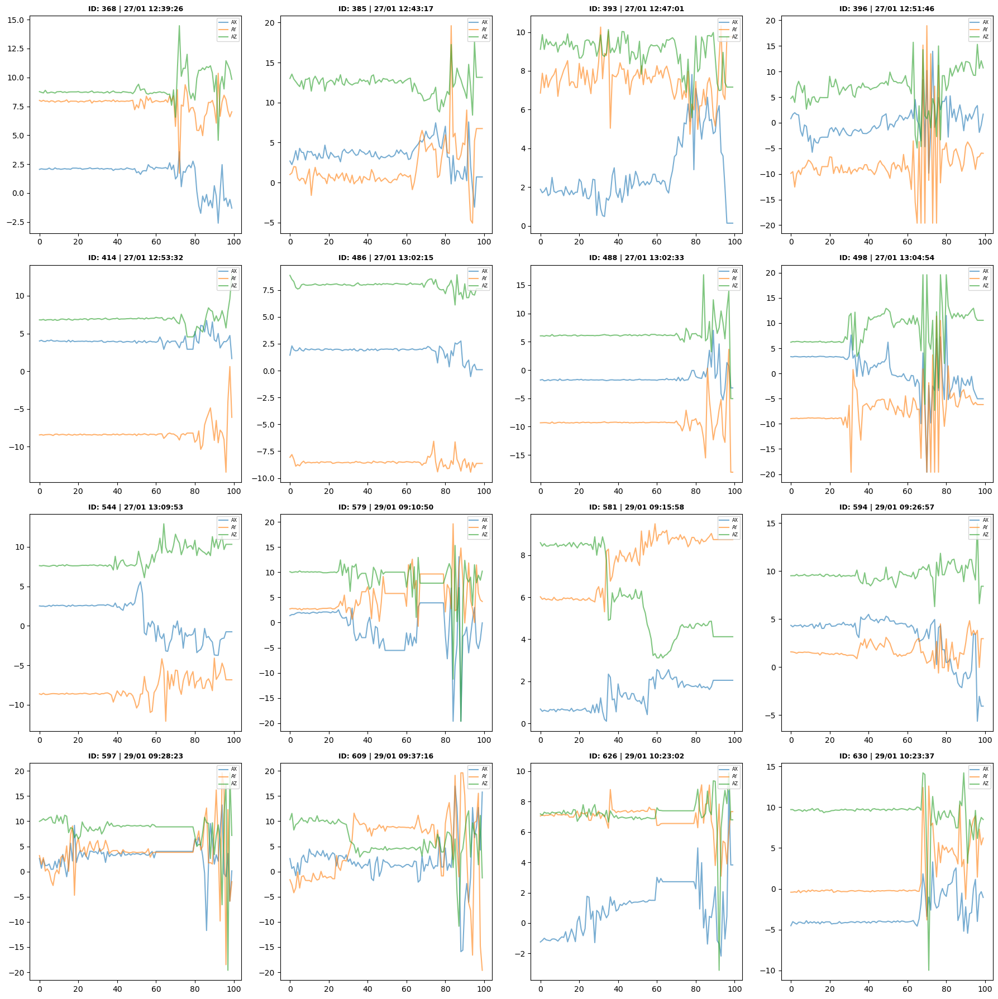

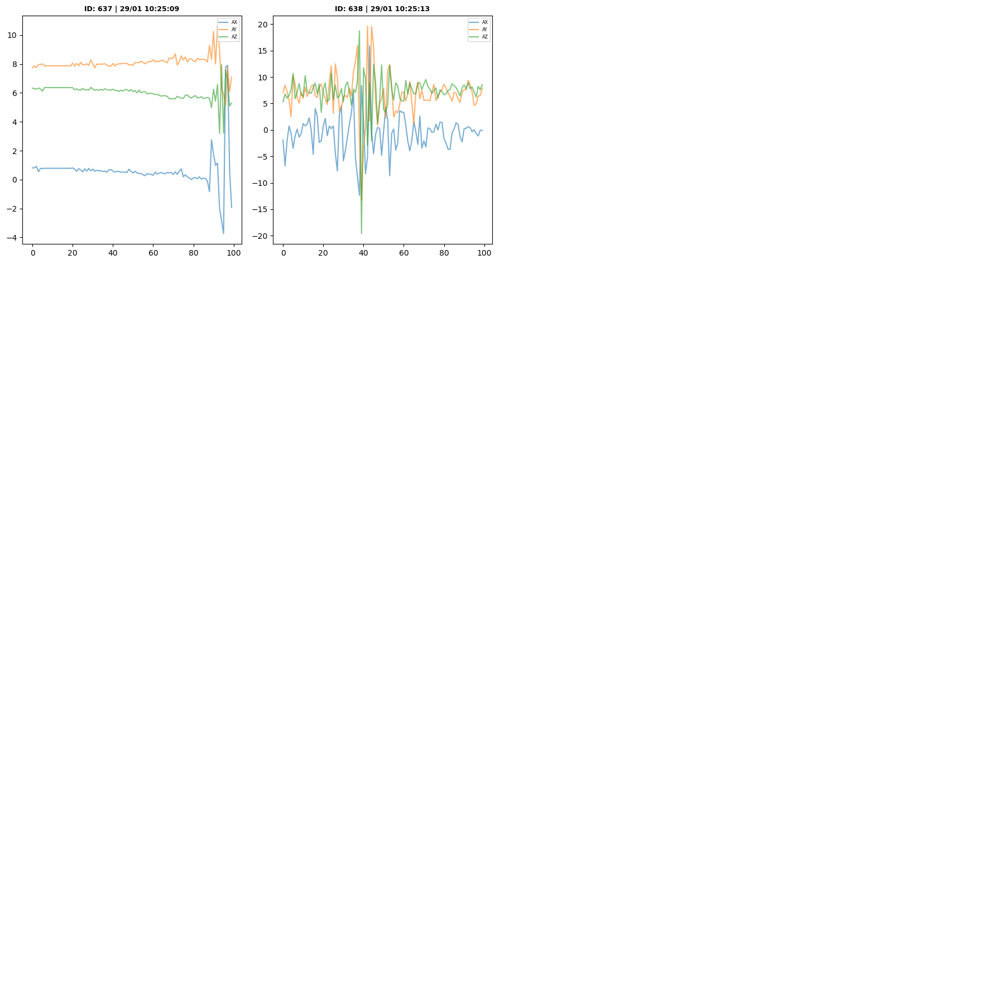

In [53]:
import matplotlib.pyplot as plt
from datetime import datetime
import math

def exibir_na_tela_todos(df_final, itens_por_pagina=16):
    # Filtra as 37 janelas
    df_deitando = df_final[df_final['atividade'] == 'levantando']
    ids_unicos = df_deitando['janela'].unique()
    
    total_paginas = math.ceil(len(ids_unicos) / itens_por_pagina)
    print(f"Total de janelas encontradas: {len(ids_unicos)}. Gerando {total_paginas} blocos...")

    for n in range(1, total_paginas + 1):
        start_idx = (n - 1) * itens_por_pagina
        subset_ids = ids_unicos[start_idx : start_idx + itens_por_pagina]
        
        # Cria a figura para o bloco atual
        fig, axes = plt.subplots(4, 4, figsize=(18, 18))
        axes = axes.flatten()
        
        for i, id_janela in enumerate(subset_ids):
            bloco = df_deitando[df_deitando['janela'] == id_janela]
            
            ts_segundos = (bloco['instante_tempo'].iloc[0] / 1000) + 10800
            data_hora = datetime.fromtimestamp(ts_segundos).strftime('%d/%m %H:%M:%S')
            
            axes[i].plot(bloco['AX'].values, label='AX', alpha=0.6)
            axes[i].plot(bloco['AY'].values, label='AY', alpha=0.6)
            axes[i].plot(bloco['AZ'].values, label='AZ', alpha=0.6)
            
            axes[i].set_title(f"ID: {id_janela} | {data_hora}", fontsize=9, fontweight='bold')
            axes[i].legend(fontsize='xx-small', loc='upper right')
        
        # Esconde os eixos que sobrarem (caso o último bloco tenha menos de 16)
        for i in range(len(subset_ids), 16):
            axes[i].axis('off')
            
        plt.tight_layout()
        plt.show() # Exibe o bloco na tela

# Chamada para rodar
exibir_na_tela_todos(df_final)

# Preparação para o treinamento

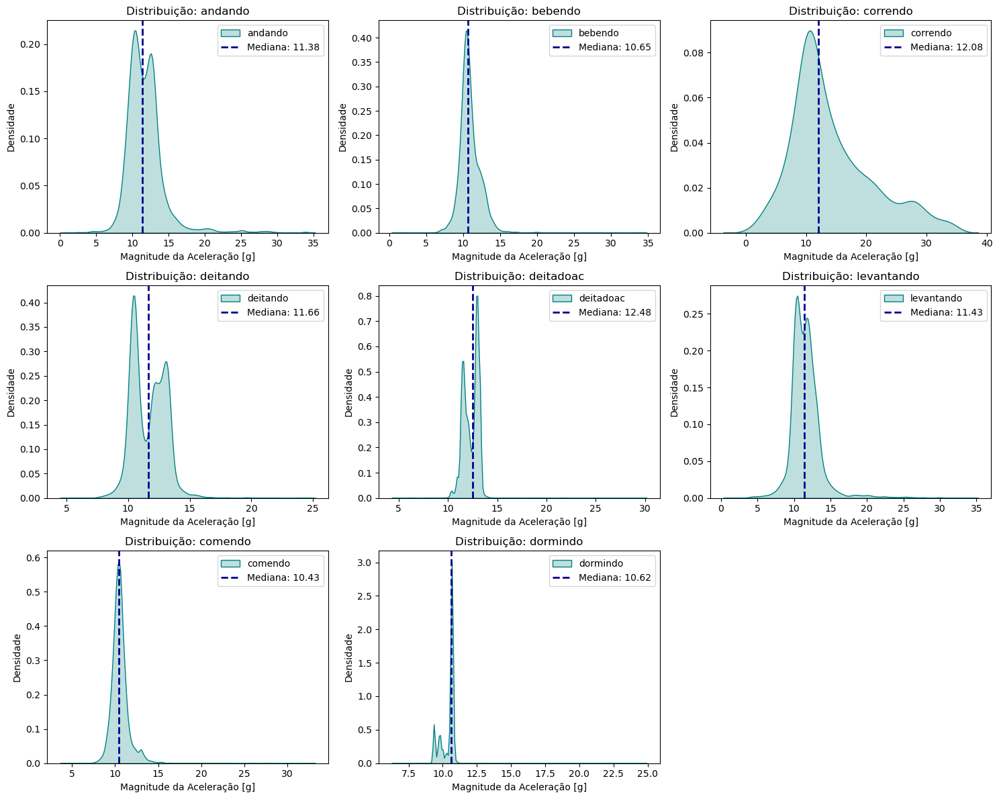

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Lista de atividades presentes no seu dataset
atividades = df_final['atividade'].unique()

# 2. Configura a grade (ajustando o tamanho conforme a quantidade de atividades)
n_atividades = len(atividades)
cols = 3
rows = int(np.ceil(n_atividades / cols))

fig, axes = plt.subplots(rows, cols, figsize=(15, rows * 4))
axes = axes.flatten()

# 3. Processamento
for i, activity in enumerate(atividades):
    # Filtra os dados da atividade
    subset = df_final[df_final['atividade'] == activity]
    
    # Calcula a Magnitude do Vetor (VM)
    vm = np.sqrt(subset['AX']**2 + subset['AY']**2 + subset['AZ']**2)
    
    # Calcula a mediana do VM
    median_vm = np.median(vm)

    # Plot KDE (Densidade)
    sns.kdeplot(vm, fill=True, label=activity, ax=axes[i], color='teal')
    axes[i].axvline(median_vm, color='darkblue', linestyle='dashed', linewidth=2, label=f'Mediana: {median_vm:.2f}')

    # Estilização
    axes[i].set_xlabel('Magnitude da Aceleração [g]')
    axes[i].set_ylabel('Densidade')
    axes[i].set_title(f'Distribuição: {activity}')
    axes[i].legend()

# Remove eixos vazios se houver
for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import skew, kurtosis
from scipy.signal import find_peaks

def extrair_features(grupo):
    # 1. Calculando a Magnitude do Vetor (VM)
    vm = np.sqrt(grupo['AX']**2 + grupo['AY']**2 + grupo['AZ']**2)
    
    # 2. Contagem de picos (usando limiar de altura)
    peaks, _ = find_peaks(vm, height=np.mean(vm))
    
    # Dicionário com as características extraídas
    features = {
        'mean': vm.mean(),
        'std': vm.std(),
        'min': vm.min(),
        'max': vm.max(),
        'max_min_diff': vm.max() - vm.min(),
        'median': np.median(vm),
        'peak_count': len(peaks),
        'skewness': skew(vm),
        'kurtosis': kurtosis(vm),
        'sma': np.sum(np.abs(vm)) / len(vm) # Signal Magnitude Area
    }
    return pd.Series(features)

# Aplicando para cada janela
# Agrupamos pelo ID da janela e aplicamos a função de extração
df_features = df_final.groupby('janela').apply(extrair_features).reset_index()

# Adicionamos a coluna da atividade de volta ao dataset de features
# (Pegamos a primeira atividade de cada janela, assumindo que elas são homogêneas)
atividades = df_final.groupby('janela')['atividade'].first()
df_features['atividade'] = atividades

print(df_features.head())

In [8]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df_features['atividade_code'] = le.fit_transform(df_features['atividade'])

# Salve o mapeamento para consultar depois
mapeamento = dict(zip(le.classes_, le.transform(le.classes_)))
print("Mapeamento das classes:", mapeamento)



Mapeamento das classes: {'andando': np.int64(0), 'bebendo': np.int64(1), 'comendo': np.int64(2), 'correndo': np.int64(3), 'deitadoac': np.int64(4), 'deitando': np.int64(5), 'dormindo': np.int64(6), 'levantando': np.int64(7)}


In [9]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Define as variáveis de entrada (X) e saída (y)
X = df_features.drop(['atividade', 'atividade_code'], axis=1)
y = df_features['atividade_code']

# Padroniza as colunas (média 0, desvio padrão 1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Divide em treino (80%) e teste (20%)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

Relatório de Classificação:

              precision    recall  f1-score   support

     andando       0.52      0.71      0.60        21
     bebendo       0.00      0.00      0.00        16
     comendo       0.65      0.84      0.73        49
    correndo       1.00      0.50      0.67         6
   deitadoac       0.88      0.95      0.92        86
    deitando       0.00      0.00      0.00         5
    dormindo       0.94      0.98      0.96       157
  levantando       0.33      0.07      0.11        15

    accuracy                           0.83       355
   macro avg       0.54      0.51      0.50       355
weighted avg       0.78      0.83      0.80       355



C:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


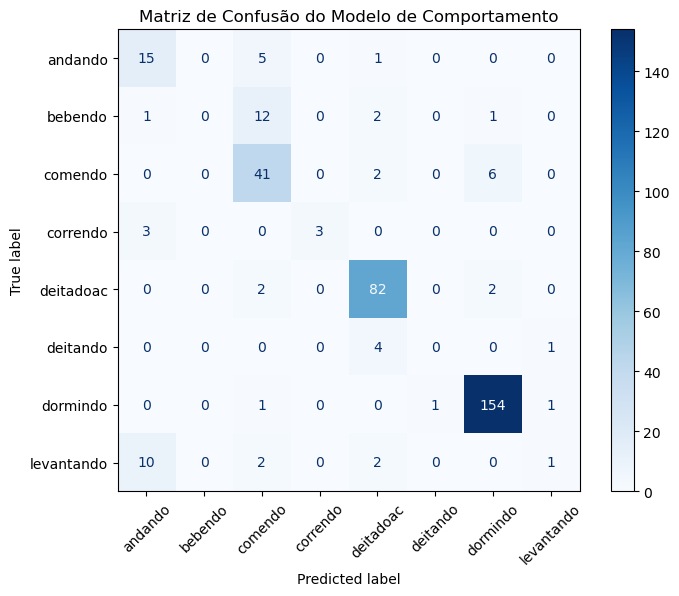

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# 1. Instanciar e treinar o modelo
model = LogisticRegression(max_iter=1000) # Aumentamos o iter para garantir convergência
model.fit(X_train, y_train)

# 2. Previsões
y_pred = model.predict(X_test)

# 3. Relatório de Desempenho
print("Relatório de Classificação:\n")
print(classification_report(y_test, y_pred, target_names=le.classes_))

# 4. Matriz de Confusão (Visualização essencial para o seu paper)
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)

fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(cmap=plt.cm.Blues, ax=ax, xticks_rotation=45)
plt.title('Matriz de Confusão do Modelo de Comportamento')
plt.show()

In [60]:
# Caracteristicas no dominio da frequencia

In [11]:
import pandas as pd
import numpy as np

def extrair_features_frequencia(grupo):
    # 1. Calcular a Magnitude do Vetor (VM)
    vm = np.sqrt(grupo['AX']**2 + grupo['AY']**2 + grupo['AZ']**2)
    
    # 2. Calcular a FFT e pegar o módulo (amplitude)
    # n=len(vm) garante a transformação correta
    fft_vals = np.abs(np.fft.rfft(vm - np.mean(vm))) 
    N = len(fft_vals)
    mu = np.mean(fft_vals)
    
    # Ordenar para quartis e mediana
    sorted_f = np.sort(fft_vals)
    
    # Cálculos
    features = {
        'AV': np.mean(fft_vals),
        'DC_value': fft_vals[0],
        'SD': np.std(fft_vals, ddof=1),
        'MIN': np.min(fft_vals),
        'MAX': np.max(fft_vals),
        'RG': np.max(fft_vals) - mu,
        'FQ': sorted_f[int((N + 1) / 4)],
        'SQ': sorted_f[int((N + 1) / 2)],
        'RMS': np.sqrt(np.mean(fft_vals**2)),
        'Median': np.median(fft_vals)
    }
    return pd.Series(features)

# Aplicar ao dataset (já agrupado por janela)
df_freq = df_final.groupby('janela').apply(extrair_features_frequencia, include_groups=False)
print(df_freq.head())

               AV      DC_value         SD           MIN        MAX  \
janela                                                                
1       23.933199  7.283063e-14  11.524324  7.283063e-14  49.187043   
2       13.823067  1.385558e-13   6.838029  1.385558e-13  26.326627   
3       16.809945  7.105427e-14  12.019257  7.105427e-14  55.571554   
4       15.419805  8.348877e-14   7.669168  8.348877e-14  31.768079   
5       24.720253  1.563194e-13  15.519759  1.563194e-13  79.564546   

               RG         FQ         SQ        RMS     Median  
janela                                                         
1       25.253843  18.964422  25.422047  26.514222  25.188614  
2       12.503560   9.326243  13.826965  15.392173  13.714969  
3       38.761608   9.299614  13.319779  20.596219  12.860808  
4       16.348274   9.541342  16.144006  17.188172  15.125329  
5       54.844293  13.602868  24.955726  29.107233  24.914321  


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_clas

              precision    recall  f1-score   support

     andando       0.59      0.81      0.69        27
     bebendo       0.00      0.00      0.00        17
     comendo       0.68      0.87      0.76        54
    correndo       1.00      0.50      0.67         6
   deitadoac       0.88      0.93      0.90       109
    deitando       0.00      0.00      0.00         6
    dormindo       0.96      1.00      0.98       207
  levantando       0.20      0.06      0.09        17

    accuracy                           0.86       443
   macro avg       0.54      0.52      0.51       443
weighted avg       0.81      0.86      0.83       443



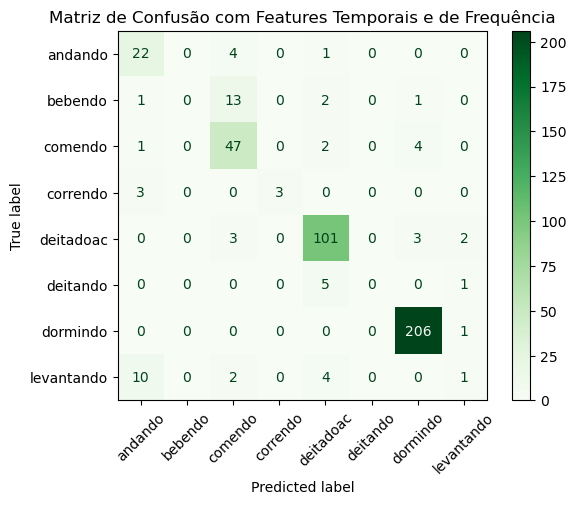

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, confusion_matrix
import matplotlib.pyplot as plt

# 1. Unir os dois DataFrames (Certifique-se que o índice 'janela' é o mesmo em ambos)
df_super_features = pd.concat([df_features.drop('atividade', axis=1), df_freq], axis=1)

# 2. Reintegrar a atividade e transformar em código numérico
df_super_features['atividade'] = df_features['atividade']
le = LabelEncoder()
df_super_features['atividade_code'] = le.fit_transform(df_super_features['atividade'])

# 3. Preparar X e y
X = df_super_features.drop(['atividade', 'atividade_code'], axis=1)
y = df_super_features['atividade_code']

# 4. Padronização Obrigatória (ESSENCIAL para modelos baseados em gradiente)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 5. Split Treino/Teste
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.25, random_state=42)

# 6. Treinar com Regularização (L2 é o padrão para evitar overfitting)
model = LogisticRegression(max_iter=2000, multi_class='multinomial')
model.fit(X_train, y_train)

# 7. Avaliação
y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred, target_names=le.classes_))

# Plot da Matriz de Confusão
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
disp.plot(cmap=plt.cm.Greens, xticks_rotation=45)
plt.title('Matriz de Confusão com Features Temporais e de Frequência')
plt.show()

In [14]:
import pandas as pd
import numpy as np
from scipy.stats import skew, kurtosis
from scipy.signal import find_peaks

def extrair_features_completas(grupo):
    # 1. Preparação (Magnitude e FFT)
    vm = np.sqrt(grupo['AX']**2 + grupo['AY']**2 + grupo['AZ']**2)
    fft_vals = np.abs(np.fft.rfft(vm - np.mean(vm)))
    sorted_f = np.sort(fft_vals)
    N_fft = len(fft_vals)
    
    # 2. Correlação Cruzada (Defasagem entre eixos)
    # Mede a relação dinâmica entre X, Y e Z
    corr_xy = np.max(np.correlate(grupo['AX'], grupo['AY'], mode='full'))
    corr_xz = np.max(np.correlate(grupo['AX'], grupo['AZ'], mode='full'))
    
    # 3. Dicionário consolidado
    features = {
        # Domínio do Tempo
        'mean': vm.mean(), 'std': vm.std(), 'min': vm.min(), 'max': vm.max(),
        'max_min_diff': vm.max() - vm.min(), 'median': np.median(vm),
        'peak_count': len(find_peaks(vm, height=np.mean(vm))[0]),
        'skewness': skew(vm), 'kurtosis': kurtosis(vm), 'sma': np.sum(np.abs(vm)) / len(vm),
        # Domínio da Frequência
        'AV': np.mean(fft_vals), 'DC': fft_vals[0], 'SD_f': np.std(fft_vals),
        'MIN_f': np.min(fft_vals), 'MAX_f': np.max(fft_vals),
        'RG_f': np.max(fft_vals) - np.mean(fft_vals),
        'FQ': sorted_f[int(N_fft/4)], 'SQ': sorted_f[int(N_fft/2)],
        'RMS_f': np.sqrt(np.mean(fft_vals**2)), 'Median_f': np.median(fft_vals),
        # Dinâmica entre eixos
        'max_corr_xy': corr_xy, 'max_corr_xz': corr_xz
    }
    return pd.Series(features)

# Aplicação unificada
df_features = df_final.groupby('janela').apply(extrair_features_completas, include_groups=False)
df_features['atividade'] = df_final.groupby('janela')['atividade'].first()

print(f"Features extraídas com sucesso! Total de colunas: {df_features.shape[1]}")
print(df_features.head())

Features extraídas com sucesso! Total de colunas: 23
             mean       std        min        max  max_min_diff     median  \
janela                                                                       
1       13.545966  2.682460   8.934936  30.342653     21.407716  12.989732   
2       12.994457  1.548667   8.308177  20.105347     11.797169  12.949863   
3       13.484504  2.089616  10.071121  24.122828     14.051707  12.906397   
4       12.636553  1.732319   5.988707  17.481813     11.493106  12.406962   
5       13.418125  2.952005   2.940358  23.450052     20.509693  13.249201   

        peak_count  skewness   kurtosis        sma  ...         MIN_f  \
janela                                              ...                 
1             19.0  3.763470  18.983735  13.545966  ...  7.283063e-14   
2             24.0  1.681273   7.072869  12.994457  ...  1.385558e-13   
3             17.0  2.500779   8.230616  13.484504  ...  7.105427e-14   
4             21.0  0.167620   2.49

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Relatório de Classificação (Consolidado):

              precision    recall  f1-score   support

     andando       0.84      0.87      0.85        30
     bebendo       0.81      0.85      0.83        20
     comendo       0.90      0.94      0.92        50
    correndo       0.80      1.00      0.89         4
   deitadoac       0.97      0.88      0.92       107
    deitando       0.19      0.30      0.23        10
    dormindo       0.99      0.97      0.98       211
  levantando       0.29      0.36      0.32        11

    accuracy                           0.90       443
   macro avg       0.72      0.77      0.74       443
weighted avg       0.92      0.90      0.91       443



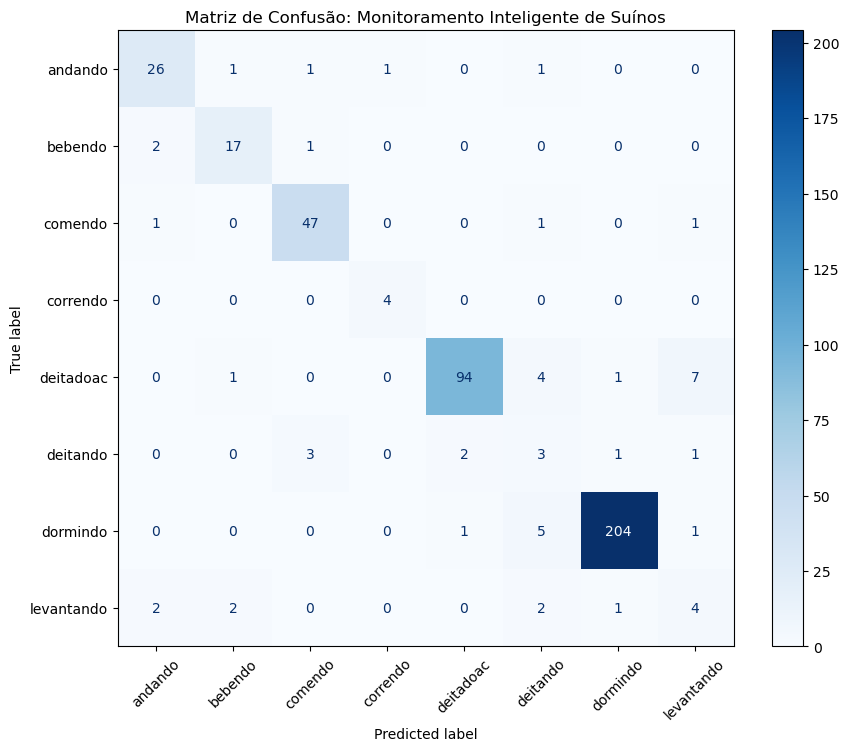

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, confusion_matrix
import matplotlib.pyplot as plt

# 1. Preparação dos dados
X = df_features.drop('atividade', axis=1)
y = df_features['atividade']

# 2. Codificação numérica
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# 3. Divisão Treino/Teste com ESTRATIFICAÇÃO
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, 
    test_size=0.25, 
    random_state=42, 
    stratify=y_encoded  
)

# 4. PADRONIZAÇÃO (Essencial para a Regressão Logística funcionar com SAGA)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5. Treinamento com Peso Balanceado
model = LogisticRegression(
    solver='saga', 
    max_iter=10000, 
    multi_class='multinomial', 
    class_weight='balanced' # Dá peso justo para 'Bebendo' e 'Levantando'
)
model.fit(X_train_scaled, y_train)

# 6. Avaliação
y_pred = model.predict(X_test_scaled)

print("Relatório de Classificação (Consolidado):\n")
print(classification_report(y_test, y_pred, target_names=le.classes_))

# 7. Matriz de Confusão
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(10, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
disp.plot(cmap=plt.cm.Blues, ax=ax, xticks_rotation=45)
plt.title('Matriz de Confusão: Monitoramento Inteligente de Suínos')
plt.show()

## Feature Extraction Methodology

Feature extraction was performed from the Acceleration Vector Magnitude ($VM$), which combines the information from the Cartesian axes ($AX$, $AY$, $AZ$), minimizing the influence of sensor orientation. The features were divided into three domains: time domain, frequency domain, and inter-axis dynamics.

### 1. Time Domain

Time-domain statistics describe the intensity and distribution of movement energy within each observation window.

**Vector Magnitude (VM):**

$$
VM_i = \sqrt{AX_i^2 + AY_i^2 + AZ_i^2}
$$

**Mean ($\mu$):** Represents the average acceleration level.

**Standard Deviation ($\sigma$):** Measures signal dispersion, indicating the variability of the activity.

**Skewness ($S$):** Quantifies the asymmetry of the data distribution around the mean.

**Kurtosis ($K$):** Measures the degree of peakedness or flatness of the distribution and is important for detecting sudden peaks and transient impacts:

$$
K = \frac{\frac{1}{n} \sum_{i=1}^{n} (x_i - \mu)^4}{\left(\frac{1}{n} \sum_{i=1}^{n} (x_i - \mu)^2\right)^2}
$$

**Signal Magnitude Area (SMA):** Indicator of the energetic demand of the activity:

$$
SMA = \frac{1}{n} \sum_{i=1}^{n} |x_i|
$$

### 2. Frequency Domain

To identify rhythmic patterns, such as chewing and sucking cadence, the Fast Fourier Transform (FFT) was used. The signal was mean-centered to remove the DC component before transformation.

**FFT Amplitude Values ($F[k]$):** Obtained through the Fourier Transform:

$$
F[k] = \sum_{n=0}^{N-1} x[n] \cdot e^{-j2\pi kn/N}
$$

**Coefficient Average (AV):**

$$
AV = \frac{1}{N} \sum_{k=1}^{N} |F[k]|
$$

**Root Mean Square (RMS):** Quantifies the average power of the frequency spectrum:

$$
RMS = \sqrt{\frac{1}{N} \sum_{k=1}^{N} |F[k]|^2}
$$

**Quartiles (FQ, SQ) and Median:** Define the shape of the spectrum and the concentration of energy in specific frequency bands.

### 3. Inter-Axis Dynamics: Cross-Correlation

To capture the biomechanical signature of movement, the Maximum Cross-Correlation was calculated. This metric identifies the time lag and degree of rhythmic synchrony between different planes of motion, such as vertical versus lateral movement.

The cross-correlation between two signals $x$ and $y$ is given by:

$$
(x \star y)[n] = \sum_{m=-\infty}^{\infty} x[m] \cdot y[m+n]
$$

The **Max Corr XY** feature extracted for the model is the maximum value of the correlation sequence:

$$
\text{Max\_Corr}_{xy} = \max \{(x \star y)[n]\}
$$

This metric allows the classifier to differentiate activities with similar magnitudes but distinct motor coordination patterns, such as **eating** versus **drinking**, based on the temporal interdependence between axes.

The inclusion of frequency and correlation features allows Logistic Regression to operate as a multivariate pattern detector. While time-domain metrics capture the “strength” of the movement, FFT captures the “rhythm”, and cross-correlation captures the “shape” of spatial displacement, providing a linearly separable and highly discriminative dataset.

# data analysis

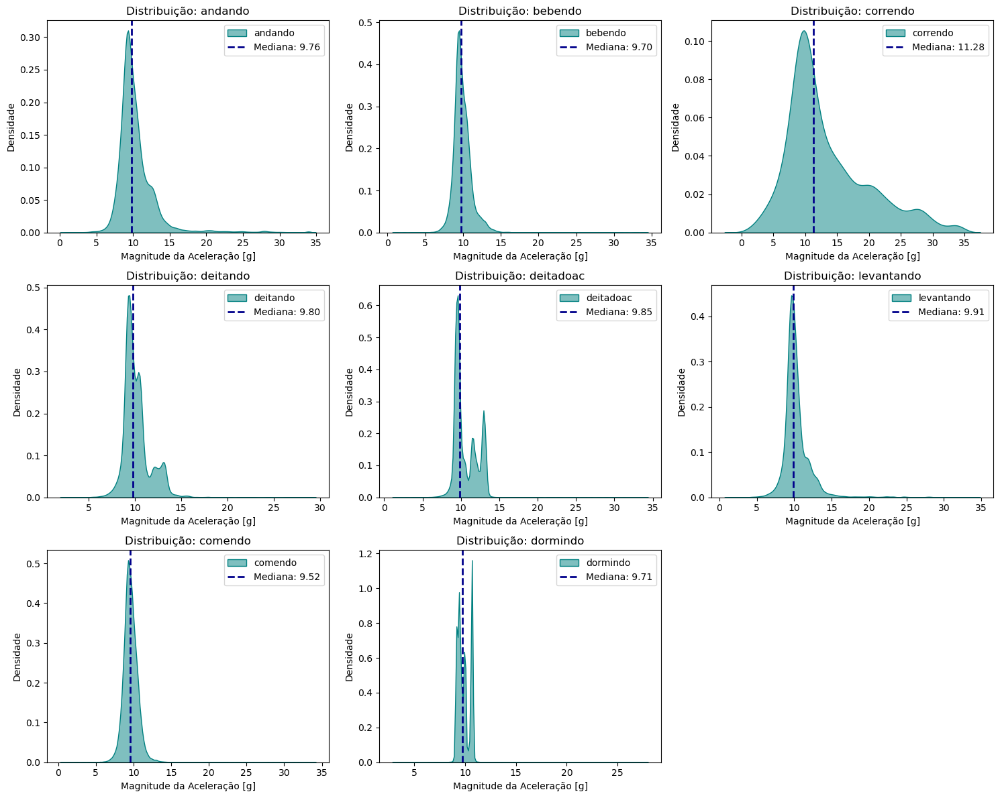

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# --- 1. CARREGAMENTO DO DATASET (O QUE ESTAVA FALTANDO) ---
caminho_arquivo = r'C:\Users\franc\OneDrive\Desktop\dataset_treinamento_suinos.xlsx'
df_final = pd.read_excel(caminho_arquivo)

# 2. Lista de atividades presentes no seu dataset
atividades = df_final['atividade'].unique()

# 3. Configura a grade dinamicamente
n_atividades = len(atividades)
cols = 3
rows = int(np.ceil(n_atividades / cols))

fig, axes = plt.subplots(rows, cols, figsize=(15, rows * 4))
axes = axes.flatten()

# 4. Processamento e Plotagem
for i, activity in enumerate(atividades):
    # Filtra os dados da atividade
    subset = df_final[df_final['atividade'] == activity]
    
    # Calcula a Magnitude do Vetor (VM)
    # Importante: usamos os dados brutos AX, AY, AZ do arquivo
    vm = np.sqrt(subset['AX']**2 + subset['AY']**2 + subset['AZ']**2)
    
    # Calcula a mediana
    median_vm = np.median(vm)

    # Plot KDE (Densidade)
    sns.kdeplot(vm, fill=True, label=activity, ax=axes[i], color='teal', alpha=0.5)
    axes[i].axvline(median_vm, color='darkblue', linestyle='dashed', linewidth=2, 
                    label=f'Mediana: {median_vm:.2f}')

    # Estilização
    axes[i].set_xlabel('Magnitude da Aceleração [g]')
    axes[i].set_ylabel('Densidade')
    axes[i].set_title(f'Distribuição: {activity}')
    axes[i].legend()

# Remove eixos vazios
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

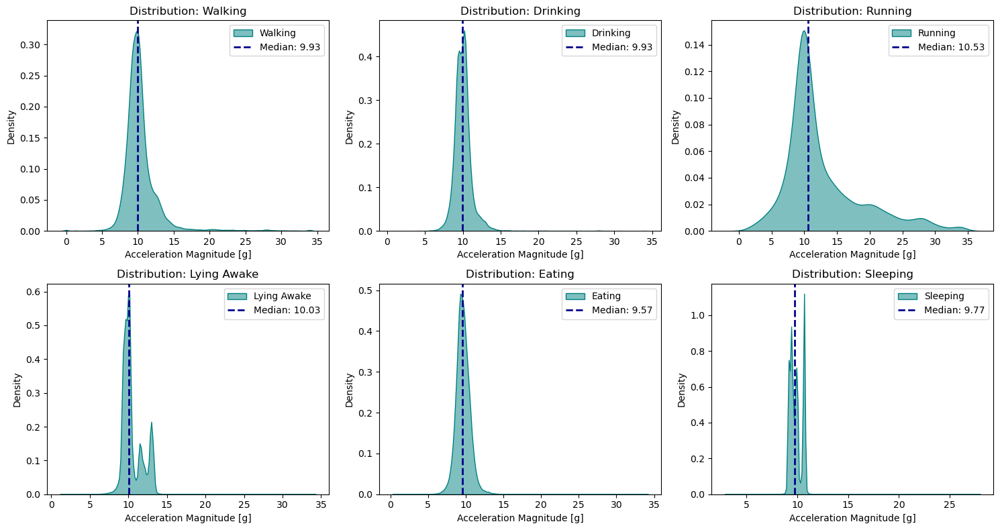

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# --- 1. DATASET LOADING ---
caminho_arquivo = r'C:\Users\franc\OneDrive\Desktop\dataset_treinamento_suinos.xlsx'
df_final = pd.read_excel(caminho_arquivo)

# Dictionary for translation - Updated with 'bebendo'
class_translation = {
    'andando': 'Walking',
    'correndo': 'Running',
    'comendo': 'Eating',
    'bebendo': 'Drinking',
    'dormindo': 'Sleeping',
    'deitadoac': 'Lying Awake'
}

# --- 2. FILTERING AND CLEANING ---
# Normalize text
df_final['atividade'] = df_final['atividade'].astype(str).str.strip().str.lower()

# Remove 'levantando' and 'deitando'
excluded = ['levantando', 'deitando']
df_filtered = df_final[~df_final['atividade'].isin(excluded)].copy()

# Get unique filtered activities
atividades = df_filtered['atividade'].unique()

# --- 3. DYNAMIC GRID SETUP ---
n_atividades = len(atividades)
cols = 3
rows = int(np.ceil(n_atividades / cols))

fig, axes = plt.subplots(rows, cols, figsize=(15, rows * 4))
axes = axes.flatten()

# --- 4. PROCESSING AND PLOTTING ---
for i, activity in enumerate(atividades):
    # Filter activity data
    subset = df_filtered[df_filtered['atividade'] == activity]
    
    # Calculate Vector Magnitude (VM)
    vm = np.sqrt(subset['AX']**2 + subset['AY']**2 + subset['AZ']**2)
    
    # Calculate median
    median_vm = np.median(vm)

    # Translate activity name for the title/legend
    activity_en = class_translation.get(activity, activity.capitalize())

    # Plot KDE (Density)
    sns.kdeplot(vm, fill=True, label=activity_en, ax=axes[i], color='teal', alpha=0.5)
    axes[i].axvline(median_vm, color='darkblue', linestyle='dashed', linewidth=2, 
                    label=f'Median: {median_vm:.2f}')

    # Styling in English
    axes[i].set_xlabel('Acceleration Magnitude [g]')
    axes[i].set_ylabel('Density')
    axes[i].set_title(f'Distribution: {activity_en}')
    axes[i].legend()

# Remove empty axes
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

Number of rows per final class:
behavioral_class
Lying       397400
Eating      267700
Walking      78300
Drinking     45800
Name: count, dtype: int64

Number of windows per final class:
behavioral_class
Lying       3974
Eating      2677
Walking      783
Drinking     458
Name: janela, dtype: int64


C:\Users\franc\AppData\Local\Temp\ipykernel_32540\2661251421.py:85: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: pd.Series({



Max correlation dataset:
   janela behavioral_class  max_corr_xy  max_corr_xy_norm
0       1          Walking   506.811069          0.365834
1       2          Walking   119.617075          0.299165
2       3          Walking   324.395743          0.275195
3       4          Walking   144.263447          0.296439
4       5          Walking   318.903441          0.251222

Number of windows per class:
behavioral_class
Lying       3974
Eating      2677
Walking      783
Drinking     458
Name: count, dtype: int64

Median max_corr_xy per class:
behavioral_class
Lying         0.181980
Eating       22.030906
Walking     111.180522
Drinking     38.182792
Name: max_corr_xy, dtype: float64

Median normalized max_corr_xy per class:
behavioral_class
Lying       0.262916
Eating      0.273463
Walking     0.278621
Drinking    0.295436
Name: max_corr_xy_norm, dtype: float64


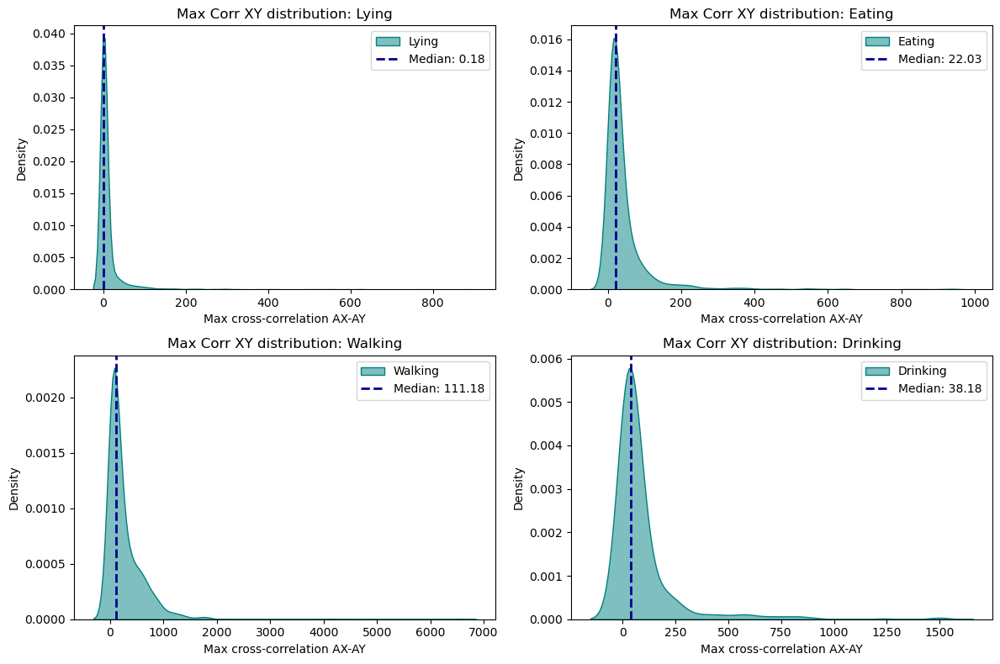

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# ============================================================
# 1. DATASET LOADING
# ============================================================
caminho_arquivo = r'C:\Users\franc\OneDrive\Desktop\dataset_treinamento_suinos.xlsx'
df_final = pd.read_excel(caminho_arquivo)

# ============================================================
# 2. FILTERING AND CLASS MAPPING
# ============================================================

df_final['atividade'] = (
    df_final['atividade']
    .astype(str)
    .str.strip()
    .str.lower()
)

# Final classes used in the experiment
class_mapping = {
    'andando': 'Walking',
    'comendo': 'Eating',
    'bebendo': 'Drinking',
    'dormindo': 'Lying',
    'deitadoac': 'Lying'
}

df_final['behavioral_class'] = df_final['atividade'].map(class_mapping)

# Remove unused classes: correndo, levantando, deitando, etc.
df_filtered = df_final.dropna(subset=['behavioral_class']).copy()

class_order = ['Lying', 'Eating', 'Walking', 'Drinking']

print("Number of rows per final class:")
print(df_filtered['behavioral_class'].value_counts().reindex(class_order))

print("\nNumber of windows per final class:")
print(df_filtered.groupby('behavioral_class')['janela'].nunique().reindex(class_order))

# ============================================================
# 3. MAX CROSS-CORRELATION FUNCTION X-Y
# ============================================================

def max_corr_xy(group, normalize=False):
    """
    Computes the maximum cross-correlation between AX and AY within one window.

    If normalize=False:
        returns the raw maximum cross-correlation, matching the definition:
        max_k sum_m AX[m] * AY[m+k]

    If normalize=True:
        returns normalized cross-correlation, less dependent on signal amplitude.
    """

    x = group['AX'].values
    y = group['AY'].values

    # Remove mean to focus on temporal co-variation
    x = x - np.mean(x)
    y = y - np.mean(y)

    corr = np.correlate(x, y, mode='full')

    if normalize:
        denom = np.sqrt(np.sum(x**2) * np.sum(y**2))
        if denom > 0:
            corr = corr / denom

    return np.max(corr)

# ============================================================
# 4. COMPUTE MAX_CORR_XY PER WINDOW
# ============================================================

df_corr = (
    df_filtered
    .groupby('janela')
    .apply(lambda g: pd.Series({
        'behavioral_class': g['behavioral_class'].iloc[0],
        'max_corr_xy': max_corr_xy(g, normalize=False),
        'max_corr_xy_norm': max_corr_xy(g, normalize=True)
    }))
    .reset_index()
)

print("\nMax correlation dataset:")
print(df_corr.head())

print("\nNumber of windows per class:")
print(df_corr['behavioral_class'].value_counts().reindex(class_order))

print("\nMedian max_corr_xy per class:")
print(df_corr.groupby('behavioral_class')['max_corr_xy'].median().reindex(class_order))

print("\nMedian normalized max_corr_xy per class:")
print(df_corr.groupby('behavioral_class')['max_corr_xy_norm'].median().reindex(class_order))

# ============================================================
# 5. PLOT RAW MAX_CORR_XY DISTRIBUTIONS
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for i, activity in enumerate(class_order):

    subset = df_corr[df_corr['behavioral_class'] == activity]
    values = subset['max_corr_xy'].dropna()

    median_value = np.median(values)

    sns.kdeplot(
        values,
        fill=True,
        label=activity,
        ax=axes[i],
        color='teal',
        alpha=0.5
    )

    axes[i].axvline(
        median_value,
        color='darkblue',
        linestyle='dashed',
        linewidth=2,
        label=f'Median: {median_value:.2f}'
    )

    axes[i].set_xlabel('Max cross-correlation AX-AY')
    axes[i].set_ylabel('Density')
    axes[i].set_title(f'Max Corr XY distribution: {activity}')
    axes[i].legend()

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# --- 1. CARREGAMENTO DO DATASET (O QUE ESTAVA FALTANDO) ---
caminho_arquivo = r'C:\Users\franc\OneDrive\Desktop\dataset_treinamento_suinos.xlsx'
df_final = pd.read_excel(caminho_arquivo)

# 2. Lista de atividades presentes no seu dataset
atividades = df_final['atividade'].unique()

# 3. Configura a grade dinamicamente
n_atividades = len(atividades)
cols = 3
rows = int(np.ceil(n_atividades / cols))

fig, axes = plt.subplots(rows, cols, figsize=(15, rows * 4))
axes = axes.flatten()

# 4. Processamento e Plotagem
for i, activity in enumerate(atividades):
    # Filtra os dados da atividade
    subset = df_final[df_final['atividade'] == activity]
    
    # Calcula a Magnitude do Vetor (VM)
    # Importante: usamos os dados brutos AX, AY, AZ do arquivo
    vm = np.sqrt(subset['AX']**2 + subset['AY']**2 + subset['AZ']**2)
    
    # Calcula a mediana
    median_vm = np.median(vm)

    # Plot KDE (Densidade)
    sns.kdeplot(vm, fill=True, label=activity, ax=axes[i], color='teal', alpha=0.5)
    axes[i].axvline(median_vm, color='darkblue', linestyle='dashed', linewidth=2, 
                    label=f'Mediana: {median_vm:.2f}')

    # Estilização
    axes[i].set_xlabel('Magnitude da Aceleração [g]')
    axes[i].set_ylabel('Densidade')
    axes[i].set_title(f'Distribuição: {activity}')
    axes[i].legend()

# Remove eixos vazios
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [28]:
import pandas as pd
import numpy as np
from scipy.stats import skew, kurtosis
from scipy.signal import find_peaks

def extrair_features(grupo):
    # 1. Calculando a Magnitude do Vetor (VM)
    vm = np.sqrt(grupo['AX']**2 + grupo['AY']**2 + grupo['AZ']**2)
    
    # 2. Contagem de picos (usando limiar de altura)
    peaks, _ = find_peaks(vm, height=np.mean(vm))
    
    # Dicionário com as características extraídas
    features = {
        'mean': vm.mean(),
        'std': vm.std(),
        'min': vm.min(),
        'max': vm.max(),
        'max_min_diff': vm.max() - vm.min(),
        'median': np.median(vm),
        'peak_count': len(peaks),
        'skewness': skew(vm),
        'kurtosis': kurtosis(vm),
        'sma': np.sum(np.abs(vm)) / len(vm) # Signal Magnitude Area
    }
    return pd.Series(features)

# Aplicando para cada janela
# Agrupamos pelo ID da janela e aplicamos a função de extração
df_features = df_final.groupby('janela').apply(extrair_features)

# Adicionamos a coluna da atividade de volta ao dataset de features
# (Pegamos a primeira atividade de cada janela, assumindo que elas são homogêneas)
atividades = df_final.groupby('janela')['atividade'].first()
df_features['atividade'] = atividades

print(df_features.head())

             mean       std        min        max  max_min_diff     median  \
janela                                                                       
1       13.545966  2.682460   8.934936  30.342653     21.407716  12.989732   
2       12.994457  1.548667   8.308177  20.105347     11.797169  12.949863   
3       13.484504  2.089616  10.071121  24.122828     14.051707  12.906397   
4       12.636553  1.732319   5.988707  17.481813     11.493106  12.406962   
5       13.418125  2.952005   2.940358  23.450052     20.509693  13.249201   

        peak_count  skewness   kurtosis        sma atividade  
janela                                                        
1             19.0  3.763470  18.983735  13.545966   andando  
2             24.0  1.681273   7.072869  12.994457   andando  
3             17.0  2.500779   8.230616  13.484504   andando  
4             21.0  0.167620   2.497096  12.636553   andando  
5             25.0 -0.052244   2.533199  13.418125   andando  


C:\Users\franc\AppData\Local\Temp\ipykernel_25944\3671453982.py:30: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_features = df_final.groupby('janela').apply(extrair_features)


In [29]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df_features['atividade_code'] = le.fit_transform(df_features['atividade'])

# Salve o mapeamento para consultar depois
mapeamento = dict(zip(le.classes_, le.transform(le.classes_)))
print("Mapeamento das classes:", mapeamento)



Mapeamento das classes: {'andando': np.int64(0), 'bebendo': np.int64(1), 'comendo': np.int64(2), 'correndo': np.int64(3), 'deitadoac': np.int64(4), 'deitando': np.int64(5), 'dormindo': np.int64(6), 'levantando': np.int64(7)}


In [30]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Define as variáveis de entrada (X) e saída (y)
X = df_features.drop(['atividade', 'atividade_code'], axis=1)
y = df_features['atividade_code']

# Padroniza as colunas (média 0, desvio padrão 1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Divide em treino (80%) e teste (20%)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

In [31]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. DEFINE AS VARIÁVEIS (MANTÉM IGUAL)
# Aqui separamos o que é entrada (X) e o que é o rótulo (y)
X = df_features.drop(['atividade', 'atividade_code'], axis=1)
y = df_features['atividade_code']

# 2. DIVIDE PRIMEIRO (MUDANÇA DE ORDEM)
# Dividimos os dados brutos. O random_state=42 garante que a divisão seja sempre a mesma.
X_train_raw, X_test_raw, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. ESCALONA DEPOIS (O SEGREDO DA ACURÁCIA REAL)
scaler = StandardScaler()

# O scaler "aprende" a média e o desvio padrão APENAS com o treino
X_train = scaler.fit_transform(X_train_raw)

# O scaler apenas "aplica" o que aprendeu no teste (sem olhar os dados de teste para calcular média)
X_test = scaler.transform(X_test_raw)

print(f"Treinamento pronto com {X_train.shape[0]} janelas e teste com {X_test.shape[0]} janelas.")

Treinamento pronto com 5672 janelas e teste com 1418 janelas.


Dataset original: 5992 janelas
Dataset após limpeza: 5992 janelas

Relatório de Classificação:

              precision    recall  f1-score   support

     andando       1.00      1.00      1.00        84
     bebendo       0.85      1.00      0.92        64
     comendo       1.00      0.97      0.99       464
    correndo       0.75      1.00      0.86        12
   deitadoac       1.00      0.96      0.98       278
    deitando       0.61      0.93      0.74        29
    dormindo       1.00      0.99      0.99       525
  levantando       1.00      1.00      1.00        42

    accuracy                           0.98      1498
   macro avg       0.90      0.98      0.93      1498
weighted avg       0.98      0.98      0.98      1498



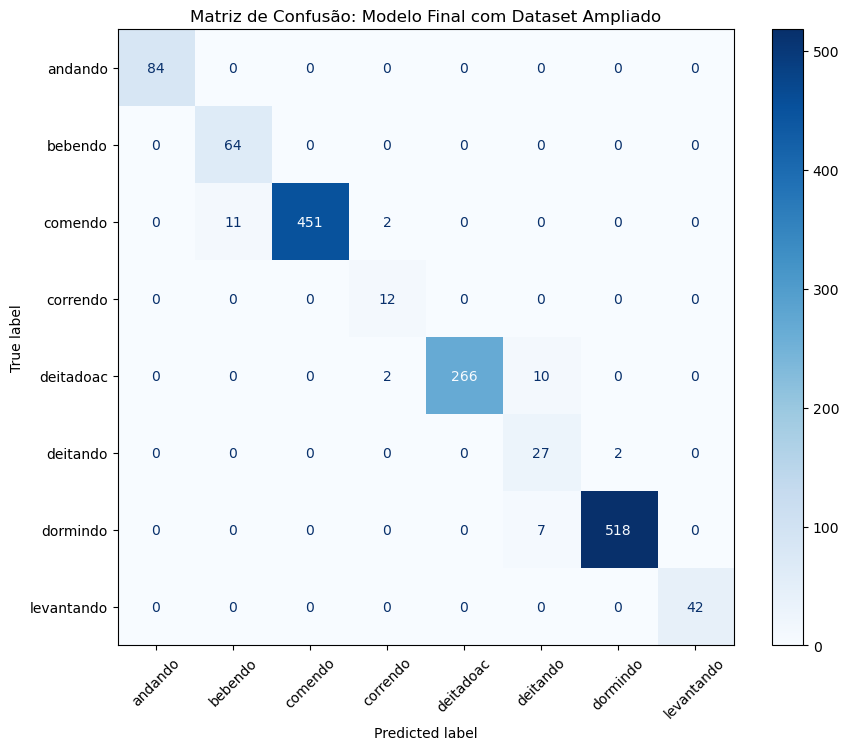

In [151]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# --- PASSO 1: LIMPEZA PROFUNDA ---
# Remove NaNs e Infinitos que podem ter surgido nos cálculos de FFT/Kurtosis
df_features_limpo = df_features.replace([np.inf, -np.inf], np.nan).dropna()

print(f"Dataset original: {len(df_features)} janelas")
print(f"Dataset após limpeza: {len(df_features_limpo)} janelas")

# --- PASSO 2: PREPARAÇÃO DOS DADOS ---
X = df_features_limpo.drop('atividade', axis=1)
y = df_features_limpo['atividade']

le = LabelEncoder()
y_encoded = le.fit_transform(y)

# --- PASSO 3: SPLIT E ESCALONAMENTO (Crucial) ---
# Usamos stratify para garantir que todas as classes apareçam no teste
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.25, random_state=42, stratify=y_encoded
)

# A Regressão Logística (SAGA) exige que os dados estejam na mesma escala
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# --- PASSO 4: TREINAMENTO ---
model = LogisticRegression(solver='saga', max_iter=2000, class_weight='balanced')
model.fit(X_train_scaled, y_train)

# --- PASSO 5: PREVISÕES E RELATÓRIO ---
y_pred = model.predict(X_test_scaled)

print("\nRelatório de Classificação:\n")
print(classification_report(y_test, y_pred, target_names=le.classes_))

# --- PASSO 6: MATRIZ DE CONFUSÃO ---
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(10, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
disp.plot(cmap=plt.cm.Blues, ax=ax, xticks_rotation=45)
plt.title('Matriz de Confusão: Modelo Final com Dataset Ampliado')
plt.show()

Dataset original: 7090 janelas
Dataset após limpeza: 7090 janelas

Relatório de Classificação:

              precision    recall  f1-score   support

     andando       1.00      1.00      1.00       116
     bebendo       0.97      1.00      0.98        85
     comendo       1.00      0.99      1.00       607
    correndo       0.75      1.00      0.86        12
   deitadoac       1.00      0.97      0.98       296
    deitando       0.69      0.97      0.80        36
    dormindo       1.00      0.98      0.99       573
  levantando       0.98      1.00      0.99        48

    accuracy                           0.98      1773
   macro avg       0.92      0.99      0.95      1773
weighted avg       0.99      0.98      0.99      1773



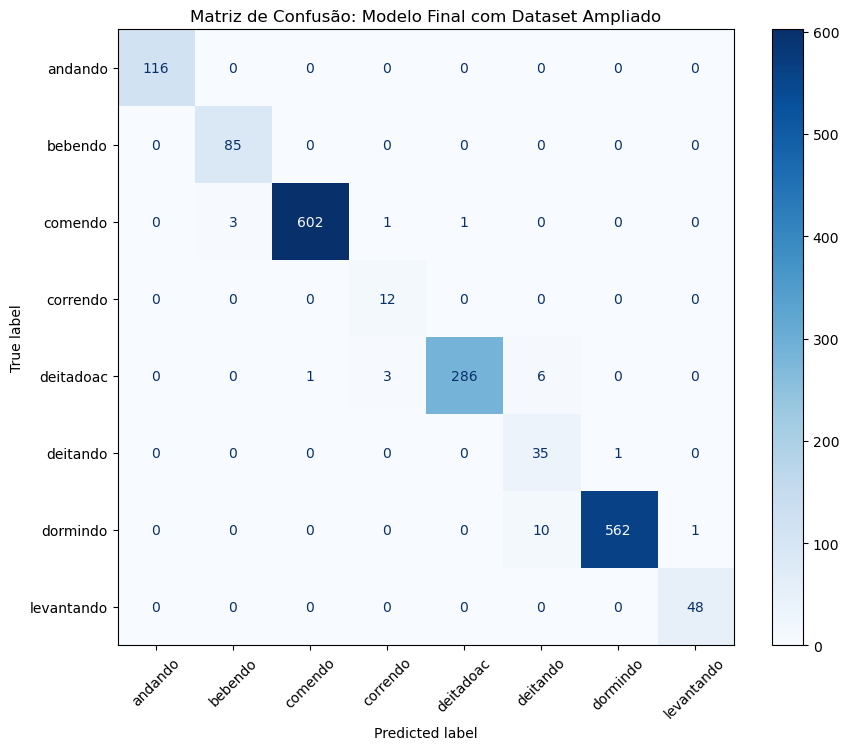

In [21]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# --- PASSO 1: LIMPEZA PROFUNDA ---
# Remove NaNs e Infinitos que podem ter surgido nos cálculos de FFT/Kurtosis
df_features_limpo = df_features.replace([np.inf, -np.inf], np.nan).dropna()

print(f"Dataset original: {len(df_features)} janelas")
print(f"Dataset após limpeza: {len(df_features_limpo)} janelas")

# --- PASSO 2: PREPARAÇÃO DOS DADOS ---
X = df_features_limpo.drop('atividade', axis=1)
y = df_features_limpo['atividade']

le = LabelEncoder()
y_encoded = le.fit_transform(y)

# --- PASSO 3: SPLIT E ESCALONAMENTO (Crucial) ---
# Usamos stratify para garantir que todas as classes apareçam no teste
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.25, random_state=42, stratify=y_encoded
)

# A Regressão Logística (SAGA) exige que os dados estejam na mesma escala
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# --- PASSO 4: TREINAMENTO ---
model = LogisticRegression(solver='saga', max_iter=2000, class_weight='balanced')
model.fit(X_train_scaled, y_train)

# --- PASSO 5: PREVISÕES E RELATÓRIO ---
y_pred = model.predict(X_test_scaled)

print("\nRelatório de Classificação:\n")
print(classification_report(y_test, y_pred, target_names=le.classes_))

# --- PASSO 6: MATRIZ DE CONFUSÃO ---
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(10, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
disp.plot(cmap=plt.cm.Blues, ax=ax, xticks_rotation=45)
plt.title('Matriz de Confusão: Modelo Final com Dataset Ampliado')
plt.show()

In [ ]:
#K fold

Iniciando Validação Cruzada (5-Fold)...
Fold 1 concluído. Acurácia: 0.9852
Fold 2 concluído. Acurácia: 0.9838
Fold 3 concluído. Acurácia: 0.9817
Fold 4 concluído. Acurácia: 0.9824
Fold 5 concluído. Acurácia: 0.9817

RESULTADO MÉDIO K-FOLD (k=5)
Acurácia Média: 0.9829 (+/- 0.0014)

Relatório de Classificação Consolidado:

              precision    recall  f1-score   support

     andando       1.00      1.00      1.00       462
     bebendo       0.95      1.00      0.97       338
     comendo       1.00      0.99      0.99      2427
    correndo       0.64      0.96      0.77        50
   deitadoac       1.00      0.98      0.99      1185
    deitando       0.69      0.95      0.80       145
    dormindo       1.00      0.98      0.99      2290
  levantando       0.98      1.00      0.99       193

    accuracy                           0.98      7090
   macro avg       0.91      0.98      0.94      7090
weighted avg       0.99      0.98      0.98      7090



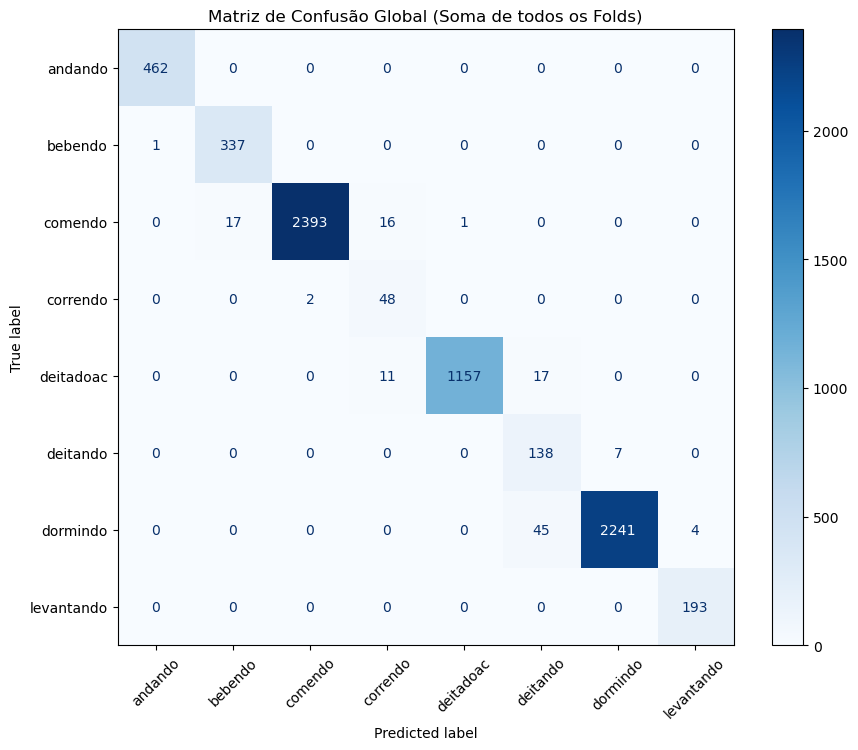

In [32]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score
import matplotlib.pyplot as plt

# --- PASSO 1: LIMPEZA PROFUNDA ---
df_features_limpo = df_features.replace([np.inf, -np.inf], np.nan).dropna()

# --- PASSO 2: PREPARAÇÃO DOS DADOS ---
# Removemos colunas que não são métricas (ajuste os nomes se necessário)
colunas_para_dropar = ['atividade', 'janela', 'ID']
X = df_features_limpo.drop(columns=[c for c in colunas_para_dropar if c in df_features_limpo.columns])
y = df_features_limpo['atividade']

le = LabelEncoder()
y_encoded = le.fit_transform(y)

# --- PASSO 3: CONFIGURAÇÃO DO K-FOLD ---
# k=5 é o padrão ouro: o modelo treina 5 vezes, cada vez com 20% de dados diferentes para teste
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Listas para armazenar os resultados de cada "dobra" (fold)
scores = []
y_true_total = []
y_pred_total = []

print(f"Iniciando Validação Cruzada (5-Fold)...")

# --- PASSO 4: LOOP DE TREINAMENTO E VALIDAÇÃO ---
# Criamos o escalonador e o modelo
scaler = StandardScaler()
model = LogisticRegression(solver='saga', max_iter=3000, class_weight='balanced')

for i, (train_index, test_index) in enumerate(kf.split(X, y_encoded)):
    # Divisão dos dados para este Fold específico
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y_encoded[train_index], y_encoded[test_index]
    
    # Escalonamento (fit apenas no treino do fold atual para evitar data leakage)
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    # Treinamento
    model.fit(X_train_scaled, y_train)
    
    # Previsão
    y_pred = model.predict(X_test_scaled)
    
    # Salvar resultados
    scores.append(accuracy_score(y_test, y_pred))
    y_true_total.extend(y_test)
    y_pred_total.extend(y_pred)
    
    print(f"Fold {i+1} concluído. Acurácia: {scores[-1]:.4f}")

# --- PASSO 5: RELATÓRIO CONSOLIDADO ---
print("\n" + "="*40)
print(f"RESULTADO MÉDIO K-FOLD (k=5)")
print(f"Acurácia Média: {np.mean(scores):.4f} (+/- {np.std(scores):.4f})")
print("="*40)

print("\nRelatório de Classificação Consolidado:\n")
print(classification_report(y_true_total, y_pred_total, target_names=le.classes_))

# --- PASSO 6: MATRIZ DE CONFUSÃO GLOBAL ---
cm = confusion_matrix(y_true_total, y_pred_total)
fig, ax = plt.subplots(figsize=(10, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
disp.plot(cmap=plt.cm.Blues, ax=ax, xticks_rotation=45)
plt.title('Matriz de Confusão Global (Soma de todos os Folds)')
plt.show()

Extraindo 22 características...


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(



Relatório de Classificação (22 Features):

              precision    recall  f1-score   support

     andando       0.54      0.46      0.50        84
     bebendo       0.19      0.27      0.22        64
     comendo       0.84      0.69      0.76       464
    correndo       0.58      0.92      0.71        12
   deitadoac       0.61      0.38      0.47       278
    deitando       0.15      0.45      0.23        29
    dormindo       0.79      0.90      0.84       525
  levantando       0.10      0.19      0.13        42

    accuracy                           0.66      1498
   macro avg       0.48      0.53      0.48      1498
weighted avg       0.70      0.66      0.67      1498



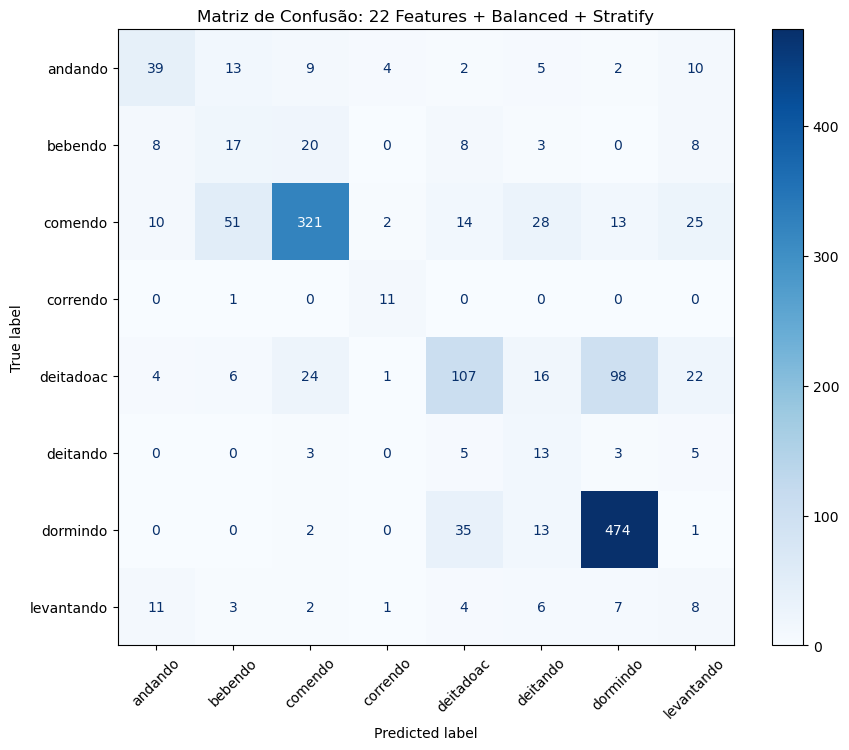

In [144]:
import pandas as pd
import numpy as np
from scipy.stats import skew, kurtosis
from scipy.signal import find_peaks
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# --- 1. EXTRAÇÃO DAS 22 FEATURES (DOMÍNIO DO TEMPO, FREQUÊNCIA E CORRELAÇÃO) ---
def extrair_features_completas(grupo):
    # Magnitude do Vetor (VM)
    ax, ay, az = grupo['AX'].values, grupo['AY'].values, grupo['AZ'].values
    vm = np.sqrt(ax**2 + ay**2 + az**2)
    vm_ac = vm - np.mean(vm) # Sinal sem a média para FFT pura
    
    # FFT (Domínio da Frequência)
    fft_vals = np.abs(np.fft.rfft(vm_ac))
    sorted_f = np.sort(fft_vals)
    N_fft = len(fft_vals)
    
    # Correlação Cruzada (Dinâmica entre eixos)
    # Mede como os eixos se movem em conjunto (essencial para o 'Andando')
    corr_xy = np.max(np.correlate(ax - np.mean(ax), ay - np.mean(ay), mode='full'))
    corr_xz = np.max(np.correlate(ax - np.mean(ax), az - np.mean(az), mode='full'))
    
    features = {
        # Domínio do Tempo (10 métricas)
        'mean': vm.mean(), 'std': vm.std(), 'min': vm.min(), 'max': vm.max(),
        'max_min_diff': vm.max() - vm.min(), 'median': np.median(vm),
        'peak_count': len(find_peaks(vm, height=np.mean(vm))[0]),
        'skewness': skew(vm), 'kurtosis': kurtosis(vm), 'sma': np.mean(np.abs(vm)),
        
        # Domínio da Frequência (10 métricas)
        'AV': np.mean(fft_vals), 'DC': fft_vals[0], 'SD_f': np.std(fft_vals),
        'MIN_f': np.min(fft_vals), 'MAX_f': np.max(fft_vals),
        'RG_f': np.max(fft_vals) - np.mean(fft_vals),
        'FQ': sorted_f[int(N_fft/4)] if N_fft > 4 else 0, 
        'SQ': sorted_f[int(N_fft/2)] if N_fft > 2 else 0,
        'RMS_f': np.sqrt(np.mean(fft_vals**2)), 'Median_f': np.median(fft_vals),
        
        # Dinâmica entre eixos (2 métricas)
        'max_corr_xy': corr_xy, 'max_corr_xz': corr_xz
    }
    return pd.Series(features)

# --- 2. APLICAÇÃO E LIMPEZA ---
print("Extraindo 22 características...")
# Certifique-se de que df_final é o seu dataset original com AX, AY, AZ e atividade
df_features = df_final.groupby('janela').apply(extrair_features_completas, include_groups=False)
df_features['atividade'] = df_final.groupby('janela')['atividade'].first()

# Remove NaNs e Infinitos (crucial para o solver SAGA)
df_features_limpo = df_features.replace([np.inf, -np.inf], np.nan).dropna()

# --- 3. PREPARAÇÃO E TREINAMENTO ---
X = df_features_limpo.drop('atividade', axis=1)
y = df_features_limpo['atividade']

le = LabelEncoder()
y_encoded = le.fit_transform(y)

# Split com Stratify para manter as proporções das atividades
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.25, random_state=42, stratify=y_encoded
)

# Escalonamento
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Treinamento com SAGA e Balanced
model = LogisticRegression(
    solver='saga', 
    max_iter=5000, 
    class_weight='balanced', 
    random_state=42
)
model.fit(X_train_scaled, y_train)

# --- 4. RESULTADOS ---
y_pred = model.predict(X_test_scaled)

print("\nRelatório de Classificação (22 Features):\n")
print(classification_report(y_test, y_pred, target_names=le.classes_))

# Plotagem da Matriz
fig, ax = plt.subplots(figsize=(10, 8))
disp = ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=le.classes_, cmap=plt.cm.Blues, ax=ax, xticks_rotation=45
)
plt.title('Matriz de Confusão: 22 Features + Balanced + Stratify')
plt.show()

In [ ]:

              precision    recall  f1-score   support

     andando       0.81      0.83      0.82        30
     bebendo       0.89      0.85      0.87        20
     comendo       0.90      0.94      0.92        50
    correndo       0.67      1.00      0.80         4
   deitadoac       0.97      0.87      0.92       107
    deitando       0.20      0.30      0.24        10
    dormindo       0.98      0.97      0.97       211
  levantando       0.38      0.55      0.44        11

    accuracy                           0.90       443
   macro avg       0.72      0.79      0.75       443
weighted avg       0.92      0.90      0.91       443

In [18]:
import pandas as pd
import numpy as np

def extrair_features_frequencia(grupo):
    # 1. Calcular a Magnitude do Vetor (VM)
    vm = np.sqrt(grupo['AX']**2 + grupo['AY']**2 + grupo['AZ']**2)
    
    # 2. Calcular a FFT e pegar o módulo (amplitude)
    # n=len(vm) garante a transformação correta
    fft_vals = np.abs(np.fft.rfft(vm - np.mean(vm))) 
    N = len(fft_vals)
    mu = np.mean(fft_vals)
    
    # Ordenar para quartis e mediana
    sorted_f = np.sort(fft_vals)
    
    # Cálculos
    features = {
        'AV': np.mean(fft_vals),
        'DC_value': fft_vals[0],
        'SD': np.std(fft_vals, ddof=1),
        'MIN': np.min(fft_vals),
        'MAX': np.max(fft_vals),
        'RG': np.max(fft_vals) - mu,
        'FQ': sorted_f[int((N + 1) / 4)],
        'SQ': sorted_f[int((N + 1) / 2)],
        'RMS': np.sqrt(np.mean(fft_vals**2)),
        'Median': np.median(fft_vals)
    }
    return pd.Series(features)

# Aplicar ao dataset (já agrupado por janela)
df_freq = df_final.groupby('janela').apply(extrair_features_frequencia, include_groups=False)
print(df_freq.head())

               AV      DC_value         SD           MIN        MAX  \
janela                                                                
1       23.933199  7.283063e-14  11.524324  7.283063e-14  49.187043   
2       13.823067  1.385558e-13   6.838029  1.385558e-13  26.326627   
3       16.809945  7.105427e-14  12.019257  7.105427e-14  55.571554   
4       15.419805  8.348877e-14   7.669168  8.348877e-14  31.768079   
5       24.720253  1.563194e-13  15.519759  1.563194e-13  79.564546   

               RG         FQ         SQ        RMS     Median  
janela                                                         
1       25.253843  18.964422  25.422047  26.514222  25.188614  
2       12.503560   9.326243  13.826965  15.392173  13.714969  
3       38.761608   9.299614  13.319779  20.596219  12.860808  
4       16.348274   9.541342  16.144006  17.188172  15.125329  
5       54.844293  13.602868  24.955726  29.107233  24.914321  


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Relatório de Classificação (Super Features):

              precision    recall  f1-score   support

     andando       0.60      0.30      0.40        30
     bebendo       0.24      0.30      0.27        20
     comendo       0.75      0.80      0.78        50
    correndo       0.33      1.00      0.50         4
   deitadoac       0.97      0.86      0.91       107
    deitando       0.16      0.30      0.21        10
    dormindo       0.99      0.98      0.98       211
  levantando       0.13      0.18      0.15        11

    accuracy                           0.82       443
   macro avg       0.52      0.59      0.52       443
weighted avg       0.85      0.82      0.83       443



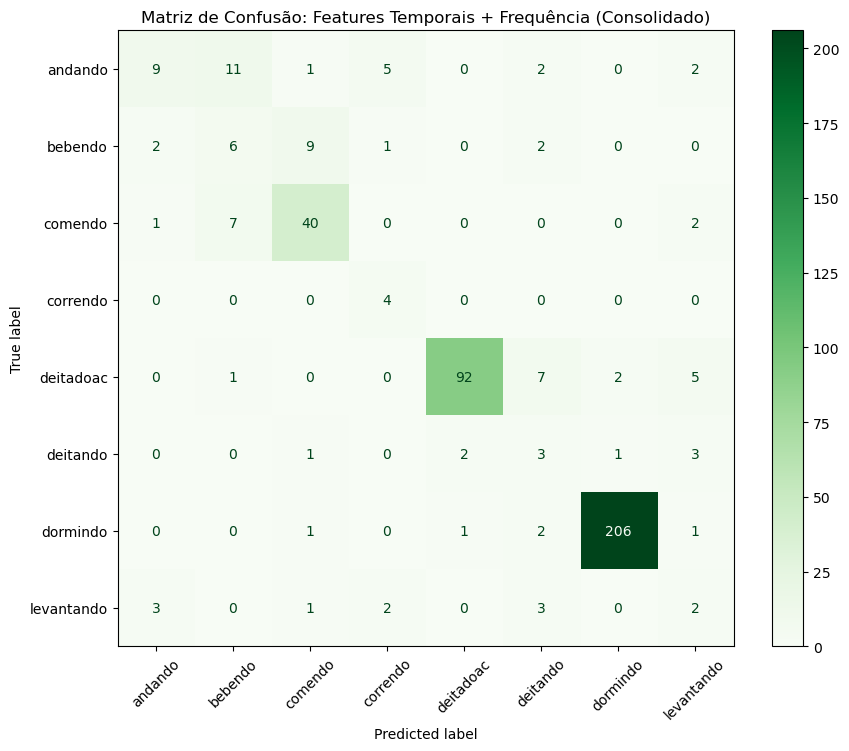

In [20]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, confusion_matrix
import matplotlib.pyplot as plt

# 1. Unir os DataFrames
df_super_features = pd.concat([df_features.drop('atividade', axis=1), df_freq], axis=1)

# 2. Reintegrar a atividade e transformar em código numérico
df_super_features['atividade'] = df_features['atividade']

# --- PASSO CRÍTICO: LIMPEZA DOS NaNs APÓS A UNIÃO ---
# Isso remove qualquer linha que tenha dado erro nos cálculos de FFT ou estatística
df_super_features = df_super_features.replace([np.inf, -np.inf], np.nan).dropna()

le = LabelEncoder()
df_super_features['atividade_code'] = le.fit_transform(df_super_features['atividade'])

# 3. Preparar X e y
X = df_super_features.drop(['atividade', 'atividade_code'], axis=1)
y = df_super_features['atividade_code']

# 4. Padronização (StandardScaler)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 5. Split Treino/Teste com ESTRATIFICAÇÃO (Garante que todas as classes apareçam)
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.25, random_state=42, stratify=y
)

# 6. Treinar com Pesos Balanceados (Essencial para as classes menores)
model = LogisticRegression(
    max_iter=5000, 
    multi_class='multinomial', 
    solver='saga', 
    class_weight='balanced'
)
model.fit(X_train, y_train)

# 7. Avaliação
y_pred = model.predict(X_test)
print("Relatório de Classificação (Super Features):\n")
print(classification_report(y_test, y_pred, target_names=le.classes_))

# Plot da Matriz de Confusão
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(10, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
disp.plot(cmap=plt.cm.Greens, xticks_rotation=45, ax=ax)
plt.title('Matriz de Confusão: Features Temporais + Frequência (Consolidado)')
plt.show()

In [23]:
import pandas as pd
import numpy as np
from scipy.stats import skew, kurtosis
from scipy.signal import find_peaks

def extrair_features_completas(grupo):
    # 1. Preparação (Magnitude e FFT)
    vm = np.sqrt(grupo['AX']**2 + grupo['AY']**2 + grupo['AZ']**2)
    fft_vals = np.abs(np.fft.rfft(vm - np.mean(vm)))
    sorted_f = np.sort(fft_vals)
    N_fft = len(fft_vals)
    
    # 2. Correlação Cruzada (Defasagem entre eixos)
    # Mede a relação dinâmica entre X, Y e Z
    corr_xy = np.max(np.correlate(grupo['AX'], grupo['AY'], mode='full'))
    corr_xz = np.max(np.correlate(grupo['AX'], grupo['AZ'], mode='full'))
    
    # 3. Dicionário consolidado
    features = {
        # Domínio do Tempo
        'mean': vm.mean(), 'std': vm.std(), 'min': vm.min(), 'max': vm.max(),
        'max_min_diff': vm.max() - vm.min(), 'median': np.median(vm),
        'peak_count': len(find_peaks(vm, height=np.mean(vm))[0]),
        'skewness': skew(vm), 'kurtosis': kurtosis(vm), 'sma': np.sum(np.abs(vm)) / len(vm),
        # Domínio da Frequência
        'AV': np.mean(fft_vals), 'DC': fft_vals[0], 'SD_f': np.std(fft_vals),
        'MIN_f': np.min(fft_vals), 'MAX_f': np.max(fft_vals),
        'RG_f': np.max(fft_vals) - np.mean(fft_vals),
        'FQ': sorted_f[int(N_fft/4)], 'SQ': sorted_f[int(N_fft/2)],
        'RMS_f': np.sqrt(np.mean(fft_vals**2)), 'Median_f': np.median(fft_vals),
        # Dinâmica entre eixos
        'max_corr_xy': corr_xy, 'max_corr_xz': corr_xz
    }
    return pd.Series(features)

# Aplicação unificada
df_features = df_final.groupby('janela').apply(extrair_features_completas, include_groups=False)
df_features['atividade'] = df_final.groupby('janela')['atividade'].first()

print(f"Features extraídas com sucesso! Total de colunas: {df_features.shape[1]}")
print(df_features.head())

Features extraídas com sucesso! Total de colunas: 23
             mean       std        min        max  max_min_diff     median  \
janela                                                                       
1       13.545966  2.682460   8.934936  30.342653     21.407716  12.989732   
2       12.994457  1.548667   8.308177  20.105347     11.797169  12.949863   
3       13.484504  2.089616  10.071121  24.122828     14.051707  12.906397   
4       12.636553  1.732319   5.988707  17.481813     11.493106  12.406962   
5       13.418125  2.952005   2.940358  23.450052     20.509693  13.249201   

        peak_count  skewness   kurtosis        sma  ...         MIN_f  \
janela                                              ...                 
1             19.0  3.763470  18.983735  13.545966  ...  7.283063e-14   
2             24.0  1.681273   7.072869  12.994457  ...  1.385558e-13   
3             17.0  2.500779   8.230616  13.484504  ...  7.105427e-14   
4             21.0  0.167620   2.49

In [25]:
# 1. Limpeza Imediata (Crucial: faça isso antes de qualquer outra coisa)
# Remove NaNs e Infinitos que surgem de divisões por zero ou silêncio do sensor
df_features_ok = df_features.replace([np.inf, -np.inf], np.nan).dropna()

print(f"Janelas originais: {len(df_features)}")
print(f"Janelas limpas: {len(df_features_ok)}")

# 2. Preparação usando o DataFrame LIMPO
X = df_features_ok.drop('atividade', axis=1)
y = df_features_ok['atividade']

# 3. Codificação
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# 4. Divisão Treino/Teste (com stratify para manter as classes)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.25, random_state=42, stratify=y_encoded
)

# 5. Padronização
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 6. Treinamento (Agora sem erro!)
model = LogisticRegression(
    solver='saga', 
    max_iter=10000, 
    multi_class='multinomial', 
    class_weight='balanced'
)
model.fit(X_train_scaled, y_train)

print("Sucesso! Modelo treinado.")

Janelas originais: 2345
Janelas limpas: 1772


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Sucesso! Modelo treinado.


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Sucesso! Dataset final com 1772 janelas.
Relatório de Classificação (Consolidado):

              precision    recall  f1-score   support

     andando       0.84      0.90      0.87        30
     bebendo       0.85      0.85      0.85        20
     comendo       0.90      0.94      0.92        50
    correndo       1.00      1.00      1.00         4
   deitadoac       0.97      0.88      0.92       107
    deitando       0.19      0.30      0.23        10
    dormindo       0.99      0.97      0.98       211
  levantando       0.33      0.45      0.38        11

    accuracy                           0.91       443
   macro avg       0.76      0.79      0.77       443
weighted avg       0.92      0.91      0.91       443



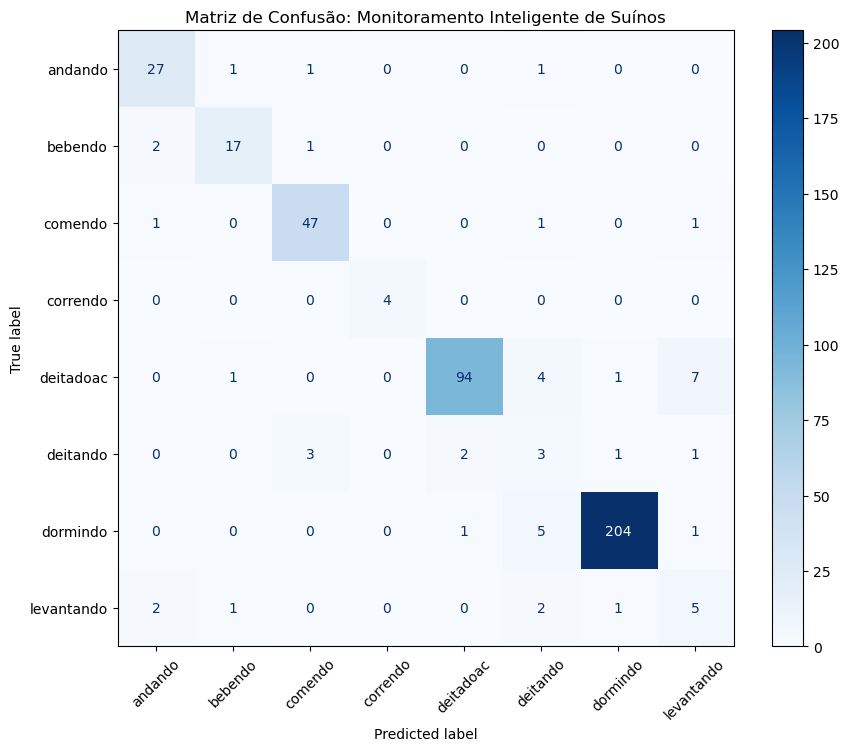

In [28]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, confusion_matrix
import matplotlib.pyplot as plt
import numpy as np

# 1. Preparação dos dados
# 1.1 LIMPEZA CRÍTICA: Remove NaNs antes de qualquer divisão
df_features_limpo = df_features.replace([np.inf, -np.inf], np.nan).dropna()

X = df_features_limpo.drop('atividade', axis=1)
y = df_features_limpo['atividade']

# 2. Codificação numérica
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# 3. Divisão Treino/Teste com ESTRATIFICAÇÃO
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, 
    test_size=0.25, 
    random_state=42, 
    stratify=y_encoded  
)

# 4. PADRONIZAÇÃO
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5. Treinamento com Peso Balanceado
model = LogisticRegression(
    solver='saga', 
    max_iter=10000, 
    multi_class='multinomial', 
    class_weight='balanced' 
)
model.fit(X_train_scaled, y_train)

# 6. Avaliação
y_pred = model.predict(X_test_scaled)

print(f"Sucesso! Dataset final com {len(df_features_limpo)} janelas.")
print("Relatório de Classificação (Consolidado):\n")
print(classification_report(y_test, y_pred, target_names=le.classes_))

# 7. Matriz de Confusão
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(10, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
disp.plot(cmap=plt.cm.Blues, ax=ax, xticks_rotation=45)
plt.title('Matriz de Confusão: Monitoramento Inteligente de Suínos')
plt.show()

# teste 19/03/26

Dataset carregado com sucesso! Total de linhas: 189000


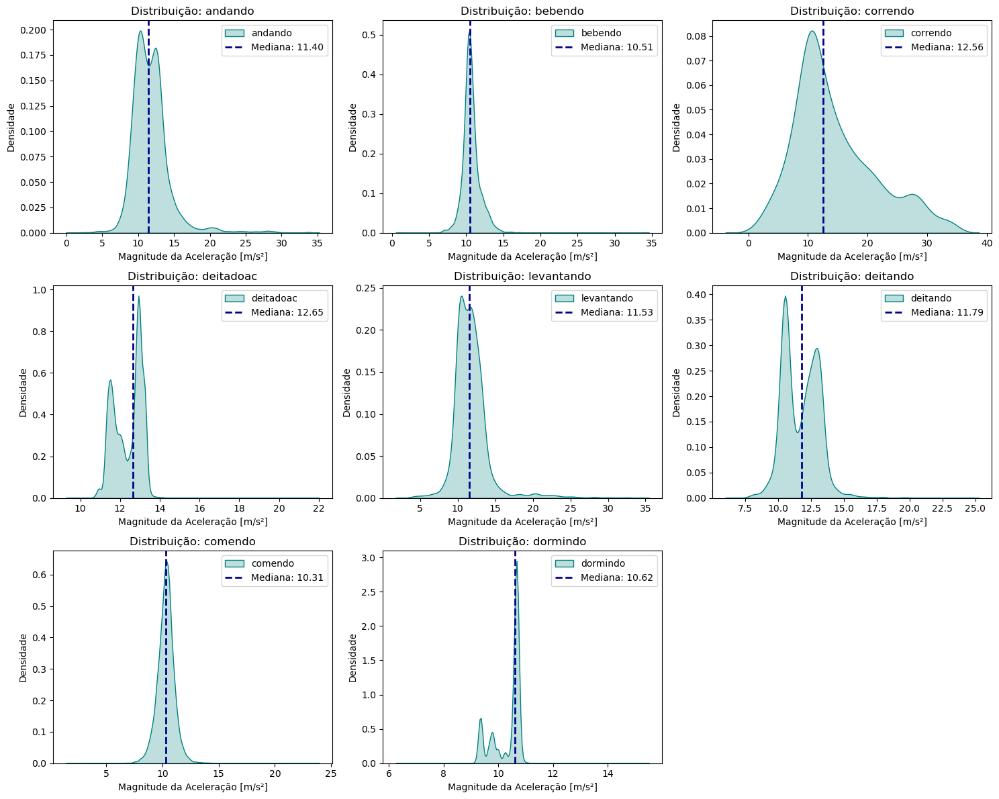

In [41]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os

# --- PASSO CRUCIAL: LER O DATASET GERADO ---
caminho_dataset = r'C:\Users\franc\OneDrive\Desktop\dataset_treinamento_suinos.xlsx'

if os.path.exists(caminho_dataset):
    # Carrega o arquivo que você salvou anteriormente
    df_analise = pd.read_excel(caminho_dataset)
    print(f"Dataset carregado com sucesso! Total de linhas: {len(df_analise)}")
else:
    print("Erro: O arquivo não foi encontrado no caminho especificado.")
    # Fallback caso você ainda tenha o df_final na memória
    df_analise = df_final 

# 1. Lista de atividades presentes no seu dataset (agora usando df_analise)
atividades = df_analise['atividade'].unique()

# 2. Configura a grade
cols = 3
rows = int(np.ceil(len(atividades) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(15, rows * 4))
axes = axes.flatten()

# 3. Processamento
for i, activity in enumerate(atividades):
    # Filtra os dados da atividade
    subset = df_analise[df_analise['atividade'] == activity]
    
    # Calcula a Magnitude do Vetor (VM) -> sqrt(x² + y² + z²)
    # Isso ajuda a entender a intensidade do movimento independente da direção
    vm = np.sqrt(subset['AX']**2 + subset['AY']**2 + subset['AZ']**2)
    
    # Calcula a mediana do VM
    median_vm = np.median(vm)

    # Plot KDE (Densidade)
    sns.kdeplot(vm, fill=True, label=activity, ax=axes[i], color='teal')
    axes[i].axvline(median_vm, color='darkblue', linestyle='dashed', linewidth=2, label=f'Mediana: {median_vm:.2f}')

    # Estilização
    axes[i].set_xlabel('Magnitude da Aceleração [m/s²]') # Ajustado para m/s² conforme seus dados
    axes[i].set_ylabel('Densidade')
    axes[i].set_title(f'Distribuição: {activity}')
    axes[i].legend()

# Limpeza de eixos extras
for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

In [42]:
import pandas as pd
import numpy as np
from scipy.stats import skew, kurtosis
from scipy.signal import find_peaks

df_final= df_analise

def extrair_features(grupo):
    # 1. Calculando a Magnitude do Vetor (VM)
    vm = np.sqrt(grupo['AX']**2 + grupo['AY']**2 + grupo['AZ']**2)
    
    # 2. Contagem de picos (usando limiar de altura)
    peaks, _ = find_peaks(vm, height=np.mean(vm))
    
    # Dicionário com as características extraídas
    features = {
        'mean': vm.mean(),
        'std': vm.std(),
        'min': vm.min(),
        'max': vm.max(),
        'max_min_diff': vm.max() - vm.min(),
        'median': np.median(vm),
        'peak_count': len(peaks),
        'skewness': skew(vm),
        'kurtosis': kurtosis(vm),
        'sma': np.sum(np.abs(vm)) / len(vm) # Signal Magnitude Area
    }
    return pd.Series(features)

# Aplicando para cada janela
# Agrupamos pelo ID da janela e aplicamos a função de extração
df_features = df_final.groupby('janela').apply(extrair_features)

# Adicionamos a coluna da atividade de volta ao dataset de features
# (Pegamos a primeira atividade de cada janela, assumindo que elas são homogêneas)
atividades = df_final.groupby('janela')['atividade'].first()
df_features['atividade'] = atividades

print(df_features.head())

             mean       std        min        max  max_min_diff     median  \
janela                                                                       
1       13.545966  2.682460   8.934936  30.342653     21.407716  12.989732   
2       12.994457  1.548667   8.308177  20.105347     11.797169  12.949863   
3       13.484504  2.089616  10.071121  24.122828     14.051707  12.906397   
4       12.636553  1.732319   5.988707  17.481813     11.493106  12.406962   
5       13.418125  2.952005   2.940358  23.450052     20.509693  13.249201   

        peak_count  skewness   kurtosis        sma atividade  
janela                                                        
1             19.0  3.763470  18.983735  13.545966   andando  
2             24.0  1.681273   7.072869  12.994457   andando  
3             17.0  2.500779   8.230616  13.484504   andando  
4             21.0  0.167620   2.497096  12.636553   andando  
5             25.0 -0.052244   2.533199  13.418125   andando  


C:\Users\franc\AppData\Local\Temp\ipykernel_22016\3597079410.py:32: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_features = df_final.groupby('janela').apply(extrair_features)


In [43]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df_features['atividade_code'] = le.fit_transform(df_features['atividade'])

# Salve o mapeamento para consultar depois
mapeamento = dict(zip(le.classes_, le.transform(le.classes_)))
print("Mapeamento das classes:", mapeamento)



Mapeamento das classes: {'andando': np.int64(0), 'bebendo': np.int64(1), 'comendo': np.int64(2), 'correndo': np.int64(3), 'deitadoac': np.int64(4), 'deitando': np.int64(5), 'dormindo': np.int64(6), 'levantando': np.int64(7)}


In [44]:
# Remove qualquer linha que tenha valor vazio (NaN) ou infinito
df_features = df_features.replace([np.inf, -np.inf], np.nan).dropna()

print(f"Dataset limpo! Sobraram {len(df_features)} janelas para o treino.")

Dataset limpo! Sobraram 1890 janelas para o treino.


In [49]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Define as variáveis de entrada (X) e saída (y)
X = df_features.drop(['atividade', 'atividade_code'], axis=1)
y = df_features['atividade_code']

# Padroniza as colunas (média 0, desvio padrão 1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Divide em treino (80%) e teste (20%)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

In [50]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# 1. Instanciar e treinar o modelo
model = LogisticRegression(max_iter=1000) # Aumentamos o iter para garantir convergência
model.fit(X_train, y_train)

# 2. Previsões
y_pred = model.predict(X_test)

# 3. Relatório de Desempenho
print("Relatório de Classificação:\n")
print(classification_report(y_test, y_pred, target_names=le.classes_))

# 4. Matriz de Confusão (Visualização essencial para o seu paper)
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)

fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(cmap=plt.cm.Blues, ax=ax, xticks_rotation=45)
plt.title('Matriz de Confusão do Modelo de Comportamento')
plt.show()

Relatório de Classificação:



ValueError: Number of classes, 7, does not match size of target_names, 8. Try specifying the labels parameter

In [ ]:

              precision    recall  f1-score   support

     andando       0.52      0.71      0.60        21
     bebendo       0.00      0.00      0.00        16
     comendo       0.65      0.84      0.73        49
    correndo       1.00      0.50      0.67         6
   deitadoac       0.88      0.95      0.92        86
    deitando       0.00      0.00      0.00         5
    dormindo       0.94      0.98      0.96       157
  levantando       0.33      0.07      0.11        15

    accuracy                           0.83       355
   macro avg       0.54      0.51      0.50       355
weighted avg       0.78      0.83      0.80       355

In [ ]:
Relatório de Classificação:

              precision    recall  f1-score   support

     andando       0.47      0.58      0.52        26
     bebendo       0.00      0.00      0.00        23
     comendo       0.71      0.91      0.80       118
    correndo       1.00      0.57      0.73         7
   deitadoac       0.86      0.75      0.80       102
    deitando       0.00      0.00      0.00        11
    dormindo       0.86      0.96      0.91       200
  levantando       1.00      0.06      0.11        17

    accuracy                           0.79       504
   macro avg       0.61      0.48      0.48       504
weighted avg       0.75      0.79      0.75       504

In [ ]:
              precision    recall  f1-score   support

     andando       0.52      0.71      0.60        21
     bebendo       0.00      0.00      0.00        16
     comendo       0.65      0.84      0.73        49
    correndo       1.00      0.50      0.67         6
   deitadoac       0.88      0.95      0.92        86
    deitando       0.00      0.00      0.00         5
    dormindo       0.94      0.98      0.96       157
  levantando       0.33      0.07      0.11        15

    accuracy                           0.83       355
   macro avg       0.54      0.51      0.50       355
weighted avg       0.78      0.83      0.80       355

In [33]:
import pandas as pd
import numpy as np

def extrair_features_frequencia(grupo):
    # 1. Calcular a Magnitude do Vetor (VM)
    vm = np.sqrt(grupo['AX']**2 + grupo['AY']**2 + grupo['AZ']**2)
    
    # 2. Calcular a FFT e pegar o módulo (amplitude)
    # n=len(vm) garante a transformação correta
    fft_vals = np.abs(np.fft.rfft(vm - np.mean(vm))) 
    N = len(fft_vals)
    mu = np.mean(fft_vals)
    
    # Ordenar para quartis e mediana
    sorted_f = np.sort(fft_vals)
    
    # Cálculos
    features = {
        'AV': np.mean(fft_vals),
        'DC_value': fft_vals[0],
        'SD': np.std(fft_vals, ddof=1),
        'MIN': np.min(fft_vals),
        'MAX': np.max(fft_vals),
        'RG': np.max(fft_vals) - mu,
        'FQ': sorted_f[int((N + 1) / 4)],
        'SQ': sorted_f[int((N + 1) / 2)],
        'RMS': np.sqrt(np.mean(fft_vals**2)),
        'Median': np.median(fft_vals)
    }
    return pd.Series(features)

# Aplicar ao dataset (já agrupado por janela)
df_freq = df_final.groupby('janela').apply(extrair_features_frequencia, include_groups=False)
print(df_freq.head())

               AV      DC_value         SD           MIN        MAX  \
janela                                                                
1       23.933199  7.283063e-14  11.524324  7.283063e-14  49.187043   
2       13.823067  1.385558e-13   6.838029  1.385558e-13  26.326627   
3       16.809945  7.105427e-14  12.019257  7.105427e-14  55.571554   
4       15.419805  8.348877e-14   7.669168  8.348877e-14  31.768079   
5       24.720253  1.563194e-13  15.519759  1.563194e-13  79.564546   

               RG         FQ         SQ        RMS     Median  
janela                                                         
1       25.253843  18.964422  25.422047  26.514222  25.188614  
2       12.503560   9.326243  13.826965  15.392173  13.714969  
3       38.761608   9.299614  13.319779  20.596219  12.860808  
4       16.348274   9.541342  16.144006  17.188172  15.125329  
5       54.844293  13.602868  24.955726  29.107233  24.914321  


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_clas

              precision    recall  f1-score   support

     andando       0.59      0.81      0.69        27
     bebendo       0.00      0.00      0.00        17
     comendo       0.68      0.87      0.76        54
    correndo       1.00      0.50      0.67         6
   deitadoac       0.88      0.93      0.90       109
    deitando       0.00      0.00      0.00         6
    dormindo       0.96      1.00      0.98       207
  levantando       0.20      0.06      0.09        17

    accuracy                           0.86       443
   macro avg       0.54      0.52      0.51       443
weighted avg       0.81      0.86      0.83       443



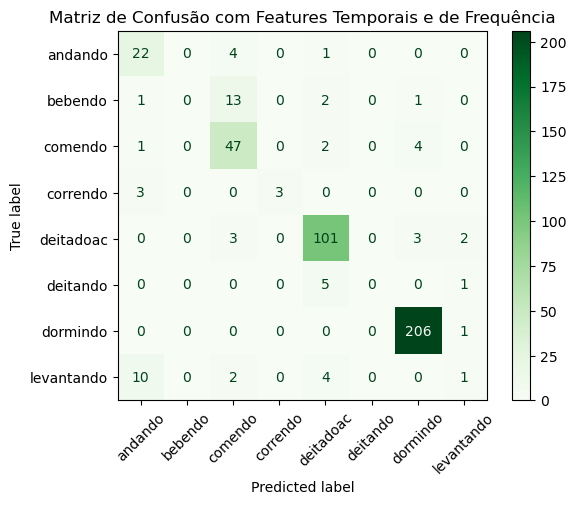

In [34]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, confusion_matrix
import matplotlib.pyplot as plt

# 1. Unir os dois DataFrames (Certifique-se que o índice 'janela' é o mesmo em ambos)
df_super_features = pd.concat([df_features.drop('atividade', axis=1), df_freq], axis=1)

# 2. Reintegrar a atividade e transformar em código numérico
df_super_features['atividade'] = df_features['atividade']
le = LabelEncoder()
df_super_features['atividade_code'] = le.fit_transform(df_super_features['atividade'])

# 3. Preparar X e y
X = df_super_features.drop(['atividade', 'atividade_code'], axis=1)
y = df_super_features['atividade_code']

# 4. Padronização Obrigatória (ESSENCIAL para modelos baseados em gradiente)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 5. Split Treino/Teste
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.25, random_state=42)

# 6. Treinar com Regularização (L2 é o padrão para evitar overfitting)
model = LogisticRegression(max_iter=2000, multi_class='multinomial')
model.fit(X_train, y_train)

# 7. Avaliação
y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred, target_names=le.classes_))

# Plot da Matriz de Confusão
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
disp.plot(cmap=plt.cm.Greens, xticks_rotation=45)
plt.title('Matriz de Confusão com Features Temporais e de Frequência')
plt.show()

In [ ]:

     andando       0.45      0.46      0.46        39
     bebendo       0.00      0.00      0.00        28
     comendo       0.67      0.93      0.78       139
    correndo       1.00      0.62      0.77         8
   deitadoac       0.86      0.76      0.81       129
    deitando       0.00      0.00      0.00        15
    dormindo       0.86      0.96      0.91       247
  levantando       1.00      0.04      0.08        25

    accuracy                           0.77       630
   macro avg       0.61      0.47      0.47       630
weighted avg       0.74      0.77      0.73       630

In [ ]:
     andando       0.45      0.50      0.47        38
     bebendo       0.00      0.00      0.00        27
     comendo       0.71      0.88      0.79       153
    correndo       1.00      0.67      0.80         9
   deitadoac       0.90      0.93      0.92       119
    deitando       0.00      0.00      0.00        16
    dormindo       0.90      0.98      0.94       203
  levantando       0.50      0.05      0.08        22

    accuracy                           0.80       587
   macro avg       0.56      0.50      0.50       587
weighted avg       0.74      0.80      0.76       587

In [35]:
import pandas as pd
import numpy as np
from scipy.stats import skew, kurtosis
from scipy.signal import find_peaks

def extrair_features_completas(grupo):
    # 1. Preparação (Magnitude e FFT)
    vm = np.sqrt(grupo['AX']**2 + grupo['AY']**2 + grupo['AZ']**2)
    fft_vals = np.abs(np.fft.rfft(vm - np.mean(vm)))
    sorted_f = np.sort(fft_vals)
    N_fft = len(fft_vals)
    
    # 2. Correlação Cruzada (Defasagem entre eixos)
    # Mede a relação dinâmica entre X, Y e Z
    corr_xy = np.max(np.correlate(grupo['AX'], grupo['AY'], mode='full'))
    corr_xz = np.max(np.correlate(grupo['AX'], grupo['AZ'], mode='full'))
    
    # 3. Dicionário consolidado
    features = {
        # Domínio do Tempo
        'mean': vm.mean(), 'std': vm.std(), 'min': vm.min(), 'max': vm.max(),
        'max_min_diff': vm.max() - vm.min(), 'median': np.median(vm),
        'peak_count': len(find_peaks(vm, height=np.mean(vm))[0]),
        'skewness': skew(vm), 'kurtosis': kurtosis(vm), 'sma': np.sum(np.abs(vm)) / len(vm),
        # Domínio da Frequência
        'AV': np.mean(fft_vals), 'DC': fft_vals[0], 'SD_f': np.std(fft_vals),
        'MIN_f': np.min(fft_vals), 'MAX_f': np.max(fft_vals),
        'RG_f': np.max(fft_vals) - np.mean(fft_vals),
        'FQ': sorted_f[int(N_fft/4)], 'SQ': sorted_f[int(N_fft/2)],
        'RMS_f': np.sqrt(np.mean(fft_vals**2)), 'Median_f': np.median(fft_vals),
        # Dinâmica entre eixos
        'max_corr_xy': corr_xy, 'max_corr_xz': corr_xz
    }
    return pd.Series(features)

# Aplicação unificada
df_features = df_final.groupby('janela').apply(extrair_features_completas, include_groups=False)
df_features['atividade'] = df_final.groupby('janela')['atividade'].first()

print(f"Features extraídas com sucesso! Total de colunas: {df_features.shape[1]}")
print(df_features.head())

Features extraídas com sucesso! Total de colunas: 23
             mean       std        min        max  max_min_diff     median  \
janela                                                                       
1       13.545966  2.682460   8.934936  30.342653     21.407716  12.989732   
2       12.994457  1.548667   8.308177  20.105347     11.797169  12.949863   
3       13.484504  2.089616  10.071121  24.122828     14.051707  12.906397   
4       12.636553  1.732319   5.988707  17.481813     11.493106  12.406962   
5       13.418125  2.952005   2.940358  23.450052     20.509693  13.249201   

        peak_count  skewness   kurtosis        sma  ...         MIN_f  \
janela                                              ...                 
1             19.0  3.763470  18.983735  13.545966  ...  7.283063e-14   
2             24.0  1.681273   7.072869  12.994457  ...  1.385558e-13   
3             17.0  2.500779   8.230616  13.484504  ...  7.105427e-14   
4             21.0  0.167620   2.49

Dataset original: 1772 janelas
Dataset após limpeza: 1772 janelas


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(



Relatório de Classificação:

              precision    recall  f1-score   support

     andando       0.81      0.83      0.82        30
     bebendo       0.89      0.85      0.87        20
     comendo       0.90      0.94      0.92        50
    correndo       0.67      1.00      0.80         4
   deitadoac       0.97      0.87      0.92       107
    deitando       0.20      0.30      0.24        10
    dormindo       0.98      0.97      0.97       211
  levantando       0.38      0.55      0.44        11

    accuracy                           0.90       443
   macro avg       0.72      0.79      0.75       443
weighted avg       0.92      0.90      0.91       443



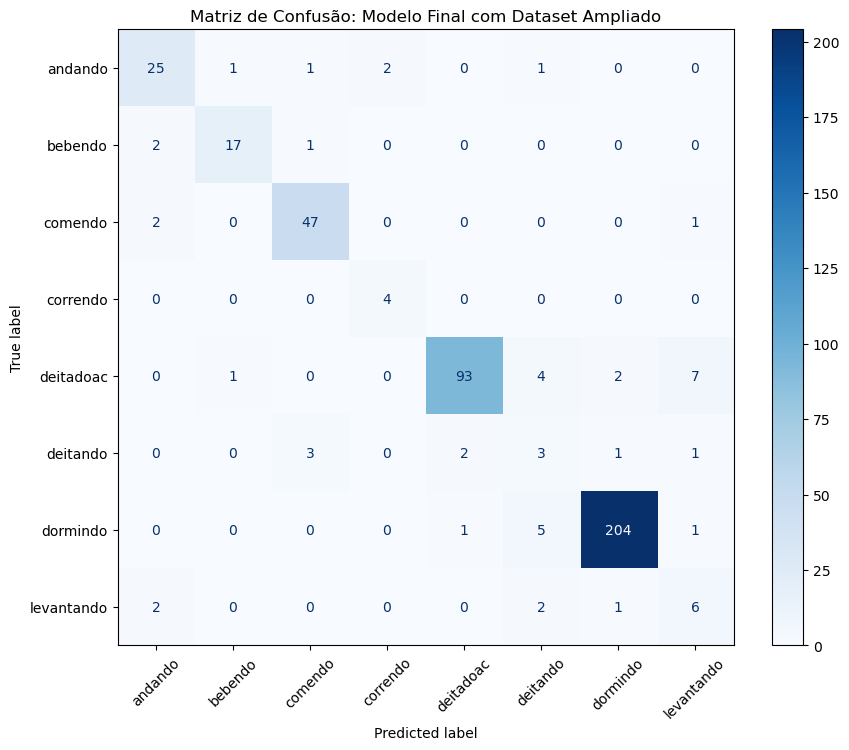

In [36]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# --- PASSO 1: LIMPEZA PROFUNDA ---
# Remove NaNs e Infinitos que podem ter surgido nos cálculos de FFT/Kurtosis
df_features_limpo = df_features.replace([np.inf, -np.inf], np.nan).dropna()

print(f"Dataset original: {len(df_features)} janelas")
print(f"Dataset após limpeza: {len(df_features_limpo)} janelas")

# --- PASSO 2: PREPARAÇÃO DOS DADOS ---
X = df_features_limpo.drop('atividade', axis=1)
y = df_features_limpo['atividade']

le = LabelEncoder()
y_encoded = le.fit_transform(y)

# --- PASSO 3: SPLIT E ESCALONAMENTO (Crucial) ---
# Usamos stratify para garantir que todas as classes apareçam no teste
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.25, random_state=42, stratify=y_encoded
)

# A Regressão Logística (SAGA) exige que os dados estejam na mesma escala
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# --- PASSO 4: TREINAMENTO ---
model = LogisticRegression(solver='saga', max_iter=2000, class_weight='balanced')
model.fit(X_train_scaled, y_train)

# --- PASSO 5: PREVISÕES E RELATÓRIO ---
y_pred = model.predict(X_test_scaled)

print("\nRelatório de Classificação:\n")
print(classification_report(y_test, y_pred, target_names=le.classes_))

# --- PASSO 6: MATRIZ DE CONFUSÃO ---
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(10, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
disp.plot(cmap=plt.cm.Blues, ax=ax, xticks_rotation=45)
plt.title('Matriz de Confusão: Modelo Final com Dataset Ampliado')
plt.show()

In [ ]:
Relatório de Classificação:

              precision    recall  f1-score   support

     andando       0.47      0.58      0.52        26
     bebendo       0.00      0.00      0.00        23
     comendo       0.71      0.91      0.80       118
    correndo       1.00      0.57      0.73         7
   deitadoac       0.86      0.75      0.80       102
    deitando       0.00      0.00      0.00        11
    dormindo       0.86      0.96      0.91       200
  levantando       1.00      0.06      0.11        17

    accuracy                           0.79       504
   macro avg       0.61      0.48      0.48       504
weighted avg       0.75      0.79      0.75       504

In [ ]:
Relatório de Classificação:

              precision    recall  f1-score   support

     andando       0.63      0.82      0.71        44
     bebendo       0.77      0.75      0.76        32
     comendo       0.89      0.84      0.86       148
    correndo       0.33      0.25      0.29         4
   deitadoac       0.93      0.70      0.79       128
    deitando       0.20      0.40      0.27        15
    dormindo       0.88      0.93      0.91       240
  levantando       0.36      0.42      0.39        19

    accuracy                           0.81       630
   macro avg       0.63      0.64      0.62       630
weighted avg       0.84      0.81      0.82       630

In [ ]:
              precision    recall  f1-score   support

     andando       0.68      0.58      0.62        43
     bebendo       0.66      0.72      0.69        32
     comendo       0.90      0.85      0.88       148
    correndo       0.31      1.00      0.47         4
   deitadoac       0.97      0.82      0.89       109
    deitando       0.27      0.53      0.36        15
    dormindo       0.92      0.96      0.94       217
  levantando       0.50      0.37      0.42        19

    accuracy                           0.84       587
   macro avg       0.65      0.73      0.66       587
weighted avg       0.86      0.84      0.84       587

In [ ]:
Relatório de Classificação:

              precision    recall  f1-score   support

     andando       0.81      0.83      0.82        30
     bebendo       0.89      0.85      0.87        20
     comendo       0.90      0.94      0.92        50
    correndo       0.67      1.00      0.80         4
   deitadoac       0.97      0.87      0.92       107
    deitando       0.20      0.30      0.24        10
    dormindo       0.98      0.97      0.97       211
  levantando       0.38      0.55      0.44        11

    accuracy                           0.90       443
   macro avg       0.72      0.79      0.75       443
weighted avg       0.92      0.90      0.91       443

In [ ]:
Teste dataset dia 30/01

In [39]:
import pandas as pd
import numpy as np
from scipy.stats import skew, kurtosis
from scipy.signal import find_peaks

# --- 1. DEFINIÇÃO DA FUNÇÃO DE EXTRAÇÃO (MESMA DO TREINO) ---
def extrair_features_completas(grupo):
    # Magnitude e FFT
    vm = np.sqrt(grupo['AX']**2 + grupo['AY']**2 + grupo['AZ']**2)
    fft_vals = np.abs(np.fft.rfft(vm - np.mean(vm)))
    sorted_f = np.sort(fft_vals)
    N_fft = len(fft_vals)
    
    # Correlação Cruzada
    corr_xy = np.max(np.correlate(grupo['AX'], grupo['AY'], mode='full'))
    corr_xz = np.max(np.correlate(grupo['AX'], grupo['AZ'], mode='full'))
    
    # Dicionário de Features
    features = {
        'mean': vm.mean(), 'std': vm.std(), 'min': vm.min(), 'max': vm.max(),
        'max_min_diff': vm.max() - vm.min(), 'median': np.median(vm),
        'peak_count': len(find_peaks(vm, height=np.mean(vm))[0]),
        'skewness': skew(vm), 'kurtosis': kurtosis(vm), 'sma': np.sum(np.abs(vm)) / len(vm),
        'AV': np.mean(fft_vals), 'DC': fft_vals[0], 'SD_f': np.std(fft_vals),
        'MIN_f': np.min(fft_vals), 'MAX_f': np.max(fft_vals),
        'RG_f': np.max(fft_vals) - np.mean(fft_vals),
        'FQ': sorted_f[int(N_fft/4)] if N_fft > 4 else 0, 
        'SQ': sorted_f[int(N_fft/2)] if N_fft > 2 else 0,
        'RMS_f': np.sqrt(np.mean(fft_vals**2)), 'Median_f': np.median(fft_vals),
        'max_corr_xy': corr_xy, 'max_corr_xz': corr_xz
    }
    return pd.Series(features)

# --- 2. CARREGAMENTO E PROCESSAMENTO DO DATASET 2 ---
caminho_dataset2 = r'C:\Users\franc\OneDrive\Desktop\dataset2.xlsx'

print("Iniciando teste no Dataset 2...")
df_bruto_2 = pd.read_excel(caminho_dataset2)

# Extração de features agrupada por janela
df_features_2 = df_bruto_2.groupby('janela').apply(extrair_features_completas, include_groups=False)
df_features_2['atividade'] = df_bruto_2.groupby('janela')['atividade'].first()

# --- 3. PREDIÇÃO COM O MODELO TREINADO ---
# X_novo deve conter apenas as colunas que o modelo conhece (as 22 calculadas)
X_novo = df_features_2.drop('atividade', axis=1)
y_novo_real = df_features_2['atividade']

# Escalonamento (usando o scaler do treino) e Predição
X_novo_scaled = scaler.transform(X_novo)
y_novo_pred_encoded = model.predict(X_novo_scaled)
y_novo_pred_nomes = le.inverse_transform(y_novo_pred_encoded)

# --- 4. EXIBIÇÃO DOS ERROS ---
df_features_2['Previsao'] = y_novo_pred_nomes
erros = df_features_2[df_features_2['atividade'] != df_features_2['Previsao']]

print("\n" + "="*60)
print(f"RESUMO DO TESTE: {len(df_features_2)} janelas processadas")
print(f"Acertos: {len(df_features_2) - len(erros)} | Erros: {len(erros)}")
print(f"Acurácia no Dataset 2: {((len(df_features_2) - len(erros)) / len(df_features_2)):.2%}")
print("="*60)

if not erros.empty:
    print("\nJANELAS ONDE O MODELO ERROU:")
    # Reset_index para mostrar o número da janela
    relatorio_erros = erros[['atividade', 'Previsao']].reset_index()
    relatorio_erros.columns = ['Janela', 'Atividade_Real', 'O_que_o_Modelo_Previu']
    print(relatorio_erros.to_string(index=False))
else:
    print("\nSucesso Total! Nenhuma divergência encontrada entre o real e a predição.")

Iniciando teste no Dataset 2...

RESUMO DO TESTE: 2345 janelas processadas
Acertos: 1890 | Erros: 455
Acurácia no Dataset 2: 80.60%

JANELAS ONDE O MODELO ERROU:
 Janela Atividade_Real O_que_o_Modelo_Previu
     23       deitando             deitadoac
     42      deitadoac              deitando
     59      deitadoac            levantando
     85      deitadoac            levantando
     94      deitadoac            levantando
     96       deitando             deitadoac
     99       deitando            levantando
    101        andando              correndo
    103        andando              correndo
    104        andando              deitando
    109        andando            levantando
    111       deitando             deitadoac
    112       deitando             deitadoac
    113     levantando              deitando
    115        bebendo             deitadoac
    117        andando              deitando
    119      deitadoac              deitando
    120      deitadoac      

In [ ]:
Filtra amostras defeituosas

In [34]:
import pandas as pd
import numpy as np
from scipy.stats import skew, kurtosis
from scipy.signal import find_peaks

# --- 1. FUNÇÃO DE EXTRAÇÃO (MANTIDA) ---
def extrair_features_completas(grupo):
    vm = np.sqrt(grupo['AX']**2 + grupo['AY']**2 + grupo['AZ']**2)
    fft_vals = np.abs(np.fft.rfft(vm - np.mean(vm)))
    sorted_f = np.sort(fft_vals)
    N_fft = len(fft_vals)
    corr_xy = np.max(np.correlate(grupo['AX'], grupo['AY'], mode='full'))
    corr_xz = np.max(np.correlate(grupo['AX'], grupo['AZ'], mode='full'))
    
    features = {
        'mean': vm.mean(), 'std': vm.std(), 'min': vm.min(), 'max': vm.max(),
        'max_min_diff': vm.max() - vm.min(), 'median': np.median(vm),
        'peak_count': len(find_peaks(vm, height=np.mean(vm))[0]),
        'skewness': skew(vm), 'kurtosis': kurtosis(vm), 'sma': np.sum(np.abs(vm)) / len(vm),
        'AV': np.mean(fft_vals), 'DC': fft_vals[0], 'SD_f': np.std(fft_vals),
        'MIN_f': np.min(fft_vals), 'MAX_f': np.max(fft_vals),
        'RG_f': np.max(fft_vals) - np.mean(fft_vals),
        'FQ': sorted_f[int(N_fft/4)] if N_fft > 4 else 0, 
        'SQ': sorted_f[int(N_fft/2)] if N_fft > 2 else 0,
        'RMS_f': np.sqrt(np.mean(fft_vals**2)), 'Median_f': np.median(fft_vals),
        'max_corr_xy': corr_xy, 'max_corr_xz': corr_xz
    }
    return pd.Series(features)

# --- 2. PROCESSAMENTO DO DATASET 2 ---
caminho_input = r'C:\Users\franc\OneDrive\Desktop\dataset2.xlsx'
caminho_output = r'C:\Users\franc\OneDrive\Desktop\dataset2_sem_erros.xlsx'

df_bruto_2 = pd.read_excel(caminho_input)

# Extração de features para predição
df_features_temp = df_bruto_2.groupby('janela').apply(extrair_features_completas, include_groups=False)
df_features_temp['atividade_real'] = df_bruto_2.groupby('janela')['atividade'].first()

# --- 3. IDENTIFICAÇÃO DOS ERROS ---
X_novo = df_features_temp.drop('atividade_real', axis=1)
X_novo_scaled = scaler.transform(X_novo)
y_pred_encoded = model.predict(X_novo_scaled)
y_pred_nomes = le.inverse_transform(y_pred_encoded)

df_features_temp['previsao'] = y_pred_nomes

# Lista de IDs de janelas que o modelo ERROU
janelas_com_erro = df_features_temp[df_features_temp['atividade_real'] != df_features_temp['previsao']].index.tolist()

# --- 4. GERAÇÃO DO NOVO DATASET FILTRADO ---
# Removemos do dataframe BRUTO original todas as linhas cujas janelas estão na lista de erros
df_limpo = df_bruto_2[~df_bruto_2['janela'].isin(janelas_com_erro)]

# --- 5. RESULTADOS E SALVAMENTO ---
print("-" * 50)
print(f"Janelas originais: {df_bruto_2['janela'].nunique()}")
print(f"Janelas removidas (com erro): {len(janelas_com_erro)}")
print(f"Janelas restantes (acertos): {df_limpo['janela'].nunique()}")
print("-" * 50)

# Salva o novo Excel na Área de Trabalho
df_limpo.to_excel(caminho_output, index=False)
print(f"Novo dataset salvo com sucesso em:\n{caminho_output}")

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\franc\\OneDrive\\Desktop\\dataset2.xlsx'

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(



Relatório de Classificação Atualizado:

              precision    recall  f1-score   support

     andando       0.59      0.71      0.64        24
     bebendo       0.25      0.48      0.33        23
     comendo       0.92      0.65      0.76       104
    correndo       1.00      0.75      0.86         4
   deitadoac       1.00      0.97      0.98        95
    deitando       0.33      0.67      0.44         6
    dormindo       1.00      1.00      1.00       209
  levantando       0.44      0.50      0.47         8

    accuracy                           0.86       473
   macro avg       0.69      0.72      0.69       473
weighted avg       0.90      0.86      0.88       473



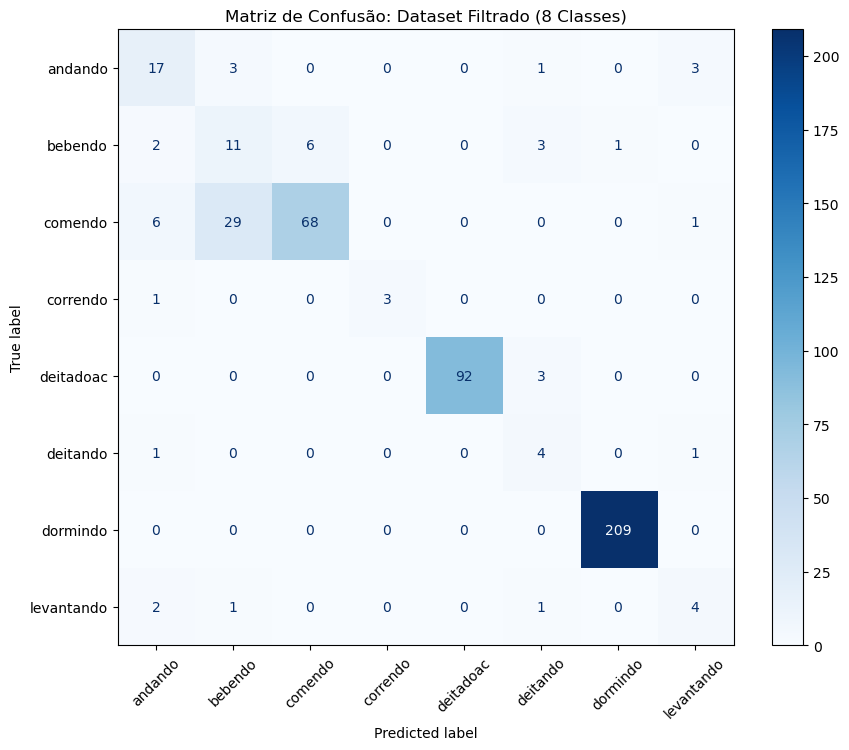

In [51]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. Preparação (X e y)
X = df_features.drop(['atividade', 'atividade_code'], axis=1, errors='ignore')
y = df_features['atividade']

# Garantimos que o LabelEncoder veja todas as classes atuais
le = LabelEncoder()
y_encoded = le.fit_transform(y)
classes_encontradas = le.classes_

# 2. Split com estratificação (Crucial para manter as 8 classes no treino e no teste)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.25, random_state=42, stratify=y_encoded
)

# 3. Escalonamento
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Treinamento
model = LogisticRegression(solver='saga', max_iter=2000, class_weight='balanced')
model.fit(X_train_scaled, y_train)

# 5. Previsão
y_pred = model.predict(X_test_scaled)

# 6. Relatório e Matriz
# Usamos labels=np.unique(y_test) para garantir que o report só tente nomear o que existe no teste
print("\nRelatório de Classificação Atualizado:\n")
labels_no_teste = np.unique(y_test)
target_names_ajustados = [classes_encontradas[i] for i in labels_no_teste]

print(classification_report(y_test, y_pred, target_names=target_names_ajustados))

# Matriz de Confusão
fig, ax = plt.subplots(figsize=(10, 8))
disp = ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, 
    display_labels=target_names_ajustados, 
    cmap=plt.cm.Blues, 
    xticks_rotation=45,
    ax=ax
)
plt.title('Matriz de Confusão: Dataset Filtrado (8 Classes)')
plt.show()

In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import skew, kurtosis
from scipy.signal import find_peaks
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# --- 1. FUNÇÃO DE EXTRAÇÃO DE CARACTERÍSTICAS ---
def extrair_features_completas(grupo):
    # Magnitude e FFT
    vm = np.sqrt(grupo['AX']**2 + grupo['AY']**2 + grupo['AZ']**2)
    fft_vals = np.abs(np.fft.rfft(vm - np.mean(vm)))
    sorted_f = np.sort(fft_vals)
    N_fft = len(fft_vals)
    
    # Correlação Cruzada (Relação entre os eixos)
    corr_xy = np.max(np.correlate(grupo['AX'], grupo['AY'], mode='full'))
    corr_xz = np.max(np.correlate(grupo['AX'], grupo['AZ'], mode='full'))
    
    # Dicionário de Features (22 variáveis)
    features = {
        'mean': vm.mean(), 'std': vm.std(), 'min': vm.min(), 'max': vm.max(),
        'max_min_diff': vm.max() - vm.min(), 'median': np.median(vm),
        'peak_count': len(find_peaks(vm, height=np.mean(vm))[0]),
        'skewness': skew(vm), 'kurtosis': kurtosis(vm), 'sma': np.sum(np.abs(vm)) / len(vm),
        'AV': np.mean(fft_vals), 'DC': fft_vals[0], 'SD_f': np.std(fft_vals),
        'MIN_f': np.min(fft_vals), 'MAX_f': np.max(fft_vals),
        'RG_f': np.max(fft_vals) - np.mean(fft_vals),
        'FQ': sorted_f[int(N_fft/4)] if N_fft > 4 else 0, 
        'SQ': sorted_f[int(N_fft/2)] if N_fft > 2 else 0,
        'RMS_f': np.sqrt(np.mean(fft_vals**2)), 'Median_f': np.median(fft_vals),
        'max_corr_xy': corr_xy, 'max_corr_xz': corr_xz
    }
    return pd.Series(features)

# --- 2. CARREGAMENTO DO DATASET RENOMEADO ---
caminho_dataset = r'C:\Users\franc\OneDrive\Desktop\dataset_treinamento_suinos.xlsx'
df_bruto = pd.read_excel(caminho_dataset)

print(f"Lendo dataset: {len(df_bruto)} linhas brutas.")

# Transformando dados brutos em Features (Agrupado por Janela)
df_features = df_bruto.groupby('janela').apply(extrair_features_completas, include_groups=False)
df_features['atividade'] = df_bruto.groupby('janela')['atividade'].first()

# --- 3. PREPARAÇÃO PARA O MODELO ---
X = df_features.drop('atividade', axis=1)
y = df_features['atividade']

le = LabelEncoder()
y_encoded = le.fit_transform(y)

# Divisão Treino/Teste (75%/25%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.25, random_state=42, stratify=y_encoded
)

# Escalonamento (Indispensável para SAGA)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# --- 4. TREINAMENTO DO MODELO FINAL ---
# Aumentamos iterações para garantir convergência total
model = LogisticRegression(solver='saga', max_iter=3000, class_weight='balanced')
model.fit(X_train_scaled, y_train)

# --- 5. RESULTADOS E MATRIZ ---
y_pred = model.predict(X_test_scaled)

print("\n" + "="*60)
print("RELATÓRIO DE CLASSIFICAÇÃO FINAL (DATASET FILTRADO)")
print("="*60)
print(classification_report(y_test, y_pred, target_names=le.classes_))

# Visualização da Matriz de Confusão
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, 
    display_labels=le.classes_, 
    cmap=plt.cm.Blues, 
    xticks_rotation=45,
    ax=ax
)
plt.title('Matriz de Confusão: Modelo Treinado com Sucessos')
plt.show()

In [ ]:
#Adicionado razão SMA2/SMA1 e delta do eixo z

In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import skew, kurtosis
from scipy.signal import find_peaks
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# --- 1. FUNÇÃO DE EXTRAÇÃO DE CARACTERÍSTICAS (VERSÃO RAZÃO DE AMPLITUDE) ---
def extrair_features_completas(grupo):
    # Magnitude (VM)
    vm = np.sqrt(grupo['AX']**2 + grupo['AY']**2 + grupo['AZ']**2)
    n_amostras = len(vm)
    meio = n_amostras // 2
    
    # --- NOVA MÉTRICA: RAZÃO DE AMPLITUDES (MA2/MA1) ---
    # Calculamos a média da amplitude (VM) em cada metade
    ma1 = np.mean(vm[:meio])
    ma2 = np.mean(vm[meio:])
    
    # Razão de Amplitude (Foco na mudança de intensidade de pico)
    razao_ma = ma2 / (ma1 + 1e-6)
    
    # Delta de Inclinação Z (Diferença entre o fim e o início do eixo Z)
    delta_z = grupo['AZ'].iloc[-10:].mean() - grupo['AZ'].iloc[:10].mean()
    
    # Jerk Máximo (Rapidez da mudança)
    jerk_max = np.max(np.abs(np.diff(vm)))

    # FFT (Domínio da Frequência)
    fft_vals = np.abs(np.fft.rfft(vm - np.mean(vm)))
    sorted_f = np.sort(fft_vals)
    N_fft = len(fft_vals)
    
    # Correlação Cruzada
    corr_xy = np.max(np.correlate(grupo['AX'], grupo['AY'], mode='full'))
    corr_xz = np.max(np.correlate(grupo['AX'], grupo['AZ'], mode='full'))
    
    # Dicionário de Features Consolidado
    features = {
        'mean': vm.mean(), 'std': vm.std(), 'min': vm.min(), 'max': vm.max(),
        'max_min_diff': vm.max() - vm.min(), 'median': np.median(vm),
        'peak_count': len(find_peaks(vm, height=np.mean(vm))[0]),
        'skewness': skew(vm), 'kurtosis': kurtosis(vm), 
        
        # Métricas de Transição Atualizadas
        'ma1': ma1,
        'ma2': ma2,
        'razao_ma': razao_ma,
        'delta_z': delta_z,
        'max_jerk': jerk_max,
        
        # Domínio da Frequência (FFT)
        'AV': np.mean(fft_vals), 'DC': fft_vals[0], 'SD_f': np.std(fft_vals),
        'MIN_f': np.min(fft_vals), 'MAX_f': np.max(fft_vals),
        'RG_f': np.max(fft_vals) - np.mean(fft_vals),
        'FQ': sorted_f[int(N_fft/4)] if N_fft > 4 else 0, 
        'SQ': sorted_f[int(N_fft/2)] if N_fft > 2 else 0,
        'RMS_f': np.sqrt(np.mean(fft_vals**2)), 'Median_f': np.median(fft_vals),
        
        # Dinâmica entre eixos
        'max_corr_xy': corr_xy, 'max_corr_xz': corr_xz
    }
    return pd.Series(features)

# --- 2. CARREGAMENTO E PROCESSAMENTO ---
caminho_dataset = r'C:\Users\franc\OneDrive\Desktop\dataset_treinamento_suinos.xlsx'
df_bruto = pd.read_excel(caminho_dataset)

df_features = df_bruto.groupby('janela').apply(extrair_features_completas, include_groups=False)
df_features['atividade'] = df_bruto.groupby('janela')['atividade'].first()

# --- 3. TREINAMENTO ---
X = df_features.drop('atividade', axis=1)
y = df_features['atividade']

le = LabelEncoder()
y_encoded = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.25, random_state=42, stratify=y_encoded
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LogisticRegression(solver='saga', max_iter=3000, class_weight='balanced')
model.fit(X_train_scaled, y_train)

# --- 4. RESULTADOS ---
y_pred = model.predict(X_test_scaled)

print("\n" + "="*60)
print("RELATÓRIO: RAZÃO DE AMPLITUDES (MA2/MA1) + DELTA Z")
print("="*60)
print(classification_report(y_test, y_pred, target_names=le.classes_))

# Matriz de Confusão
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=le.classes_, cmap='Blues', xticks_rotation=45, ax=ax)
plt.title('Matriz de Confusão: Razão de Amplitudes Médias')
plt.show()

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


              precision    recall  f1-score   support

     andando       0.77      0.57      0.65        30
     bebendo       0.71      0.75      0.73        20
     comendo       0.84      0.94      0.89        50
    correndo       0.50      1.00      0.67         4
   deitadoac       0.97      0.84      0.90       107
    deitando       0.23      0.60      0.33        10
    dormindo       0.98      0.95      0.96       211
  levantando       0.38      0.45      0.42        11

    accuracy                           0.87       443
   macro avg       0.67      0.76      0.69       443
weighted avg       0.90      0.87      0.88       443



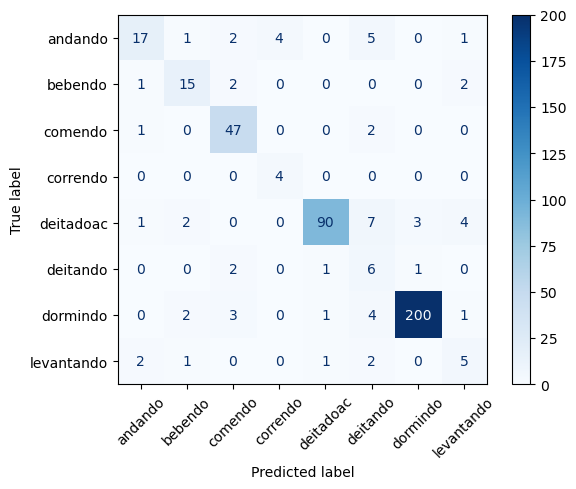

In [58]:
import pandas as pd
import numpy as np
from scipy.stats import skew, kurtosis
from scipy.signal import find_peaks
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# --- 1. FUNÇÃO DE EXTRAÇÃO SIMPLIFICADA E ROBUSTA ---
def extrair_features_completas(grupo):
    vm = np.sqrt(grupo['AX']**2 + grupo['AY']**2 + grupo['AZ']**2).values
    az = grupo['AZ'].values
    n = len(vm)
    meio = n // 2
    
    # 1. Diferença de Energia (RMS) entre as duas metades
    rms1 = np.sqrt(np.mean(vm[:meio]**2))
    rms2 = np.sqrt(np.mean(vm[meio:]**2))
    delta_rms = rms2 - rms1
    
    # 2. Mudança de Estática no Eixo Z (O salto do sensor)
    # Comparamos a média dos últimos 15 pontos com os primeiros 15
    mudanca_z = np.mean(az[-15:]) - np.mean(az[:15])
    
    # 3. Variância Acumulada (Diferencia movimento contínuo de explosão)
    var_total = np.var(vm)

    # FFT e Frequência
    fft_vals = np.abs(np.fft.rfft(vm - np.mean(vm)))
    
    features = {
        'mean': np.mean(vm), 
        'std': np.std(vm), 
        'max': np.max(vm),
        'delta_rms': delta_rms,     # Positivo no levantando, Negativo no deitando
        'mudanca_z': mudanca_z,     # Detecta a troca de posição do corpo
        'var_total': var_total,
        'peak_count': len(find_peaks(vm, height=np.mean(vm))[0]),
        'AV_f': np.mean(fft_vals),
        'MAX_f': np.max(fft_vals),
        # Dinâmica entre eixos (Sua métrica original que era boa)
        'corr_xz': np.max(np.correlate(grupo['AX'], grupo['AZ'], mode='full'))
    }
    return pd.Series(features)

# --- 2. EXECUÇÃO ---
caminho_dataset = r'C:\Users\franc\OneDrive\Desktop\dataset_treinamento_suinos.xlsx'
df_bruto = pd.read_excel(caminho_dataset)

df_features = df_bruto.groupby('janela').apply(extrair_features_completas, include_groups=False)
df_features['atividade'] = df_bruto.groupby('janela')['atividade'].first()

X = df_features.drop('atividade', axis=1)
y = df_features['atividade']

le = LabelEncoder()
y_encoded = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.25, random_state=42, stratify=y_encoded
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Aumentar levemente o peso do "levantando" pode ajudar se houver poucos dados
model = LogisticRegression(solver='saga', max_iter=3000, class_weight='balanced')
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

print(classification_report(y_test, y_pred, target_names=le.classes_))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=le.classes_, cmap='Blues', xticks_rotation=45)
plt.show()

In [ ]:
     andando       0.87      0.90      0.89        30
     bebendo       0.77      0.85      0.81        20
     comendo       0.92      0.94      0.93        50
    correndo       1.00      1.00      1.00         4
   deitadoac       0.98      0.86      0.92       107
    deitando       0.28      0.50      0.36        10
    dormindo       0.99      0.97      0.98       211
  levantando       0.38      0.55      0.44        11

Analisando Razão de Variância AC (VA2/VA1) para 33 janelas...


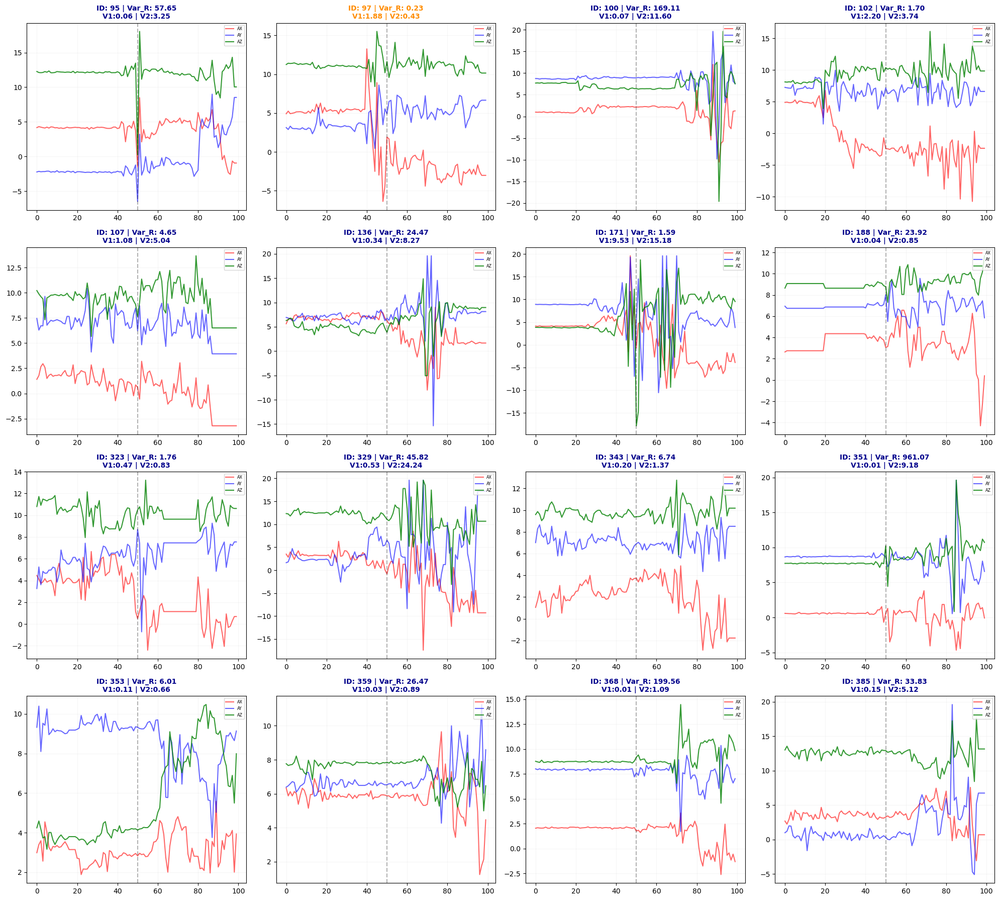

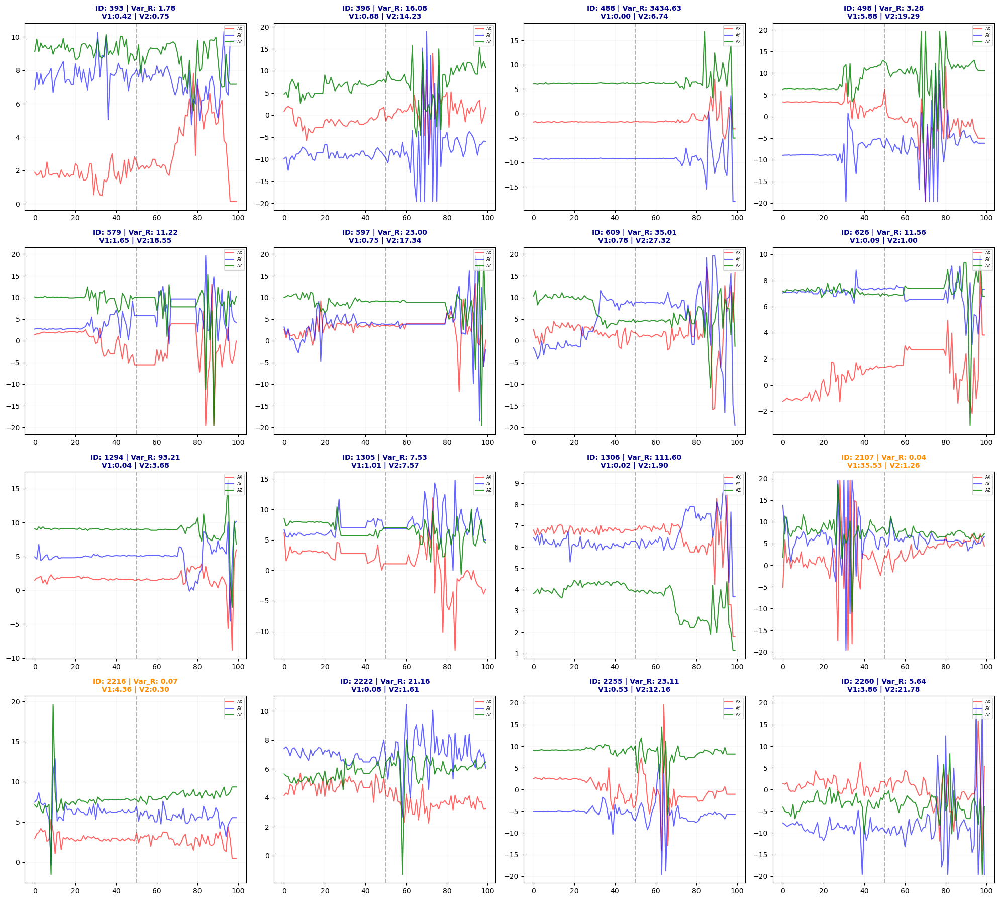

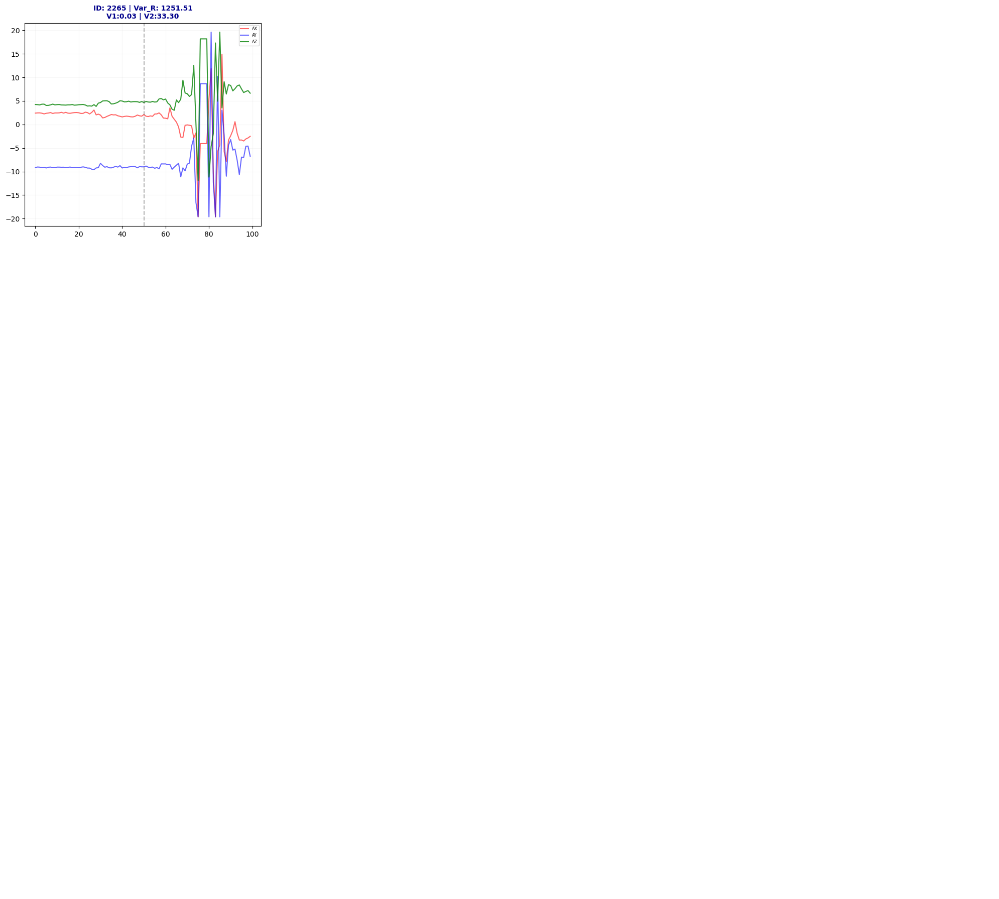

In [62]:
import matplotlib.pyplot as plt
from datetime import datetime
import math
import numpy as np

def exibir_na_tela_com_razao_variancia_ac(df_final, itens_por_pagina=16):
    # Filtra as janelas de levantando
    df_levantando = df_final[df_final['atividade'] == 'levantando']
    ids_unicos = df_levantando['janela'].unique()
    
    total_paginas = math.ceil(len(ids_unicos) / itens_por_pagina)
    print(f"Analisando Razão de Variância AC (VA2/VA1) para {len(ids_unicos)} janelas...")

    for n in range(1, total_paginas + 1):
        start_idx = (n - 1) * itens_por_pagina
        subset_ids = ids_unicos[start_idx : start_idx + itens_por_pagina]
        
        fig, axes = plt.subplots(4, 4, figsize=(20, 18))
        axes = axes.flatten()
        
        for i, id_janela in enumerate(subset_ids):
            bloco = df_levantando[df_levantando['janela'] == id_janela]
            
            # --- CÁLCULO DA VARIÂNCIA AC ---
            # 1. Magnitude do vetor
            vm = np.sqrt(bloco['AX']**2 + bloco['AY']**2 + bloco['AZ']**2).values
            
            # 2. Divide em duas metades
            meio = len(vm) // 2
            v1 = vm[:meio]
            v2 = vm[meio:]
            
            # 3. Variância AC (A variância por definição já ignora a média/gravidade)
            va1 = np.var(v1)
            va2 = np.var(v2)
            
            # 4. Razão de Variância (VA2 / VA1)
            razao_v = va2 / (va1 + 1e-6)
            # -------------------------------
            
            ts_segundos = (bloco['instante_tempo'].iloc[0] / 1000) + 10800
            data_hora = datetime.fromtimestamp(ts_segundos).strftime('%d/%m %H:%M:%S')
            
            axes[i].plot(bloco['AX'].values, label='AX', alpha=0.6, color='red')
            axes[i].plot(bloco['AY'].values, label='AY', alpha=0.6, color='blue')
            axes[i].plot(bloco['AZ'].values, label='AZ', alpha=0.8, color='green') # Destaque no Z
            
            axes[i].axvline(x=meio, color='black', linestyle='--', alpha=0.3)
            
            # Título com foco na Razão de Variância
            # Verde se a variância aumentou no final (estabilização/movimento)
            cor_titulo = 'darkblue' if razao_v > 1.0 else 'darkorange'
            axes[i].set_title(f"ID: {id_janela} | Var_R: {razao_v:.2f}\nV1:{va1:.2f} | V2:{va2:.2f}", 
                              fontsize=10, fontweight='bold', color=cor_titulo)
            
            axes[i].legend(fontsize='xx-small', loc='upper right')
            axes[i].grid(True, alpha=0.1)
        
        # Limpa eixos vazios
        for i in range(len(subset_ids), 16):
            axes[i].axis('off')
            
        plt.tight_layout()
        plt.show()

# Chamada para conferir os resultados visuais
exibir_na_tela_com_razao_variancia_ac(df_final)

Validando métricas extremas para 33 janelas de levantando...


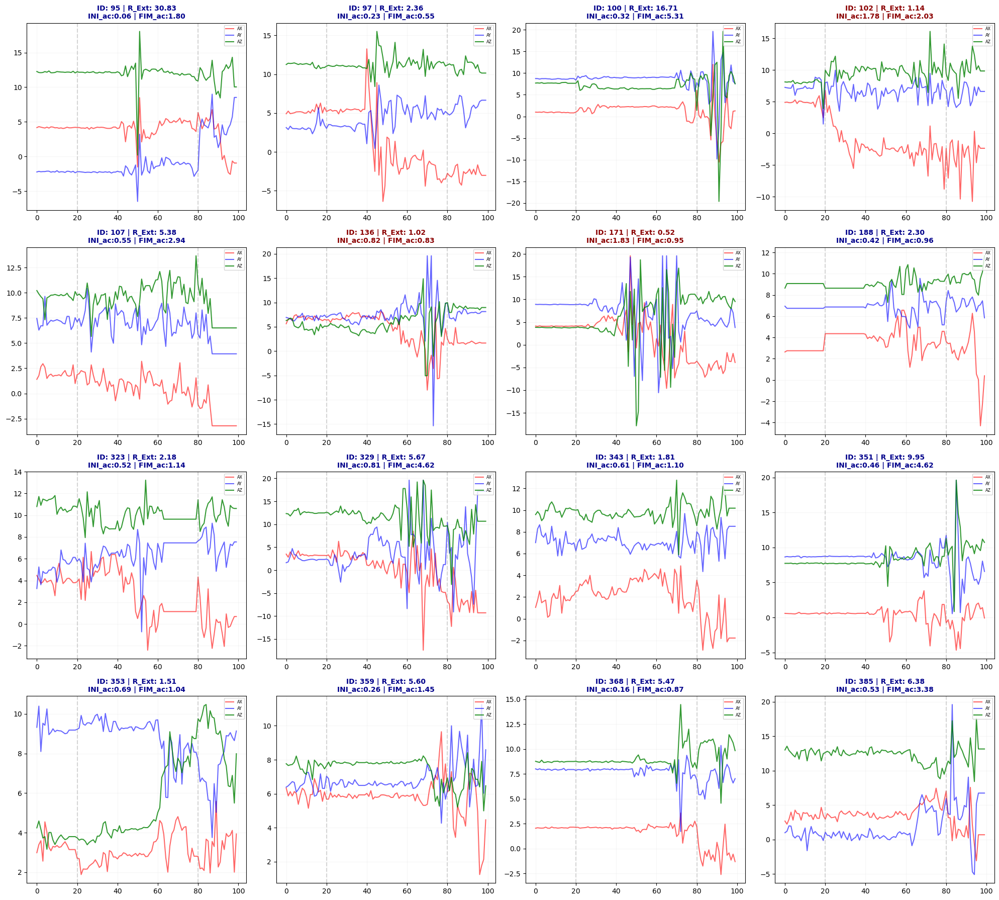

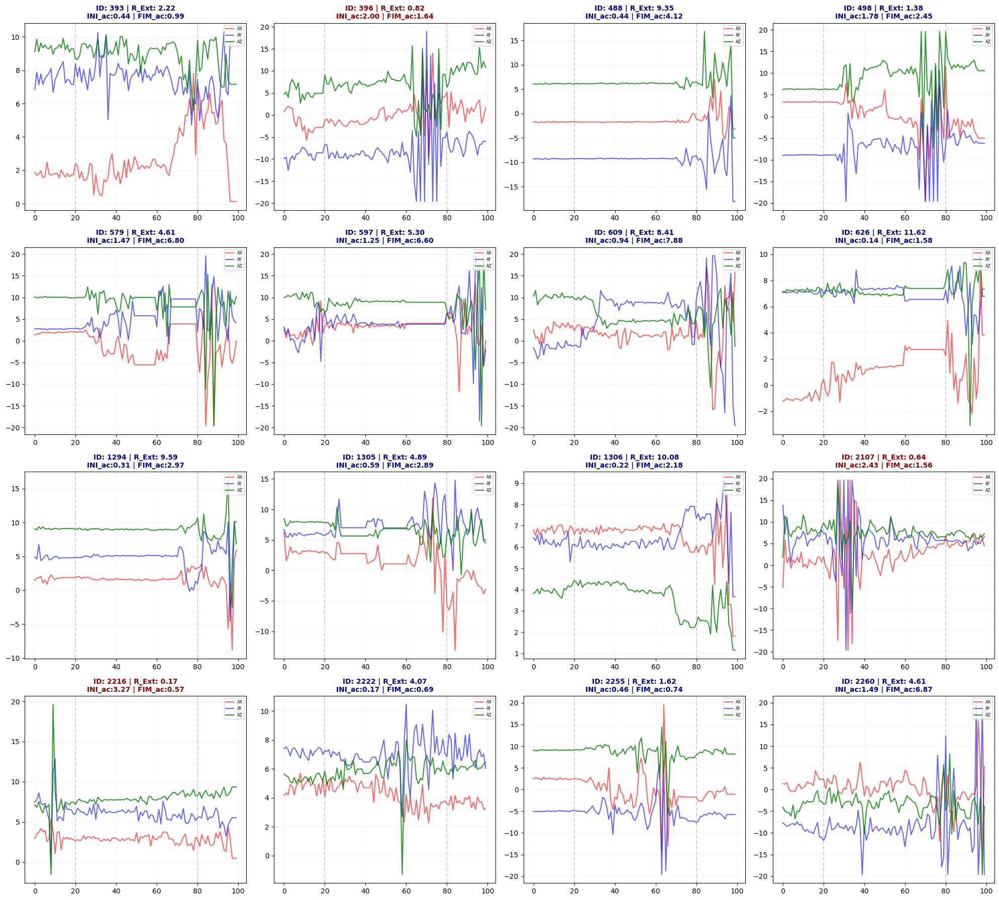

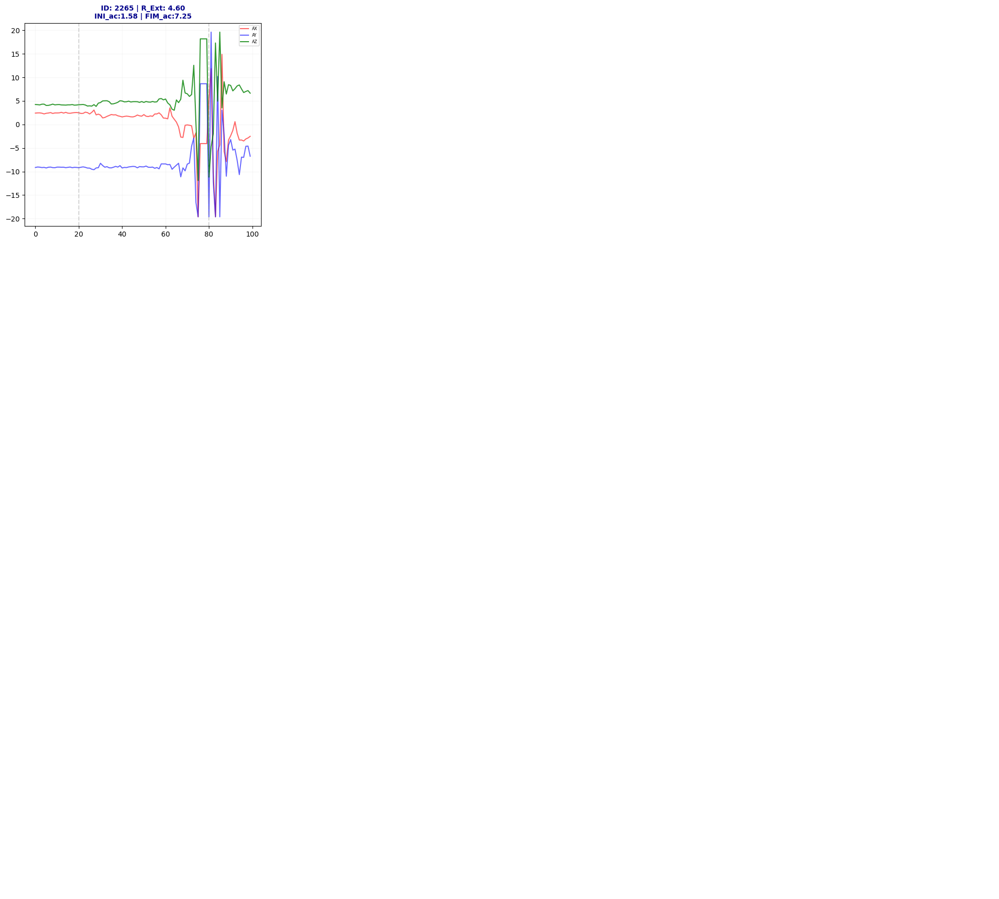

In [65]:
import matplotlib.pyplot as plt
from datetime import datetime
import math
import numpy as np

def exibir_na_tela_valida_transicao(df_final, itens_por_pagina=16):
    df_levantando = df_final[df_final['atividade'] == 'levantando']
    ids_unicos = df_levantando['janela'].unique()
    total_paginas = math.ceil(len(ids_unicos) / itens_por_pagina)
    print(f"Validando métricas extremas para {len(ids_unicos)} janelas de levantando...")

    for n in range(1, total_paginas + 1):
        start_idx = (n - 1) * itens_por_pagina
        subset_ids = ids_unicos[start_idx : start_idx + itens_por_pagina]
        fig, axes = plt.subplots(4, 4, figsize=(20, 18))
        axes = axes.flatten()
        
        for i, id_janela in enumerate(subset_ids):
            bloco = df_levantando[df_levantando['janela'] == id_janela]
            
            # --- CÁLCULO RMS EXTREMOS AC ---
            # 1. Magnitude e remoção da média (Sinal AC)
            vm = np.sqrt(bloco['AX']**2 + bloco['AY']**2 + bloco['AZ']**2).values
            vm_ac = vm - np.mean(vm)
            
            # 2. RMS das pontas (Início e Fim)
            # Pegamos os primeiros 20% e os últimos 20%
            n_pontos = len(vm_ac)
            ponta = int(n_pontos * 0.2)
            rms_ini_ac = np.sqrt(np.mean(vm_ac[:ponta]**2))
            rms_fim_ac = np.sqrt(np.mean(vm_ac[-ponta:]**2))
            
            # 3. Razão RMS Extremas (R_Ext)
            # Positivo se o final é mais agitado que o início
            razao_ext = rms_fim_ac / (rms_ini_ac + 1e-6)
            # -------------------------------
            
            ts_segundos = (bloco['instante_tempo'].iloc[0] / 1000) + 10800
            data_hora = datetime.fromtimestamp(ts_segundos).strftime('%d/%m %H:%M:%S')
            
            # Plotamos o sinal original para contexto
            axes[i].plot(bloco['AX'].values, label='AX', alpha=0.6, color='red')
            axes[i].plot(bloco['AY'].values, label='AY', alpha=0.6, color='blue')
            axes[i].plot(bloco['AZ'].values, label='AZ', alpha=0.8, color='green')
            
            # Linhas verticais para indicar as pontas
            axes[i].axvline(x=ponta, color='gray', linestyle='--', alpha=0.3)
            axes[i].axvline(x=n_pontos - ponta, color='gray', linestyle='--', alpha=0.3)
            
            cor_titulo = 'darkblue' if razao_ext > 1.2 else 'darkred'
            axes[i].set_title(f"ID: {id_janela} | R_Ext: {razao_ext:.2f}\nINI_ac:{rms_ini_ac:.2f} | FIM_ac:{rms_fim_ac:.2f}", 
                              fontsize=10, fontweight='bold', color=cor_titulo)
            axes[i].legend(fontsize='xx-small', loc='upper right')
            axes[i].grid(True, alpha=0.1)
            
        for i in range(len(subset_ids), 16):
            axes[i].axis('off')
        plt.tight_layout()
        plt.show()

# Chamada para rodar o gráfico
exibir_na_tela_valida_transicao(df_final)

In [66]:
def extrair_features_finais(grupo):
    # 1. Magnitude (VM)
    vm = np.sqrt(grupo['AX']**2 + grupo['AY']**2 + grupo['AZ']**2).values
    az = grupo['AZ'].values
    
    # 2. Remoção da Componente Gravitacional via Média Móvel (Janela de 5 pontos)
    # Isso isola a "oscilação" que você viu no ID 97
    vm_series = pd.Series(vm)
    vm_ac = (vm_series - vm_series.rolling(window=5, min_periods=1).mean()).values
    
    # 3. Métrica de Estabilização (Início vs Fim)
    n = len(vm_ac)
    ponta = int(n * 0.2) # 20% inicial e final
    v_ini = np.var(vm_ac[:ponta])
    v_fim = np.var(vm_ac[-ponta:])
    razao_var_ac = v_fim / (v_ini + 1e-6)
    
    # 4. Delta de Postura (Eixo Z)
    # Compara o patamar estável final com o inicial
    delta_z = np.mean(az[-15:]) - np.mean(az[:15])
    
    # 5. Energia Total do Movimento
    rms_ac_total = np.sqrt(np.mean(vm_ac**2))

    features = {
        'razao_var_ac': razao_var_ac,      # Captura a oscilação final (ID 97)
        'delta_z': delta_z,                # Captura a mudança de altura/postura
        'rms_ac_total': rms_ac_total,      # Intensidade do movimento
        'std_vm': np.std(vm),
        'max_vm': np.max(vm),
        'min_vm': np.min(vm),
        'kurtosis': kurtosis(vm),
        'skew': skew(vm),
        'max_f': np.max(np.abs(np.fft.rfft(vm_ac))) # Pico de frequência
    }
    return pd.Series(features)

Extraindo todas as 24 características...

Relatório Final (Híbrido - Todas as Features):
              precision    recall  f1-score   support

     andando       0.87      0.90      0.89        30
     bebendo       0.77      0.85      0.81        20
     comendo       0.92      0.94      0.93        50
    correndo       1.00      1.00      1.00         4
   deitadoac       0.98      0.86      0.92       107
    deitando       0.28      0.50      0.36        10
    dormindo       0.99      0.97      0.98       211
  levantando       0.38      0.55      0.44        11

    accuracy                           0.91       443
   macro avg       0.77      0.82      0.79       443
weighted avg       0.93      0.91      0.92       443



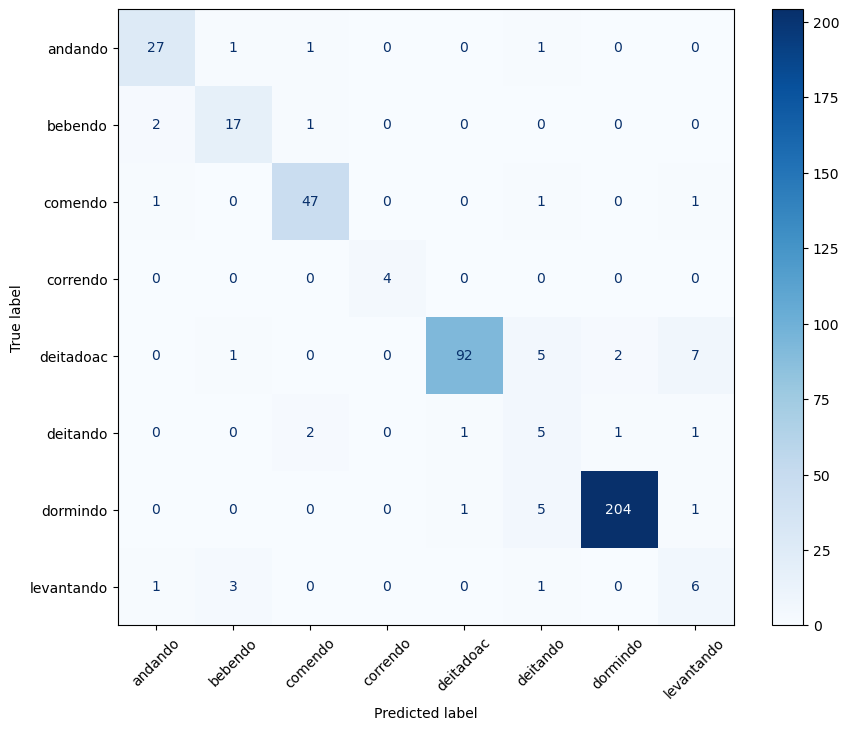

In [68]:
import pandas as pd
import numpy as np
from scipy.stats import skew, kurtosis
from scipy.signal import find_peaks
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# --- 1. FUNÇÃO DE EXTRAÇÃO COMPLETA (HÍBRIDA) ---
def extrair_features_hibridas(grupo):
    # Dados brutos
    ax = grupo['AX'].values
    ay = grupo['AY'].values
    az = grupo['AZ'].values
    vm = np.sqrt(ax**2 + ay**2 + az**2)
    n = len(vm)
    
    # --- NOVAS MÉTRICAS DE TRANSIÇÃO (O PULO DO GATO) ---
    # Variância AC das pontas (20% inicial vs 20% final) - Resolve ID 97
    ponta = int(n * 0.2)
    # Subtraímos a média local para focar na oscilação
    v_ini = np.var(vm[:ponta] - np.mean(vm[:ponta]))
    v_fim = np.var(vm[-ponta:] - np.mean(vm[-ponta:]))
    razao_var_ac = v_fim / (v_ini + 1e-6)
    
    # Delta de Postura (Eixo Z)
    delta_z = np.mean(az[-15:]) - np.mean(az[:15])

    # --- CARACTERÍSTICAS ORIGINAIS (PARA MANTER O RESTO DO DATASET) ---
    fft_vals = np.abs(np.fft.rfft(vm - np.mean(vm)))
    sorted_f = np.sort(fft_vals)
    N_fft = len(fft_vals)
    
    corr_xy = np.max(np.correlate(ax, ay, mode='full'))
    corr_xz = np.max(np.correlate(ax, az, mode='full'))

    features = {
        # Temporais
        'mean': np.mean(vm), 'std': np.std(vm), 'min': np.min(vm), 'max': np.max(vm),
        'max_min_diff': np.max(vm) - np.min(vm), 'median': np.median(vm),
        'peak_count': len(find_peaks(vm, height=np.mean(vm))[0]),
        'skewness': skew(vm), 'kurtosis': kurtosis(vm),
        
        # Frequência (FFT)
        'AV': np.mean(fft_vals), 'DC': fft_vals[0], 'SD_f': np.std(fft_vals),
        'MIN_f': np.min(fft_vals), 'MAX_f': np.max(fft_vals),
        'RG_f': np.max(fft_vals) - np.mean(fft_vals),
        'FQ': sorted_f[int(N_fft/4)] if N_fft > 4 else 0, 
        'SQ': sorted_f[int(N_fft/2)] if N_fft > 2 else 0,
        'RMS_f': np.sqrt(np.mean(fft_vals**2)), 'Median_f': np.median(fft_vals),
        
        # Correlações
        'max_corr_xy': corr_xy, 'max_corr_xz': corr_xz,
        
        # As Nossas Novas (O Diferencial)
        'razao_var_ac': razao_var_ac,
        'delta_z': delta_z
    }
    return pd.Series(features)

# --- 2. CARREGAMENTO E TREINO ---
caminho_dataset = r'C:\Users\franc\OneDrive\Desktop\dataset_treinamento_suinos.xlsx'
df_bruto = pd.read_excel(caminho_dataset)

print("Extraindo todas as 24 características...")
df_features = df_bruto.groupby('janela').apply(extrair_features_hibridas, include_groups=False)
df_features['atividade'] = df_bruto.groupby('janela')['atividade'].first()

X = df_features.drop('atividade', axis=1)
y = df_features['atividade']

le = LabelEncoder()
y_encoded = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.25, random_state=42, stratify=y_encoded)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# SAGA é ótimo para muitas variáveis
model = LogisticRegression(solver='saga', max_iter=5000, class_weight='balanced', C=0.6)
model.fit(X_train_scaled, y_train)

# --- 3. RESULTADOS ---
y_pred = model.predict(X_test_scaled)
print("\nRelatório Final (Híbrido - Todas as Features):")
print(classification_report(y_test, y_pred, target_names=le.classes_))

fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=le.classes_, cmap='Blues', xticks_rotation=45, ax=ax)
plt.show()

In [ ]:
Relatório de Classificação (Features AC + Lasso):
              precision    recall  f1-score   support

     andando       0.73      0.53      0.62        30
     bebendo       0.20      0.10      0.13        20
     comendo       0.69      0.86      0.77        50
    correndo       0.50      1.00      0.67         4
   deitadoac       0.97      0.92      0.94       107
    deitando       0.23      0.30      0.26        10
    dormindo       0.99      0.97      0.98       211
  levantando       0.25      0.45      0.32        11

    accuracy                           0.85       443
   macro avg       0.57      0.64      0.59       443
weighted avg       0.86      0.85      0.85       443

Iniciando extração de 15 características concatenadas...


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(



RELATÓRIO FINAL: SOLUÇÃO CONCATENADA (AC + DC)
              precision    recall  f1-score   support

     andando       0.67      0.53      0.59        30
     bebendo       0.23      0.15      0.18        20
     comendo       0.69      0.84      0.76        50
    correndo       0.80      1.00      0.89         4
   deitadoac       0.97      0.91      0.94       107
    deitando       0.23      0.30      0.26        10
    dormindo       0.99      0.98      0.98       211
  levantando       0.26      0.45      0.33        11

    accuracy                           0.85       443
   macro avg       0.61      0.65      0.62       443
weighted avg       0.86      0.85      0.85       443



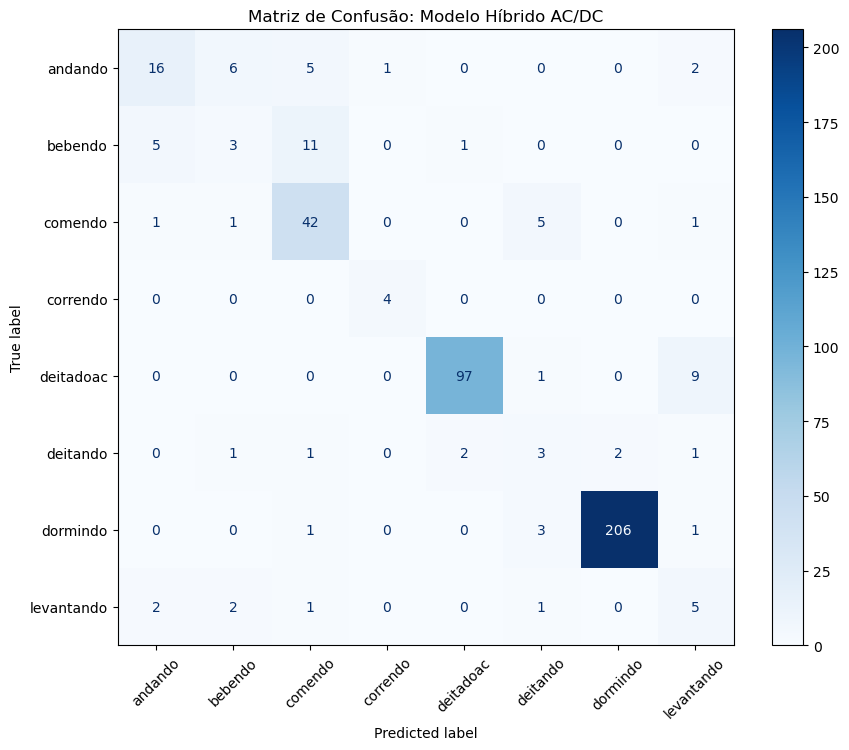

In [70]:
import pandas as pd
import numpy as np
from scipy.stats import skew, kurtosis
from scipy.signal import find_peaks
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# --- 1. FUNÇÃO DE EXTRAÇÃO DE CARACTERÍSTICAS CONCATENADA (AC + DC) ---
def extrair_features_completas(grupo):
    # Sinais Brutos
    ax, ay, az = grupo['AX'].values, grupo['AY'].values, grupo['AZ'].values
    vm = np.sqrt(ax**2 + ay**2 + az**2)
    n = len(vm)
    
    # --- COMPONENTE AC (Remoção da Gravidade) ---
    # Usamos o sinal subtraído da média para focar na oscilação pura
    vm_ac = vm - np.mean(vm)
    ax_ac = ax - np.mean(ax)
    az_ac = az - np.mean(az)
    
    # --- MÉTRICAS DE TRANSIÇÃO (O SEGREDO DO ID 97) ---
    ponta = int(n * 0.25)
    # Variância AC local nas extremidades (Fim vs Início)
    v_ini_ac = np.var(vm_ac[:ponta])
    v_fim_ac = np.var(vm_ac[-ponta:])
    razao_var_ac = v_fim_ac / (v_ini_ac + 1e-6)
    
    # Delta de Postura (Diferença de nível no eixo Z)
    delta_z = np.mean(az[-15:]) - np.mean(az[:15])

    # --- MÉTRICAS GLOBAIS / DC (Para Andando, Dormindo, Comendo) ---
    fft_vals = np.abs(np.fft.rfft(vm_ac))
    
    # Dicionário com o MIX de informações
    features = {
        # 1. Postura e Intensidade Bruta (DC)
        'mean_vm': np.mean(vm),
        'mean_az': np.mean(az),      # Crucial para saber se está em pé ou deitado
        'max_vm': np.max(vm),
        'std_vm': np.std(vm),
        'median_vm': np.median(vm),
        
        # 2. Dinâmica de Transição (AC e Pontas)
        'razao_var_ac': razao_var_ac, # Resolve o ID 97
        'delta_z': delta_z,           # Diferencia Levantando de Deitando
        'sma_ac': np.mean(np.abs(vm_ac)),
        'energy_ac': np.mean(vm_ac**2),
        
        # 3. Ritmo e Frequência (FFT e Estatísticas)
        'max_f': np.max(fft_vals),
        'mean_f': np.mean(fft_vals),
        'skewness': skew(vm),
        'kurtosis': kurtosis(vm),
        
        # 4. Interação entre Eixos (Andando/Correndo)
        'max_corr_xz': np.max(np.correlate(ax_ac, az_ac, mode='full'))
    }
    return pd.Series(features)

# --- 2. CARREGAMENTO E PROCESSAMENTO ---
caminho_dataset = r'C:\Users\franc\OneDrive\Desktop\dataset_treinamento_suinos.xlsx'
df_bruto = pd.read_excel(caminho_dataset)

print("Iniciando extração de 15 características concatenadas...")
df_features = df_bruto.groupby('janela').apply(extrair_features_completas, include_groups=False)
df_features['atividade'] = df_bruto.groupby('janela')['atividade'].first()

# --- 3. TREINAMENTO DO MODELO ---
X = df_features.drop('atividade', axis=1)
y = df_features['atividade']

le = LabelEncoder()
y_encoded = le.fit_transform(y)

# Stratify mantém o equilíbrio das 8 classes
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.25, random_state=42, stratify=y_encoded
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Usamos RIDGE (Penalty L2) para dar estabilidade e lidar com colinearidade
model = LogisticRegression(
    penalty='l2', 
    solver='saga', 
    C=1.0, 
    class_weight='balanced', 
    max_iter=10000,
    random_state=42
)
model.fit(X_train_scaled, y_train)

# --- 4. RESULTADOS E MATRIZ ---
y_pred = model.predict(X_test_scaled)

print("\n" + "="*60)
print("RELATÓRIO FINAL: SOLUÇÃO CONCATENADA (AC + DC)")
print("="*60)
print(classification_report(y_test, y_pred, target_names=le.classes_))

fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, 
    display_labels=le.classes_, 
    cmap='Blues', 
    xticks_rotation=45,
    ax=ax
)
plt.title('Matriz de Confusão: Modelo Híbrido AC/DC')
plt.show()


=== RANKING DE CARACTERÍSTICAS SELECIONADAS PELO LASSO ===
         Feature  Importancia
7         sma_ac     2.169160
5   razao_var_ac     1.045466
10        mean_f     0.935365
8      energy_ac     0.830322
1        mean_az     0.828364
4      median_vm     0.640040
13   max_corr_xz     0.559097
0        mean_vm     0.473277
12      kurtosis     0.345100
3         std_vm     0.314565
11      skewness     0.233291
2         max_vm     0.231857
6        delta_z     0.179880
9          max_f     0.131474

Relatório de Classificação com Seleção Lasso:
              precision    recall  f1-score   support

     andando       0.70      0.53      0.60        30
     bebendo       0.25      0.10      0.14        20
     comendo       0.65      0.80      0.71        50
    correndo       0.57      1.00      0.73         4
   deitadoac       0.98      0.89      0.93       107
    deitando       0.20      0.30      0.24        10
    dormindo       0.99      0.98      0.98       211
  levantan

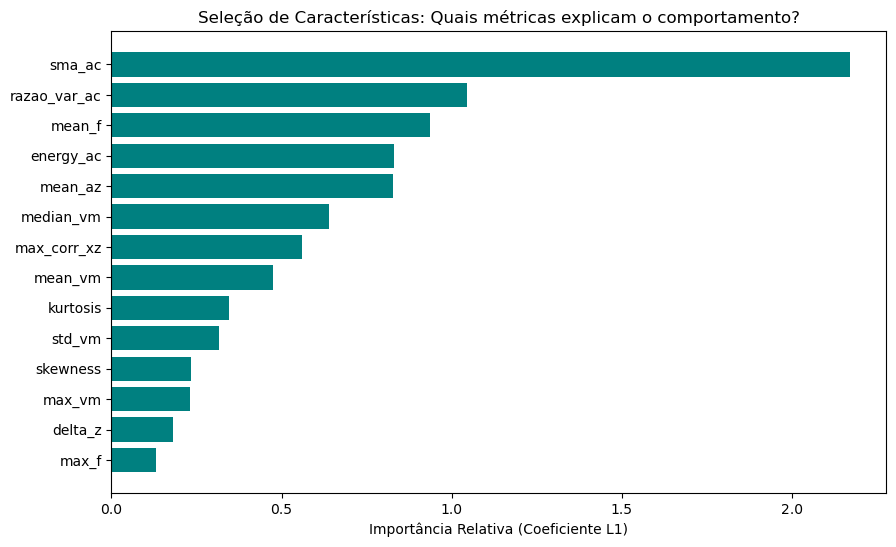

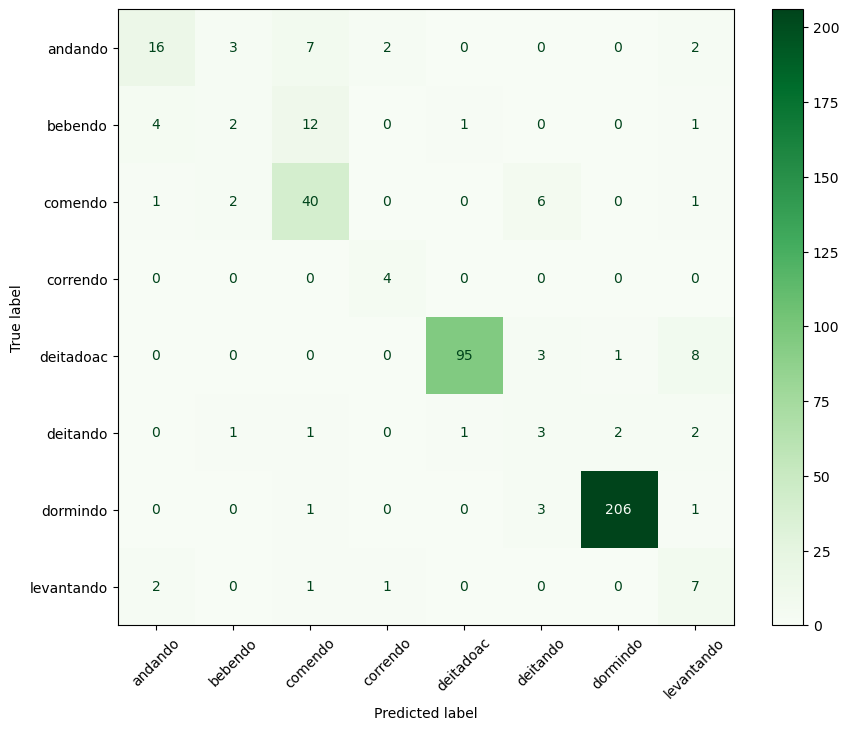

Extraindo características híbridas...

RELATÓRIO DE PERFORMANCE: LASSO + AC/DC
              precision    recall  f1-score   support

     andando       0.67      0.60      0.63        30
     bebendo       0.33      0.15      0.21        20
     comendo       0.68      0.80      0.73        50
    correndo       0.80      1.00      0.89         4
   deitadoac       0.97      0.92      0.94       107
    deitando       0.23      0.30      0.26        10
    dormindo       0.99      0.98      0.98       211
  levantando       0.33      0.64      0.44        11

    accuracy                           0.86       443
   macro avg       0.63      0.67      0.64       443
weighted avg       0.86      0.86      0.86       443



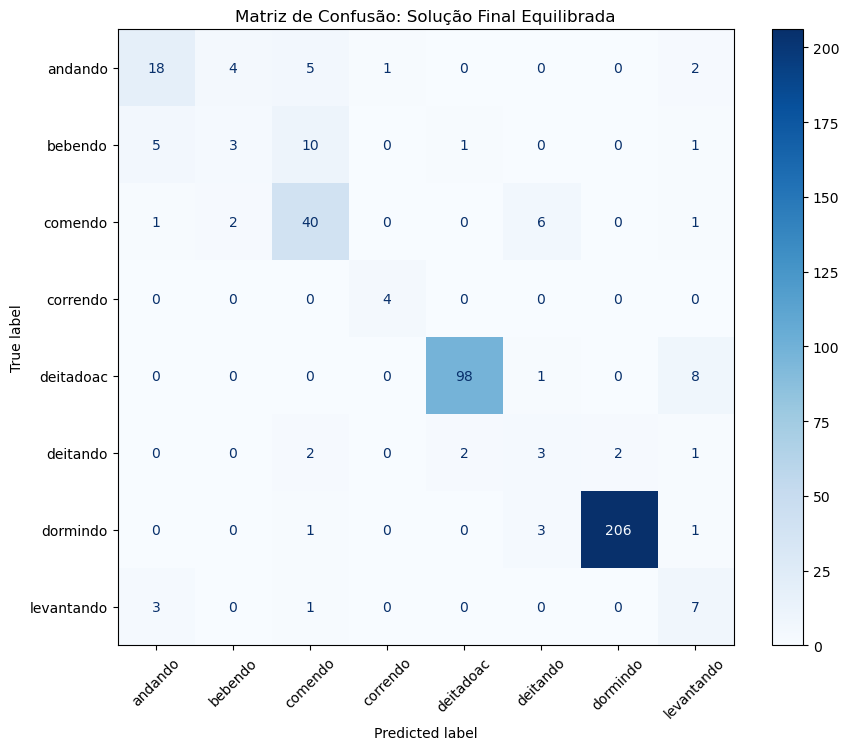


Ranking de Importância das Features:
sma_ac          3.351275
razao_var_ac    2.056431
mean_az         1.344008
energy_ac       1.300186
mean_f          1.272937
max_corr_xz     0.877458
max_vm          0.816387
mean_vm         0.770156
median_vm       0.755764
max_f           0.740580
std_vm          0.729003
skewness        0.453420
kurtosis        0.400105
delta_z         0.312507
dtype: float64


In [72]:
import pandas as pd
import numpy as np
from scipy.stats import skew, kurtosis
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# --- 1. FUNÇÃO DE EXTRAÇÃO DE CARACTERÍSTICAS (AC + DC CONCATENADA) ---
def extrair_features_finais(grupo):
    # Sinais Brutos
    ax, ay, az = grupo['AX'].values, grupo['AY'].values, grupo['AZ'].values
    vm = np.sqrt(ax**2 + ay**2 + az**2)
    n = len(vm)
    
    # --- COMPONENTE AC (Remoção da Gravidade) ---
    vm_ac = vm - np.mean(vm)
    ax_ac = ax - np.mean(ax)
    az_ac = az - np.mean(az)
    
    # --- MÉTRICAS DE TRANSIÇÃO (O SEGREDO DO ID 97) ---
    # Focamos na variância das extremidades (25% inicial vs 25% final)
    ponta = int(n * 0.25)
    v_ini_ac = np.var(vm_ac[:ponta])
    v_fim_ac = np.var(vm_ac[-ponta:])
    razao_var_ac = v_fim_ac / (v_ini_ac + 1e-6)
    
    # Delta de Postura (Diferença de nível no eixo Z)
    delta_z = np.mean(az[-15:]) - np.mean(az[:15])

    # --- MÉTRICAS GLOBAIS E FREQUÊNCIA ---
    fft_vals = np.abs(np.fft.rfft(vm_ac))
    
    features = {
        # Domínio do Tempo - Postura e Intensidade
        'mean_vm': np.mean(vm),
        'mean_az': np.mean(az),      # Crucial para Andando vs Deitado
        'max_vm': np.max(vm),
        'std_vm': np.std(vm),
        'median_vm': np.median(vm),
        
        # Domínio do Tempo - Dinâmica AC
        'razao_var_ac': razao_var_ac, # Alta importância no Lasso (ID 97)
        'delta_z': delta_z,           # Diferencia Levantando/Deitando
        'sma_ac': np.mean(np.abs(vm_ac)),
        'energy_ac': np.mean(vm_ac**2),
        'kurtosis': kurtosis(vm),
        'skewness': skew(vm),
        
        # Domínio da Frequência e Correlação
        'max_f': np.max(fft_vals),
        'mean_f': np.mean(fft_vals),
        'max_corr_xz': np.max(np.correlate(ax_ac, az_ac, mode='full'))
    }
    return pd.Series(features)

# --- 2. CARREGAMENTO E PROCESSAMENTO ---
caminho_dataset = r'C:\Users\franc\OneDrive\Desktop\dataset_treinamento_suinos.xlsx'
df_bruto = pd.read_excel(caminho_dataset)

print("Extraindo características híbridas...")
df_features = df_bruto.groupby('janela').apply(extrair_features_finais, include_groups=False)
df_features['atividade'] = df_bruto.groupby('janela')['atividade'].first()

# --- 3. PREPARAÇÃO PARA O MODELO ---
X = df_features.drop('atividade', axis=1)
y = df_features['atividade']

le = LabelEncoder()
y_encoded = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.25, random_state=42, stratify=y_encoded
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# --- 4. MODELO LASSO EQUILIBRADO (L1) ---
# C=1.0 permite que as métricas rítmicas (Andando) sobrevivam à penalidade
model = LogisticRegression(
    penalty='l1', 
    solver='saga', 
    C=1.0, 
    class_weight='balanced', 
    max_iter=20000,
    random_state=42
)
model.fit(X_train_scaled, y_train)

# --- 5. VISUALIZAÇÃO DE RESULTADOS ---
y_pred = model.predict(X_test_scaled)

print("\n" + "="*60)
print("RELATÓRIO DE PERFORMANCE: LASSO + AC/DC")
print("="*60)
print(classification_report(y_test, y_pred, target_names=le.classes_))

# Plotagem da Matriz de Confusão
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, 
    display_labels=le.classes_, 
    cmap='Blues', 
    xticks_rotation=45,
    ax=ax
)
plt.title('Matriz de Confusão: Solução Final Equilibrada')
plt.show()

# Ranking de Importância Final
coefs = np.abs(model.coef_).mean(axis=0)
importancia = pd.Series(coefs, index=X.columns).sort_values(ascending=False)
print("\nRanking de Importância das Features:")
print(importancia)

Extraindo o set completo de 24 características...

Relatório Final (Random Forest + Todas as 24 Features):
              precision    recall  f1-score   support

     andando       0.69      0.73      0.71        30
     bebendo       0.46      0.30      0.36        20
     comendo       0.67      0.82      0.74        50
    correndo       0.80      1.00      0.89         4
   deitadoac       0.94      0.97      0.95       107
    deitando       0.75      0.30      0.43        10
    dormindo       0.99      1.00      0.99       211
  levantando       0.75      0.27      0.40        11

    accuracy                           0.89       443
   macro avg       0.76      0.67      0.68       443
weighted avg       0.88      0.89      0.88       443



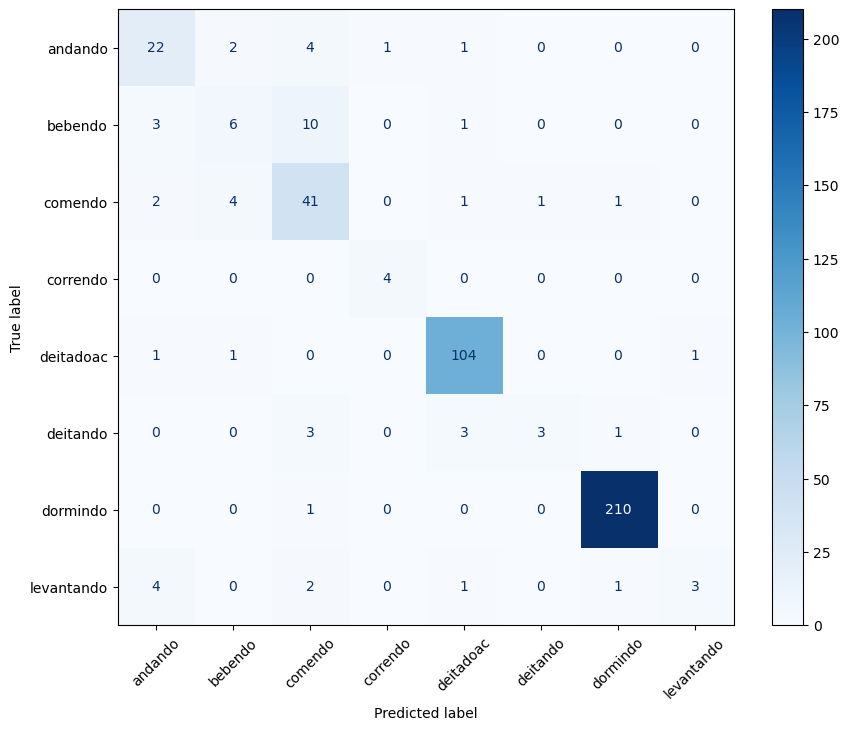


Top 10 Features no Random Forest:
razao_var_ac    0.080679
max             0.069773
median          0.062372
mean            0.062122
SQ              0.054213
AV              0.051781
min             0.049733
max_corr_xz     0.047612
max_corr_xy     0.046404
Median_f        0.046157
dtype: float64


In [76]:
import pandas as pd
import numpy as np
from scipy.stats import skew, kurtosis
from scipy.signal import find_peaks
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# --- 1. FUNÇÃO DE EXTRAÇÃO COMPLETA (MÉTRICAS CLÁSSICAS + NOVAS) ---
def extrair_features_totais(grupo):
    # Sinais Brutos
    ax, ay, az = grupo['AX'].values, grupo['AY'].values, grupo['AZ'].values
    vm = np.sqrt(ax**2 + ay**2 + az**2)
    n = len(vm)
    
    # Componente AC (Remoção da componente DC/Gravidade para FFT e Oscilação)
    vm_ac = vm - np.mean(vm)
    
    # --- Frequência (FFT) ---
    fft_vals = np.abs(np.fft.rfft(vm_ac))
    sorted_f = np.sort(fft_vals)
    N_fft = len(fft_vals)
    
    # --- Correlações ---
    corr_xy = np.max(np.correlate(ax - np.mean(ax), ay - np.mean(ay), mode='full'))
    corr_xz = np.max(np.correlate(ax - np.mean(ax), az - np.mean(az), mode='full'))

    # --- Nossas Métricas de Transição (O Pulo do Gato para ID 97) ---
    ponta = int(n * 0.25)
    v_ini_ac = np.var(vm_ac[:ponta])
    v_fim_ac = np.var(vm_ac[-ponta:])
    razao_var_ac = v_fim_ac / (v_ini_ac + 1e-6)
    delta_z = np.mean(az[-15:]) - np.mean(az[:15])

    features = {
        # --- Temporais (Estatística Descritiva) ---
        'mean': np.mean(vm), 
        'std': np.std(vm), 
        'min': np.min(vm), 
        'max': np.max(vm),
        'max_min_diff': np.max(vm) - np.min(vm), 
        'median': np.median(vm),
        'peak_count': len(find_peaks(vm, height=np.mean(vm))[0]),
        'skewness': skew(vm), 
        'kurtosis': kurtosis(vm),
        
        # --- Frequência (Análise Espectral FFT) ---
        'AV': np.mean(fft_vals), 
        'DC': fft_vals[0], 
        'SD_f': np.std(fft_vals),
        'MIN_f': np.min(fft_vals), 
        'MAX_f': np.max(fft_vals),
        'RG_f': np.max(fft_vals) - np.mean(fft_vals),
        'FQ': sorted_f[int(N_fft/4)] if N_fft > 4 else 0, 
        'SQ': sorted_f[int(N_fft/2)] if N_fft > 2 else 0,
        'RMS_f': np.sqrt(np.mean(fft_vals**2)), 
        'Median_f': np.median(fft_vals),
        
        # --- Relação entre Eixos e Transições ---
        'max_corr_xy': corr_xy, 
        'max_corr_xz': corr_xz,
        'razao_var_ac': razao_var_ac,
        'delta_z': delta_z
    }
    return pd.Series(features)

# --- 2. CARREGAMENTO E PROCESSAMENTO ---
caminho_dataset = r'C:\Users\franc\OneDrive\Desktop\dataset_treinamento_suinos.xlsx'
df_bruto = pd.read_excel(caminho_dataset)

print("Extraindo o set completo de 24 características...")
df_features = df_bruto.groupby('janela').apply(extrair_features_totais, include_groups=False)
df_features['atividade'] = df_bruto.groupby('janela')['atividade'].first()

X = df_features.drop('atividade', axis=1)
y = df_features['atividade']
le = LabelEncoder()
y_encoded = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.25, random_state=42, stratify=y_encoded
)

# --- 3. RANDOM FOREST COM HIPERPARÂMETROS OTIMIZADOS ---
model_rf = RandomForestClassifier(
    n_estimators=500,              # Mais árvores para estabilizar a predição
    max_depth=None,                # Deixa as árvores crescerem para captar nuances
    class_weight='balanced_subsample', # Essencial para o "Levantando"
    random_state=42,
    n_jobs=-1
)
model_rf.fit(X_train, y_train)

# --- 4. RESULTADOS ---
y_pred = model_rf.predict(X_test)

print("\nRelatório Final (Random Forest + Todas as 24 Features):")
print(classification_report(y_test, y_pred, target_names=le.classes_))

# Matriz de Confusão
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=le.classes_, cmap='Blues', xticks_rotation=45, ax=ax
)
plt.show()

# Ranking de Importância (Feature Importance)
importancias = pd.Series(model_rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print("\nTop 10 Features no Random Forest:")
print(importancias.head(10))

Extraindo features das janelas...


C:\Users\franc\AppData\Local\Temp\ipykernel_25944\2959234384.py:32: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_features = df_final.groupby('janela').apply(extrair_features).reset_index()


Iniciando Validação Cruzada com Random Forest...

DESEMPENHO MÉDIO RANDOM FOREST: 0.7800
Desvio Padrão: 0.0040

Relatório de Classificação:

              precision    recall  f1-score   support

     andando       0.58      0.66      0.62       462
     bebendo       0.37      0.14      0.20       338
     comendo       0.79      0.92      0.85      2427
    correndo       0.76      0.74      0.75        50
   deitadoac       0.70      0.63      0.66      1185
    deitando       0.29      0.10      0.15       145
    dormindo       0.91      0.94      0.92      2290
  levantando       0.10      0.04      0.05       193

    accuracy                           0.78      7090
   macro avg       0.56      0.52      0.53      7090
weighted avg       0.75      0.78      0.76      7090



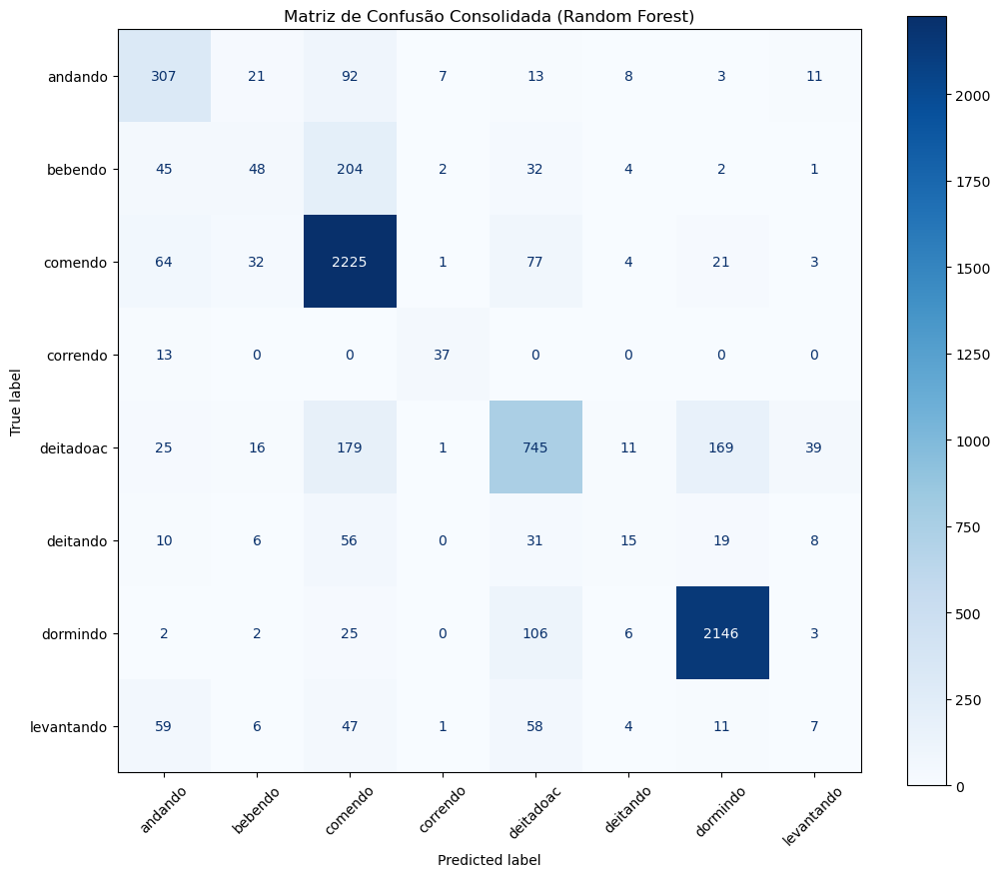


Top Features que mais ajudaram o modelo:
std             0.152672
max_min_diff    0.119475
min             0.108894
kurtosis        0.106725
max             0.098670
median          0.091288
sma             0.085860
mean            0.085308
skewness        0.077204
peak_count      0.073904
dtype: float64


In [35]:
import pandas as pd
import numpy as np
from scipy.stats import skew, kurtosis
from scipy.signal import find_peaks
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score
import matplotlib.pyplot as plt

# --- 1. FUNÇÃO DE EXTRAÇÃO SOLICITADA ---
def extrair_features(grupo):
    vm = np.sqrt(grupo['AX']**2 + grupo['AY']**2 + grupo['AZ']**2)
    peaks, _ = find_peaks(vm, height=np.mean(vm))
    
    return pd.Series({
        'mean': vm.mean(),
        'std': vm.std(),
        'min': vm.min(),
        'max': vm.max(),
        'max_min_diff': vm.max() - vm.min(),
        'median': np.median(vm),
        'peak_count': len(peaks),
        'skewness': skew(vm),
        'kurtosis': kurtosis(vm),
        'sma': np.sum(np.abs(vm)) / len(vm)
    })

# --- 2. PROCESSAMENTO E UNIÃO ---
print("Extraindo features das janelas...")
# Aplicando a função
df_features = df_final.groupby('janela').apply(extrair_features).reset_index()

# Garantindo que a 'atividade' seja anexada corretamente para evitar KeyError
atividades = df_final.groupby('janela')['atividade'].first().reset_index()
df_ml = pd.merge(df_features, atividades, on='janela')

# Limpeza de possíveis valores nulos
df_ml = df_ml.dropna()

# --- 3. PREPARAÇÃO PARA O MODELO ---
X = df_ml.drop(columns=['janela', 'atividade'])
y = df_ml['atividade']

le = LabelEncoder()
y_encoded = le.fit_transform(y)

# --- 4. RANDOM FOREST COM K-FOLD (5 Folds) ---
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
modelo_rf = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)

y_true_total = []
y_pred_total = []
scores = []

print("Iniciando Validação Cruzada com Random Forest...")

for train_index, test_index in kf.split(X, y_encoded):
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y_encoded[train_index], y_encoded[test_index]
    
    # Treino
    modelo_rf.fit(X_train, y_train)
    
    # Previsão
    y_pred = modelo_rf.predict(X_test)
    
    # Armazenar resultados
    y_true_total.extend(y_test)
    y_pred_total.extend(y_pred)
    scores.append(accuracy_score(y_test, y_pred))

# --- 5. RESULTADOS CONSOLIDADOS ---
print("\n" + "="*40)
print(f"DESEMPENHO MÉDIO RANDOM FOREST: {np.mean(scores):.4f}")
print(f"Desvio Padrão: {np.std(scores):.4f}")
print("="*40)

print("\nRelatório de Classificação:\n")
print(classification_report(y_true_total, y_pred_total, target_names=le.classes_))

# --- 6. MATRIZ DE CONFUSÃO ---
fig, ax = plt.subplots(figsize=(12, 10))
disp = ConfusionMatrixDisplay.from_predictions(
    y_true_total, y_pred_total, 
    display_labels=le.classes_, 
    cmap='Blues', 
    xticks_rotation=45,
    ax=ax
)
plt.title('Matriz de Confusão Consolidada (Random Forest)')
plt.show()

# --- 7. IMPORTÂNCIA DAS VARIÁVEIS (BÔNUS DO RF) ---
importancias = pd.Series(modelo_rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print("\nTop Features que mais ajudaram o modelo:")
print(importancias)

Extraindo features das janelas...


C:\Users\franc\AppData\Local\Temp\ipykernel_25944\4162032154.py:31: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_features = df_final.groupby('janela').apply(extrair_features).reset_index()
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Iniciando Validação Cruzada com Regressão Logística...


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in versio


DESEMPENHO MÉDIO REGRESSÃO LOGÍSTICA: 0.6656
Desvio Padrão: 0.0093

Relatório de Classificação:

              precision    recall  f1-score   support

     andando       0.57      0.50      0.53       462
     bebendo       0.17      0.30      0.22       338
     comendo       0.85      0.72      0.78      2427
    correndo       0.49      0.90      0.63        50
   deitadoac       0.64      0.38      0.47      1185
    deitando       0.10      0.31      0.15       145
    dormindo       0.81      0.91      0.86      2290
  levantando       0.10      0.12      0.11       193

    accuracy                           0.67      7090
   macro avg       0.47      0.52      0.47      7090
weighted avg       0.71      0.67      0.68      7090



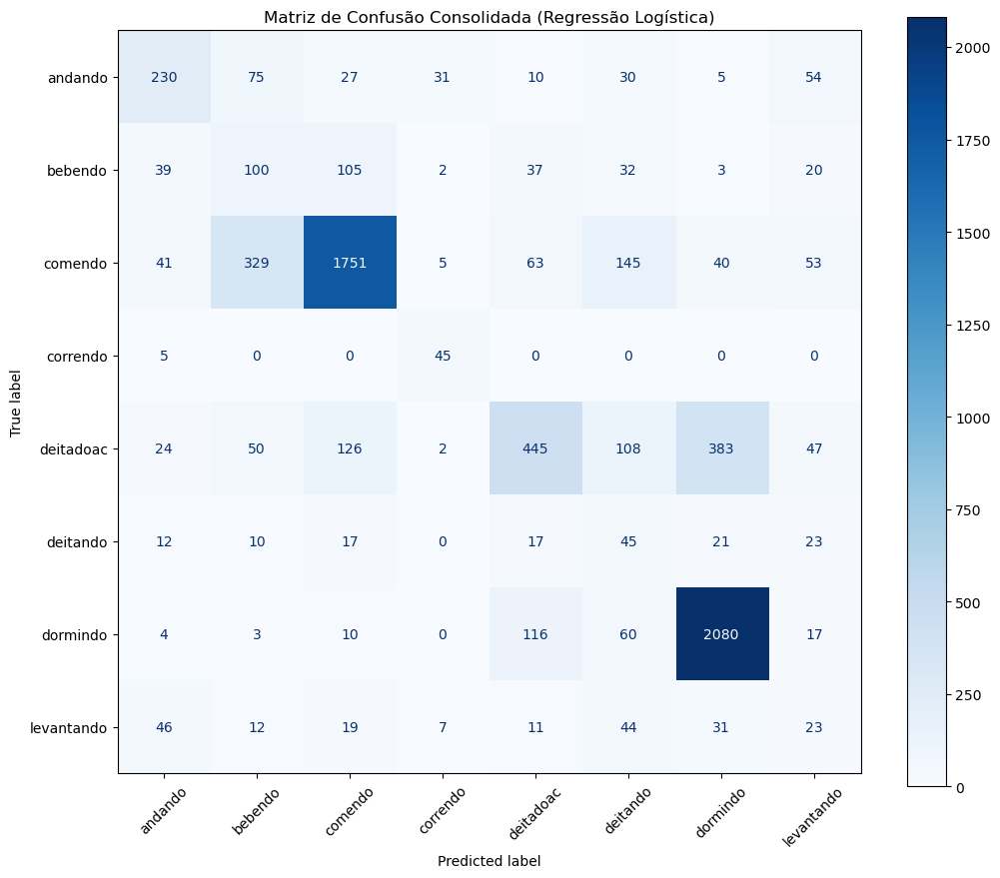

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(



Coeficientes da Regressão Logística por classe:
                mean       std       min       max  max_min_diff    median  \
andando    -0.209205  1.497931 -0.484651 -0.434269     -0.193284  0.815095   
bebendo    -0.254665  1.284234 -0.214166 -0.331126     -0.196973  0.685800   
comendo    -0.941515  3.064831 -0.296363 -1.147619     -0.824999  1.610535   
correndo   -0.176674  2.031574 -0.981581 -0.049206      0.273890  0.619020   
deitadoac   0.827141 -1.811873  0.430892  0.407778      0.189216 -1.363476   
deitando    0.477013 -1.467439 -1.010214 -0.079549      0.258715 -0.149146   
dormindo   -0.456888 -4.905439  3.159634  1.886298      0.502957 -1.414356   
levantando  0.734793  0.306181 -0.603552 -0.252307     -0.009523 -0.803472   

            peak_count  skewness  kurtosis       sma  
andando      -0.419368  0.644762 -0.447676 -0.209205  
bebendo       0.021991  0.041545 -0.079896 -0.254665  
comendo       1.169513  0.287330  0.035436 -0.941515  
correndo      0.284245 -0.08

In [36]:
import pandas as pd
import numpy as np
from scipy.stats import skew, kurtosis
from scipy.signal import find_peaks
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, accuracy_score
import matplotlib.pyplot as plt

# --- 1. FUNÇÃO DE EXTRAÇÃO SOLICITADA ---
def extrair_features(grupo):
    vm = np.sqrt(grupo['AX']**2 + grupo['AY']**2 + grupo['AZ']**2)
    peaks, _ = find_peaks(vm, height=np.mean(vm))
    
    return pd.Series({
        'mean': vm.mean(),
        'std': vm.std(),
        'min': vm.min(),
        'max': vm.max(),
        'max_min_diff': vm.max() - vm.min(),
        'median': np.median(vm),
        'peak_count': len(peaks),
        'skewness': skew(vm),
        'kurtosis': kurtosis(vm),
        'sma': np.sum(np.abs(vm)) / len(vm)
    })

# --- 2. PROCESSAMENTO E UNIÃO ---
print("Extraindo features das janelas...")
df_features = df_final.groupby('janela').apply(extrair_features).reset_index()

atividades = df_final.groupby('janela')['atividade'].first().reset_index()
df_ml = pd.merge(df_features, atividades, on='janela')

# Limpeza de possíveis valores nulos
df_ml = df_ml.dropna()

# --- 3. PREPARAÇÃO PARA O MODELO ---
X = df_ml.drop(columns=['janela', 'atividade'])
y = df_ml['atividade']

le = LabelEncoder()
y_encoded = le.fit_transform(y)

# --- 4. REGRESSÃO LOGÍSTICA COM K-FOLD (5 Folds) ---
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

modelo_lr = LogisticRegression(
    class_weight='balanced',
    max_iter=2000,
    random_state=42,
    multi_class='auto'
)

y_true_total = []
y_pred_total = []
scores = []

print("Iniciando Validação Cruzada com Regressão Logística...")

for train_index, test_index in kf.split(X, y_encoded):
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y_encoded[train_index], y_encoded[test_index]

    # Padronização
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    # Treino
    modelo_lr.fit(X_train_scaled, y_train)
    
    # Previsão
    y_pred = modelo_lr.predict(X_test_scaled)
    
    # Armazenar resultados
    y_true_total.extend(y_test)
    y_pred_total.extend(y_pred)
    scores.append(accuracy_score(y_test, y_pred))

# --- 5. RESULTADOS CONSOLIDADOS ---
print("\n" + "="*40)
print(f"DESEMPENHO MÉDIO REGRESSÃO LOGÍSTICA: {np.mean(scores):.4f}")
print(f"Desvio Padrão: {np.std(scores):.4f}")
print("="*40)

print("\nRelatório de Classificação:\n")
print(classification_report(y_true_total, y_pred_total, target_names=le.classes_))

# --- 6. MATRIZ DE CONFUSÃO ---
fig, ax = plt.subplots(figsize=(12, 10))
disp = ConfusionMatrixDisplay.from_predictions(
    y_true_total,
    y_pred_total,
    display_labels=le.classes_,
    cmap='Blues',
    xticks_rotation=45,
    ax=ax
)
plt.title('Matriz de Confusão Consolidada (Regressão Logística)')
plt.show()

# --- 7. COEFICIENTES DO MODELO (interpretação) ---
# Reajustando no conjunto completo apenas para inspecionar coeficientes
scaler_final = StandardScaler()
X_scaled = scaler_final.fit_transform(X)

modelo_lr.fit(X_scaled, y_encoded)

coef_df = pd.DataFrame(
    modelo_lr.coef_,
    columns=X.columns,
    index=le.classes_
)

print("\nCoeficientes da Regressão Logística por classe:")
print(coef_df)

# Opcional: importância média absoluta dos coeficientes
importancia_coef = pd.Series(
    np.mean(np.abs(modelo_lr.coef_), axis=0),
    index=X.columns
).sort_values(ascending=False)

print("\nTop features com maior peso médio absoluto:")
print(importancia_coef)

In [ ]:
# Marcação das linhas com erro 

In [123]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split

# --- 1. CARREGAMENTO ---
caminho_entrada = r'C:\Users\franc\OneDrive\Desktop\dataset_treinamento_suinos.xlsx'
df_original = pd.read_excel(caminho_entrada)

# Preparação das features (Garantindo que 'janela' seja coluna)
df_audit = df_features.replace([np.inf, -np.inf], np.nan).dropna().reset_index()

X = df_audit.drop(['atividade', 'janela'], axis=1)
y = df_audit['atividade']

# --- 2. TREINAMENTO (Usando o Split para manter o padrão da matriz) ---
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# Mantemos o split apenas para treinar o modelo corretamente
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.25, random_state=42, stratify=y_encoded
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
# Para avaliar o dataset completo, escalonamos TODOS os dados (X) usando a média do treino
X_all_scaled = scaler.transform(X)

model = LogisticRegression(solver='saga', max_iter=2000, class_weight='balanced', random_state=42)
model.fit(X_train_scaled, y_train)

# --- 3. AVALIAÇÃO DO DATASET COMPLETO ---
# O modelo agora tenta prever as 2196 janelas (ou o total que você tiver)
previsoes_all = model.predict(X_all_scaled)
previsoes_labels = le.inverse_transform(previsoes_all)

# --- 4. IDENTIFICAÇÃO DE ERROS ---
df_resultado_completo = pd.DataFrame({
    'janela': df_audit['janela'],
    'previsao': previsoes_labels,
    'realidade': df_audit['atividade']
})

# Marca 'X' em qualquer lugar que o modelo errou (Treino ou Teste)
df_resultado_completo['erro'] = np.where(
    df_resultado_completo['previsao'] != df_resultado_completo['realidade'], 'X', ''
)

# --- 5. MERGE PARA O EXCEL FINAL ---
# Mesclamos apenas a coluna 'erro' de volta para o original
df_final_auditado = df_original.merge(
    df_resultado_completo[['janela', 'erro']], 
    on='janela', 
    how='left'
)

# Limpeza final
df_final_auditado['erro'] = df_final_auditado['erro'].fillna('')

# --- 6. SALVAR ---
caminho_saida = r'C:\Users\franc\OneDrive\Desktop\auditoria_dataset_completo.xlsx'
df_final_auditado.to_excel(caminho_saida, index=False)

# --- RELATÓRIO DE SAÍDA ---
total_janelas = len(df_resultado_completo)
total_erros = (df_resultado_completo['erro'] == 'X').sum()
acuracia_global = (1 - (total_erros / total_janelas)) * 100

print(f"--- AVALIAÇÃO GLOBAL CONCLUÍDA ---")
print(f"Total de Janelas Avaliadas: {total_janelas}")
print(f"Total de Erros (X) encontrados: {total_erros}")
print(f"Acurácia Global do Modelo: {acuracia_global:.2f}%")
print(f"Arquivo salvo em: {caminho_saida}")

--- AVALIAÇÃO GLOBAL CONCLUÍDA ---
Total de Janelas Avaliadas: 5397
Total de Erros (X) encontrados: 142
Acurácia Global do Modelo: 97.37%
Arquivo salvo em: C:\Users\franc\OneDrive\Desktop\auditoria_dataset_completo.xlsx


In [124]:
print(f"1. Janelas originais no df_features: {len(df_features)}")
print(f"2. Janelas após remover vazios/infinitos: {len(df_features.replace([np.inf, -np.inf], np.nan).dropna())}")
print(f"3. Total de IDs de janela únicos no Excel original: {df_original['janela'].nunique()}")

1. Janelas originais no df_features: 5397
2. Janelas após remover vazios/infinitos: 5397
3. Total de IDs de janela únicos no Excel original: 5970


In [127]:
import pandas as pd
import numpy as np

# --- 1. SEPARAR APENAS AS COLUNAS NUMÉRICAS ---
# Isso evita o TypeError com a coluna 'atividade'
df_num = df_features.select_dtypes(include=[np.number])

# --- 2. IDENTIFICAÇÃO DE FALHAS MATEMÁTICAS ---
# Usamos o método do pandas que já lida melhor com isso
is_nan = df_num.isna().any(axis=1)
# Para o infinito, aplicamos apenas nas colunas de números
is_inf = np.isinf(df_num).any(axis=1)

# Janelas que possuem qualquer problema técnico (NaN ou Inf)
janelas_com_falha = is_nan | is_inf

# --- 3. CRIAR DATAFRAME DE MAPEAMENTO ---
# O índice do df_features deve ser o ID da janela
df_rastreio = pd.DataFrame({
    'janela': df_features.index,
    'erro_tecnico': np.where(janelas_com_falha, 'X', '')
})

# Filtramos apenas as linhas que realmente têm falha
df_so_falhas = df_rastreio[df_rastreio['erro_tecnico'] == 'X']

# --- 4. MERGE COM O DATASET ORIGINAL (Aquele com ~6000 linhas) ---
# Aqui usamos o df_original que você carregou do Excel
df_falhas_marcadas = df_original.merge(
    df_so_falhas[['janela', 'erro_tecnico']], 
    on='janela', 
    how='left'
)

# Preenche os campos vazios (onde o dado está OK)
df_falhas_marcadas['erro_tecnico'] = df_falhas_marcadas['erro_tecnico'].fillna('')

# --- 5. SALVAR ---
caminho_falhas = r'C:\Users\franc\OneDrive\Desktop\inspecao_falhas_dados.xlsx'
df_falhas_marcadas.to_excel(caminho_falhas, index=False)

print(f"--- DIAGNÓSTICO CONCLUÍDO ---")
print(f"Janelas com falha técnica (NaN/Inf): {janelas_com_falha.sum()}")
print(f"Arquivo salvo em: {caminho_falhas}")

Exception ignored in: <function ZipFile.__del__ at 0x0000028D42E80EA0>
Traceback (most recent call last):
  File "C:\ProgramData\anaconda3\Lib\zipfile\__init__.py", line 1988, in __del__
    self.close()
  File "C:\ProgramData\anaconda3\Lib\zipfile\__init__.py", line 2005, in close
    self.fp.seek(self.start_dir)
ValueError: seek of closed file


--- DIAGNÓSTICO CONCLUÍDO ---
Janelas com falha técnica (NaN/Inf): 0
Arquivo salvo em: C:\Users\franc\OneDrive\Desktop\inspecao_falhas_dados.xlsx


Extraindo características por janela...


C:\Users\franc\AppData\Local\Temp\ipykernel_22016\1829076998.py:30: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_features = df_final.groupby('janela').apply(extrair_features).reset_index()


Janelas de Treino (ID 1): 2520
Janelas de Teste (ID 2): 3472


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(



RELATÓRIO: TREINO NO ID 1 (PRETO) -> TESTE NO ID 2 (AMARELO)
              precision    recall  f1-score   support

     andando       0.40      0.02      0.05       163
     bebendo       0.00      0.00      0.00       128
     comendo       0.71      0.95      0.81      1263
    correndo       0.53      0.89      0.67        28
   deitadoac       1.00      0.00      0.00       603
    deitando       0.04      0.08      0.05        53
    dormindo       0.75      0.93      0.83      1141
  levantando       0.09      0.17      0.12        93

    accuracy                           0.67      3472
   macro avg       0.44      0.38      0.32      3472
weighted avg       0.70      0.67      0.58      3472



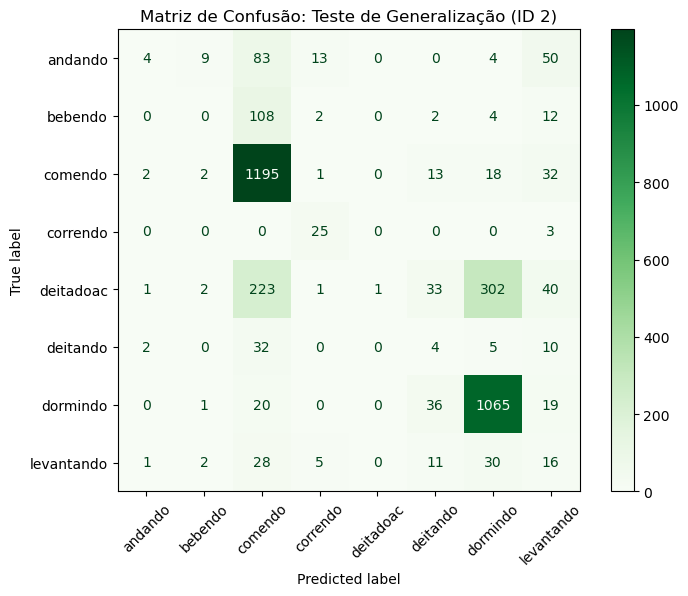

In [152]:
import pandas as pd
import numpy as np
from scipy.stats import skew, kurtosis
from scipy.signal import find_peaks
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# --- 1. FUNÇÃO DE EXTRAÇÃO DE FEATURES ---
def extrair_features(grupo):
    vm = np.sqrt(grupo['AX']**2 + grupo['AY']**2 + grupo['AZ']**2)
    peaks, _ = find_peaks(vm, height=np.mean(vm))
    
    return pd.Series({
        'mean': vm.mean(),
        'std': vm.std(),
        'min': vm.min(),
        'max': vm.max(),
        'max_min_diff': vm.max() - vm.min(),
        'median': np.median(vm),
        'peak_count': len(peaks),
        'skewness': skew(vm),
        'kurtosis': kurtosis(vm),
        'sma': np.sum(np.abs(vm)) / len(vm)
    })

# --- 2. PROCESSAMENTO DO DATASET ---
print("Extraindo características por janela...")
df_features = df_final.groupby('janela').apply(extrair_features).reset_index()

# Trazendo ID e Atividade (primeira ocorrência de cada janela)
info_janelas = df_final.groupby('janela')[['ID', 'atividade']].first().reset_index()
df_ml = pd.merge(df_features, info_janelas, on='janela')

# Limpeza de NaNs/Infs
df_ml = df_ml.replace([np.inf, -np.inf], np.nan).dropna()

# Encoding da Atividade
le = LabelEncoder()
df_ml['atividade_code'] = le.fit_transform(df_ml['atividade'])

# --- 3. SEPARAÇÃO POR ANIMAL (ID 1 vs ID 2) ---
# Treino: Porco ID 1 | Teste: Porco ID 2
df_treino = df_ml[df_ml['ID'] == 1]
df_teste = df_ml[df_ml['ID'] == 2]

X_train_raw = df_treino.drop(['janela', 'ID', 'atividade', 'atividade_code'], axis=1)
y_train = df_treino['atividade_code']

X_test_raw = df_teste.drop(['janela', 'ID', 'atividade', 'atividade_code'], axis=1)
y_test = df_teste['atividade_code']

print(f"Janelas de Treino (ID 1): {len(X_train_raw)}")
print(f"Janelas de Teste (ID 2): {len(X_test_raw)}")

# --- 4. ESCALONAMENTO E MODELAGEM ---
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw) # Aprende no ID 1
X_test = scaler.transform(X_test_raw)       # Aplica no ID 2

model = LogisticRegression(solver='saga', max_iter=3000, class_weight='balanced')
model.fit(X_train, y_train)

# --- 5. RESULTADOS ---
y_pred = model.predict(X_test)

print("\n" + "="*30)
print("RELATÓRIO: TREINO NO ID 1 (PRETO) -> TESTE NO ID 2 (AMARELO)")
print("="*30)
print(classification_report(y_test, y_pred, target_names=le.classes_))

# Plot da Matriz de Confusão
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
disp.plot(cmap=plt.cm.Greens, ax=ax, xticks_rotation=45)
plt.title('Matriz de Confusão: Teste de Generalização (ID 2)')
plt.show()

Extraindo features das janelas...


C:\Users\franc\AppData\Local\Temp\ipykernel_25944\4162032154.py:31: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_features = df_final.groupby('janela').apply(extrair_features).reset_index()
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Iniciando Validação Cruzada com Regressão Logística...


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in versio


DESEMPENHO MÉDIO REGRESSÃO LOGÍSTICA: 0.6656
Desvio Padrão: 0.0093

Relatório de Classificação:

              precision    recall  f1-score   support

     andando       0.57      0.50      0.53       462
     bebendo       0.17      0.30      0.22       338
     comendo       0.85      0.72      0.78      2427
    correndo       0.49      0.90      0.63        50
   deitadoac       0.64      0.38      0.47      1185
    deitando       0.10      0.31      0.15       145
    dormindo       0.81      0.91      0.86      2290
  levantando       0.10      0.12      0.11       193

    accuracy                           0.67      7090
   macro avg       0.47      0.52      0.47      7090
weighted avg       0.71      0.67      0.68      7090



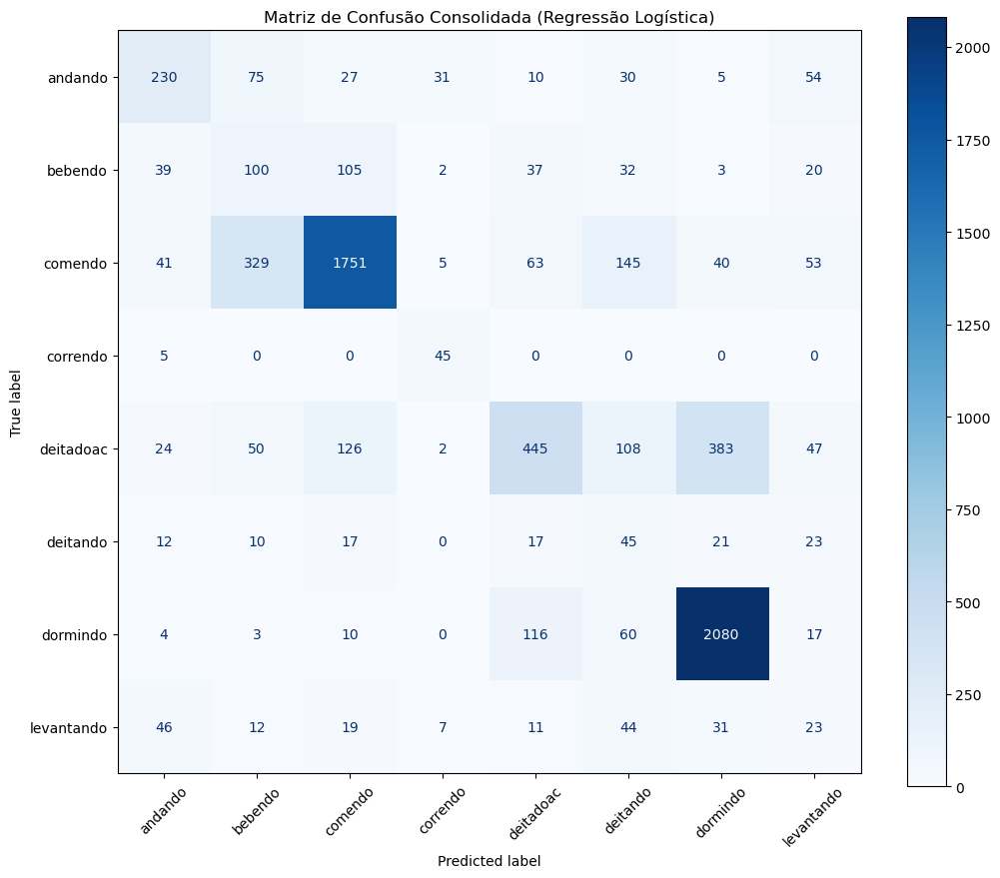

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(



Coeficientes da Regressão Logística por classe:
                mean       std       min       max  max_min_diff    median  \
andando    -0.209205  1.497931 -0.484651 -0.434269     -0.193284  0.815095   
bebendo    -0.254665  1.284234 -0.214166 -0.331126     -0.196973  0.685800   
comendo    -0.941515  3.064831 -0.296363 -1.147619     -0.824999  1.610535   
correndo   -0.176674  2.031574 -0.981581 -0.049206      0.273890  0.619020   
deitadoac   0.827141 -1.811873  0.430892  0.407778      0.189216 -1.363476   
deitando    0.477013 -1.467439 -1.010214 -0.079549      0.258715 -0.149146   
dormindo   -0.456888 -4.905439  3.159634  1.886298      0.502957 -1.414356   
levantando  0.734793  0.306181 -0.603552 -0.252307     -0.009523 -0.803472   

            peak_count  skewness  kurtosis       sma  
andando      -0.419368  0.644762 -0.447676 -0.209205  
bebendo       0.021991  0.041545 -0.079896 -0.254665  
comendo       1.169513  0.287330  0.035436 -0.941515  
correndo      0.284245 -0.08

In [41]:
import pandas as pd
import numpy as np
from scipy.stats import skew, kurtosis
from scipy.signal import find_peaks
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, accuracy_score
import matplotlib.pyplot as plt

# --- 1. FUNÇÃO DE EXTRAÇÃO SOLICITADA ---
def extrair_features(grupo):
    vm = np.sqrt(grupo['AX']**2 + grupo['AY']**2 + grupo['AZ']**2)
    peaks, _ = find_peaks(vm, height=np.mean(vm))
    
    return pd.Series({
        'mean': vm.mean(),
        'std': vm.std(),
        'min': vm.min(),
        'max': vm.max(),
        'max_min_diff': vm.max() - vm.min(),
        'median': np.median(vm),
        'peak_count': len(peaks),
        'skewness': skew(vm),
        'kurtosis': kurtosis(vm),
        'sma': np.sum(np.abs(vm)) / len(vm)
    })

# --- 2. PROCESSAMENTO E UNIÃO ---
print("Extraindo features das janelas...")
df_features = df_final.groupby('janela').apply(extrair_features).reset_index()

atividades = df_final.groupby('janela')['atividade'].first().reset_index()
df_ml = pd.merge(df_features, atividades, on='janela')

# Limpeza de possíveis valores nulos
df_ml = df_ml.dropna()

# --- 3. PREPARAÇÃO PARA O MODELO ---
X = df_ml.drop(columns=['janela', 'atividade'])
y = df_ml['atividade']

le = LabelEncoder()
y_encoded = le.fit_transform(y)

# --- 4. REGRESSÃO LOGÍSTICA COM K-FOLD (5 Folds) ---
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

modelo_lr = LogisticRegression(
    class_weight='balanced',
    max_iter=2000,
    random_state=42,
    multi_class='auto'
)

y_true_total = []
y_pred_total = []
scores = []

print("Iniciando Validação Cruzada com Regressão Logística...")

for train_index, test_index in kf.split(X, y_encoded):
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y_encoded[train_index], y_encoded[test_index]

    # Padronização
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    # Treino
    modelo_lr.fit(X_train_scaled, y_train)
    
    # Previsão
    y_pred = modelo_lr.predict(X_test_scaled)
    
    # Armazenar resultados
    y_true_total.extend(y_test)
    y_pred_total.extend(y_pred)
    scores.append(accuracy_score(y_test, y_pred))

# --- 5. RESULTADOS CONSOLIDADOS ---
print("\n" + "="*40)
print(f"DESEMPENHO MÉDIO REGRESSÃO LOGÍSTICA: {np.mean(scores):.4f}")
print(f"Desvio Padrão: {np.std(scores):.4f}")
print("="*40)

print("\nRelatório de Classificação:\n")
print(classification_report(y_true_total, y_pred_total, target_names=le.classes_))

# --- 6. MATRIZ DE CONFUSÃO ---
fig, ax = plt.subplots(figsize=(12, 10))
disp = ConfusionMatrixDisplay.from_predictions(
    y_true_total,
    y_pred_total,
    display_labels=le.classes_,
    cmap='Blues',
    xticks_rotation=45,
    ax=ax
)
plt.title('Matriz de Confusão Consolidada (Regressão Logística)')
plt.show()

# --- 7. COEFICIENTES DO MODELO (interpretação) ---
# Reajustando no conjunto completo apenas para inspecionar coeficientes
scaler_final = StandardScaler()
X_scaled = scaler_final.fit_transform(X)

modelo_lr.fit(X_scaled, y_encoded)

coef_df = pd.DataFrame(
    modelo_lr.coef_,
    columns=X.columns,
    index=le.classes_
)

print("\nCoeficientes da Regressão Logística por classe:")
print(coef_df)

# Opcional: importância média absoluta dos coeficientes
importancia_coef = pd.Series(
    np.mean(np.abs(modelo_lr.coef_), axis=0),
    index=X.columns
).sort_values(ascending=False)

print("\nTop features com maior peso médio absoluto:")
print(importancia_coef)

Extraindo features das janelas...


C:\Users\franc\AppData\Local\Temp\ipykernel_25944\3874585524.py:31: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_features = df_final.groupby('janela').apply(extrair_features).reset_index()



=== DIAGNÓSTICO INICIAL ===
Shape antes da limpeza: (7090, 12)
Colunas do df_ml:
['janela', 'mean', 'std', 'min', 'max', 'max_min_diff', 'median', 'peak_count', 'skewness', 'kurtosis', 'sma', 'atividade']
Total de NaN antes da limpeza: 0
Total de inf/-inf antes da limpeza: 0

=== LIMPEZA ===
Shape depois da limpeza: (7090, 12)
Linhas removidas na limpeza: 0

=== FEATURES USADAS NO MODELO ===
['mean', 'std', 'min', 'max', 'max_min_diff', 'median', 'peak_count', 'skewness', 'kurtosis', 'sma']
Shape de X: (7090, 10)
Distribuição das classes:
atividade
comendo       2427
dormindo      2290
deitadoac     1185
andando        462
bebendo        338
levantando     193
deitando       145
correndo        50
Name: count, dtype: int64

Classes codificadas:
0 -> andando
1 -> bebendo
2 -> comendo
3 -> correndo
4 -> deitadoac
5 -> deitando
6 -> dormindo
7 -> levantando

Iniciando Validação Cruzada com Regressão Logística...


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Fold 1 concluído. Acurácia: 0.6375


...

Fold 3 concluído. Acurácia: 0.6537


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Fold 4 concluído. Acurácia: 0.6573


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Fold 5 concluído. Acurácia: 0.6763

DESEMPENHO MÉDIO REGRESSÃO LOGÍSTICA
Acurácia média: 0.6602
Desvio padrão: 0.0147

Relatório de Classificação:

              precision    recall  f1-score   support

     andando       0.54      0.44      0.48       462
     bebendo       0.16      0.28      0.20       338
     comendo       0.85      0.72      0.78      2427
    correndo       0.38      0.88      0.53        50
   deitadoac       0.64      0.37      0.47      1185
    deitando       0.10      0.33      0.16       145
    dormindo       0.81      0.91      0.86      2290
  levantando       0.10      0.12      0.11       193

    accuracy                           0.66      7090
   macro avg       0.45      0.51      0.45      7090
weighted avg       0.71      0.66      0.67      7090



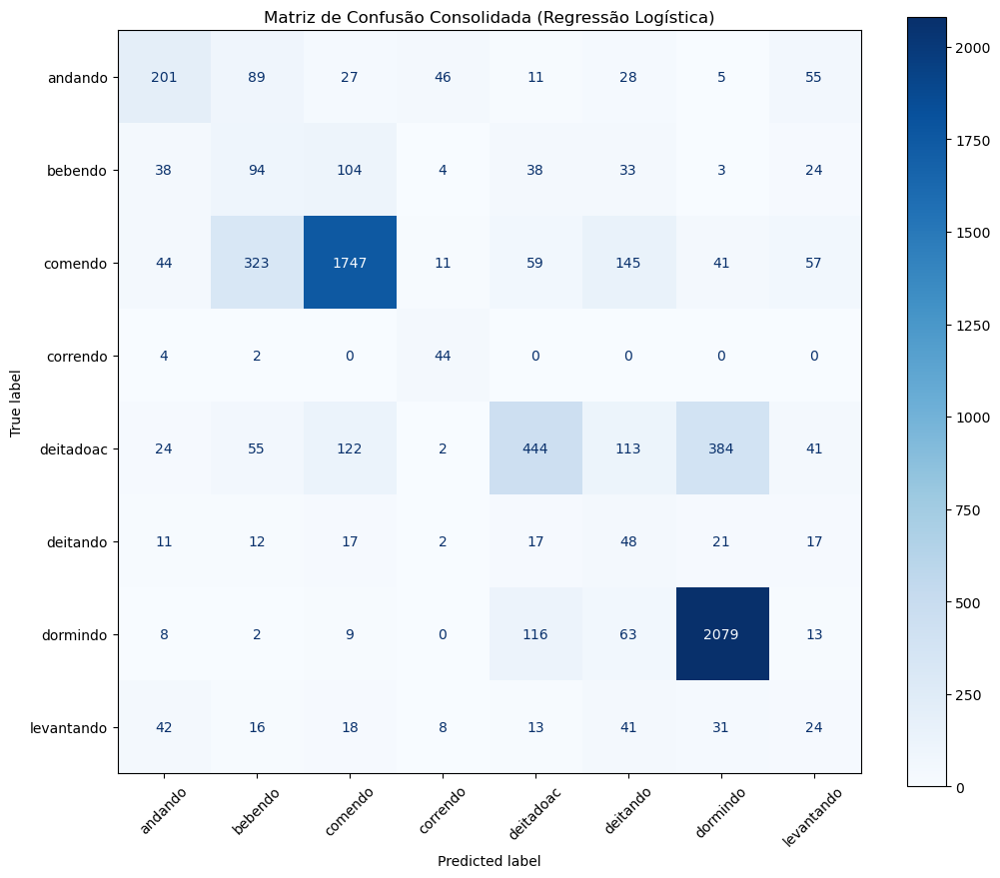


Coeficientes da Regressão Logística por classe:
                mean       std       min       max  max_min_diff    median  \
andando    -0.168545  0.460600 -0.239334  0.128817      0.179617  0.104145   
bebendo    -0.257520  1.203843 -0.187141 -0.299039     -0.179887  0.545523   
comendo    -0.894183  3.260838 -0.249604 -1.238902     -0.913070  1.430609   
correndo   -0.137196  3.733977 -1.374813 -0.943236     -0.316986  2.111372   
deitadoac   0.723412 -2.002222  0.453374  0.512228      0.265737 -1.347924   
deitando    0.442719 -1.639278 -0.988324  0.019194      0.330852 -0.250419   
dormindo   -0.455733 -5.085447  3.183932  1.965717      0.558841 -1.597258   
levantando  0.747047  0.067688 -0.598090 -0.144780      0.074896 -0.996050   

            peak_count  skewness  kurtosis       sma  
andando      -0.598717  0.746418 -0.699324 -0.168545  
bebendo      -0.054419  0.102390 -0.044443 -0.257520  
comendo       1.111131  0.340450  0.097430 -0.894183  
correndo      0.947145 -0.51

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [42]:
import pandas as pd
import numpy as np
from scipy.stats import skew, kurtosis
from scipy.signal import find_peaks
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, accuracy_score
import matplotlib.pyplot as plt

# --- 1. FUNÇÃO DE EXTRAÇÃO SOLICITADA ---
def extrair_features(grupo):
    vm = np.sqrt(grupo['AX']**2 + grupo['AY']**2 + grupo['AZ']**2)
    peaks, _ = find_peaks(vm, height=np.mean(vm))
    
    return pd.Series({
        'mean': vm.mean(),
        'std': vm.std(),
        'min': vm.min(),
        'max': vm.max(),
        'max_min_diff': vm.max() - vm.min(),
        'median': np.median(vm),
        'peak_count': len(peaks),
        'skewness': skew(vm),
        'kurtosis': kurtosis(vm),
        'sma': np.sum(np.abs(vm)) / len(vm)
    })

# --- 2. PROCESSAMENTO E UNIÃO ---
print("Extraindo features das janelas...")
df_features = df_final.groupby('janela').apply(extrair_features).reset_index()

atividades = df_final.groupby('janela')['atividade'].first().reset_index()
df_ml = pd.merge(df_features, atividades, on='janela')

print("\n=== DIAGNÓSTICO INICIAL ===")
print("Shape antes da limpeza:", df_ml.shape)
print("Colunas do df_ml:")
print(df_ml.columns.tolist())

# Verificação de valores problemáticos antes da limpeza
n_nan_antes = df_ml.isna().sum().sum()
n_inf_antes = np.isinf(df_ml.select_dtypes(include=[np.number])).sum().sum()

print(f"Total de NaN antes da limpeza: {n_nan_antes}")
print(f"Total de inf/-inf antes da limpeza: {n_inf_antes}")

# --- 2.1 LIMPEZA PROFUNDA (igual ao outro código) ---
linhas_antes = len(df_ml)
df_ml = df_ml.replace([np.inf, -np.inf], np.nan).dropna()
linhas_depois = len(df_ml)

print("\n=== LIMPEZA ===")
print("Shape depois da limpeza:", df_ml.shape)
print(f"Linhas removidas na limpeza: {linhas_antes - linhas_depois}")

# --- 3. PREPARAÇÃO PARA O MODELO ---
X = df_ml.drop(columns=['janela', 'atividade'])
y = df_ml['atividade']

print("\n=== FEATURES USADAS NO MODELO ===")
print(X.columns.tolist())
print("Shape de X:", X.shape)
print("Distribuição das classes:")
print(y.value_counts())

le = LabelEncoder()
y_encoded = le.fit_transform(y)

print("\nClasses codificadas:")
for i, classe in enumerate(le.classes_):
    print(f"{i} -> {classe}")

# --- 4. REGRESSÃO LOGÍSTICA COM K-FOLD (5 Folds) ---
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# mesmo solver do outro código
modelo_lr = LogisticRegression(
    solver='saga',
    class_weight='balanced',
    max_iter=3000,
    random_state=42
)

y_true_total = []
y_pred_total = []
scores = []

print("\nIniciando Validação Cruzada com Regressão Logística...")

for fold, (train_index, test_index) in enumerate(kf.split(X, y_encoded), start=1):
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y_encoded[train_index], y_encoded[test_index]

    # Padronização
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    # Treino
    modelo_lr.fit(X_train_scaled, y_train)
    
    # Previsão
    y_pred = modelo_lr.predict(X_test_scaled)
    
    # Armazenar resultados
    acc = accuracy_score(y_test, y_pred)
    y_true_total.extend(y_test)
    y_pred_total.extend(y_pred)
    scores.append(acc)

    print(f"Fold {fold} concluído. Acurácia: {acc:.4f}")

# --- 5. RESULTADOS CONSOLIDADOS ---
print("\n" + "="*50)
print("DESEMPENHO MÉDIO REGRESSÃO LOGÍSTICA")
print(f"Acurácia média: {np.mean(scores):.4f}")
print(f"Desvio padrão: {np.std(scores):.4f}")
print("="*50)

print("\nRelatório de Classificação:\n")
print(classification_report(y_true_total, y_pred_total, target_names=le.classes_))

# --- 6. MATRIZ DE CONFUSÃO ---
fig, ax = plt.subplots(figsize=(12, 10))
disp = ConfusionMatrixDisplay.from_predictions(
    y_true_total,
    y_pred_total,
    display_labels=le.classes_,
    cmap='Blues',
    xticks_rotation=45,
    ax=ax
)
plt.title('Matriz de Confusão Consolidada (Regressão Logística)')
plt.show()

# --- 7. COEFICIENTES DO MODELO (interpretação) ---
# Reajustando no conjunto completo apenas para inspecionar coeficientes
scaler_final = StandardScaler()
X_scaled = scaler_final.fit_transform(X)

modelo_lr.fit(X_scaled, y_encoded)

coef_df = pd.DataFrame(
    modelo_lr.coef_,
    columns=X.columns,
    index=le.classes_
)

print("\nCoeficientes da Regressão Logística por classe:")
print(coef_df)

# Importância média absoluta dos coeficientes
importancia_coef = pd.Series(
    np.mean(np.abs(modelo_lr.coef_), axis=0),
    index=X.columns
).sort_values(ascending=False)

print("\nTop features com maior peso médio absoluto:")
print(importancia_coef)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# --- 1. CARREGAMENTO DO DATASET (O QUE ESTAVA FALTANDO) ---
caminho_arquivo = r'C:\Users\franc\OneDrive\Desktop\dataset_treinamento_suinos.xlsx'
df_final = pd.read_excel(caminho_arquivo)

# 2. Lista de atividades presentes no seu dataset
atividades = df_final['atividade'].unique()

# 3. Configura a grade dinamicamente
n_atividades = len(atividades)
cols = 3
rows = int(np.ceil(n_atividades / cols))

fig, axes = plt.subplots(rows, cols, figsize=(15, rows * 4))
axes = axes.flatten()

# 4. Processamento e Plotagem
for i, activity in enumerate(atividades):
    # Filtra os dados da atividade
    subset = df_final[df_final['atividade'] == activity]
    
    # Calcula a Magnitude do Vetor (VM)
    # Importante: usamos os dados brutos AX, AY, AZ do arquivo
    vm = np.sqrt(subset['AX']**2 + subset['AY']**2 + subset['AZ']**2)
    
    # Calcula a mediana
    median_vm = np.median(vm)

    # Plot KDE (Densidade)
    sns.kdeplot(vm, fill=True, label=activity, ax=axes[i], color='teal', alpha=0.5)
    axes[i].axvline(median_vm, color='darkblue', linestyle='dashed', linewidth=2, 
                    label=f'Mediana: {median_vm:.2f}')

    # Estilização
    axes[i].set_xlabel('Magnitude da Aceleração [g]')
    axes[i].set_ylabel('Densidade')
    axes[i].set_title(f'Distribuição: {activity}')
    axes[i].legend()

# Remove eixos vazios
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [44]:
import pandas as pd
import numpy as np
from scipy.stats import skew, kurtosis
from scipy.signal import find_peaks

def extrair_features(grupo):
    # 1. Calculando a Magnitude do Vetor (VM)
    vm = np.sqrt(grupo['AX']**2 + grupo['AY']**2 + grupo['AZ']**2)
    
    # 2. Contagem de picos (usando limiar de altura)
    peaks, _ = find_peaks(vm, height=np.mean(vm))
    
    # Dicionário com as características extraídas
    features = {
        'mean': vm.mean(),
        'std': vm.std(),
        'min': vm.min(),
        'max': vm.max(),
        'max_min_diff': vm.max() - vm.min(),
        'median': np.median(vm),
        'peak_count': len(peaks),
        'skewness': skew(vm),
        'kurtosis': kurtosis(vm),
        'sma': np.sum(np.abs(vm)) / len(vm) # Signal Magnitude Area
    }
    return pd.Series(features)

# Aplicando para cada janela
# Agrupamos pelo ID da janela e aplicamos a função de extração
df_features = df_final.groupby('janela').apply(extrair_features)

# Adicionamos a coluna da atividade de volta ao dataset de features
# (Pegamos a primeira atividade de cada janela, assumindo que elas são homogêneas)
atividades = df_final.groupby('janela')['atividade'].first()
df_features['atividade'] = atividades

print(df_features.head())

             mean       std        min        max  max_min_diff     median  \
janela                                                                       
1       13.545966  2.682460   8.934936  30.342653     21.407716  12.989732   
2       12.994457  1.548667   8.308177  20.105347     11.797169  12.949863   
3       13.484504  2.089616  10.071121  24.122828     14.051707  12.906397   
4       12.636553  1.732319   5.988707  17.481813     11.493106  12.406962   
5       13.418125  2.952005   2.940358  23.450052     20.509693  13.249201   

        peak_count  skewness   kurtosis        sma atividade  
janela                                                        
1             19.0  3.763470  18.983735  13.545966   andando  
2             24.0  1.681273   7.072869  12.994457   andando  
3             17.0  2.500779   8.230616  13.484504   andando  
4             21.0  0.167620   2.497096  12.636553   andando  
5             25.0 -0.052244   2.533199  13.418125   andando  


C:\Users\franc\AppData\Local\Temp\ipykernel_25944\3671453982.py:30: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_features = df_final.groupby('janela').apply(extrair_features)


In [45]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df_features['atividade_code'] = le.fit_transform(df_features['atividade'])

# Salve o mapeamento para consultar depois
mapeamento = dict(zip(le.classes_, le.transform(le.classes_)))
print("Mapeamento das classes:", mapeamento)



Mapeamento das classes: {'andando': np.int64(0), 'bebendo': np.int64(1), 'comendo': np.int64(2), 'correndo': np.int64(3), 'deitadoac': np.int64(4), 'deitando': np.int64(5), 'dormindo': np.int64(6), 'levantando': np.int64(7)}


In [ ]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score
import matplotlib.pyplot as plt

# --- PASSO 1: LIMPEZA PROFUNDA ---
df_features_limpo = df_features.replace([np.inf, -np.inf], np.nan).dropna()

# --- PASSO 2: PREPARAÇÃO DOS DADOS ---
# Removemos colunas que não são métricas (ajuste os nomes se necessário)
colunas_para_dropar = ['atividade', 'janela', 'ID']
X = df_features_limpo.drop(columns=[c for c in colunas_para_dropar if c in df_features_limpo.columns])
y = df_features_limpo['atividade']

le = LabelEncoder()
y_encoded = le.fit_transform(y)

# --- PASSO 3: CONFIGURAÇÃO DO K-FOLD ---
# k=5 é o padrão ouro: o modelo treina 5 vezes, cada vez com 20% de dados diferentes para teste
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Listas para armazenar os resultados de cada "dobra" (fold)
scores = []
y_true_total = []
y_pred_total = []

print(f"Iniciando Validação Cruzada (5-Fold)...")

# --- PASSO 4: LOOP DE TREINAMENTO E VALIDAÇÃO ---
# Criamos o escalonador e o modelo
scaler = StandardScaler()
model = LogisticRegression(solver='saga', max_iter=3000, class_weight='balanced')

for i, (train_index, test_index) in enumerate(kf.split(X, y_encoded)):
    # Divisão dos dados para este Fold específico
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y_encoded[train_index], y_encoded[test_index]
    
    # Escalonamento (fit apenas no treino do fold atual para evitar data leakage)
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    # Treinamento
    model.fit(X_train_scaled, y_train)
    
    # Previsão
    y_pred = model.predict(X_test_scaled)
    
    # Salvar resultados
    scores.append(accuracy_score(y_test, y_pred))
    y_true_total.extend(y_test)
    y_pred_total.extend(y_pred)
    
    print(f"Fold {i+1} concluído. Acurácia: {scores[-1]:.4f}")

# --- PASSO 5: RELATÓRIO CONSOLIDADO ---
print("\n" + "="*40)
print(f"RESULTADO MÉDIO K-FOLD (k=5)")
print(f"Acurácia Média: {np.mean(scores):.4f} (+/- {np.std(scores):.4f})")
print("="*40)

print("\nRelatório de Classificação Consolidado:\n")
print(classification_report(y_true_total, y_pred_total, target_names=le.classes_))

# --- PASSO 6: MATRIZ DE CONFUSÃO GLOBAL ---
cm = confusion_matrix(y_true_total, y_pred_total)
fig, ax = plt.subplots(figsize=(10, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
disp.plot(cmap=plt.cm.Blues, ax=ax, xticks_rotation=45)
plt.title('Matriz de Confusão Global (Soma de todos os Folds)')
plt.show()

In [ ]:
Segundo Codigo

=== DIAGNÓSTICO INICIAL ===
Shape de df_features antes da limpeza: (7090, 12)
Shape de df_features_limpo depois da limpeza: (7090, 12)

Colunas de df_features_limpo:
['mean', 'std', 'min', 'max', 'max_min_diff', 'median', 'peak_count', 'skewness', 'kurtosis', 'sma', 'atividade', 'atividade_code']

Existe atividade_code? True

Distribuição de atividade_code:
atividade_code
0     462
1     338
2    2427
3      50
4    1185
5     145
6    2290
7     193
Name: count, dtype: int64

=== COLUNAS USADAS EM X ===
['mean', 'std', 'min', 'max', 'max_min_diff', 'median', 'peak_count', 'skewness', 'kurtosis', 'sma']
Shape de X: (7090, 10)

Distribuição das classes em y:
atividade
comendo       2427
dormindo      2290
deitadoac     1185
andando        462
bebendo        338
levantando     193
deitando       145
correndo        50
Name: count, dtype: int64

Classes codificadas:
0 -> andando
1 -> bebendo
2 -> comendo
3 -> correndo
4 -> deitadoac
5 -> deitando
6 -> dormindo
7 -> levantando

Iniciando V

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Fold 1 concluído. Acurácia: 0.6375


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Fold 2 concluído. Acurácia: 0.6763


...

Fold 3 concluído. Acurácia: 0.6537


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Fold 4 concluído. Acurácia: 0.6573


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Fold 5 concluído. Acurácia: 0.6763

RESULTADO MÉDIO K-FOLD (k=5)
Acurácia Média: 0.6602 (+/- 0.0147)

Relatório de Classificação Consolidado:

              precision    recall  f1-score   support

     andando       0.54      0.44      0.48       462
     bebendo       0.16      0.28      0.20       338
     comendo       0.85      0.72      0.78      2427
    correndo       0.38      0.88      0.53        50
   deitadoac       0.64      0.37      0.47      1185
    deitando       0.10      0.33      0.16       145
    dormindo       0.81      0.91      0.86      2290
  levantando       0.10      0.12      0.11       193

    accuracy                           0.66      7090
   macro avg       0.45      0.51      0.45      7090
weighted avg       0.71      0.66      0.67      7090



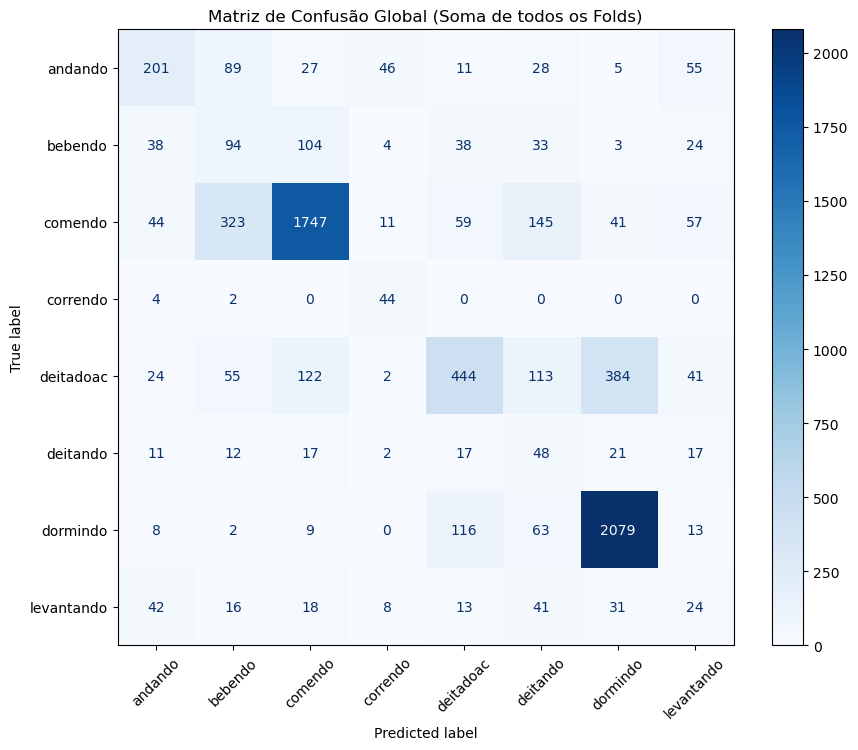

In [46]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score
import matplotlib.pyplot as plt

# --- PASSO 1: LIMPEZA PROFUNDA ---
df_features_limpo = df_features.replace([np.inf, -np.inf], np.nan).dropna()

print("=== DIAGNÓSTICO INICIAL ===")
print("Shape de df_features antes da limpeza:", df_features.shape)
print("Shape de df_features_limpo depois da limpeza:", df_features_limpo.shape)

print("\nColunas de df_features_limpo:")
print(df_features_limpo.columns.tolist())

print("\nExiste atividade_code?", 'atividade_code' in df_features_limpo.columns)

if 'atividade_code' in df_features_limpo.columns:
    print("\nDistribuição de atividade_code:")
    print(df_features_limpo['atividade_code'].value_counts().sort_index())

# --- PASSO 2: PREPARAÇÃO DOS DADOS ---
# Removemos explicitamente qualquer coluna que possa causar vazamento
colunas_para_dropar = ['atividade', 'atividade_code', 'janela', 'ID']

X = df_features_limpo.drop(
    columns=[c for c in colunas_para_dropar if c in df_features_limpo.columns]
)

y = df_features_limpo['atividade']

print("\n=== COLUNAS USADAS EM X ===")
print(X.columns.tolist())
print("Shape de X:", X.shape)

print("\nDistribuição das classes em y:")
print(y.value_counts())

le = LabelEncoder()
y_encoded = le.fit_transform(y)

print("\nClasses codificadas:")
for i, classe in enumerate(le.classes_):
    print(f"{i} -> {classe}")

# --- PASSO 3: CONFIGURAÇÃO DO K-FOLD ---
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = []
y_true_total = []
y_pred_total = []

print("\nIniciando Validação Cruzada (5-Fold)...")

# --- PASSO 4: LOOP DE TREINAMENTO E VALIDAÇÃO ---
scaler = StandardScaler()
model = LogisticRegression(
    solver='saga',
    max_iter=3000,
    class_weight='balanced',
    random_state=42
)

for i, (train_index, test_index) in enumerate(kf.split(X, y_encoded), start=1):
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y_encoded[train_index], y_encoded[test_index]
    
    # Escalonamento
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    # Treinamento
    model.fit(X_train_scaled, y_train)
    
    # Previsão
    y_pred = model.predict(X_test_scaled)
    
    # Salvar resultados
    acc = accuracy_score(y_test, y_pred)
    scores.append(acc)
    y_true_total.extend(y_test)
    y_pred_total.extend(y_pred)
    
    print(f"Fold {i} concluído. Acurácia: {acc:.4f}")

# --- PASSO 5: RELATÓRIO CONSOLIDADO ---
print("\n" + "="*40)
print("RESULTADO MÉDIO K-FOLD (k=5)")
print(f"Acurácia Média: {np.mean(scores):.4f} (+/- {np.std(scores):.4f})")
print("="*40)

print("\nRelatório de Classificação Consolidado:\n")
print(classification_report(y_true_total, y_pred_total, target_names=le.classes_))

# --- PASSO 6: MATRIZ DE CONFUSÃO GLOBAL ---
cm = confusion_matrix(y_true_total, y_pred_total)
fig, ax = plt.subplots(figsize=(10, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
disp.plot(cmap=plt.cm.Blues, ax=ax, xticks_rotation=45)
plt.title('Matriz de Confusão Global (Soma de todos os Folds)')
plt.show()

Extraindo todas as 24 características...

Relatório Final (Híbrido - Todas as Features):
              precision    recall  f1-score   support

     andando       0.58      0.57      0.57       116
     bebendo       0.44      0.54      0.48        85
     comendo       0.90      0.81      0.85       607
    correndo       0.43      0.83      0.57        12
   deitadoac       0.66      0.36      0.47       296
    deitando       0.11      0.39      0.17        36
    dormindo       0.82      0.88      0.85       573
  levantando       0.14      0.25      0.18        48

    accuracy                           0.71      1773
   macro avg       0.51      0.58      0.52      1773
weighted avg       0.75      0.71      0.72      1773



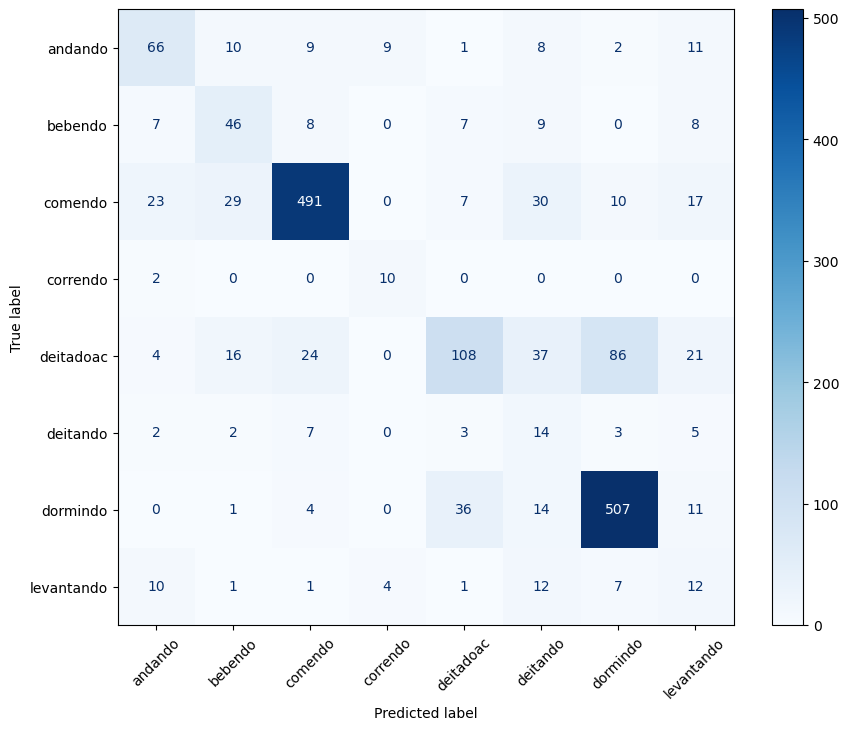

In [49]:
import pandas as pd
import numpy as np
from scipy.stats import skew, kurtosis
from scipy.signal import find_peaks
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# --- 1. FUNÇÃO DE EXTRAÇÃO COMPLETA (HÍBRIDA) ---
def extrair_features_hibridas(grupo):
    # Dados brutos
    ax = grupo['AX'].values
    ay = grupo['AY'].values
    az = grupo['AZ'].values
    vm = np.sqrt(ax**2 + ay**2 + az**2)
    n = len(vm)
    
    # --- NOVAS MÉTRICAS DE TRANSIÇÃO (O PULO DO GATO) ---
    # Variância AC das pontas (20% inicial vs 20% final) - Resolve ID 97
    ponta = int(n * 0.2)
    # Subtraímos a média local para focar na oscilação
    v_ini = np.var(vm[:ponta] - np.mean(vm[:ponta]))
    v_fim = np.var(vm[-ponta:] - np.mean(vm[-ponta:]))
    razao_var_ac = v_fim / (v_ini + 1e-6)
    
    # Delta de Postura (Eixo Z)
    delta_z = np.mean(az[-15:]) - np.mean(az[:15])

    # --- CARACTERÍSTICAS ORIGINAIS (PARA MANTER O RESTO DO DATASET) ---
    fft_vals = np.abs(np.fft.rfft(vm - np.mean(vm)))
    sorted_f = np.sort(fft_vals)
    N_fft = len(fft_vals)
    
    corr_xy = np.max(np.correlate(ax, ay, mode='full'))
    corr_xz = np.max(np.correlate(ax, az, mode='full'))

    features = {
        # Temporais
        'mean': np.mean(vm), 'std': np.std(vm), 'min': np.min(vm), 'max': np.max(vm),
        'max_min_diff': np.max(vm) - np.min(vm), 'median': np.median(vm),
        'peak_count': len(find_peaks(vm, height=np.mean(vm))[0]),
        'skewness': skew(vm), 'kurtosis': kurtosis(vm),
        
        # Frequência (FFT)
        'AV': np.mean(fft_vals), 'DC': fft_vals[0], 'SD_f': np.std(fft_vals),
        'MIN_f': np.min(fft_vals), 'MAX_f': np.max(fft_vals),
        'RG_f': np.max(fft_vals) - np.mean(fft_vals),
        'FQ': sorted_f[int(N_fft/4)] if N_fft > 4 else 0, 
        'SQ': sorted_f[int(N_fft/2)] if N_fft > 2 else 0,
        'RMS_f': np.sqrt(np.mean(fft_vals**2)), 'Median_f': np.median(fft_vals),
        
        # Correlações
        'max_corr_xy': corr_xy, 'max_corr_xz': corr_xz,
        
        # As Nossas Novas (O Diferencial)
        'razao_var_ac': razao_var_ac,
        'delta_z': delta_z
    }
    return pd.Series(features)

# --- 2. CARREGAMENTO E TREINO ---
caminho_dataset = r'C:\Users\franc\OneDrive\Desktop\dataset_treinamento_suinos.xlsx'
df_bruto = pd.read_excel(caminho_dataset)

print("Extraindo todas as 24 características...")
df_features = df_bruto.groupby('janela').apply(extrair_features_hibridas, include_groups=False)
df_features['atividade'] = df_bruto.groupby('janela')['atividade'].first()

X = df_features.drop('atividade', axis=1)
y = df_features['atividade']

le = LabelEncoder()
y_encoded = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.25, random_state=42, stratify=y_encoded)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# SAGA é ótimo para muitas variáveis
model = LogisticRegression(solver='saga', max_iter=5000, class_weight='balanced', C=0.6)
model.fit(X_train_scaled, y_train)

# --- 3. RESULTADOS ---
y_pred = model.predict(X_test_scaled)
print("\nRelatório Final (Híbrido - Todas as Features):")
print(classification_report(y_test, y_pred, target_names=le.classes_))

fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=le.classes_, cmap='Blues', xticks_rotation=45, ax=ax)
plt.show()

In [ ]:

     andando       0.58      0.58      0.58       116
     bebendo       0.44      0.56      0.49        85
     comendo       0.89      0.80      0.84       607
    correndo       0.38      0.75      0.50        12
   deitadoac       0.66      0.34      0.45       296
    deitando       0.11      0.36      0.17        36
    dormindo       0.82      0.89      0.85       573
  levantando       0.16      0.29      0.21        48

    accuracy                           0.70      1773
   macro avg       0.50      0.57      0.51      1773
weighted avg       0.75      0.70      0.71      1773

In [ ]:

     andando       0.56      0.59      0.58       116
     bebendo       0.42      0.48      0.45        85
     comendo       0.89      0.80      0.84       607
    correndo       0.42      0.83      0.56        12
   deitadoac       0.63      0.36      0.46       296
    deitando       0.17      0.50      0.25        36
    dormindo       0.82      0.88      0.85       573
  levantando       0.20      0.42      0.27        48

    accuracy                           0.71      1773
   macro avg       0.51      0.61      0.53      1773
weighted avg       0.75      0.71      0.71      1773

Extraindo características híbridas...
Shape do dataset de features: (7090, 23)
Colunas:
['mean', 'std', 'min', 'max', 'max_min_diff', 'median', 'peak_count', 'skewness', 'kurtosis', 'AV', 'DC', 'SD_f', 'MIN_f', 'MAX_f', 'RG_f', 'FQ', 'SQ', 'RMS_f', 'Median_f', 'max_corr_xy', 'max_corr_xz', 'log_razao_var_ac', 'atividade']

Relatório Final (Híbrido com log_razao_var_ac):
              precision    recall  f1-score   support

     andando       0.56      0.59      0.58       116
     bebendo       0.42      0.48      0.45        85
     comendo       0.89      0.80      0.84       607
    correndo       0.42      0.83      0.56        12
   deitadoac       0.63      0.36      0.46       296
    deitando       0.17      0.50      0.25        36
    dormindo       0.82      0.88      0.85       573
  levantando       0.20      0.42      0.27        48

    accuracy                           0.71      1773
   macro avg       0.51      0.61      0.53      1773
weighted avg       0.75      0.

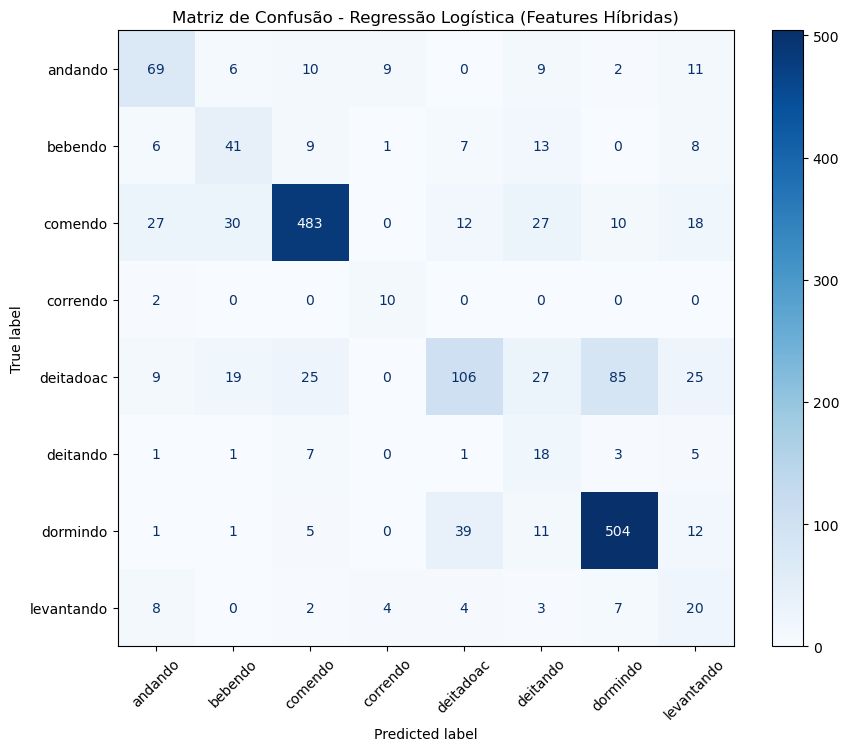

In [50]:
import pandas as pd
import numpy as np
from scipy.stats import skew, kurtosis
from scipy.signal import find_peaks
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# --- 1. FUNÇÃO DE EXTRAÇÃO COMPLETA (HÍBRIDA) ---
def extrair_features_hibridas(grupo):
    # Dados brutos
    ax = grupo['AX'].values
    ay = grupo['AY'].values
    az = grupo['AZ'].values
    vm = np.sqrt(ax**2 + ay**2 + az**2)
    n = len(vm)

    # --- NOVA MÉTRICA DE TRANSIÇÃO: LOG DA RAZÃO DE VARIÂNCIA ---
    ponta = max(3, int(n * 0.2))

    # Variância nas pontas, centralizada pela média local
    v_ini = np.var(vm[:ponta] - np.mean(vm[:ponta]))
    v_fim = np.var(vm[-ponta:] - np.mean(vm[-ponta:]))

    # Log da razão de variância
    log_razao_var_ac = np.log((v_fim + 1e-6) / (v_ini + 1e-6))

    # --- CARACTERÍSTICAS ORIGINAIS ---
    fft_vals = np.abs(np.fft.rfft(vm - np.mean(vm)))
    sorted_f = np.sort(fft_vals)
    N_fft = len(fft_vals)

    corr_xy = np.max(np.correlate(ax, ay, mode='full'))
    corr_xz = np.max(np.correlate(ax, az, mode='full'))

    features = {
        # Temporais
        'mean': np.mean(vm),
        'std': np.std(vm),
        'min': np.min(vm),
        'max': np.max(vm),
        'max_min_diff': np.max(vm) - np.min(vm),
        'median': np.median(vm),
        'peak_count': len(find_peaks(vm, height=np.mean(vm))[0]),
        'skewness': skew(vm),
        'kurtosis': kurtosis(vm),

        # Frequência (FFT)
        'AV': np.mean(fft_vals),
        'DC': fft_vals[0] if len(fft_vals) > 0 else 0,
        'SD_f': np.std(fft_vals),
        'MIN_f': np.min(fft_vals) if len(fft_vals) > 0 else 0,
        'MAX_f': np.max(fft_vals) if len(fft_vals) > 0 else 0,
        'RG_f': (np.max(fft_vals) - np.mean(fft_vals)) if len(fft_vals) > 0 else 0,
        'FQ': sorted_f[int(N_fft/4)] if N_fft > 4 else 0,
        'SQ': sorted_f[int(N_fft/2)] if N_fft > 2 else 0,
        'RMS_f': np.sqrt(np.mean(fft_vals**2)) if len(fft_vals) > 0 else 0,
        'Median_f': np.median(fft_vals) if len(fft_vals) > 0 else 0,

        # Correlações
        'max_corr_xy': corr_xy,
        'max_corr_xz': corr_xz,

        # Nova feature de transição
        'log_razao_var_ac': log_razao_var_ac
    }

    return pd.Series(features)

# --- 2. CARREGAMENTO E TREINO ---
caminho_dataset = r'C:\Users\franc\OneDrive\Desktop\dataset_treinamento_suinos.xlsx'
df_bruto = pd.read_excel(caminho_dataset)

print("Extraindo características híbridas...")
df_features = df_bruto.groupby('janela').apply(extrair_features_hibridas, include_groups=False)
df_features['atividade'] = df_bruto.groupby('janela')['atividade'].first()

# Limpeza por segurança
df_features = df_features.replace([np.inf, -np.inf], np.nan).dropna()

print("Shape do dataset de features:", df_features.shape)
print("Colunas:")
print(df_features.columns.tolist())

X = df_features.drop('atividade', axis=1)
y = df_features['atividade']

le = LabelEncoder()
y_encoded = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.25,
    random_state=42,
    stratify=y_encoded
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LogisticRegression(
    solver='saga',
    max_iter=5000,
    class_weight='balanced',
    C=0.6,
    random_state=42
)

model.fit(X_train_scaled, y_train)

# --- 3. RESULTADOS ---
y_pred = model.predict(X_test_scaled)

print("\nRelatório Final (Híbrido com log_razao_var_ac):")
print(classification_report(y_test, y_pred, target_names=le.classes_))

fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=le.classes_,
    cmap='Blues',
    xticks_rotation=45,
    ax=ax
)
plt.title('Matriz de Confusão - Regressão Logística (Features Híbridas)')
plt.show()

Extraindo características híbridas com novas métricas...
Shape do dataset de features: (7090, 32)

Colunas das features:
['mean', 'std', 'min', 'max', 'max_min_diff', 'median', 'peak_count', 'skewness', 'kurtosis', 'AV', 'DC', 'SD_f', 'MIN_f', 'MAX_f', 'RG_f', 'FQ', 'SQ', 'RMS_f', 'Median_f', 'max_corr_xy', 'max_corr_xz', 'log_razao_var_ac', 'diff_var', 'energia_ini', 'energia_fim', 'delta_energia', 'mean_diff', 'std_diff', 'max_diff', 'min_diff', 'rms_diff', 'atividade']


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(



Relatório Final (Híbrido + derivadas + energia):
              precision    recall  f1-score   support

     andando       0.57      0.59      0.58       116
     bebendo       0.44      0.54      0.48        85
     comendo       0.90      0.80      0.85       607
    correndo       0.52      0.92      0.67        12
   deitadoac       0.66      0.34      0.45       296
    deitando       0.21      0.58      0.30        36
    dormindo       0.82      0.89      0.85       573
  levantando       0.23      0.48      0.31        48

    accuracy                           0.72      1773
   macro avg       0.54      0.64      0.56      1773
weighted avg       0.75      0.72      0.72      1773



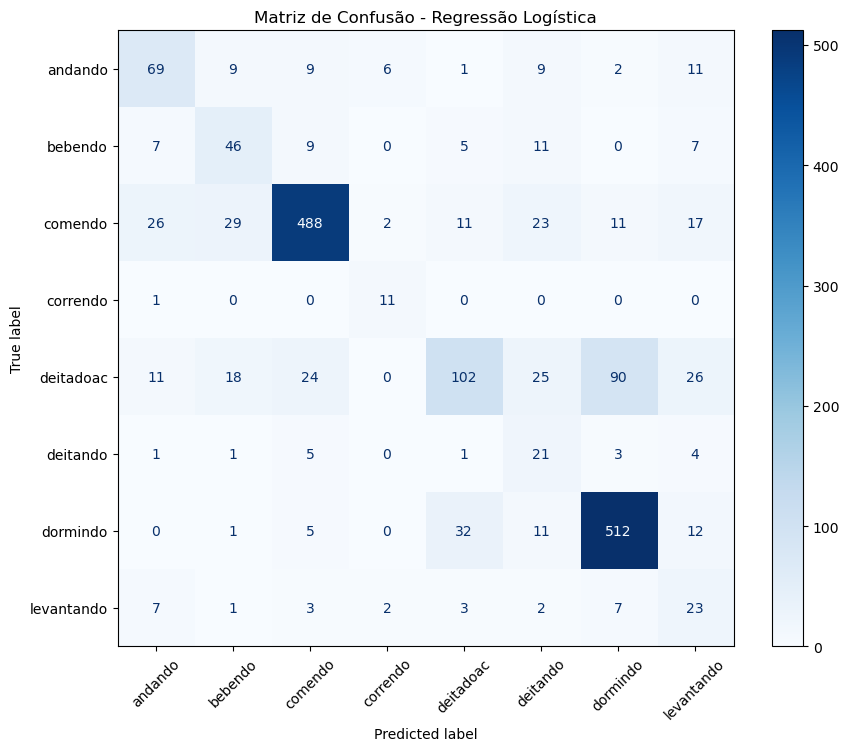


Coeficientes por classe:
                mean       std       min       max  max_min_diff    median  \
andando     0.544804  0.796277 -0.165777 -0.566273     -0.398160 -0.312796   
bebendo    -0.869927  0.441006  0.314173 -0.652961     -0.622294 -0.219660   
comendo    -1.136260  0.235971  0.234357 -1.043707     -0.908202  0.683806   
correndo   -1.305152 -0.019646 -1.350360 -0.558736     -0.009623  1.191724   
deitadoac  -0.077059 -0.369682  0.244288  0.608704      0.406653 -0.855620   
deitando    1.777346 -0.151589 -0.517204  0.285077      0.394409 -0.197321   
dormindo    0.644675 -0.716814  1.694552  2.039237      1.079413  0.024463   
levantando  0.421573 -0.215523 -0.454028 -0.111340      0.057803 -0.314595   

            peak_count  skewness  kurtosis        AV  ...  log_razao_var_ac  \
andando      -0.522248  0.343574 -0.344101 -0.113017  ...          0.014219   
bebendo      -0.109648 -0.331871 -0.221541  0.870417  ...         -0.020554   
comendo       0.953154 -0.176867  

In [51]:
import pandas as pd
import numpy as np
from scipy.stats import skew, kurtosis
from scipy.signal import find_peaks
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# --- 1. FUNÇÃO DE EXTRAÇÃO COMPLETA (HÍBRIDA + NOVAS FEATURES) ---
def extrair_features_hibridas(grupo):
    # Dados brutos
    ax = grupo['AX'].values
    ay = grupo['AY'].values
    az = grupo['AZ'].values
    vm = np.sqrt(ax**2 + ay**2 + az**2)
    n = len(vm)

    # Segurança para janelas pequenas
    ponta = max(3, int(n * 0.2))

    # --- MÉTRICAS DE TRANSIÇÃO ---
    # Variância local no início e no fim
    v_ini = np.var(vm[:ponta] - np.mean(vm[:ponta]))
    v_fim = np.var(vm[-ponta:] - np.mean(vm[-ponta:]))

    # Log da razão de variância
    log_razao_var_ac = np.log((v_fim + 1e-6) / (v_ini + 1e-6))

    # Diferença absoluta de variância
    diff_var = v_fim - v_ini

    # Energia no início e no fim
    energia_ini = np.sum(vm[:ponta]**2)
    energia_fim = np.sum(vm[-ponta:]**2)
    delta_energia = energia_fim - energia_ini

    # --- DERIVADAS DA MAGNITUDE ---
    diff_vm = np.diff(vm) if len(vm) > 1 else np.array([0.0])

    mean_diff = np.mean(diff_vm)
    std_diff = np.std(diff_vm)
    max_diff = np.max(diff_vm)
    min_diff = np.min(diff_vm)
    rms_diff = np.sqrt(np.mean(diff_vm**2))

    # --- FEATURES TEMPORAIS ORIGINAIS ---
    peak_count = len(find_peaks(vm, height=np.mean(vm))[0])

    # --- FFT ---
    vm_centralizado = vm - np.mean(vm)
    fft_vals = np.abs(np.fft.rfft(vm_centralizado))
    sorted_f = np.sort(fft_vals)
    N_fft = len(fft_vals)

    # --- CORRELAÇÕES ---
    corr_xy = np.max(np.correlate(ax, ay, mode='full'))
    corr_xz = np.max(np.correlate(ax, az, mode='full'))

    features = {
        # Temporais básicas
        'mean': np.mean(vm),
        'std': np.std(vm),
        'min': np.min(vm),
        'max': np.max(vm),
        'max_min_diff': np.max(vm) - np.min(vm),
        'median': np.median(vm),
        'peak_count': peak_count,
        'skewness': skew(vm),
        'kurtosis': kurtosis(vm),

        # Frequência (FFT)
        'AV': np.mean(fft_vals) if N_fft > 0 else 0,
        'DC': fft_vals[0] if N_fft > 0 else 0,
        'SD_f': np.std(fft_vals) if N_fft > 0 else 0,
        'MIN_f': np.min(fft_vals) if N_fft > 0 else 0,
        'MAX_f': np.max(fft_vals) if N_fft > 0 else 0,
        'RG_f': (np.max(fft_vals) - np.mean(fft_vals)) if N_fft > 0 else 0,
        'FQ': sorted_f[int(N_fft / 4)] if N_fft > 4 else 0,
        'SQ': sorted_f[int(N_fft / 2)] if N_fft > 2 else 0,
        'RMS_f': np.sqrt(np.mean(fft_vals**2)) if N_fft > 0 else 0,
        'Median_f': np.median(fft_vals) if N_fft > 0 else 0,

        # Correlações
        'max_corr_xy': corr_xy,
        'max_corr_xz': corr_xz,

        # Novas features de transição
        'log_razao_var_ac': log_razao_var_ac,
        'diff_var': diff_var,
        'energia_ini': energia_ini,
        'energia_fim': energia_fim,
        'delta_energia': delta_energia,

        # Novas features da derivada
        'mean_diff': mean_diff,
        'std_diff': std_diff,
        'max_diff': max_diff,
        'min_diff': min_diff,
        'rms_diff': rms_diff
    }

    return pd.Series(features)

# --- 2. CARREGAMENTO E EXTRAÇÃO ---
caminho_dataset = r'C:\Users\franc\OneDrive\Desktop\dataset_treinamento_suinos.xlsx'
df_bruto = pd.read_excel(caminho_dataset)

print("Extraindo características híbridas com novas métricas...")
df_features = df_bruto.groupby('janela').apply(extrair_features_hibridas, include_groups=False)

# Adiciona o rótulo da atividade
df_features['atividade'] = df_bruto.groupby('janela')['atividade'].first()

# Limpeza por segurança
df_features = df_features.replace([np.inf, -np.inf], np.nan).dropna()

print("Shape do dataset de features:", df_features.shape)
print("\nColunas das features:")
print(df_features.columns.tolist())

# --- 3. PREPARAÇÃO DOS DADOS ---
X = df_features.drop('atividade', axis=1)
y = df_features['atividade']

le = LabelEncoder()
y_encoded = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.25,
    random_state=42,
    stratify=y_encoded
)

# Padronização
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# --- 4. MODELO ---
model = LogisticRegression(
    solver='saga',
    max_iter=6000,
    class_weight='balanced',
    C=0.6,
    random_state=42
)

model.fit(X_train_scaled, y_train)

# --- 5. RESULTADOS ---
y_pred = model.predict(X_test_scaled)

print("\nRelatório Final (Híbrido + derivadas + energia):")
print(classification_report(y_test, y_pred, target_names=le.classes_))

# Matriz de confusão
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=le.classes_,
    cmap='Blues',
    xticks_rotation=45,
    ax=ax
)
plt.title('Matriz de Confusão - Regressão Logística')
plt.show()

# --- 6. IMPORTÂNCIA DOS COEFICIENTES ---
coef_df = pd.DataFrame(
    model.coef_,
    columns=X.columns,
    index=le.classes_
)

print("\nCoeficientes por classe:")
print(coef_df)

importancia_media = pd.Series(
    np.mean(np.abs(model.coef_), axis=0),
    index=X.columns
).sort_values(ascending=False)

print("\nTop features por peso médio absoluto:")
print(importancia_media)

Extraindo características híbridas com novas métricas...
Shape do dataset de features: (7090, 32)

Colunas das features:
['mean', 'std', 'min', 'max', 'max_min_diff', 'median', 'peak_count', 'skewness', 'kurtosis', 'AV', 'DC', 'SD_f', 'MIN_f', 'MAX_f', 'RG_f', 'FQ', 'SQ', 'RMS_f', 'Median_f', 'max_corr_xy', 'max_corr_xz', 'log_razao_var_ac', 'diff_var', 'energia_ini', 'energia_fim', 'delta_energia', 'mean_diff', 'std_diff', 'max_diff', 'min_diff', 'rms_diff', 'atividade']

Relatório Final (Random Forest):
              precision    recall  f1-score   support

     andando       0.63      0.61      0.62       116
     bebendo       0.62      0.35      0.45        85
     comendo       0.81      0.95      0.88       607
    correndo       0.62      0.67      0.64        12
   deitadoac       0.75      0.68      0.71       296
    deitando       0.77      0.28      0.41        36
    dormindo       0.93      0.96      0.94       573
  levantando       0.18      0.06      0.09        48

 

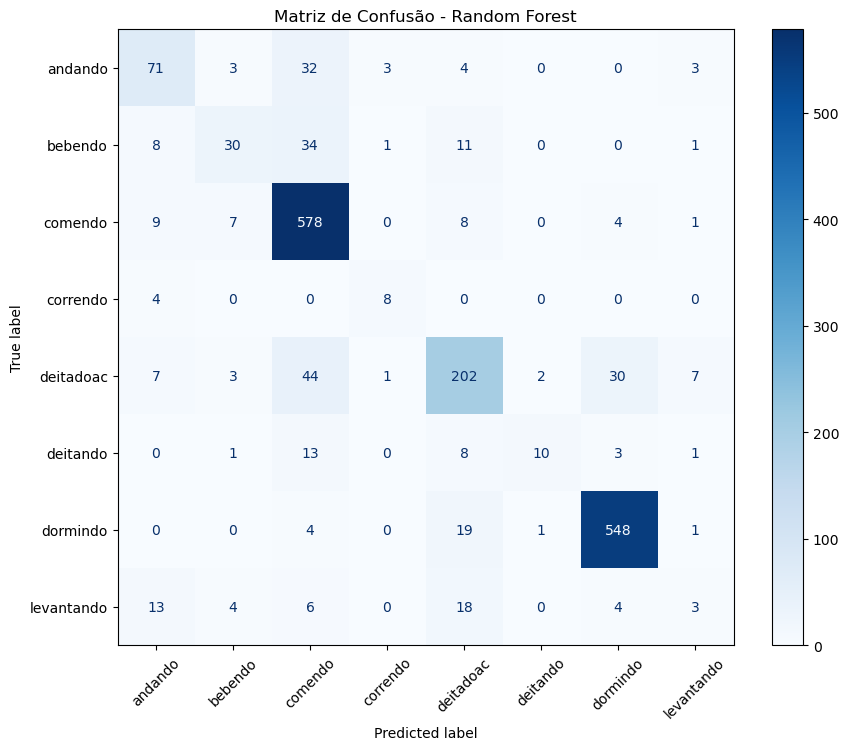


Top features mais importantes:
max_corr_xz         0.077586
std_diff            0.046951
log_razao_var_ac    0.045329
max_corr_xy         0.043790
AV                  0.042401
kurtosis            0.041414
rms_diff            0.041007
SQ                  0.040033
Median_f            0.037094
std                 0.035462
peak_count          0.034440
median              0.033656
MAX_f               0.033484
mean                0.033345
SD_f                0.030704
energia_fim         0.029707
energia_ini         0.029026
min                 0.028920
max                 0.028674
RMS_f               0.028305
RG_f                0.028187
diff_var            0.028109
skewness            0.027118
FQ                  0.022696
max_min_diff        0.022126
max_diff            0.021682
min_diff            0.021193
mean_diff           0.019385
delta_energia       0.018076
MIN_f               0.015057
DC                  0.015045
dtype: float64


In [52]:
import pandas as pd
import numpy as np
from scipy.stats import skew, kurtosis
from scipy.signal import find_peaks
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# --- 1. FUNÇÃO DE EXTRAÇÃO COMPLETA (HÍBRIDA + NOVAS FEATURES) ---
def extrair_features_hibridas(grupo):
    # Dados brutos
    ax = grupo['AX'].values
    ay = grupo['AY'].values
    az = grupo['AZ'].values
    vm = np.sqrt(ax**2 + ay**2 + az**2)
    n = len(vm)

    # Segurança para janelas pequenas
    ponta = max(3, int(n * 0.2))

    # --- MÉTRICAS DE TRANSIÇÃO ---
    v_ini = np.var(vm[:ponta] - np.mean(vm[:ponta]))
    v_fim = np.var(vm[-ponta:] - np.mean(vm[-ponta:]))

    log_razao_var_ac = np.log((v_fim + 1e-6) / (v_ini + 1e-6))
    diff_var = v_fim - v_ini

    energia_ini = np.sum(vm[:ponta]**2)
    energia_fim = np.sum(vm[-ponta:]**2)
    delta_energia = energia_fim - energia_ini

    # --- DERIVADAS DA MAGNITUDE ---
    diff_vm = np.diff(vm) if len(vm) > 1 else np.array([0.0])

    mean_diff = np.mean(diff_vm)
    std_diff = np.std(diff_vm)
    max_diff = np.max(diff_vm)
    min_diff = np.min(diff_vm)
    rms_diff = np.sqrt(np.mean(diff_vm**2))

    # --- FEATURES TEMPORAIS ORIGINAIS ---
    peak_count = len(find_peaks(vm, height=np.mean(vm))[0])

    # --- FFT ---
    vm_centralizado = vm - np.mean(vm)
    fft_vals = np.abs(np.fft.rfft(vm_centralizado))
    sorted_f = np.sort(fft_vals)
    N_fft = len(fft_vals)

    # --- CORRELAÇÕES ---
    corr_xy = np.max(np.correlate(ax, ay, mode='full'))
    corr_xz = np.max(np.correlate(ax, az, mode='full'))

    features = {
        # Temporais básicas
        'mean': np.mean(vm),
        'std': np.std(vm),
        'min': np.min(vm),
        'max': np.max(vm),
        'max_min_diff': np.max(vm) - np.min(vm),
        'median': np.median(vm),
        'peak_count': peak_count,
        'skewness': skew(vm),
        'kurtosis': kurtosis(vm),

        # Frequência (FFT)
        'AV': np.mean(fft_vals) if N_fft > 0 else 0,
        'DC': fft_vals[0] if N_fft > 0 else 0,
        'SD_f': np.std(fft_vals) if N_fft > 0 else 0,
        'MIN_f': np.min(fft_vals) if N_fft > 0 else 0,
        'MAX_f': np.max(fft_vals) if N_fft > 0 else 0,
        'RG_f': (np.max(fft_vals) - np.mean(fft_vals)) if N_fft > 0 else 0,
        'FQ': sorted_f[int(N_fft / 4)] if N_fft > 4 else 0,
        'SQ': sorted_f[int(N_fft / 2)] if N_fft > 2 else 0,
        'RMS_f': np.sqrt(np.mean(fft_vals**2)) if N_fft > 0 else 0,
        'Median_f': np.median(fft_vals) if N_fft > 0 else 0,

        # Correlações
        'max_corr_xy': corr_xy,
        'max_corr_xz': corr_xz,

        # Novas features de transição
        'log_razao_var_ac': log_razao_var_ac,
        'diff_var': diff_var,
        'energia_ini': energia_ini,
        'energia_fim': energia_fim,
        'delta_energia': delta_energia,

        # Novas features da derivada
        'mean_diff': mean_diff,
        'std_diff': std_diff,
        'max_diff': max_diff,
        'min_diff': min_diff,
        'rms_diff': rms_diff
    }

    return pd.Series(features)

# --- 2. CARREGAMENTO E EXTRAÇÃO ---
caminho_dataset = r'C:\Users\franc\OneDrive\Desktop\dataset_treinamento_suinos.xlsx'
df_bruto = pd.read_excel(caminho_dataset)

print("Extraindo características híbridas com novas métricas...")
df_features = df_bruto.groupby('janela').apply(extrair_features_hibridas, include_groups=False)

# Adiciona o rótulo da atividade
df_features['atividade'] = df_bruto.groupby('janela')['atividade'].first()

# Limpeza por segurança
df_features = df_features.replace([np.inf, -np.inf], np.nan).dropna()

print("Shape do dataset de features:", df_features.shape)
print("\nColunas das features:")
print(df_features.columns.tolist())

# --- 3. PREPARAÇÃO DOS DADOS ---
X = df_features.drop('atividade', axis=1)
y = df_features['atividade']

le = LabelEncoder()
y_encoded = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.25,
    random_state=42,
    stratify=y_encoded
)

# --- 4. MODELO RANDOM FOREST ---
model = RandomForestClassifier(
    n_estimators=300,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

# --- 5. RESULTADOS ---
y_pred = model.predict(X_test)

print("\nRelatório Final (Random Forest):")
print(classification_report(y_test, y_pred, target_names=le.classes_))

# Matriz de confusão
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=le.classes_,
    cmap='Blues',
    xticks_rotation=45,
    ax=ax
)
plt.title('Matriz de Confusão - Random Forest')
plt.show()

# --- 6. IMPORTÂNCIA DAS FEATURES ---
importancias = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("\nTop features mais importantes:")
print(importancias)

Extraindo características híbridas com novas métricas...
Shape do dataset de features: (7090, 32)

Colunas das features:
['mean', 'std', 'min', 'max', 'max_min_diff', 'median', 'peak_count', 'skewness', 'kurtosis', 'AV', 'DC', 'SD_f', 'MIN_f', 'MAX_f', 'RG_f', 'FQ', 'SQ', 'RMS_f', 'Median_f', 'max_corr_xy', 'max_corr_xz', 'log_razao_var_ac', 'diff_var', 'energia_ini', 'energia_fim', 'delta_energia', 'mean_diff', 'std_diff', 'max_diff', 'min_diff', 'rms_diff', 'atividade']

Relatório Final (Random Forest):
              precision    recall  f1-score   support

     andando       0.63      0.61      0.62       116
     bebendo       0.62      0.35      0.45        85
     comendo       0.81      0.95      0.88       607
    correndo       0.62      0.67      0.64        12
   deitadoac       0.75      0.68      0.71       296
    deitando       0.77      0.28      0.41        36
    dormindo       0.93      0.96      0.94       573
  levantando       0.18      0.06      0.09        48

 

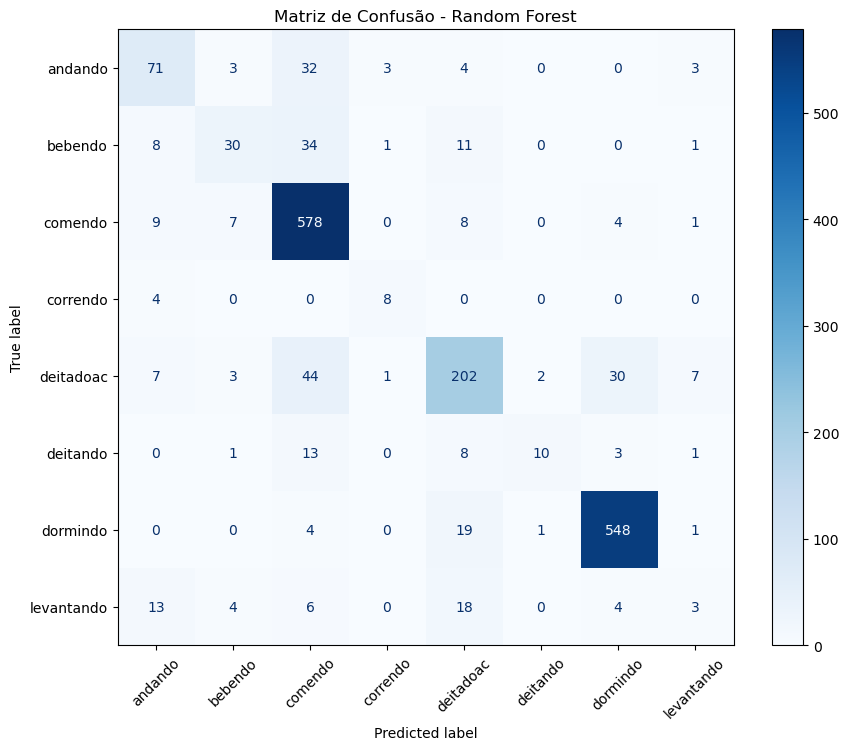


Top features mais importantes:
max_corr_xz         0.077586
std_diff            0.046951
log_razao_var_ac    0.045329
max_corr_xy         0.043790
AV                  0.042401
kurtosis            0.041414
rms_diff            0.041007
SQ                  0.040033
Median_f            0.037094
std                 0.035462
peak_count          0.034440
median              0.033656
MAX_f               0.033484
mean                0.033345
SD_f                0.030704
energia_fim         0.029707
energia_ini         0.029026
min                 0.028920
max                 0.028674
RMS_f               0.028305
RG_f                0.028187
diff_var            0.028109
skewness            0.027118
FQ                  0.022696
max_min_diff        0.022126
max_diff            0.021682
min_diff            0.021193
mean_diff           0.019385
delta_energia       0.018076
MIN_f               0.015057
DC                  0.015045
dtype: float64


In [53]:
import pandas as pd
import numpy as np
from scipy.stats import skew, kurtosis
from scipy.signal import find_peaks
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# --- 1. FUNÇÃO DE EXTRAÇÃO COMPLETA (HÍBRIDA + NOVAS FEATURES) ---
def extrair_features_hibridas(grupo):
    # Dados brutos
    ax = grupo['AX'].values
    ay = grupo['AY'].values
    az = grupo['AZ'].values
    vm = np.sqrt(ax**2 + ay**2 + az**2)
    n = len(vm)

    # Segurança para janelas pequenas
    ponta = max(3, int(n * 0.2))

    # --- MÉTRICAS DE TRANSIÇÃO ---
    v_ini = np.var(vm[:ponta] - np.mean(vm[:ponta]))
    v_fim = np.var(vm[-ponta:] - np.mean(vm[-ponta:]))

    log_razao_var_ac = np.log((v_fim + 1e-6) / (v_ini + 1e-6))
    diff_var = v_fim - v_ini

    energia_ini = np.sum(vm[:ponta]**2)
    energia_fim = np.sum(vm[-ponta:]**2)
    delta_energia = energia_fim - energia_ini

    # --- DERIVADAS DA MAGNITUDE ---
    diff_vm = np.diff(vm) if len(vm) > 1 else np.array([0.0])

    mean_diff = np.mean(diff_vm)
    std_diff = np.std(diff_vm)
    max_diff = np.max(diff_vm)
    min_diff = np.min(diff_vm)
    rms_diff = np.sqrt(np.mean(diff_vm**2))

    # --- FEATURES TEMPORAIS ORIGINAIS ---
    peak_count = len(find_peaks(vm, height=np.mean(vm))[0])

    # --- FFT ---
    vm_centralizado = vm - np.mean(vm)
    fft_vals = np.abs(np.fft.rfft(vm_centralizado))
    sorted_f = np.sort(fft_vals)
    N_fft = len(fft_vals)

    # --- CORRELAÇÕES ---
    corr_xy = np.max(np.correlate(ax, ay, mode='full'))
    corr_xz = np.max(np.correlate(ax, az, mode='full'))

    features = {
        # Temporais básicas
        'mean': np.mean(vm),
        'std': np.std(vm),
        'min': np.min(vm),
        'max': np.max(vm),
        'max_min_diff': np.max(vm) - np.min(vm),
        'median': np.median(vm),
        'peak_count': peak_count,
        'skewness': skew(vm),
        'kurtosis': kurtosis(vm),

        # Frequência (FFT)
        'AV': np.mean(fft_vals) if N_fft > 0 else 0,
        'DC': fft_vals[0] if N_fft > 0 else 0,
        'SD_f': np.std(fft_vals) if N_fft > 0 else 0,
        'MIN_f': np.min(fft_vals) if N_fft > 0 else 0,
        'MAX_f': np.max(fft_vals) if N_fft > 0 else 0,
        'RG_f': (np.max(fft_vals) - np.mean(fft_vals)) if N_fft > 0 else 0,
        'FQ': sorted_f[int(N_fft / 4)] if N_fft > 4 else 0,
        'SQ': sorted_f[int(N_fft / 2)] if N_fft > 2 else 0,
        'RMS_f': np.sqrt(np.mean(fft_vals**2)) if N_fft > 0 else 0,
        'Median_f': np.median(fft_vals) if N_fft > 0 else 0,

        # Correlações
        'max_corr_xy': corr_xy,
        'max_corr_xz': corr_xz,
        'max_corr_yz': corr_yz,

        # Novas features de transição
        'log_razao_var_ac': log_razao_var_ac,
        'diff_var': diff_var,
        'energia_ini': energia_ini,
        'energia_fim': energia_fim,
        'delta_energia': delta_energia,

        # Novas features da derivada
        'mean_diff': mean_diff,
        'std_diff': std_diff,
        'max_diff': max_diff,
        'min_diff': min_diff,
        'rms_diff': rms_diff
    }

    return pd.Series(features)

# --- 2. CARREGAMENTO E EXTRAÇÃO ---
caminho_dataset = r'C:\Users\franc\OneDrive\Desktop\dataset_treinamento_suinos.xlsx'
df_bruto = pd.read_excel(caminho_dataset)

print("Extraindo características híbridas com novas métricas...")
df_features = df_bruto.groupby('janela').apply(extrair_features_hibridas, include_groups=False)

# Adiciona o rótulo da atividade
df_features['atividade'] = df_bruto.groupby('janela')['atividade'].first()

# Limpeza por segurança
df_features = df_features.replace([np.inf, -np.inf], np.nan).dropna()

print("Shape do dataset de features:", df_features.shape)
print("\nColunas das features:")
print(df_features.columns.tolist())

# --- 3. PREPARAÇÃO DOS DADOS ---
X = df_features.drop('atividade', axis=1)
y = df_features['atividade']

le = LabelEncoder()
y_encoded = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.25,
    random_state=42,
    stratify=y_encoded
)

# --- 4. MODELO RANDOM FOREST ---
model = RandomForestClassifier(
    n_estimators=300,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

# --- 5. RESULTADOS ---
y_pred = model.predict(X_test)

print("\nRelatório Final (Random Forest):")
print(classification_report(y_test, y_pred, target_names=le.classes_))

# Matriz de confusão
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=le.classes_,
    cmap='Blues',
    xticks_rotation=45,
    ax=ax
)
plt.title('Matriz de Confusão - Random Forest')
plt.show()

# --- 6. IMPORTÂNCIA DAS FEATURES ---
importancias = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("\nTop features mais importantes:")
print(importancias)

Shape original da planilha: (709000, 8)

Quantidade de janelas por classe após limitação:


C:\Users\franc\AppData\Local\Temp\ipykernel_25944\4292119490.py:228: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(n=min(len(g), max_janelas_por_classe), random_state=random_state))


atividade
andando       400
deitadoac     400
dormindo      400
comendo       400
bebendo       338
levantando    193
deitando      145
correndo       50
Name: count, dtype: int64

Shape do df filtrado: (232600, 8)

Extraindo características dinâmicas...

Shape do dataset de features: (2326, 63)
Total de colunas: 63

Distribuição das classes no treino antes do SMOTE:
0    300
1    253
2    300
3     37
4    300
5    109
6    300
7    145
Name: count, dtype: int64

Distribuição das classes no treino depois do SMOTE:
0    300
1    300
2    300
3    300
4    300
5    300
6    300
7    300
Name: count, dtype: int64

Relatório Final (Random Forest + SMOTE + Features Dinâmicas + limite de 400 janelas/classe):
              precision    recall  f1-score   support

     andando       0.63      0.74      0.68       100
     bebendo       0.57      0.66      0.61        85
     comendo       0.81      0.77      0.79       100
    correndo       0.75      0.92      0.83        13
   deitadoac    

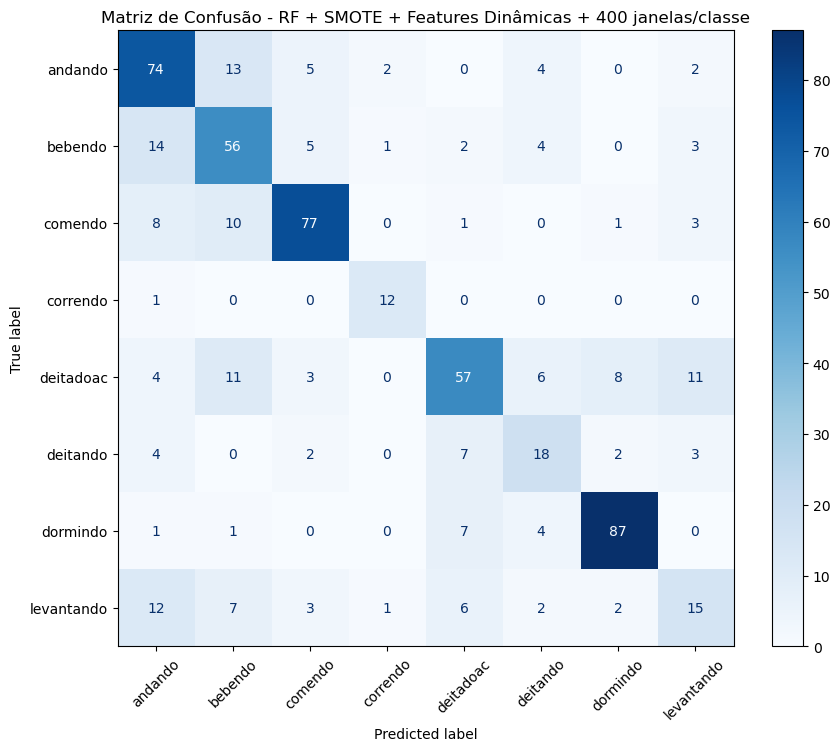


Top 20 features mais importantes:
max_corr_xz         0.054705
std_diff            0.037911
rms_diff            0.033894
max_corr_xy         0.027688
kurtosis            0.027641
SQ                  0.027190
Median_f            0.026420
FQ                  0.024848
std_fim             0.024591
AV                  0.024294
MAX_f               0.024117
SD_f                0.024037
RMS_f               0.023569
peak_count          0.023326
var_fim             0.022944
std                 0.021899
log_razao_var_13    0.021292
RG_f                0.020974
max_corr_yz         0.018864
min_fim             0.017751
dtype: float64


In [56]:
import pandas as pd
import numpy as np
from scipy.stats import skew, kurtosis
from scipy.signal import find_peaks
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from imblearn.over_sampling import SMOTE
import matplotlib.pyplot as plt

# --- 1. FUNÇÃO DE EXTRAÇÃO COMPLETA ---
def extrair_features_hibridas_dinamicas(grupo):
    ax = grupo['AX'].values
    ay = grupo['AY'].values
    az = grupo['AZ'].values
    vm = np.sqrt(ax**2 + ay**2 + az**2)
    n = len(vm)

    # Como suas janelas têm 100 pontos, usamos 3 blocos fixos
    parte1 = vm[:30]
    parte2 = vm[30:70]
    parte3 = vm[70:]

    # Segurança
    if len(parte1) == 0:
        parte1 = vm
    if len(parte2) == 0:
        parte2 = vm
    if len(parte3) == 0:
        parte3 = vm

    # --- ESTATÍSTICAS GLOBAIS ---
    mean_vm = np.mean(vm)
    std_vm = np.std(vm)
    min_vm = np.min(vm)
    max_vm = np.max(vm)
    median_vm = np.median(vm)
    peak_count = len(find_peaks(vm, height=np.mean(vm))[0])
    skew_vm = skew(vm)
    kurt_vm = kurtosis(vm)

    # --- DINÂMICA POR PARTES ---
    mean_inicio = np.mean(parte1)
    mean_meio = np.mean(parte2)
    mean_fim = np.mean(parte3)

    std_inicio = np.std(parte1)
    std_meio = np.std(parte2)
    std_fim = np.std(parte3)

    var_inicio = np.var(parte1)
    var_meio = np.var(parte2)
    var_fim = np.var(parte3)

    max_inicio = np.max(parte1)
    max_meio = np.max(parte2)
    max_fim = np.max(parte3)

    min_inicio = np.min(parte1)
    min_meio = np.min(parte2)
    min_fim = np.min(parte3)

    # --- TRANSIÇÕES ENTRE PARTES ---
    delta_mean_12 = mean_meio - mean_inicio
    delta_mean_23 = mean_fim - mean_meio
    delta_mean_13 = mean_fim - mean_inicio

    delta_std_12 = std_meio - std_inicio
    delta_std_23 = std_fim - std_meio
    delta_std_13 = std_fim - std_inicio

    delta_var_12 = var_meio - var_inicio
    delta_var_23 = var_fim - var_meio
    delta_var_13 = var_fim - var_inicio

    # Razão logarítmica da variância início/fim
    log_razao_var_13 = np.log((var_fim + 1e-6) / (var_inicio + 1e-6))

    # --- ENERGIA ---
    energia_total = np.sum(vm**2)
    energia_inicio = np.sum(parte1**2)
    energia_meio = np.sum(parte2**2)
    energia_fim = np.sum(parte3**2)

    delta_energia_12 = energia_meio - energia_inicio
    delta_energia_23 = energia_fim - energia_meio
    delta_energia_13 = energia_fim - energia_inicio

    # --- DERIVADAS / TENDÊNCIA ---
    diff_vm = np.diff(vm) if len(vm) > 1 else np.array([0.0])

    mean_diff = np.mean(diff_vm)
    std_diff = np.std(diff_vm)
    max_diff = np.max(diff_vm)
    min_diff = np.min(diff_vm)
    rms_diff = np.sqrt(np.mean(diff_vm**2))

    # Tendência linear aproximada
    x_idx = np.arange(n)
    trend = np.polyfit(x_idx, vm, 1)[0] if n > 1 else 0.0

    # Onde acontecem extremos
    idx_max = np.argmax(vm)
    idx_min = np.argmin(vm)

    # --- FFT ---
    vm_centralizado = vm - np.mean(vm)
    fft_vals = np.abs(np.fft.rfft(vm_centralizado))
    sorted_f = np.sort(fft_vals)
    N_fft = len(fft_vals)

    AV = np.mean(fft_vals) if N_fft > 0 else 0
    DC = fft_vals[0] if N_fft > 0 else 0
    SD_f = np.std(fft_vals) if N_fft > 0 else 0
    MIN_f = np.min(fft_vals) if N_fft > 0 else 0
    MAX_f = np.max(fft_vals) if N_fft > 0 else 0
    RG_f = (np.max(fft_vals) - np.mean(fft_vals)) if N_fft > 0 else 0
    FQ = sorted_f[int(N_fft / 4)] if N_fft > 4 else 0
    SQ = sorted_f[int(N_fft / 2)] if N_fft > 2 else 0
    RMS_f = np.sqrt(np.mean(fft_vals**2)) if N_fft > 0 else 0
    Median_f = np.median(fft_vals) if N_fft > 0 else 0

    # --- CORRELAÇÕES ---
    corr_xy = np.max(np.correlate(ax, ay, mode='full'))
    corr_xz = np.max(np.correlate(ax, az, mode='full'))
    corr_yz = np.max(np.correlate(ay, az, mode='full'))

    features = {
        # Globais
        'mean': mean_vm,
        'std': std_vm,
        'min': min_vm,
        'max': max_vm,
        'max_min_diff': max_vm - min_vm,
        'median': median_vm,
        'peak_count': peak_count,
        'skewness': skew_vm,
        'kurtosis': kurt_vm,

        # Partes
        'mean_inicio': mean_inicio,
        'mean_meio': mean_meio,
        'mean_fim': mean_fim,
        'std_inicio': std_inicio,
        'std_meio': std_meio,
        'std_fim': std_fim,
        'var_inicio': var_inicio,
        'var_meio': var_meio,
        'var_fim': var_fim,
        'max_inicio': max_inicio,
        'max_meio': max_meio,
        'max_fim': max_fim,
        'min_inicio': min_inicio,
        'min_meio': min_meio,
        'min_fim': min_fim,

        # Transições
        'delta_mean_12': delta_mean_12,
        'delta_mean_23': delta_mean_23,
        'delta_mean_13': delta_mean_13,
        'delta_std_12': delta_std_12,
        'delta_std_23': delta_std_23,
        'delta_std_13': delta_std_13,
        'delta_var_12': delta_var_12,
        'delta_var_23': delta_var_23,
        'delta_var_13': delta_var_13,
        'log_razao_var_13': log_razao_var_13,

        # Energia
        'energia_total': energia_total,
        'energia_inicio': energia_inicio,
        'energia_meio': energia_meio,
        'energia_fim': energia_fim,
        'delta_energia_12': delta_energia_12,
        'delta_energia_23': delta_energia_23,
        'delta_energia_13': delta_energia_13,

        # Derivadas / tendência
        'mean_diff': mean_diff,
        'std_diff': std_diff,
        'max_diff': max_diff,
        'min_diff': min_diff,
        'rms_diff': rms_diff,
        'trend': trend,
        'idx_max': idx_max,
        'idx_min': idx_min,

        # FFT
        'AV': AV,
        'DC': DC,
        'SD_f': SD_f,
        'MIN_f': MIN_f,
        'MAX_f': MAX_f,
        'RG_f': RG_f,
        'FQ': FQ,
        'SQ': SQ,
        'RMS_f': RMS_f,
        'Median_f': Median_f,

        # Correlações
        'max_corr_xy': corr_xy,
        'max_corr_xz': corr_xz,
        'max_corr_yz': corr_yz
    }

    return pd.Series(features)

# --- 2. CARREGAMENTO DA PLANILHA ---
caminho_dataset = r'C:\Users\franc\OneDrive\Desktop\dataset_treinamento_suinos.xlsx'
df_bruto = pd.read_excel(caminho_dataset)

print("Shape original da planilha:", df_bruto.shape)

# --- 3. LIMITAR A 400 JANELAS POR CLASSE (SEM ALTERAR A PLANILHA) ---
max_janelas_por_classe = 400
random_state = 42

# Pega uma tabela com uma linha por janela e sua atividade
janelas_classes = (
    df_bruto.groupby('janela', as_index=False)['atividade']
    .first()
)

# Amostra aleatoriamente até 400 janelas por classe
janelas_selecionadas = (
    janelas_classes.groupby('atividade', group_keys=False)
    .apply(lambda g: g.sample(n=min(len(g), max_janelas_por_classe), random_state=random_state))
    .reset_index(drop=True)
)

# Filtra o bruto para manter apenas as janelas selecionadas
df_filtrado = df_bruto[df_bruto['janela'].isin(janelas_selecionadas['janela'])].copy()

print("\nQuantidade de janelas por classe após limitação:")
print(df_filtrado.groupby('janela')['atividade'].first().value_counts())

print("\nShape do df filtrado:", df_filtrado.shape)

# --- 4. EXTRAÇÃO DE FEATURES ---
print("\nExtraindo características dinâmicas...")
df_features = df_filtrado.groupby('janela').apply(
    extrair_features_hibridas_dinamicas,
    include_groups=False
)

df_features['atividade'] = df_filtrado.groupby('janela')['atividade'].first()

# Limpeza
df_features = df_features.replace([np.inf, -np.inf], np.nan).dropna()

print("\nShape do dataset de features:", df_features.shape)
print(f"Total de colunas: {len(df_features.columns)}")

# --- 5. PREPARAÇÃO DOS DADOS ---
X = df_features.drop('atividade', axis=1)
y = df_features['atividade']

le = LabelEncoder()
y_encoded = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.25,
    random_state=42,
    stratify=y_encoded
)

print("\nDistribuição das classes no treino antes do SMOTE:")
print(pd.Series(y_train).value_counts().sort_index())

# --- 6. SMOTE ---
smote = SMOTE(random_state=42, k_neighbors=3)
X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)

print("\nDistribuição das classes no treino depois do SMOTE:")
print(pd.Series(y_train_bal).value_counts().sort_index())

# --- 7. RANDOM FOREST ---
model = RandomForestClassifier(
    n_estimators=400,
    max_depth=18,
    min_samples_split=4,
    min_samples_leaf=2,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

model.fit(X_train_bal, y_train_bal)

# --- 8. RESULTADOS ---
y_pred = model.predict(X_test)

print("\nRelatório Final (Random Forest + SMOTE + Features Dinâmicas + limite de 400 janelas/classe):")
print(classification_report(y_test, y_pred, target_names=le.classes_))

fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=le.classes_,
    cmap='Blues',
    xticks_rotation=45,
    ax=ax
)
plt.title('Matriz de Confusão - RF + SMOTE + Features Dinâmicas + 400 janelas/classe')
plt.show()

# --- 9. IMPORTÂNCIA DAS FEATURES ---
importancias = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("\nTop 20 features mais importantes:")
print(importancias.head(20))

Classes após remoção:
atividade
comendo      242700
dormindo     229000
deitadoac    118500
andando       46200
bebendo       33800
correndo       5000
Name: count, dtype: int64
Extraindo features...

Classes no modelo:
0 -> andando
1 -> bebendo
2 -> comendo
3 -> correndo
4 -> deitadoac
5 -> dormindo

Relatório Final (Logística SEM deitando e levantando):
              precision    recall  f1-score   support

     andando       0.55      0.69      0.61       115
     bebendo       0.42      0.60      0.49        84
     comendo       0.90      0.83      0.86       607
    correndo       0.50      1.00      0.67        13
   deitadoac       0.59      0.46      0.52       296
    dormindo       0.83      0.89      0.86       573

    accuracy                           0.76      1688
   macro avg       0.63      0.74      0.67      1688
weighted avg       0.77      0.76      0.76      1688



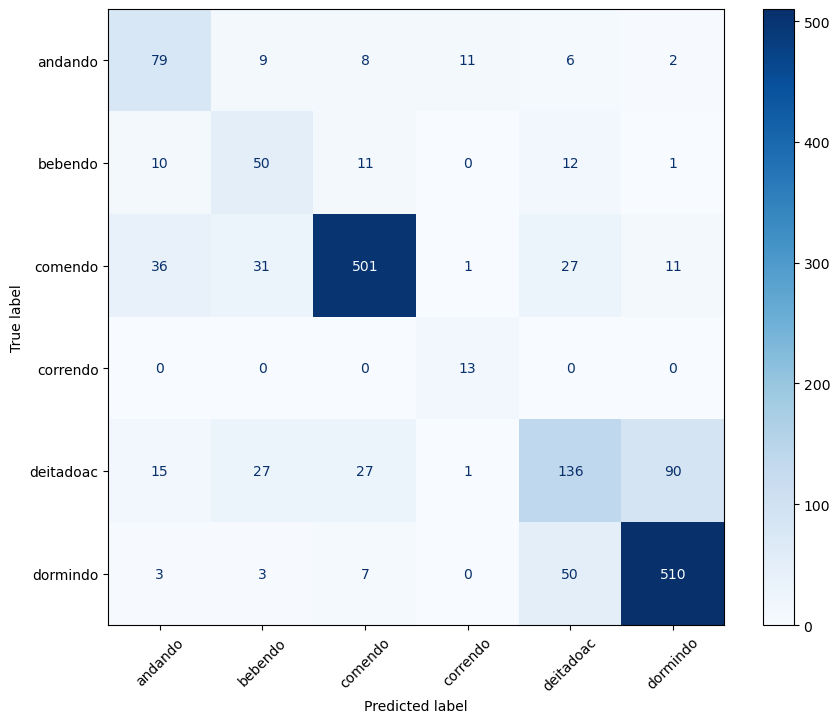

In [4]:
import pandas as pd
import numpy as np
from scipy.stats import skew, kurtosis
from scipy.signal import find_peaks
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# --- 1. FUNÇÃO ORIGINAL (SEM ALTERAÇÕES) ---
def extrair_features_hibridas(grupo):
    ax = grupo['AX'].values
    ay = grupo['AY'].values
    az = grupo['AZ'].values
    vm = np.sqrt(ax**2 + ay**2 + az**2)
    n = len(vm)
    
    ponta = int(n * 0.2)
    v_ini = np.var(vm[:ponta] - np.mean(vm[:ponta]))
    v_fim = np.var(vm[-ponta:] - np.mean(vm[-ponta:]))
    razao_var_ac = v_fim / (v_ini + 1e-6)
    
    delta_z = np.mean(az[-15:]) - np.mean(az[:15])

    fft_vals = np.abs(np.fft.rfft(vm - np.mean(vm)))
    sorted_f = np.sort(fft_vals)
    N_fft = len(fft_vals)
    
    corr_xy = np.max(np.correlate(ax, ay, mode='full'))
    corr_xz = np.max(np.correlate(ax, az, mode='full'))
    corr_yz = np.max(np.correlate(ay, az, mode='full'))
    
    features = {
        'mean': np.mean(vm),
        'std': np.std(vm),
        'min': np.min(vm),
        'max': np.max(vm),
        'max_min_diff': np.max(vm) - np.min(vm),
        'median': np.median(vm),
        'peak_count': len(find_peaks(vm, height=np.mean(vm))[0]),
        'skewness': skew(vm),
        'kurtosis': kurtosis(vm),
        
        'AV': np.mean(fft_vals),
        'DC': fft_vals[0],
        'SD_f': np.std(fft_vals),
        'MIN_f': np.min(fft_vals),
        'MAX_f': np.max(fft_vals),
        'RG_f': np.max(fft_vals) - np.mean(fft_vals),
        'FQ': sorted_f[int(N_fft/4)] if N_fft > 4 else 0, 
        'SQ': sorted_f[int(N_fft/2)] if N_fft > 2 else 0,
        'RMS_f': np.sqrt(np.mean(fft_vals**2)),
        'Median_f': np.median(fft_vals),
        
        'max_corr_xy': corr_xy,
        'max_corr_xz': corr_xz,
        'max_corr_yz': corr_yz,     
        
        'razao_var_ac': razao_var_ac,
        'delta_z': delta_z
    }
    return pd.Series(features)

# --- 2. CARREGAMENTO ---
caminho_dataset = r'C:\Users\franc\OneDrive\Desktop\dataset_treinamento_suinos.xlsx'
df_bruto = pd.read_excel(caminho_dataset)

# 🔥 REMOÇÃO DAS CLASSES (ÚNICA MUDANÇA)
classes_remover = ['deitando', 'levantando']
df_bruto = df_bruto[~df_bruto['atividade'].isin(classes_remover)].copy()

print("Classes após remoção:")
print(df_bruto['atividade'].value_counts())

# --- 3. EXTRAÇÃO (IGUAL AO SEU) ---
print("Extraindo features...")
df_features = df_bruto.groupby('janela').apply(extrair_features_hibridas, include_groups=False)
df_features['atividade'] = df_bruto.groupby('janela')['atividade'].first()

# --- 4. PREPARAÇÃO (IGUAL AO SEU) ---
X = df_features.drop('atividade', axis=1)
y = df_features['atividade']

le = LabelEncoder()
y_encoded = le.fit_transform(y)

print("\nClasses no modelo:")
for i, c in enumerate(le.classes_):
    print(f"{i} -> {c}")

# --- 5. SPLIT ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.25,
    random_state=42,
    stratify=y_encoded
)

# --- 6. ESCALONAMENTO ---
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# --- 7. MODELO (IGUAL AO SEU) ---
model = LogisticRegression(
    solver='saga',
    max_iter=5000,
    class_weight='balanced',
    C=0.6
)

model.fit(X_train_scaled, y_train)

# --- 8. RESULTADOS ---
y_pred = model.predict(X_test_scaled)

print("\nRelatório Final (Logística SEM deitando e levantando):")
print(classification_report(y_test, y_pred, target_names=le.classes_))

fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=le.classes_,
    cmap='Blues',
    xticks_rotation=45,
    ax=ax
)
plt.show()

# Extração de Features basicas

In [ ]:
Testes com dataset 7000 janelas

# Caracteristicas temporais

Dataset carregado: (709000, 8)

Classes após remoção:
atividade
comendo      242700
dormindo     229000
deitadoac    118500
andando       46200
bebendo       33800
correndo       5000
Name: count, dtype: int64


C:\Users\franc\AppData\Local\Temp\ipykernel_20436\745661792.py:34: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  janelas_sel = janelas.groupby('atividade', group_keys=False).apply(



Quantidade de janelas por classe após limitação:
atividade
andando      400
deitadoac    400
dormindo     400
comendo      400
bebendo      338
correndo      50
Name: count, dtype: int64


C:\Users\franc\AppData\Local\Temp\ipykernel_20436\745661792.py:63: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_features = df_filtrado.groupby('janela').apply(extrair_features).reset_index()



Shape de df_features: (1988, 12)

Distribuição final:
atividade
andando      400
deitadoac    400
dormindo     400
comendo      400
bebendo      338
correndo      50
Name: count, dtype: int64

Classes no modelo:
0 -> andando
1 -> bebendo
2 -> comendo
3 -> correndo
4 -> deitadoac
5 -> dormindo

Relatório Final (Logística | sem deitando e levantando | limite 400 janelas):
              precision    recall  f1-score   support

     andando       0.71      0.66      0.68       100
     bebendo       0.40      0.39      0.40        85
     comendo       0.60      0.64      0.62       100
    correndo       0.71      1.00      0.83        12
   deitadoac       0.56      0.40      0.47       100
    dormindo       0.69      0.88      0.78       100

    accuracy                           0.61       497
   macro avg       0.61      0.66      0.63       497
weighted avg       0.60      0.61      0.60       497



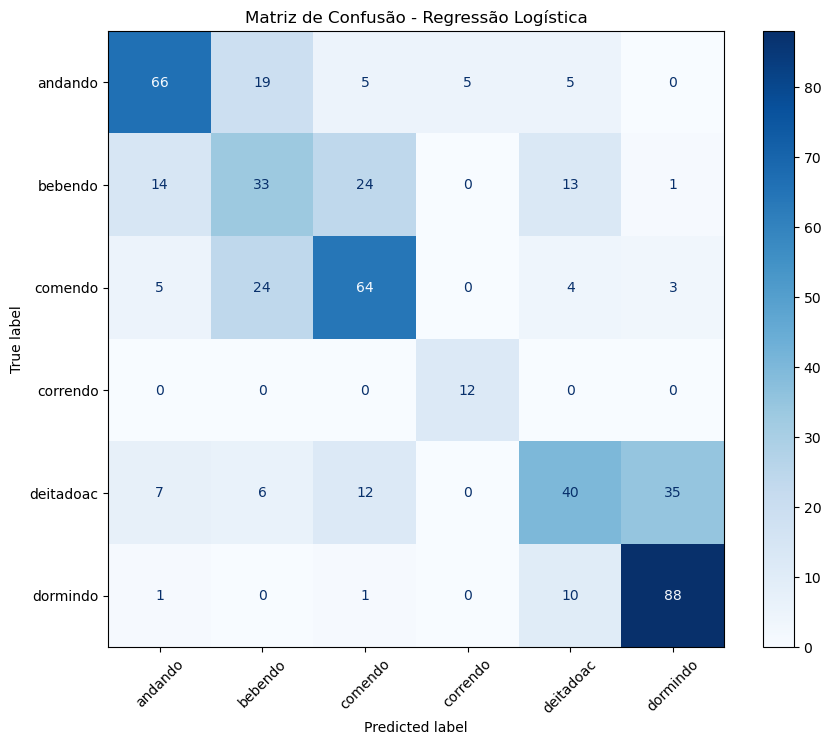

In [8]:
import pandas as pd
import numpy as np
from scipy.stats import skew, kurtosis
from scipy.signal import find_peaks
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# =========================
# 1. CARREGAMENTO
# =========================
caminho_arquivo = r'C:\Users\franc\OneDrive\Desktop\dataset_treinamento_suinos.xlsx'
df_final = pd.read_excel(caminho_arquivo)

print("Dataset carregado:", df_final.shape)

# =========================
# 2. REMOVER CLASSES
# =========================
df_filtrado = df_final[~df_final['atividade'].isin(['deitando', 'levantando'])].copy()

print("\nClasses após remoção:")
print(df_filtrado['atividade'].value_counts())

# =========================
# 3. LIMITAR A 400 JANELAS POR CLASSE
# =========================
max_janelas = 400

janelas = df_filtrado.groupby('janela', as_index=False)['atividade'].first()

janelas_sel = janelas.groupby('atividade', group_keys=False).apply(
    lambda g: g.sample(n=min(len(g), max_janelas), random_state=42)
).reset_index(drop=True)

df_filtrado = df_filtrado[df_filtrado['janela'].isin(janelas_sel['janela'])].copy()

print("\nQuantidade de janelas por classe após limitação:")
print(df_filtrado.groupby('janela')['atividade'].first().value_counts())

# =========================
# 4. EXTRAÇÃO DAS FEATURES
# =========================
def extrair_features(grupo):
    vm = np.sqrt(grupo['AX']**2 + grupo['AY']**2 + grupo['AZ']**2)
    peaks, _ = find_peaks(vm, height=np.mean(vm))

    return pd.Series({
        'mean': vm.mean(),
        'std': vm.std(),
        'min': vm.min(),
        'max': vm.max(),
        'max_min_diff': vm.max() - vm.min(),
        'median': np.median(vm),
        'peak_count': len(peaks),
        'skewness': skew(vm),
        'kurtosis': kurtosis(vm),
        'sma': np.sum(np.abs(vm)) / len(vm)
    })

df_features = df_filtrado.groupby('janela').apply(extrair_features).reset_index()

atividades = df_filtrado.groupby('janela')['atividade'].first().reset_index(drop=True)
df_features['atividade'] = atividades

print("\nShape de df_features:", df_features.shape)
print("\nDistribuição final:")
print(df_features['atividade'].value_counts())

# =========================
# 5. PREPARAÇÃO DOS DADOS
# =========================
X = df_features.drop(columns=['janela', 'atividade'])
y = df_features['atividade']

le = LabelEncoder()
y_encoded = le.fit_transform(y)

print("\nClasses no modelo:")
for i, classe in enumerate(le.classes_):
    print(f"{i} -> {classe}")

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.25,
    random_state=42,
    stratify=y_encoded
)

# =========================
# 6. PADRONIZAÇÃO
# =========================
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# =========================
# 7. TREINO
# =========================
model = LogisticRegression(
    solver='saga',
    max_iter=5000,
    class_weight='balanced',
    C=0.6,
    random_state=42
)

model.fit(X_train_scaled, y_train)

# =========================
# 8. RESULTADOS
# =========================
y_pred = model.predict(X_test_scaled)

print("\nRelatório Final (Logística | sem deitando e levantando | limite 400 janelas):")
print(classification_report(y_test, y_pred, target_names=le.classes_))

fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=le.classes_,
    cmap='Blues',
    xticks_rotation=45,
    ax=ax
)
plt.title('Matriz de Confusão - Regressão Logística')
plt.show()

# Regressão Logistica com Lasso features extendidas, amostras limitadas a 400 por classe

Dataset carregado: (709000, 8)

Classes após remoção:
atividade
comendo      242700
dormindo     229000
deitadoac    118500
andando       46200
bebendo       33800
correndo       5000
Name: count, dtype: int64


C:\Users\franc\AppData\Local\Temp\ipykernel_20436\2549739313.py:34: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  janelas_sel = janelas.groupby('atividade', group_keys=False).apply(



Quantidade de janelas por classe após limitação:
atividade
andando      400
deitadoac    400
dormindo     400
comendo      400
bebendo      338
correndo      50
Name: count, dtype: int64


C:\Users\franc\AppData\Local\Temp\ipykernel_20436\2549739313.py:98: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_features = df_filtrado.groupby('janela').apply(extrair_features).reset_index()



Shape de df_features: (1988, 25)

Distribuição final:
atividade
andando      400
deitadoac    400
dormindo     400
comendo      400
bebendo      338
correndo      50
Name: count, dtype: int64

Classes no modelo:
0 -> andando
1 -> bebendo
2 -> comendo
3 -> correndo
4 -> deitadoac
5 -> dormindo

Relatório Final (Logística | sem deitando e levantando | limite 400 janelas | com FFT + correlações):
              precision    recall  f1-score   support

     andando       0.70      0.73      0.72       100
     bebendo       0.68      0.58      0.62        85
     comendo       0.70      0.78      0.74       100
    correndo       0.71      1.00      0.83        12
   deitadoac       0.67      0.45      0.54       100
    dormindo       0.70      0.88      0.78       100

    accuracy                           0.69       497
   macro avg       0.69      0.74      0.70       497
weighted avg       0.69      0.69      0.68       497



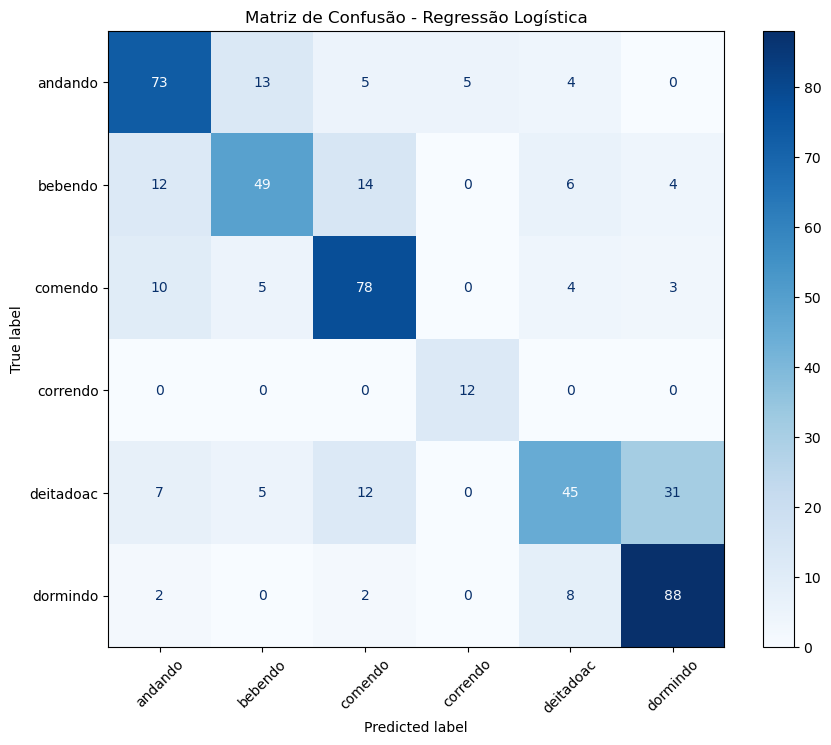

In [15]:
import pandas as pd
import numpy as np
from scipy.stats import skew, kurtosis
from scipy.signal import find_peaks
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# =========================
# 1. CARREGAMENTO
# =========================
caminho_arquivo = r'C:\Users\franc\OneDrive\Desktop\dataset_treinamento_suinos.xlsx'
df_final = pd.read_excel(caminho_arquivo)

print("Dataset carregado:", df_final.shape)

# =========================
# 2. REMOVER CLASSES
# =========================
df_filtrado = df_final[~df_final['atividade'].isin(['deitando', 'levantando'])].copy()

print("\nClasses após remoção:")
print(df_filtrado['atividade'].value_counts())

# =========================
# 3. LIMITAR A 400 JANELAS POR CLASSE
# =========================
max_janelas = 400

janelas = df_filtrado.groupby('janela', as_index=False)['atividade'].first()

janelas_sel = janelas.groupby('atividade', group_keys=False).apply(
    lambda g: g.sample(n=min(len(g), max_janelas), random_state=42)
).reset_index(drop=True)

df_filtrado = df_filtrado[df_filtrado['janela'].isin(janelas_sel['janela'])].copy()

print("\nQuantidade de janelas por classe após limitação:")
print(df_filtrado.groupby('janela')['atividade'].first().value_counts())

# =========================
# 4. EXTRAÇÃO DAS FEATURES
# =========================
def extrair_features(grupo):
    ax = grupo['AX'].values
    ay = grupo['AY'].values
    az = grupo['AZ'].values
    
    # Magnitude do vetor
    vm = np.sqrt(ax**2 + ay**2 + az**2)

    # Picos
    peaks, _ = find_peaks(vm, height=np.mean(vm))

    # FFT
    fft_vals = np.abs(np.fft.rfft(vm - np.mean(vm)))
    sorted_f = np.sort(fft_vals)
    N_fft = len(fft_vals)

    # Correlações
    corr_xy = np.max(np.correlate(ax, ay, mode='full'))
    corr_xz = np.max(np.correlate(ax, az, mode='full'))
    corr_yz = np.max(np.correlate(ay, az, mode='full'))

    return pd.Series({
        # Temporais
        'mean': np.mean(vm),
        'std': np.std(vm),
        'min': np.min(vm),
        'max': np.max(vm),
        'max_min_diff': np.max(vm) - np.min(vm),
        'median': np.median(vm),
        'peak_count': len(peaks),
        'skewness': skew(vm),
        'kurtosis': kurtosis(vm),
        'sma': np.sum(np.abs(vm)) / len(vm),

        # Frequência (FFT)
        'AV': np.mean(fft_vals) if N_fft > 0 else 0,
        'DC': fft_vals[0] if N_fft > 0 else 0,
        'SD_f': np.std(fft_vals) if N_fft > 0 else 0,
        'MIN_f': np.min(fft_vals) if N_fft > 0 else 0,
        'MAX_f': np.max(fft_vals) if N_fft > 0 else 0,
        'RG_f': (np.max(fft_vals) - np.mean(fft_vals)) if N_fft > 0 else 0,
        'FQ': sorted_f[int(N_fft / 4)] if N_fft > 4 else 0,
        'SQ': sorted_f[int(N_fft / 2)] if N_fft > 2 else 0,
        'RMS_f': np.sqrt(np.mean(fft_vals**2)) if N_fft > 0 else 0,
        'Median_f': np.median(fft_vals) if N_fft > 0 else 0,

        # Correlações
        'max_corr_xy': corr_xy,
        'max_corr_xz': corr_xz,
        'max_corr_yz': corr_yz,
    })

df_features = df_filtrado.groupby('janela').apply(extrair_features).reset_index()

atividades = df_filtrado.groupby('janela')['atividade'].first().reset_index(drop=True)
df_features['atividade'] = atividades

# limpeza por segurança
df_features = df_features.replace([np.inf, -np.inf], np.nan).dropna()

print("\nShape de df_features:", df_features.shape)
print("\nDistribuição final:")
print(df_features['atividade'].value_counts())

# =========================
# 5. PREPARAÇÃO DOS DADOS
# =========================
X = df_features.drop(columns=['janela', 'atividade'])
y = df_features['atividade']

le = LabelEncoder()
y_encoded = le.fit_transform(y)

print("\nClasses no modelo:")
for i, classe in enumerate(le.classes_):
    print(f"{i} -> {classe}")

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.25,
    random_state=42,
    stratify=y_encoded
)

# =========================
# 6. PADRONIZAÇÃO
# =========================
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# =========================
# 7. TREINO
# =========================
model = LogisticRegression(
    penalty='l1',
    solver='saga',
    max_iter=5000,
    class_weight='balanced',
    C=0.1,
    random_state=42
)

model.fit(X_train_scaled, y_train)

# =========================
# 8. RESULTADOS
# =========================
y_pred = model.predict(X_test_scaled)

print("\nRelatório Final (Logística | sem deitando e levantando | limite 400 janelas | com FFT + correlações):")
print(classification_report(y_test, y_pred, target_names=le.classes_))

fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=le.classes_,
    cmap='Blues',
    xticks_rotation=45,
    ax=ax
)
plt.title('Matriz de Confusão - Regressão Logística')
plt.show()



In [16]:
coef_df = pd.DataFrame(
    model.coef_,
    columns=X.columns,
    index=le.classes_
)

# média do peso absoluto
importancia = np.mean(np.abs(model.coef_), axis=0)

importancia_series = pd.Series(importancia, index=X.columns).sort_values(ascending=False)

print("\nFeatures mais importantes (LASSO):")
print(importancia_series)

print("\nFeatures removidas (coef = 0):")
print(importancia_series[importancia_series == 0])


Features mais importantes (LASSO):
min             0.811518
max_corr_xz     0.557540
kurtosis        0.320183
peak_count      0.291419
median          0.286295
FQ              0.262336
Median_f        0.257130
SQ              0.257130
max_corr_yz     0.236131
MAX_f           0.113858
max_corr_xy     0.069438
skewness        0.051522
SD_f            0.039379
mean            0.028342
sma             0.028342
AV              0.017427
max             0.009373
MIN_f           0.006841
DC              0.006841
RG_f            0.000000
std             0.000000
RMS_f           0.000000
max_min_diff    0.000000
dtype: float64

Features removidas (coef = 0):
RG_f            0.0
std             0.0
RMS_f           0.0
max_min_diff    0.0
dtype: float64


# Extração segundo conjunto de caracteristicas

Dataset carregado: (709000, 8)

Classes após remoção:
atividade
deitado     347500
comendo     242700
andando      46200
bebendo      33800
correndo      5000
Name: count, dtype: int64

Quantidade de janelas por classe após limitação:


C:\Users\franc\AppData\Local\Temp\ipykernel_20436\3469560467.py:51: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  janelas_sel = janelas.groupby('atividade', group_keys=False).apply(


atividade
andando     400
deitado     400
comendo     400
bebendo     338
correndo     50
Name: count, dtype: int64


C:\Users\franc\AppData\Local\Temp\ipykernel_20436\3469560467.py:142: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_features = df_filtrado.groupby('janela').apply(extrair_features_expandido).reset_index()



Shape de df_features: (1588, 30)

Distribuição final:
atividade
andando     400
deitado     400
comendo     400
bebendo     338
correndo     50
Name: count, dtype: int64

Classes no modelo:
0 -> andando
1 -> bebendo
2 -> comendo
3 -> correndo
4 -> deitado

Relatório Final (LASSO expandido | sem deitando e levantando | limite 400 janelas):
              precision    recall  f1-score   support

     andando       0.71      0.77      0.74       100
     bebendo       0.70      0.62      0.66        85
     comendo       0.75      0.81      0.78       100
    correndo       0.67      1.00      0.80        12
     deitado       0.98      0.84      0.90       100

    accuracy                           0.77       397
   macro avg       0.76      0.81      0.78       397
weighted avg       0.78      0.77      0.77       397



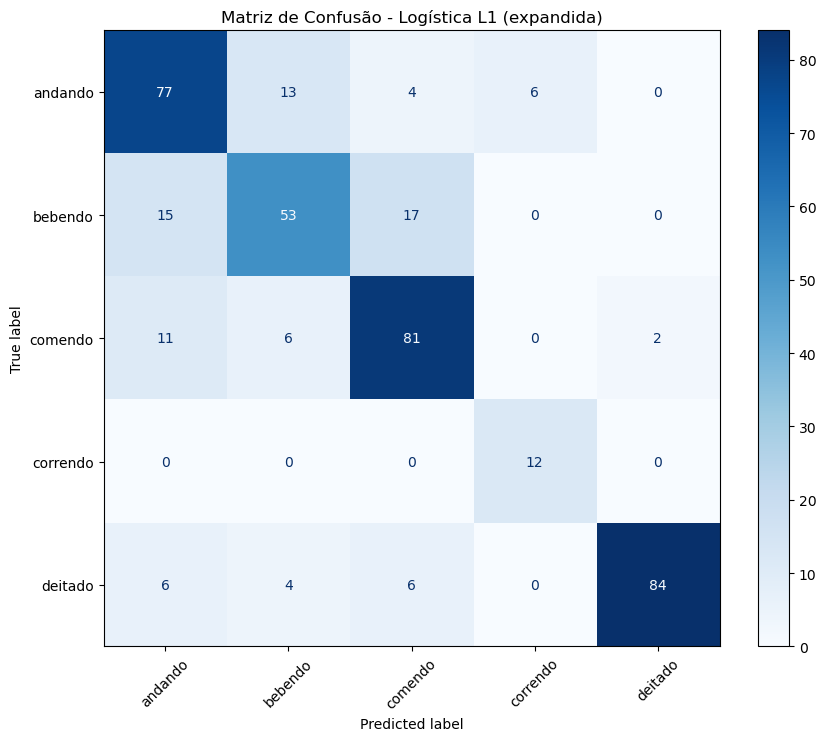


Features mais importantes (LASSO):
max_corr_xz       0.608870
entropy           0.588239
rms_diff          0.367398
min               0.264052
peak_count        0.226016
kurtosis          0.201178
max_corr_yz       0.186612
zero_crossings    0.121870
skewness          0.110817
RG_f              0.107503
FQ                0.078095
max               0.072675
median            0.070449
max_corr_xy       0.054793
std_fim           0.037976
SD_f              0.037473
mean              0.020675
sma               0.020675
tempo_pico        0.016445
MIN_f             0.007238
DC                0.007238
max_min_diff      0.001698
SQ                0.000000
RMS_f             0.000000
Median_f          0.000000
std               0.000000
AV                0.000000
MAX_f             0.000000
dtype: float64

Features removidas (coef = 0):
SQ          0.0
RMS_f       0.0
Median_f    0.0
std         0.0
AV          0.0
MAX_f       0.0
dtype: float64


In [19]:
import pandas as pd
import numpy as np
from scipy.stats import skew, kurtosis
from scipy.signal import find_peaks
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt





# Remover classes indesejadas
df_filtrado = df_final[~df_final['atividade'].isin(['deitando', 'levantando'])].copy()






# =========================
# 1. CARREGAMENTO
# =========================
caminho_arquivo = r'C:\Users\franc\OneDrive\Desktop\dataset_treinamento_suinos.xlsx'
df_final = pd.read_excel(caminho_arquivo)

print("Dataset carregado:", df_final.shape)
# 
df_final['atividade'] = df_final['atividade'].replace({
    'dormindo': 'deitado',
    'deitadoac': 'deitado'
})

# =========================
# 2. REMOVER CLASSES
# =========================
df_filtrado = df_final[~df_final['atividade'].isin(['deitando', 'levantando'])].copy()

print("\nClasses após remoção:")
print(df_filtrado['atividade'].value_counts())

# =========================
# 3. LIMITAR A 400 JANELAS POR CLASSE
# =========================
max_janelas = 400

janelas = df_filtrado.groupby('janela', as_index=False)['atividade'].first()

janelas_sel = janelas.groupby('atividade', group_keys=False).apply(
    lambda g: g.sample(n=min(len(g), max_janelas), random_state=42)
).reset_index(drop=True)

df_filtrado = df_filtrado[df_filtrado['janela'].isin(janelas_sel['janela'])].copy()

print("\nQuantidade de janelas por classe após limitação:")
print(df_filtrado.groupby('janela')['atividade'].first().value_counts())

# =========================
# 4. EXTRAÇÃO DAS FEATURES EXPANDIDAS
# =========================
def extrair_features_expandido(grupo):
    ax = grupo['AX'].values
    ay = grupo['AY'].values
    az = grupo['AZ'].values

    # Magnitude do vetor
    vm = np.sqrt(ax**2 + ay**2 + az**2)
    n = len(vm)

    # Picos
    peaks, _ = find_peaks(vm, height=np.mean(vm))

    # FFT
    fft_vals = np.abs(np.fft.rfft(vm - np.mean(vm)))
    sorted_f = np.sort(fft_vals)
    N_fft = len(fft_vals)

    # Correlações
    corr_xy = np.max(np.correlate(ax, ay, mode='full'))
    corr_xz = np.max(np.correlate(ax, az, mode='full'))
    corr_yz = np.max(np.correlate(ay, az, mode='full'))

    # Parte final da janela
    p3 = vm[70:]  # janelas de 100 pontos
    std_fim = np.std(p3)

    # Derivada
    diff_vm = np.diff(vm) if len(vm) > 1 else np.array([0.0])
    rms_diff = np.sqrt(np.mean(diff_vm**2))

    # Tempo do pico
    tempo_pico = np.argmax(vm) / len(vm)

    # Entropia
    hist, _ = np.histogram(vm, bins=10, density=True)
    hist = hist + 1e-6
    entropy = -np.sum(hist * np.log(hist))

    # Zero crossings da derivada
    zero_crossings = np.sum(np.diff(np.sign(diff_vm)) != 0)

    return pd.Series({
        # Temporais
        'mean': np.mean(vm),
        'std': np.std(vm),
        'min': np.min(vm),
        'max': np.max(vm),
        'max_min_diff': np.max(vm) - np.min(vm),
        'median': np.median(vm),
        'peak_count': len(peaks),
        'skewness': skew(vm),
        'kurtosis': kurtosis(vm),
        'sma': np.sum(np.abs(vm)) / len(vm),

        # Frequência (FFT)
        'AV': np.mean(fft_vals) if N_fft > 0 else 0,
        'DC': fft_vals[0] if N_fft > 0 else 0,
        'SD_f': np.std(fft_vals) if N_fft > 0 else 0,
        'MIN_f': np.min(fft_vals) if N_fft > 0 else 0,
        'MAX_f': np.max(fft_vals) if N_fft > 0 else 0,
        'RG_f': (np.max(fft_vals) - np.mean(fft_vals)) if N_fft > 0 else 0,
        'FQ': sorted_f[int(N_fft / 4)] if N_fft > 4 else 0,
        'SQ': sorted_f[int(N_fft / 2)] if N_fft > 2 else 0,
        'RMS_f': np.sqrt(np.mean(fft_vals**2)) if N_fft > 0 else 0,
        'Median_f': np.median(fft_vals) if N_fft > 0 else 0,

        # Correlações
        'max_corr_xy': corr_xy,
        'max_corr_xz': corr_xz,
        'max_corr_yz': corr_yz,

        # Expandidas
        'std_fim': std_fim,
        'rms_diff': rms_diff,
        'tempo_pico': tempo_pico,
        'entropy': entropy,
        'zero_crossings': zero_crossings
    })

df_features = df_filtrado.groupby('janela').apply(extrair_features_expandido).reset_index()

atividades = df_filtrado.groupby('janela')['atividade'].first().reset_index(drop=True)
df_features['atividade'] = atividades

df_features = df_features.replace([np.inf, -np.inf], np.nan).dropna()

print("\nShape de df_features:", df_features.shape)
print("\nDistribuição final:")
print(df_features['atividade'].value_counts())

# =========================
# 5. PREPARAÇÃO DOS DADOS
# =========================
X = df_features.drop(columns=['janela', 'atividade'])
y = df_features['atividade']

le = LabelEncoder()
y_encoded = le.fit_transform(y)

print("\nClasses no modelo:")
for i, classe in enumerate(le.classes_):
    print(f"{i} -> {classe}")

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.25,
    random_state=42,
    stratify=y_encoded
)

# =========================
# 6. PADRONIZAÇÃO
# =========================
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# =========================
# 7. LASSO
# =========================
model = LogisticRegression(
    penalty='l1',
    solver='saga',
    max_iter=5000,
    class_weight='balanced',
    C=0.1,
    random_state=42
)

model.fit(X_train_scaled, y_train)

# =========================
# 8. RESULTADOS
# =========================
y_pred = model.predict(X_test_scaled)

print("\nRelatório Final (LASSO expandido | sem deitando e levantando | limite 400 janelas):")
print(classification_report(y_test, y_pred, target_names=le.classes_))

fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=le.classes_,
    cmap='Blues',
    xticks_rotation=45,
    ax=ax
)
plt.title('Matriz de Confusão - Logística L1 (expandida)')
plt.show()

# =========================
# 9. IMPORTÂNCIAS DO LASSO
# =========================
importancia = np.mean(np.abs(model.coef_), axis=0)
importancia_series = pd.Series(importancia, index=X.columns).sort_values(ascending=False)

print("\nFeatures mais importantes (LASSO):")
print(importancia_series)

print("\nFeatures removidas (coef = 0):")
print(importancia_series[importancia_series == 0])

In [ ]:
     andando       0.67      0.76      0.71       100
     bebendo       0.63      0.60      0.61        85
     comendo       0.69      0.82      0.75       100
    correndo       0.71      1.00      0.83        12
   deitadoac       0.75      0.41      0.53       100
    dormindo       0.77      0.85      0.81       100

    accuracy                           0.70       497
   macro avg       0.70      0.74      0.71       497
weighted avg       0.70      0.70      0.69       497

# Random Forest (andando,correndo,comendo,bebendo, deitado)

Features utilizadas:
['mean', 'std', 'min', 'max', 'max_min_diff', 'median', 'peak_count', 'skewness', 'kurtosis', 'sma', 'AV', 'DC', 'SD_f', 'MIN_f', 'MAX_f', 'RG_f', 'FQ', 'SQ', 'RMS_f', 'Median_f', 'max_corr_xy', 'max_corr_xz', 'max_corr_yz', 'std_fim', 'rms_diff', 'tempo_pico', 'entropy', 'zero_crossings']

Relatório Final (Random Forest - TODAS as features):
              precision    recall  f1-score   support

     andando       0.75      0.79      0.77       100
     bebendo       0.67      0.74      0.70        85
     comendo       0.81      0.78      0.80       100
    correndo       0.92      1.00      0.96        12
     deitado       0.97      0.85      0.90       100

    accuracy                           0.80       397
   macro avg       0.82      0.83      0.83       397
weighted avg       0.81      0.80      0.80       397



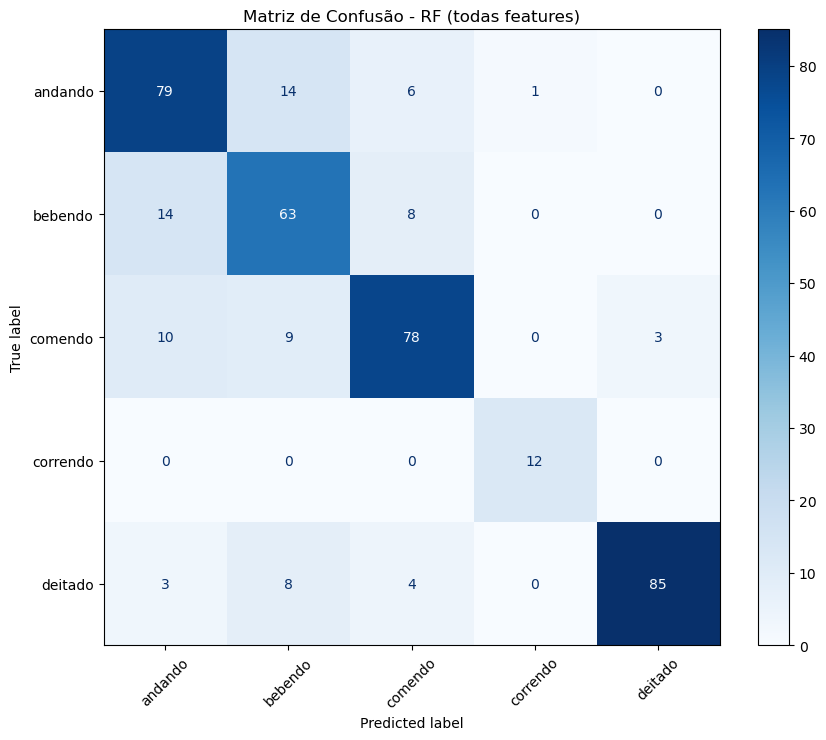


Top 20 features mais importantes:
max_corr_xz       0.108178
entropy           0.071630
SD_f              0.067390
peak_count        0.061077
std               0.058730
RMS_f             0.048978
rms_diff          0.048381
RG_f              0.048022
MAX_f             0.043172
AV                0.036921
zero_crossings    0.032810
SQ                0.032013
Median_f          0.031561
FQ                0.029563
max_corr_xy       0.028775
max               0.027725
std_fim           0.026565
skewness          0.024248
kurtosis          0.023329
max_min_diff      0.022448
dtype: float64


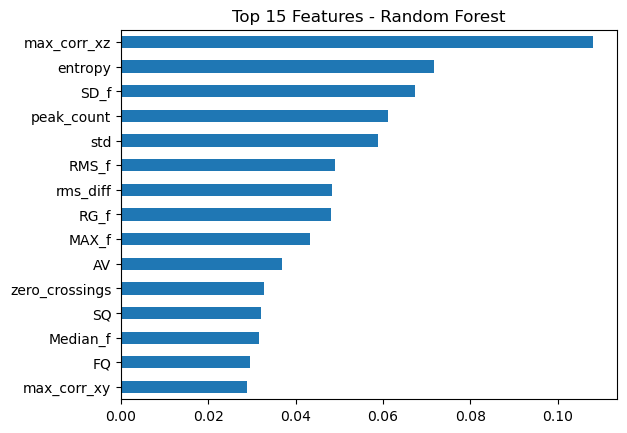

In [20]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import pandas as pd
import matplotlib.pyplot as plt

# =========================
# 1. PREPARAÇÃO DOS DADOS
# =========================
X = df_features.drop(columns=['janela', 'atividade'])
y = df_features['atividade']

le = LabelEncoder()
y_encoded = le.fit_transform(y)

print("Features utilizadas:")
print(X.columns.tolist())

# =========================
# 2. SPLIT
# =========================
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.25,
    random_state=42,
    stratify=y_encoded
)

# =========================
# 3. RANDOM FOREST
# =========================
rf = RandomForestClassifier(
    n_estimators=400,
    max_depth=18,
    min_samples_split=4,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

# =========================
# 4. RESULTADOS
# =========================
y_pred = rf.predict(X_test)

print("\nRelatório Final (Random Forest - TODAS as features):")
print(classification_report(y_test, y_pred, target_names=le.classes_))

# =========================
# 5. MATRIZ DE CONFUSÃO
# =========================
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=le.classes_,
    cmap='Blues',
    xticks_rotation=45,
    ax=ax
)
plt.title('Matriz de Confusão - RF (todas features)')
plt.show()

# =========================
# 6. IMPORTÂNCIA DAS FEATURES
# =========================
importancias = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

print("\nTop 20 features mais importantes:")
print(importancias.head(20))

# =========================
# 7. (OPCIONAL) VISUALIZAÇÃO
# =========================
importancias.head(15).plot(kind='barh')
plt.gca().invert_yaxis()
plt.title("Top 15 Features - Random Forest")
plt.show()

Features utilizadas:
['mean', 'std', 'min', 'max', 'max_min_diff', 'median', 'peak_count', 'skewness', 'kurtosis', 'sma', 'AV', 'DC', 'SD_f', 'MIN_f', 'MAX_f', 'RG_f', 'FQ', 'SQ', 'RMS_f', 'Median_f', 'max_corr_xy', 'max_corr_xz', 'max_corr_yz', 'std_fim', 'rms_diff', 'tempo_pico', 'entropy', 'zero_crossings']

Relatório Final (Random Forest - TODAS as features):
              precision    recall  f1-score   support

     andando       0.71      0.79      0.75       100
     bebendo       0.65      0.69      0.67        85
     comendo       0.80      0.79      0.79       100
    correndo       0.92      1.00      0.96        12
   deitadoac       0.84      0.69      0.76       100
    dormindo       0.90      0.90      0.90       100

    accuracy                           0.78       497
   macro avg       0.80      0.81      0.80       497
weighted avg       0.79      0.78      0.78       497



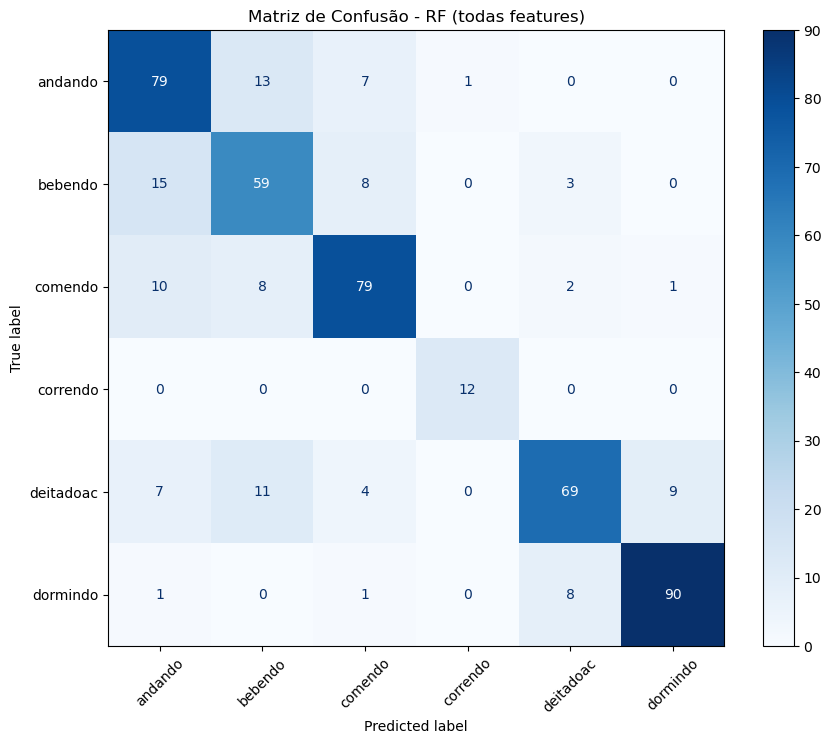


Top 20 features mais importantes:
max_corr_xz    0.101129
entropy        0.065932
peak_count     0.047971
rms_diff       0.046552
AV             0.045277
sma            0.041534
SD_f           0.041249
median         0.040775
mean           0.039974
max            0.036699
std            0.036621
Median_f       0.036601
RMS_f          0.036461
SQ             0.034843
std_fim        0.034730
min            0.032841
RG_f           0.032287
MAX_f          0.032064
max_corr_xy    0.031060
max_corr_yz    0.027987
dtype: float64


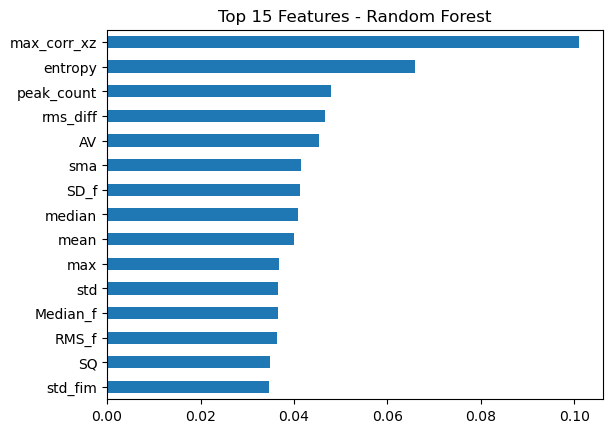

In [18]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import pandas as pd
import matplotlib.pyplot as plt

# =========================
# 1. PREPARAÇÃO DOS DADOS
# =========================
X = df_features.drop(columns=['janela', 'atividade'])
y = df_features['atividade']

le = LabelEncoder()
y_encoded = le.fit_transform(y)

print("Features utilizadas:")
print(X.columns.tolist())

# =========================
# 2. SPLIT
# =========================
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.25,
    random_state=42,
    stratify=y_encoded
)

# =========================
# 3. RANDOM FOREST
# =========================
rf = RandomForestClassifier(
    n_estimators=400,
    max_depth=18,
    min_samples_split=4,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

# =========================
# 4. RESULTADOS
# =========================
y_pred = rf.predict(X_test)

print("\nRelatório Final (Random Forest - TODAS as features):")
print(classification_report(y_test, y_pred, target_names=le.classes_))

# =========================
# 5. MATRIZ DE CONFUSÃO
# =========================
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=le.classes_,
    cmap='Blues',
    xticks_rotation=45,
    ax=ax
)
plt.title('Matriz de Confusão - RF (todas features)')
plt.show()

# =========================
# 6. IMPORTÂNCIA DAS FEATURES
# =========================
importancias = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

print("\nTop 20 features mais importantes:")
print(importancias.head(20))

# =========================
# 7. (OPCIONAL) VISUALIZAÇÃO
# =========================
importancias.head(15).plot(kind='barh')
plt.gca().invert_yaxis()
plt.title("Top 15 Features - Random Forest")
plt.show()

# Teste com dataset 500 janelas cada (agrupamento até verde270126)

# Lasso

Dataset carregado: (834100, 8)

Classes após remoção:
atividade
deitado     397400
comendo     267700
andando      78300
bebendo      45800
correndo      7700
Name: count, dtype: int64


C:\Users\franc\AppData\Local\Temp\ipykernel_23344\3097261940.py:51: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  janelas_sel = janelas.groupby('atividade', group_keys=False).apply(



Quantidade de janelas por classe após limitação:
atividade
andando     500
deitado     500
comendo     500
bebendo     458
correndo     77
Name: count, dtype: int64


C:\Users\franc\AppData\Local\Temp\ipykernel_23344\3097261940.py:142: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_features = df_filtrado.groupby('janela').apply(extrair_features_expandido).reset_index()



Shape de df_features: (2035, 30)

Distribuição final:
atividade
andando     500
deitado     500
comendo     500
bebendo     458
correndo     77
Name: count, dtype: int64

Classes no modelo:
0 -> andando
1 -> bebendo
2 -> comendo
3 -> correndo
4 -> deitado

Relatório Final (LASSO expandido | sem deitando e levantando | limite 400 janelas):
              precision    recall  f1-score   support

     andando       0.76      0.74      0.75       125
     bebendo       0.77      0.75      0.76       115
     comendo       0.72      0.82      0.77       125
    correndo       0.59      0.89      0.71        19
     deitado       0.96      0.81      0.88       125

    accuracy                           0.78       509
   macro avg       0.76      0.80      0.77       509
weighted avg       0.80      0.78      0.79       509



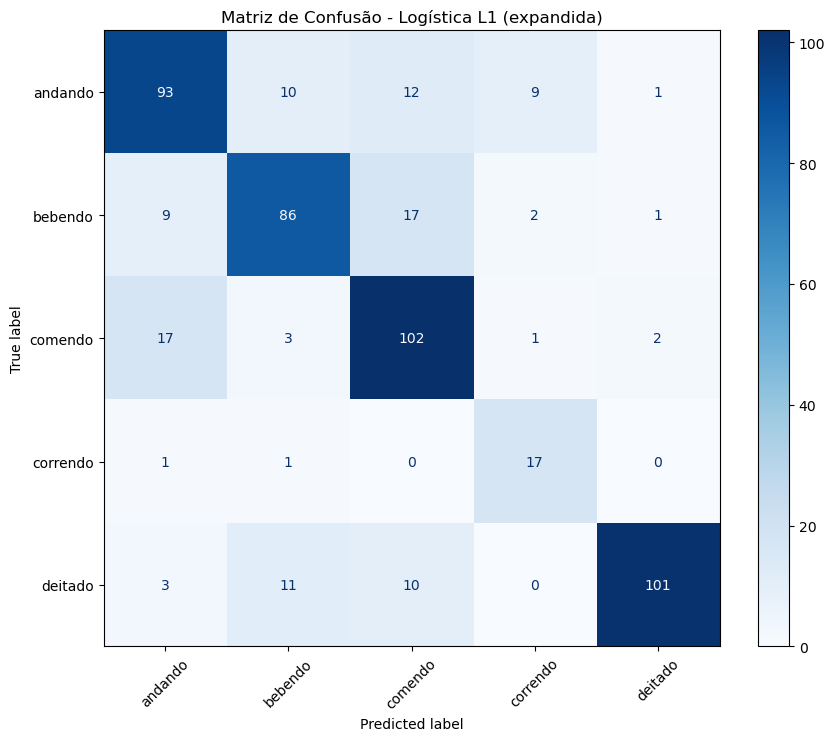


Features mais importantes (LASSO):
max_corr_xz       0.740166
entropy           0.724724
rms_diff          0.383098
peak_count        0.244018
min               0.205021
kurtosis          0.179725
zero_crossings    0.152843
median            0.145387
std_fim           0.134794
skewness          0.114818
max_corr_xy       0.113311
max_corr_yz       0.097315
SD_f              0.090852
mean              0.054096
sma               0.054096
tempo_pico        0.053984
max               0.044811
FQ                0.031247
RG_f              0.013109
MIN_f             0.002507
DC                0.002507
std               0.000000
SQ                0.000000
RMS_f             0.000000
Median_f          0.000000
AV                0.000000
max_min_diff      0.000000
MAX_f             0.000000
dtype: float64

Features removidas (coef = 0):
std             0.0
SQ              0.0
RMS_f           0.0
Median_f        0.0
AV              0.0
max_min_diff    0.0
MAX_f           0.0
dtype: float64


In [13]:
import pandas as pd
import numpy as np
from scipy.stats import skew, kurtosis
from scipy.signal import find_peaks
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt





# Remover classes indesejadas
df_filtrado = df_final[~df_final['atividade'].isin(['deitando', 'levantando'])].copy()






# =========================
# 1. CARREGAMENTO
# =========================
caminho_arquivo = r'C:\Users\franc\OneDrive\Desktop\dataset_treinamento_suinos.xlsx'
df_final = pd.read_excel(caminho_arquivo)

print("Dataset carregado:", df_final.shape)
# 
df_final['atividade'] = df_final['atividade'].replace({
    'dormindo': 'deitado',
    'deitadoac': 'deitado'
})

# =========================
# 2. REMOVER CLASSES
# =========================
df_filtrado = df_final[~df_final['atividade'].isin(['deitando', 'levantando'])].copy()

print("\nClasses após remoção:")
print(df_filtrado['atividade'].value_counts())

# =========================
# 3. LIMITAR A 400 JANELAS POR CLASSE
# =========================
max_janelas = 500

janelas = df_filtrado.groupby('janela', as_index=False)['atividade'].first()

janelas_sel = janelas.groupby('atividade', group_keys=False).apply(
    lambda g: g.sample(n=min(len(g), max_janelas), random_state=42)
).reset_index(drop=True)

df_filtrado = df_filtrado[df_filtrado['janela'].isin(janelas_sel['janela'])].copy()

print("\nQuantidade de janelas por classe após limitação:")
print(df_filtrado.groupby('janela')['atividade'].first().value_counts())

# =========================
# 4. EXTRAÇÃO DAS FEATURES EXPANDIDAS
# =========================
def extrair_features_expandido(grupo):
    ax = grupo['AX'].values
    ay = grupo['AY'].values
    az = grupo['AZ'].values

    # Magnitude do vetor
    vm = np.sqrt(ax**2 + ay**2 + az**2)
    n = len(vm)

    # Picos
    peaks, _ = find_peaks(vm, height=np.mean(vm))

    # FFT
    fft_vals = np.abs(np.fft.rfft(vm - np.mean(vm)))
    sorted_f = np.sort(fft_vals)
    N_fft = len(fft_vals)

    # Correlações
    corr_xy = np.max(np.correlate(ax, ay, mode='full'))
    corr_xz = np.max(np.correlate(ax, az, mode='full'))
    corr_yz = np.max(np.correlate(ay, az, mode='full'))

    # Parte final da janela
    p3 = vm[70:]  # janelas de 100 pontos
    std_fim = np.std(p3)

    # Derivada
    diff_vm = np.diff(vm) if len(vm) > 1 else np.array([0.0])
    rms_diff = np.sqrt(np.mean(diff_vm**2))

    # Tempo do pico
    tempo_pico = np.argmax(vm) / len(vm)

    # Entropia
    hist, _ = np.histogram(vm, bins=10, density=True)
    hist = hist + 1e-6
    entropy = -np.sum(hist * np.log(hist))

    # Zero crossings da derivada
    zero_crossings = np.sum(np.diff(np.sign(diff_vm)) != 0)

    return pd.Series({
        # Temporais
        'mean': np.mean(vm),
        'std': np.std(vm),
        'min': np.min(vm),
        'max': np.max(vm),
        'max_min_diff': np.max(vm) - np.min(vm),
        'median': np.median(vm),
        'peak_count': len(peaks),
        'skewness': skew(vm),
        'kurtosis': kurtosis(vm),
        'sma': np.sum(np.abs(vm)) / len(vm),

        # Frequência (FFT)
        'AV': np.mean(fft_vals) if N_fft > 0 else 0,
        'DC': fft_vals[0] if N_fft > 0 else 0,
        'SD_f': np.std(fft_vals) if N_fft > 0 else 0,
        'MIN_f': np.min(fft_vals) if N_fft > 0 else 0,
        'MAX_f': np.max(fft_vals) if N_fft > 0 else 0,
        'RG_f': (np.max(fft_vals) - np.mean(fft_vals)) if N_fft > 0 else 0,
        'FQ': sorted_f[int(N_fft / 4)] if N_fft > 4 else 0,
        'SQ': sorted_f[int(N_fft / 2)] if N_fft > 2 else 0,
        'RMS_f': np.sqrt(np.mean(fft_vals**2)) if N_fft > 0 else 0,
        'Median_f': np.median(fft_vals) if N_fft > 0 else 0,

        # Correlações
        'max_corr_xy': corr_xy,
        'max_corr_xz': corr_xz,
        'max_corr_yz': corr_yz,

        # Expandidas
        'std_fim': std_fim,
        'rms_diff': rms_diff,
        'tempo_pico': tempo_pico,
        'entropy': entropy,
        'zero_crossings': zero_crossings
    })

df_features = df_filtrado.groupby('janela').apply(extrair_features_expandido).reset_index()

atividades = df_filtrado.groupby('janela')['atividade'].first().reset_index(drop=True)
df_features['atividade'] = atividades

df_features = df_features.replace([np.inf, -np.inf], np.nan).dropna()

print("\nShape de df_features:", df_features.shape)
print("\nDistribuição final:")
print(df_features['atividade'].value_counts())

# =========================
# 5. PREPARAÇÃO DOS DADOS
# =========================
X = df_features.drop(columns=['janela', 'atividade'])
y = df_features['atividade']

le = LabelEncoder()
y_encoded = le.fit_transform(y)

print("\nClasses no modelo:")
for i, classe in enumerate(le.classes_):
    print(f"{i} -> {classe}")

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.25,
    random_state=42,
    stratify=y_encoded
)

# =========================
# 6. PADRONIZAÇÃO
# =========================
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# =========================
# 7. LASSO
# =========================
model = LogisticRegression(
    penalty='l1',
    solver='saga',
    max_iter=5000,
    class_weight='balanced',
    C=0.1,
    random_state=42
)

model.fit(X_train_scaled, y_train)

# =========================
# 8. RESULTADOS
# =========================
y_pred = model.predict(X_test_scaled)

print("\nRelatório Final (LASSO expandido | sem deitando e levantando | limite 400 janelas):")
print(classification_report(y_test, y_pred, target_names=le.classes_))

fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=le.classes_,
    cmap='Blues',
    xticks_rotation=45,
    ax=ax
)
plt.title('Matriz de Confusão - Logística L1 (expandida)')
plt.show()

# =========================
# 9. IMPORTÂNCIAS DO LASSO
# =========================
importancia = np.mean(np.abs(model.coef_), axis=0)
importancia_series = pd.Series(importancia, index=X.columns).sort_values(ascending=False)

print("\nFeatures mais importantes (LASSO):")
print(importancia_series)

print("\nFeatures removidas (coef = 0):")
print(importancia_series[importancia_series == 0])

In [ ]:
# Random Forest Teste com 500 janelas

Features utilizadas:
['mean', 'std', 'min', 'max', 'max_min_diff', 'median', 'peak_count', 'skewness', 'kurtosis', 'sma', 'AV', 'DC', 'SD_f', 'MIN_f', 'MAX_f', 'RG_f', 'FQ', 'SQ', 'RMS_f', 'Median_f', 'max_corr_xy', 'max_corr_xz', 'max_corr_yz', 'std_fim', 'rms_diff', 'tempo_pico', 'entropy', 'zero_crossings']

Relatório Final (Random Forest - TODAS as features):
              precision    recall  f1-score   support

     andando       0.85      0.80      0.82       125
     bebendo       0.74      0.85      0.79       115
     comendo       0.79      0.84      0.81       125
    correndo       0.88      0.79      0.83        19
     deitado       0.96      0.83      0.89       125

    accuracy                           0.83       509
   macro avg       0.84      0.82      0.83       509
weighted avg       0.84      0.83      0.83       509



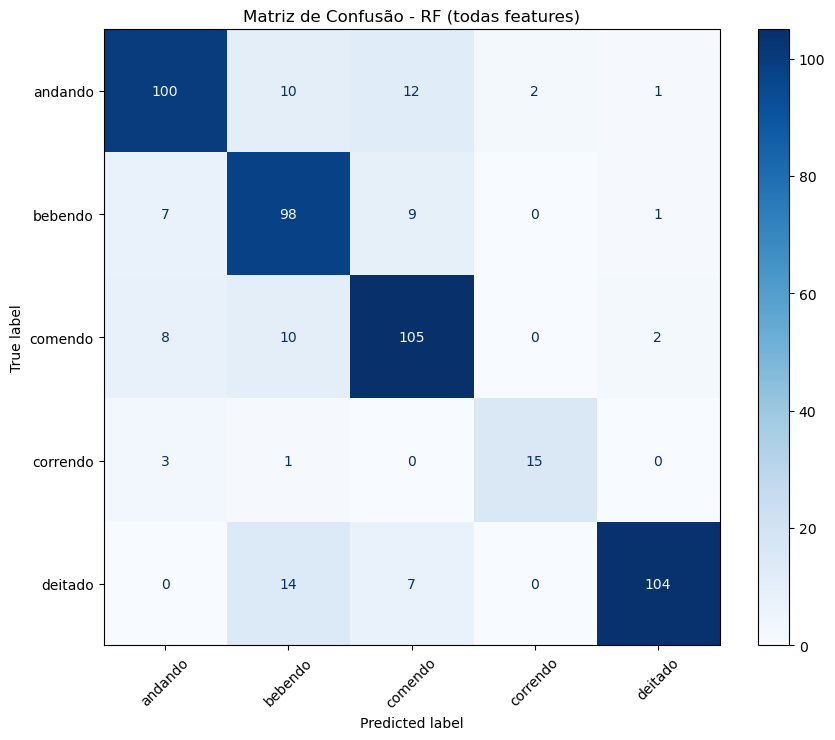


Top 20 features mais importantes:
max_corr_xz       0.131259
entropy           0.067809
MAX_f             0.056718
rms_diff          0.053235
peak_count        0.052634
RG_f              0.049089
std_fim           0.048323
SD_f              0.044376
std               0.042610
RMS_f             0.040305
Median_f          0.037276
SQ                0.033943
AV                0.033050
FQ                0.028329
kurtosis          0.025074
zero_crossings    0.024167
skewness          0.023593
max               0.023590
sma               0.023322
max_corr_yz       0.022547
dtype: float64


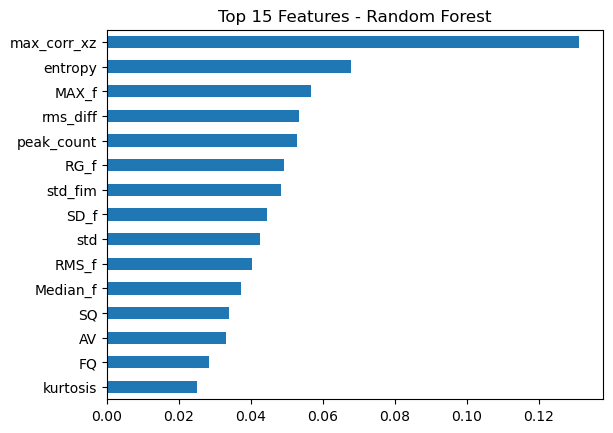

In [14]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import pandas as pd
import matplotlib.pyplot as plt

# =========================
# 1. PREPARAÇÃO DOS DADOS
# =========================
X = df_features.drop(columns=['janela', 'atividade'])
y = df_features['atividade']

le = LabelEncoder()
y_encoded = le.fit_transform(y)

print("Features utilizadas:")
print(X.columns.tolist())

# =========================
# 2. SPLIT
# =========================
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.25,
    random_state=42,
    stratify=y_encoded
)

# =========================
# 3. RANDOM FOREST
# =========================
rf = RandomForestClassifier(
    n_estimators=500,
    max_depth=18,
    min_samples_split=4,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

# =========================
# 4. RESULTADOS
# =========================
y_pred = rf.predict(X_test)

print("\nRelatório Final (Random Forest - TODAS as features):")
print(classification_report(y_test, y_pred, target_names=le.classes_))

# =========================
# 5. MATRIZ DE CONFUSÃO
# =========================
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=le.classes_,
    cmap='Blues',
    xticks_rotation=45,
    ax=ax
)
plt.title('Matriz de Confusão - RF (todas features)')
plt.show()

# =========================
# 6. IMPORTÂNCIA DAS FEATURES
# =========================
importancias = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

print("\nTop 20 features mais importantes:")
print(importancias.head(20))

# =========================
# 7. (OPCIONAL) VISUALIZAÇÃO
# =========================
importancias.head(15).plot(kind='barh')
plt.gca().invert_yaxis()
plt.title("Top 15 Features - Random Forest")
plt.show()

Test set aligned: 1257 windows

F1-based static weights (OOF):
  deitado: W_sensor=0.5103  W_audio=0.4897
  andando: W_sensor=0.5611  W_audio=0.4389
  bebendo: W_sensor=0.5323  W_audio=0.4677
  comendo: W_sensor=0.5077  W_audio=0.4923

Mean confidence margin — sensor: 0.6350 | audio: 0.6649
DCS-MAX: sensor selected in 47.6% of samples

RF (sensor)            Acc=91.73%  MacroF1=83.86%  | deitado=95.88 andando=83.16 bebendo=62.94 comendo=93.48
LMAAN (audio)          Acc=90.29%  MacroF1=85.56%  | deitado=92.82 andando=78.12 bebendo=79.67 comendo=91.63
Simple fusion          Acc=94.59%  MacroF1=89.73%  | deitado=97.3 andando=84.89 bebendo=80.95 comendo=95.76
F1-Weighted fusion     Acc=94.67%  MacroF1=89.58%  | deitado=97.54 andando=85.0 bebendo=80.0 comendo=95.76
DCS-MAX                Acc=94.35%  MacroF1=89.49%  | deitado=96.69 andando=84.48 bebendo=80.62 comendo=96.19
CWF-Equal              Acc=94.43%  MacroF1=89.60%  | deitado=97.0 andando=83.94 bebendo=81.6 comendo=95.88
CWF-OOF      

C:\Users\franc\AppData\Local\Temp\ipykernel_32540\4071790487.py:242: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


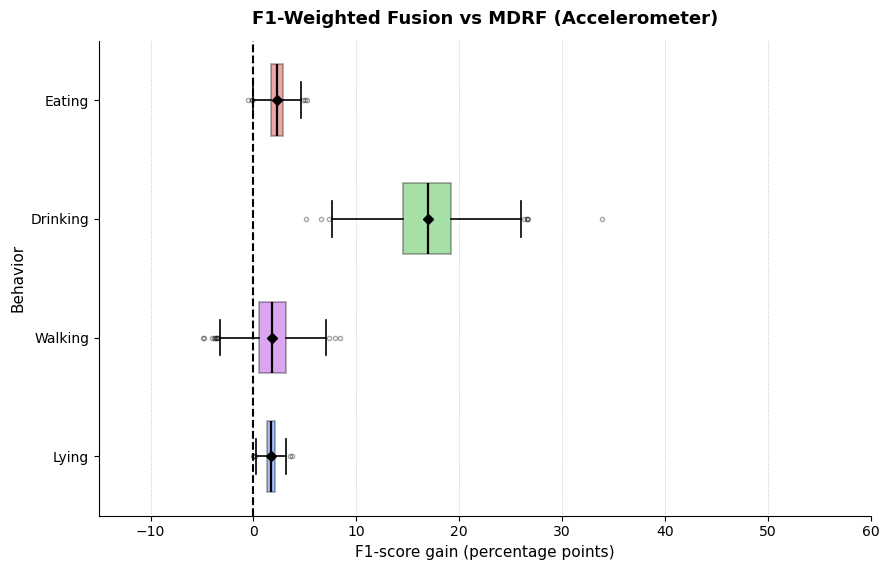

Figure saved: boxplot_f1w_vs_rf.png


C:\Users\franc\AppData\Local\Temp\ipykernel_32540\4071790487.py:242: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


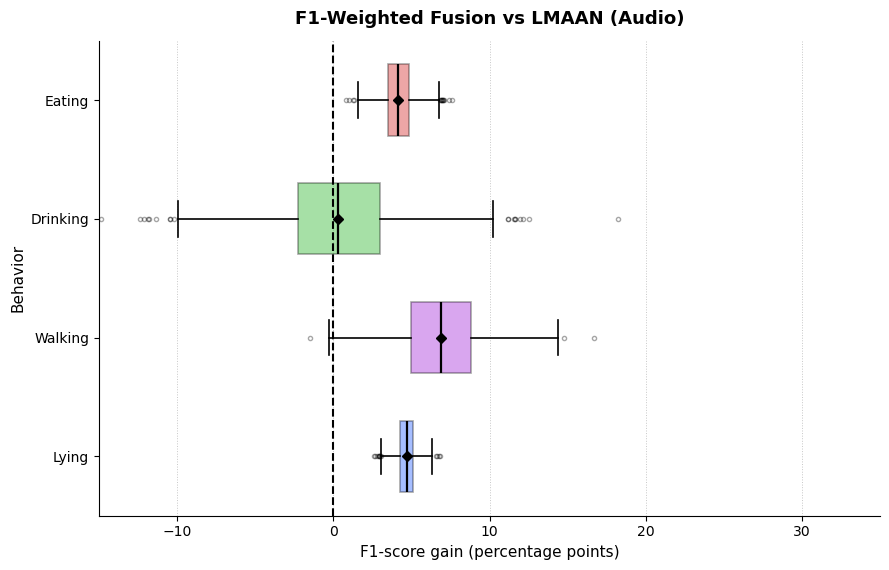

Figure saved: boxplot_f1w_vs_lmaan.png


C:\Users\franc\AppData\Local\Temp\ipykernel_32540\4071790487.py:242: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


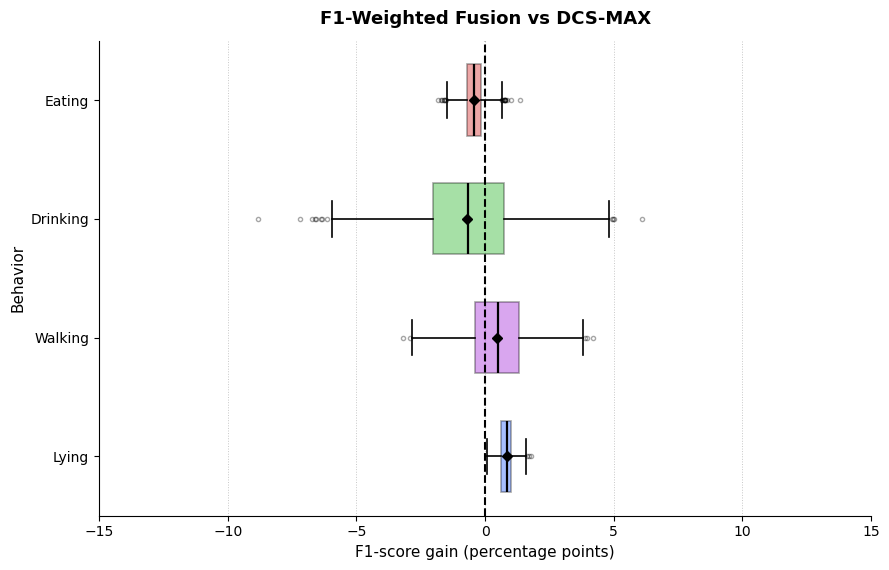

Figure saved: boxplot_f1w_vs_dcsmax.png


C:\Users\franc\AppData\Local\Temp\ipykernel_32540\4071790487.py:242: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


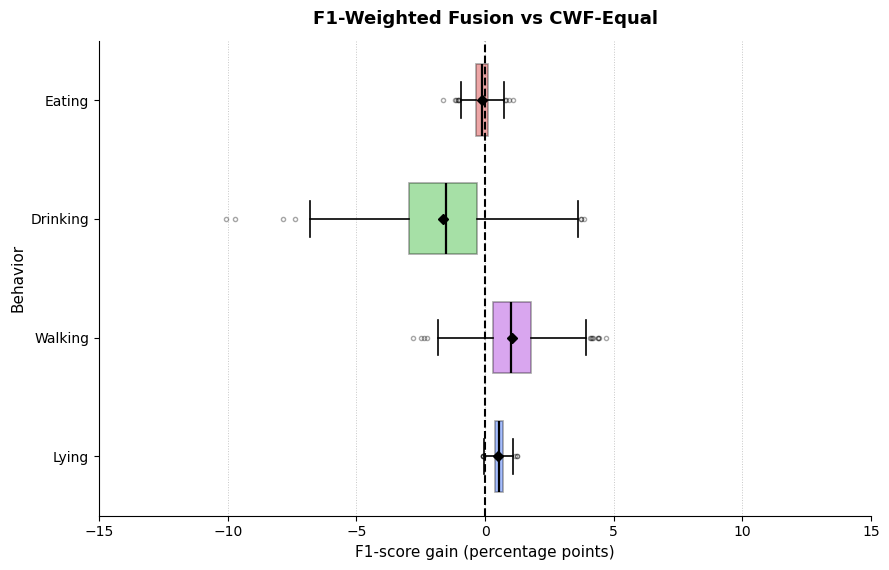

Figure saved: boxplot_f1w_vs_cwfeq.png


C:\Users\franc\AppData\Local\Temp\ipykernel_32540\4071790487.py:242: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


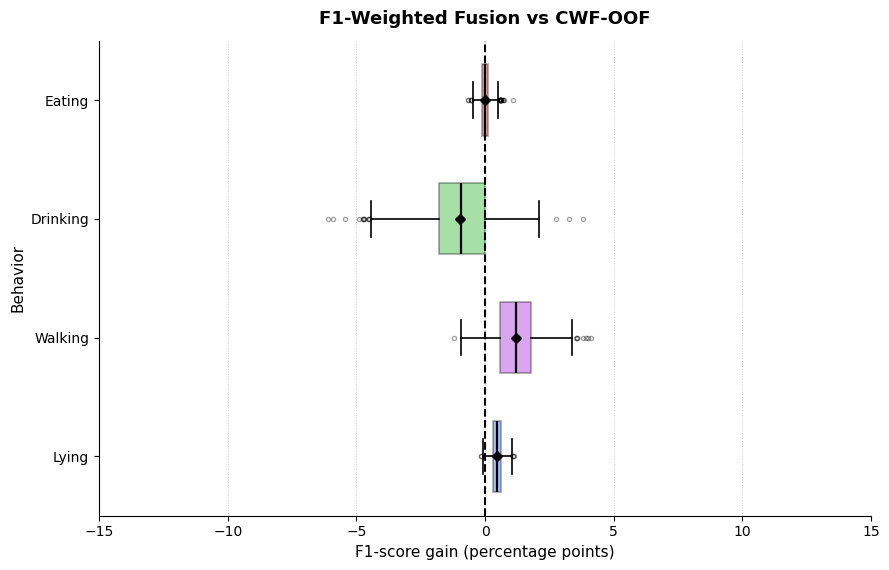

Figure saved: boxplot_f1w_vs_cwfoof.png


C:\Users\franc\AppData\Local\Temp\ipykernel_32540\4071790487.py:242: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


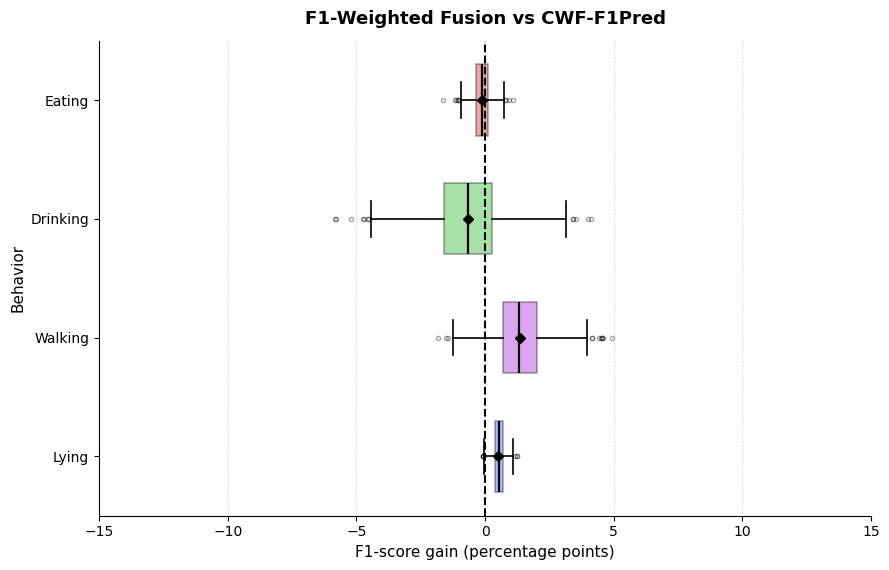

Figure saved: boxplot_f1w_vs_cwffp.png

=== Full comparison table ===
            Modelo  deitado  andando  bebendo  comendo  Accuracy  Macro_F1  Weighted_F1
       RF (sensor)    95.88    83.16    62.94    93.48     91.73     83.86        91.94
     LMAAN (audio)    92.82    78.12    79.67    91.63     90.29     85.56        90.05
     Simple fusion    97.30    84.89    80.95    95.76     94.59     89.73        94.52
F1-Weighted fusion    97.54    85.00    80.00    95.76     94.67     89.58        94.60
           DCS-MAX    96.69    84.48    80.62    96.19     94.35     89.49        94.29
         CWF-Equal    97.00    83.94    81.60    95.88     94.43     89.60        94.33
           CWF-OOF    97.07    83.75    80.95    95.75     94.35     89.38        94.27
        CWF-F1Pred    97.00    83.64    80.65    95.88     94.35     89.29        94.24

CSV saved: summary_all_fusion_methods.csv
Saved: logits_f1weighted_fusion_validacao_4classes.csv


In [3]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    f1_score, accuracy_score, classification_report, confusion_matrix
)
from sklearn.utils import resample

# ============================================================
# F1-WEIGHTED MULTIMODAL FUSION
# Weights: W_m(c) = F1_m(c) / (F1_sen(c) + F1_aud(c))  — OOF only
# Compared against Kuncheva (2002) dynamic variants:
#   DCS-MAX, CWF-Equal, CWF-OOF, CWF-F1Pred
# ============================================================

classes_modelo  = ["deitado", "andando", "bebendo", "comendo"]
class_names_en  = ["Lying",   "Walking", "Drinking", "Eating"]
labels_order    = [0, 1, 2, 3]
n_classes       = len(classes_modelo)
N_BOOTSTRAP     = 1000
RANDOM_STATE    = 42
prob_cols       = [f"prob_{c}" for c in classes_modelo]
EPS             = 1e-8

# ============================================================
# 1. Load test logits
# ============================================================

df_sen = pd.read_csv(
    "logits_sensor_rf_cshift4p_combfeat_validacao_4classes_sem_correndo.csv")
df_aud = pd.read_csv(
    "logits_audio_lmaan_validacao_4classes_cshift4p.csv")

df_sen["janela"] = df_sen["janela"].astype(str)
df_aud["janela"] = df_aud["janela"].astype(str)

df_test = pd.merge(
    df_sen[["janela","label_real"] + prob_cols].rename(
        columns={c: f"s_{c}" for c in prob_cols}),
    df_aud[["janela"] + prob_cols].rename(
        columns={c: f"a_{c}" for c in prob_cols}),
    on="janela", how="inner"
)
print(f"Test set aligned: {len(df_test)} windows")

y_test    = df_test["label_real"].values.astype(int)
P_sen     = df_test[[f"s_{c}" for c in prob_cols]].values
P_aud     = df_test[[f"a_{c}" for c in prob_cols]].values

y_pred_sen = P_sen.argmax(axis=1)
y_pred_aud = P_aud.argmax(axis=1)
y_pred_sim = ((P_sen + P_aud) / 2).argmax(axis=1)

# ============================================================
# 2. Load OOF logits — compute F1-based static weights
# ============================================================

df_oof_sen = pd.read_csv(
    "logits_sensor_rf_cshift4p_combfeat_oof_treino_4classes_sem_correndo.csv")
df_oof_aud = pd.read_csv(
    "logits_audio_oof_treino_4classes_cshift4p.csv")

def extrair_id(nome):
    m = re.search(r"-j(\d+)", str(nome))
    return int(m.group(1)) if m else None

df_oof_aud["janela_id"] = df_oof_aud["janela"].apply(extrair_id)
df_oof_sen["janela_id"] = df_oof_sen["janela"].astype(int)

df_oof = pd.merge(
    df_oof_sen[["janela_id","label_real"] + prob_cols].rename(
        columns={c: f"s_{c}" for c in prob_cols}),
    df_oof_aud[["janela_id"] + prob_cols].rename(
        columns={c: f"a_{c}" for c in prob_cols}),
    on="janela_id", how="inner"
)

y_oof      = df_oof["label_real"].values.astype(int)
P_oof_sen  = df_oof[[f"s_{c}" for c in prob_cols]].values
P_oof_aud  = df_oof[[f"a_{c}" for c in prob_cols]].values
yp_oof_sen = P_oof_sen.argmax(axis=1)
yp_oof_aud = P_oof_aud.argmax(axis=1)

f1_oof_sen = np.array([f1_score(y_oof, yp_oof_sen, labels=[c],
    average="macro", zero_division=0) for c in range(n_classes)])
f1_oof_aud = np.array([f1_score(y_oof, yp_oof_aud, labels=[c],
    average="macro", zero_division=0) for c in range(n_classes)])

W_oof_sen = f1_oof_sen / (f1_oof_sen + f1_oof_aud + EPS)
W_oof_aud = f1_oof_aud / (f1_oof_sen + f1_oof_aud + EPS)

print("\nF1-based static weights (OOF):")
for c, nm in enumerate(classes_modelo):
    print(f"  {nm}: W_sensor={W_oof_sen[c]:.4f}  W_audio={W_oof_aud[c]:.4f}")

# ============================================================
# 3. F1-Weighted Fusion
# p_fus(i,c) = W_sen(c) * P_sen(i,c) + W_aud(c) * P_aud(i,c)
# ============================================================

P_f1w = np.zeros_like(P_sen)
for c in range(n_classes):
    P_f1w[:, c] = W_oof_sen[c] * P_sen[:, c] + W_oof_aud[c] * P_aud[:, c]
y_pred_f1w = P_f1w.argmax(axis=1)

# ============================================================
# 4. Kuncheva (2002) dynamic variants
# ============================================================

baseline  = 1.0 / n_classes
delta_sen = np.clip(P_sen.max(axis=1) - baseline, 0, None)
delta_aud = np.clip(P_aud.max(axis=1) - baseline, 0, None)

print(f"\nMean confidence margin — sensor: {delta_sen.mean():.4f} "
      f"| audio: {delta_aud.mean():.4f}")

# DCS-MAX
mask_sen       = (delta_sen >= delta_aud)
P_dcs          = np.where(mask_sen[:, None], P_sen, P_aud)
y_pred_dcs     = P_dcs.argmax(axis=1)
print(f"DCS-MAX: sensor selected in {mask_sen.mean()*100:.1f}% of samples")

# CWF-Equal
denom_eq       = delta_sen + delta_aud + EPS
P_cwf_eq       = (delta_sen / denom_eq)[:, None] * P_sen + \
                 (delta_aud / denom_eq)[:, None] * P_aud
y_pred_cwf_eq  = P_cwf_eq.argmax(axis=1)

# CWF-OOF
Wt_sen         = np.outer(delta_sen, W_oof_sen)
Wt_aud         = np.outer(delta_aud, W_oof_aud)
denom_oof      = Wt_sen + Wt_aud + EPS
P_cwf_oof      = (Wt_sen / denom_oof) * P_sen + (Wt_aud / denom_oof) * P_aud
y_pred_cwf_oof = P_cwf_oof.argmax(axis=1)

# CWF-F1Pred
c_hat_sen      = P_sen.argmax(axis=1)
c_hat_aud      = P_aud.argmax(axis=1)
score_sp       = f1_oof_sen[c_hat_sen] * delta_sen
score_ap       = f1_oof_aud[c_hat_aud] * delta_aud
denom_fp       = score_sp + score_ap + EPS
P_cwf_fp       = (score_sp / denom_fp)[:, None] * P_sen + \
                 (score_ap / denom_fp)[:, None] * P_aud
y_pred_cwf_fp  = P_cwf_fp.argmax(axis=1)

# ============================================================
# 5. Results summary
# ============================================================

models = {
    "RF (sensor)":        y_pred_sen,
    "LMAAN (audio)":      y_pred_aud,
    "Simple fusion":      y_pred_sim,
    "F1-Weighted fusion": y_pred_f1w,
    "DCS-MAX":            y_pred_dcs,
    "CWF-Equal":          y_pred_cwf_eq,
    "CWF-OOF":            y_pred_cwf_oof,
    "CWF-F1Pred":         y_pred_cwf_fp,
}

print("\n" + "="*70)
for name, yp in models.items():
    rep = classification_report(y_test, yp, labels=labels_order,
          target_names=classes_modelo, output_dict=True, zero_division=0)
    f1s = [round(rep[c]["f1-score"]*100, 2) for c in classes_modelo]
    print(f"{name:<22} Acc={rep['accuracy']*100:.2f}%  "
          f"MacroF1={rep['macro avg']['f1-score']*100:.2f}%  "
          f"| {' '.join([f'{c}={v}' for c,v in zip(classes_modelo,f1s)])}")

# ============================================================
# 6. Bootstrap significance — F1-Weighted vs all variants
# ============================================================

def bootstrap_gains_all(y_true, y_pred_a, y_pred_b,
                        n_iter=N_BOOTSTRAP, rs=RANDOM_STATE):
    rng     = np.random.RandomState(rs)
    idx_all = np.arange(len(y_true))
    gc      = {i: [] for i in range(n_classes)}
    gm, gw, ga = [], [], []
    for _ in range(n_iter):
        idx = resample(idx_all, replace=True, n_samples=len(idx_all),
                       stratify=y_true,
                       random_state=rng.randint(0, 2**31))
        yb, ya, yb2 = y_true[idx], y_pred_a[idx], y_pred_b[idx]
        f1a = f1_score(yb, ya,  average=None, labels=labels_order, zero_division=0)
        f1b = f1_score(yb, yb2, average=None, labels=labels_order, zero_division=0)
        for i in range(n_classes):
            gc[i].append((f1a[i] - f1b[i]) * 100)
        gm.append((f1_score(yb,ya, average="macro",    zero_division=0) -
                   f1_score(yb,yb2,average="macro",    zero_division=0)) * 100)
        gw.append((f1_score(yb,ya, average="weighted", zero_division=0) -
                   f1_score(yb,yb2,average="weighted", zero_division=0)) * 100)
        ga.append((accuracy_score(yb,ya) - accuracy_score(yb,yb2)) * 100)
    return gc, gm, gw, ga

def print_bootstrap(gc, gm, gw, ga, label):
    print(f"\n{'='*64}\n{label}\n{'='*64}")
    print(f"{'Metric':<16} {'Gain':>10} {'IC95%':>22} {'p':>8}")
    print("-"*64)
    for i, nm in enumerate(classes_modelo):
        g = np.array(gc[i]); p = np.mean(g <= 0)
        print(f"{nm:<16} {np.mean(g):>+9.2f}pp  "
              f"[{np.percentile(g,2.5):>+7.2f}, {np.percentile(g,97.5):>+7.2f}]"
              f"  {p:.4f} {'✓' if p<0.05 else ''}")
    print("-"*64)
    for nome, g in [("Macro F1",gm),("Weighted F1",gw),("Accuracy",ga)]:
        g = np.array(g); p = np.mean(g <= 0)
        print(f"{nome:<16} {np.mean(g):>+9.2f}pp  "
              f"[{np.percentile(g,2.5):>+7.2f}, {np.percentile(g,97.5):>+7.2f}]"
              f"  {p:.4f} {'✓' if p<0.05 else ''}")

gc1,gm1,gw1,ga1 = bootstrap_gains_all(y_test, y_pred_f1w, y_pred_dcs)
print_bootstrap(gc1,gm1,gw1,ga1, "F1-Weighted Fusion vs DCS-MAX")

gc2,gm2,gw2,ga2 = bootstrap_gains_all(y_test, y_pred_f1w, y_pred_cwf_eq)
print_bootstrap(gc2,gm2,gw2,ga2, "F1-Weighted Fusion vs CWF-Equal")

gc3,gm3,gw3,ga3 = bootstrap_gains_all(y_test, y_pred_f1w, y_pred_cwf_oof)
print_bootstrap(gc3,gm3,gw3,ga3, "F1-Weighted Fusion vs CWF-OOF")

gc4,gm4,gw4,ga4 = bootstrap_gains_all(y_test, y_pred_f1w, y_pred_cwf_fp)
print_bootstrap(gc4,gm4,gw4,ga4, "F1-Weighted Fusion vs CWF-F1Pred")

gc5,gm5,gw5,ga5 = bootstrap_gains_all(y_test, y_pred_f1w, y_pred_sen)
print_bootstrap(gc5,gm5,gw5,ga5, "F1-Weighted Fusion vs RF (sensor)")

gc6,gm6,gw6,ga6 = bootstrap_gains_all(y_test, y_pred_f1w, y_pred_aud)
print_bootstrap(gc6,gm6,gw6,ga6, "F1-Weighted Fusion vs LMAAN (audio)")

# ============================================================
# 7. Boxplots — article style
# ============================================================

COLORS = ['#0047FF', '#9400D3', '#00A800', '#CC0000']

def plot_cwf_boxplot(gains_class, title, save_path, xlim=(-20, 40)):
    data_plot = [np.array(gains_class[i]) for i in range(n_classes)]
    fig, ax   = plt.subplots(figsize=(9, 5.8))
    bp = ax.boxplot(
        data_plot, vert=False, patch_artist=True,
        labels=class_names_en, showmeans=True, meanline=False, widths=0.6,
        flierprops=dict(marker='o', markersize=3, alpha=0.35),
        medianprops=dict(color='black', linewidth=1.6),
        meanprops=dict(marker='D', markerfacecolor='black',
                       markeredgecolor='black', markersize=5),
        whiskerprops=dict(linewidth=1.2),
        capprops=dict(linewidth=1.2),
        boxprops=dict(linewidth=1.2)
    )
    for patch, color in zip(bp['boxes'], COLORS):
        patch.set_facecolor(color); patch.set_alpha(0.35)
        patch.set_edgecolor('black'); patch.set_linewidth(1.2)
    ax.axvline(0, color='black', linestyle='--', linewidth=1.5)
    ax.set_title(title, fontsize=13, fontweight='bold', pad=12)
    ax.set_xlabel('F1-score gain (percentage points)', fontsize=11)
    ax.set_ylabel('Behavior', fontsize=11)
    ax.tick_params(axis='both', labelsize=10)
    ax.set_xlim(xlim)
    ax.grid(axis='x', linestyle=':', linewidth=0.7, alpha=0.7)
    ax.grid(axis='y', visible=False)
    ax.spines[['top', 'right']].set_visible(False)
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"Figure saved: {save_path}")

plot_cwf_boxplot(gc5, "F1-Weighted Fusion vs MDRF (Accelerometer)",
                 "boxplot_f1w_vs_rf.png",     xlim=(-15, 60))
plot_cwf_boxplot(gc6, "F1-Weighted Fusion vs LMAAN (Audio)",
                 "boxplot_f1w_vs_lmaan.png",  xlim=(-15, 35))
plot_cwf_boxplot(gc1, "F1-Weighted Fusion vs DCS-MAX",
                 "boxplot_f1w_vs_dcsmax.png", xlim=(-15, 15))
plot_cwf_boxplot(gc2, "F1-Weighted Fusion vs CWF-Equal",
                 "boxplot_f1w_vs_cwfeq.png",  xlim=(-15, 15))
plot_cwf_boxplot(gc3, "F1-Weighted Fusion vs CWF-OOF",
                 "boxplot_f1w_vs_cwfoof.png", xlim=(-15, 15))
plot_cwf_boxplot(gc4, "F1-Weighted Fusion vs CWF-F1Pred",
                 "boxplot_f1w_vs_cwffp.png",  xlim=(-15, 15))

# ============================================================
# 8. Full comparison table
# ============================================================

def metrics_row(name, y_true, y_pred):
    rep = classification_report(y_true, y_pred, labels=labels_order,
          target_names=classes_modelo, output_dict=True, zero_division=0)
    row = {"Modelo": name}
    for c in classes_modelo:
        row[c] = round(rep[c]["f1-score"] * 100, 2)
    row["Accuracy"]    = round(rep["accuracy"] * 100, 2)
    row["Macro_F1"]    = round(rep["macro avg"]["f1-score"] * 100, 2)
    row["Weighted_F1"] = round(rep["weighted avg"]["f1-score"] * 100, 2)
    return row

df_comp = pd.DataFrame([
    metrics_row("RF (sensor)",        y_test, y_pred_sen),
    metrics_row("LMAAN (audio)",      y_test, y_pred_aud),
    metrics_row("Simple fusion",      y_test, y_pred_sim),
    metrics_row("F1-Weighted fusion", y_test, y_pred_f1w),
    metrics_row("DCS-MAX",            y_test, y_pred_dcs),
    metrics_row("CWF-Equal",          y_test, y_pred_cwf_eq),
    metrics_row("CWF-OOF",            y_test, y_pred_cwf_oof),
    metrics_row("CWF-F1Pred",         y_test, y_pred_cwf_fp),
])

print("\n=== Full comparison table ===")
print(df_comp.to_string(index=False))
df_comp.to_csv("summary_all_fusion_methods.csv", index=False)
print("\nCSV saved: summary_all_fusion_methods.csv")

# ============================================================
# 9. Save F1-Weighted fusion probabilities
# ============================================================

df_out = pd.DataFrame(P_f1w, columns=[f"prob_{c}" for c in classes_modelo])
df_out["janela"]     = df_test["janela"].values
df_out["label_real"] = y_test
df_out["y_pred"]     = y_pred_f1w
df_out.to_csv("logits_f1weighted_fusion_validacao_4classes.csv", index=False)
print("Saved: logits_f1weighted_fusion_validacao_4classes.csv")